В нём будут следующие ячейки:
1. Настройка проекта и каталогов.
2. Подключение к данным RCSB PDB.
3. Получение списка структур по заданным критериям.
4. Извлечение метаданных.
5. Классификация белков.
6. Определение наличия биологически значимых лигандов.
7. Извлечение и сравнение последовательностей.
8. Устранение дубликатов.
9. Формирование сбалансированного списка кандидатов.
10. Выбор окончательных 100 структур.
11. Сохранение реестра и отчёта.

CELL 1. Настройка проекта и параметров
- Создание структуры каталогов.
- Определение размера будущего датасета — 100 белков.
- Задание целевого баланса holo/apo — 50/50.
- Задание требований к разрешению и длине последовательности.
- Настройка подключения к RCSB PDB.



CELL 2. Проверка доступа к RCSB PDB
- Отправка тестового HTTP-запроса.
- Получение записи 1OCC.
- Проверка доступности метаданных.
- Проверка работы API и вспомогательных функций.



CELL 3. Поиск структур-кандидатов

Отправляется запрос к RCSB Search API со следующими условиями:
- разрешение структуры не хуже 3,5 Å;
- наличие белковой полимерной сущности;
- экспериментальная структура;
- получение до 500 PDB ID.
Результат сохраняется в protein_candidate_ids.csv.



CELL 4. Получение метаданных структур

Для каждого найденного PDB ID выполняется запрос к RCSB Data API.

Извлекаются:
- название структуры;
- экспериментальный метод;
- разрешение;
- дата публикации структуры;
- количество белковых сущностей;
- количество небелковых сущностей;
- идентификаторы полимерных и неполимерных сущностей.
Результат сохраняется в CSV-файл.

In [1]:
# ============================================================
# CELL 1. PROJECT CONFIGURATION
# ============================================================
# Назначение:
# Настройка проекта формирования Protein–Pocket Dataset.
#
# Этот ноутбук отвечает за:
# 1. Поиск белковых структур в RCSB PDB.
# 2. Получение метаданных.
# 3. Проверку последовательностей и лигандов.
# 4. Отбор 100 структур.
#
# Существующие анализаторы не изменяются.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import sys
import platform
import os

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1.1. ОСНОВНАЯ ДИРЕКТОРИЯ ПРОЕКТА
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\apex\APEX\МИФИ\СНО\medic"
)

# Существующий проект анализа белков
PROTEIN_ANALYSIS_DIR = (
    PROJECT_ROOT / "PDB_Protein_Analysis"
)

# Новый проект формирования общего датасета
DATASET_PROJECT_DIR = (
    PROJECT_ROOT / "Protein_Pocket_Dataset"
)

# ------------------------------------------------------------
# 1.2. СТРУКТУРА КАТАЛОГОВ
# ------------------------------------------------------------

CANDIDATES_DIR = DATASET_PROJECT_DIR / "01_candidates"
STRUCTURES_DIR = DATASET_PROJECT_DIR / "02_structures"
INDIVIDUAL_RESULTS_DIR = DATASET_PROJECT_DIR / "03_individual_results"
BUILDER_DIR = DATASET_PROJECT_DIR / "04_dataset_builder"
FINAL_DATASET_DIR = DATASET_PROJECT_DIR / "05_final_dataset"
REPORTS_DIR = DATASET_PROJECT_DIR / "06_quality_reports"

# Каталоги для будущего общего датасета
PROTEIN_FEATURES_DIR = FINAL_DATASET_DIR / "protein_features"
POCKET_FEATURES_DIR = FINAL_DATASET_DIR / "pocket_features"
GRAPH_DATA_DIR = FINAL_DATASET_DIR / "graph_data"
LIGAND_DATA_DIR = FINAL_DATASET_DIR / "ligand_annotations"
METADATA_DIR = FINAL_DATASET_DIR / "metadata"

# Создание каталогов
ALL_DIRECTORIES = [
    CANDIDATES_DIR,
    STRUCTURES_DIR,
    INDIVIDUAL_RESULTS_DIR,
    BUILDER_DIR,
    FINAL_DATASET_DIR,
    REPORTS_DIR,
    PROTEIN_FEATURES_DIR,
    POCKET_FEATURES_DIR,
    GRAPH_DATA_DIR,
    LIGAND_DATA_DIR,
    METADATA_DIR,
]

for directory in ALL_DIRECTORIES:
    directory.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1.3. ПАРАМЕТРЫ ОТБОРА
# ------------------------------------------------------------

DATASET_VERSION = "1.0.0"

TARGET_PROTEIN_COUNT = 100

# Количество предварительных кандидатов.
# Запас нужен для удаления дубликатов и проверки качества.
TARGET_CANDIDATE_COUNT = 500

# Предпочтительные экспериментальные методы
ALLOWED_METHODS = [
    "X-RAY DIFFRACTION",
    "ELECTRON MICROSCOPY",
]

# Предпочтительное разрешение
MAX_XRAY_RESOLUTION = 2.5
MAX_EM_RESOLUTION = 3.5

# Минимальная длина белковой последовательности
MIN_PROTEIN_LENGTH = 50

# Максимальная длина для первичного отбора.
# Более крупные белки не исключаются автоматически,
# но требуют отдельной проверки вычислительной нагрузки.
MAX_PROTEIN_LENGTH = 3000

# Целевой баланс структур
TARGET_HOLO_COUNT = 50
TARGET_APO_COUNT = 50

# Порог сходства последовательностей для последующего
# формирования независимых групп.
SEQUENCE_IDENTITY_THRESHOLD = 0.30

# ------------------------------------------------------------
# 1.4. API RCSB PDB
# ------------------------------------------------------------

RCSB_SEARCH_API = (
    "https://search.rcsb.org/rcsbsearch/v2/query"
)

RCSB_DATA_API = (
    "https://data.rcsb.org/rest/v1/core"
)

RCSB_FILES_API = (
    "https://files.rcsb.org/download"
)

# ------------------------------------------------------------
# 1.5. ИНФОРМАЦИЯ О ЗАПУСКЕ
# ------------------------------------------------------------

CREATED_UTC = datetime.now(timezone.utc).isoformat()

PROJECT_METADATA = {
    "project_name": "Protein-Pocket Dataset",
    "dataset_version": DATASET_VERSION,
    "target_protein_count": TARGET_PROTEIN_COUNT,
    "target_holo_count": TARGET_HOLO_COUNT,
    "target_apo_count": TARGET_APO_COUNT,
    "created_utc": CREATED_UTC,
    "python_version": sys.version,
    "platform": platform.platform(),
    "project_root": str(PROJECT_ROOT),
}

# Сохраняем первоначальную конфигурацию
CONFIG_PATH = METADATA_DIR / "project_configuration.json"

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(
        PROJECT_METADATA,
        f,
        ensure_ascii=False,
        indent=4
    )

# ------------------------------------------------------------
# 1.6. ПРОВЕРКА
# ------------------------------------------------------------

print("=" * 75)
print("CELL 1. PROJECT CONFIGURATION")
print("=" * 75)

print("Project root:")
print(PROJECT_ROOT)

print("\nDataset project:")
print(DATASET_PROJECT_DIR)

print("\nDataset parameters:")
print("Target proteins:", TARGET_PROTEIN_COUNT)
print("Candidate pool:", TARGET_CANDIDATE_COUNT)
print("Target holo:", TARGET_HOLO_COUNT)
print("Target apo:", TARGET_APO_COUNT)

print("\nSequence identity threshold:",
      SEQUENCE_IDENTITY_THRESHOLD)

print("\nCreated directories:", len(ALL_DIRECTORIES))

print("\nConfiguration saved:")
print(CONFIG_PATH)

assert PROJECT_ROOT.exists(), "Корневая директория проекта не найдена."

print("\nCELL 1 COMPLETED SUCCESSFULLY")

CELL 1. PROJECT CONFIGURATION
Project root:
C:\apex\APEX\МИФИ\СНО\medic

Dataset project:
C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset

Dataset parameters:
Target proteins: 100
Candidate pool: 500
Target holo: 50
Target apo: 50

Sequence identity threshold: 0.3

Created directories: 11

Configuration saved:
C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\05_final_dataset\metadata\project_configuration.json

CELL 1 COMPLETED SUCCESSFULLY


In [2]:
# ============================================================
# CELL 2. RCSB PDB API CONNECTION
# ============================================================
# Назначение:
# Проверка подключения к RCSB PDB.
#
# Используем:
# Search API — поиск структур.
# Data API — получение метаданных.
# ============================================================

import requests
import time

# ------------------------------------------------------------
# 2.1. HTTP SESSION
# ------------------------------------------------------------

session = requests.Session()

session.headers.update({
    "User-Agent": "ProteinPocketDataset/1.0",
    "Accept": "application/json",
    "Content-Type": "application/json",
})

REQUEST_TIMEOUT = 40
REQUEST_DELAY = 0.25
MAX_RETRIES = 4

# ------------------------------------------------------------
# 2.2. УНИВЕРСАЛЬНАЯ ФУНКЦИЯ ЗАПРОСОВ
# ------------------------------------------------------------

def rcsb_get(url, params=None):
    """
    GET-запрос к RCSB API с повторными попытками.
    """

    for attempt in range(MAX_RETRIES):

        try:
            response = session.get(
                url,
                params=params,
                timeout=REQUEST_TIMEOUT
            )

            if response.status_code == 429:
                wait_time = 2 ** (attempt + 1)
                print(
                    f"Rate limit. Waiting {wait_time} sec."
                )
                time.sleep(wait_time)
                continue

            response.raise_for_status()

            time.sleep(REQUEST_DELAY)

            return response.json()

        except requests.RequestException as error:

            if attempt == MAX_RETRIES - 1:
                raise RuntimeError(
                    f"RCSB API request failed: {error}"
                )

            time.sleep(2 ** attempt)


def rcsb_post(url, payload):
    """
    POST-запрос к RCSB Search API.
    """

    for attempt in range(MAX_RETRIES):

        try:
            response = session.post(
                url,
                json=payload,
                timeout=REQUEST_TIMEOUT
            )

            if response.status_code == 429:
                wait_time = 2 ** (attempt + 1)
                print(
                    f"Rate limit. Waiting {wait_time} sec."
                )
                time.sleep(wait_time)
                continue

            response.raise_for_status()

            time.sleep(REQUEST_DELAY)

            return response.json()

        except requests.RequestException as error:

            if attempt == MAX_RETRIES - 1:
                raise RuntimeError(
                    f"RCSB Search API failed: {error}"
                )

            time.sleep(2 ** attempt)


# ------------------------------------------------------------
# 2.3. ПРОВЕРКА DATA API
# ------------------------------------------------------------

TEST_PDB_ID = "1OCC"

test_entry_url = (
    f"{RCSB_DATA_API}/entry/{TEST_PDB_ID}"
)

test_entry_data = rcsb_get(test_entry_url)

assert isinstance(test_entry_data, dict), (
    "Data API вернул неожиданный формат."
)

# ------------------------------------------------------------
# 2.4. ИЗВЛЕЧЕНИЕ ОСНОВНЫХ СВЕДЕНИЙ
# ------------------------------------------------------------

test_title = (
    test_entry_data
    .get("struct", {})
    .get("title", "Unknown")
)

test_methods = (
    test_entry_data
    .get("exptl", [])
)

test_resolution = (
    test_entry_data
    .get("rcsb_entry_info", {})
    .get("resolution_combined", [])
)

print("=" * 75)
print("CELL 2. RCSB PDB CONNECTION")
print("=" * 75)

print("Data API: CONNECTED")
print("Test PDB ID:", TEST_PDB_ID)
print("Title:", test_title)

print("\nExperimental methods:")
print(test_methods)

print("\nResolution:")
print(test_resolution)

print("\nSearch API endpoint:")
print(RCSB_SEARCH_API)

print("\nData API endpoint:")
print(RCSB_DATA_API)

print("\nCELL 2 COMPLETED SUCCESSFULLY")

CELL 2. RCSB PDB CONNECTION
Data API: CONNECTED
Test PDB ID: 1OCC
Title: STRUCTURE OF BOVINE HEART CYTOCHROME C OXIDASE AT THE FULLY OXIDIZED STATE

Experimental methods:
[{'crystals_number': 4, 'method': 'X-RAY DIFFRACTION'}]

Resolution:
[2.8]

Search API endpoint:
https://search.rcsb.org/rcsbsearch/v2/query

Data API endpoint:
https://data.rcsb.org/rest/v1/core

CELL 2 COMPLETED SUCCESSFULLY


In [5]:
# ============================================================
# CELL 3. STRATIFIED RANDOM INITIAL STRUCTURE SEARCH
# ============================================================
# Назначение:
# Получить расширенную и более разнообразную первоначальную
# выборку PDB-структур с использованием стратифицированного
# случайного отбора.
#
# Основные изменения:
# 1. Отдельный поиск X-RAY DIFFRACTION и ELECTRON MICROSCOPY.
# 2. Случайный выбор страниц результатов RCSB.
# 3. Случайный отбор PDB ID внутри полученных страниц.
# 4. Фиксированный RANDOM_SEED для воспроизводимости.
# 5. Сохранение информации о происхождении кандидатов.
#
# Результат:
# protein_candidate_ids.csv
# search_summary.json
# search_strata_summary.csv
#
# Совместимость:
# Сохраняется переменная candidate_ids для CELL4.
# ============================================================


# ------------------------------------------------------------
# 3.1. ПАРАМЕТРЫ СЛУЧАЙНОГО ОТБОРА
# ------------------------------------------------------------

print("=" * 75)
print("CELL 3. STRATIFIED RANDOM PDB SEARCH")
print("=" * 75)

# Целевой размер первоначальной выборки.
# CELL1 TARGET_CANDIDATE_COUNT не изменяем,
# чтобы не затрагивать настройки других ячеек.

INITIAL_CANDIDATE_POOL_SIZE = 3000

# Фиксированный seed для воспроизводимости.
RANDOM_SEED = 42

# Размер одной страницы RCSB.
# Небольшие страницы позволяют случайно выбирать
# разные участки общего списка результатов.

SEARCH_PAGE_SIZE = 1000

# Максимальное количество страниц, которое разрешено
# запрашивать для одной экспериментальной группы.
#
# При необходимости можно увеличить.

MAX_PAGES_PER_STRATUM = 100

# Целевые доли экспериментальных методов.

METHOD_TARGETS = {
    "X-RAY DIFFRACTION": 0.70,
    "ELECTRON MICROSCOPY": 0.30
}

# Используем отдельные ограничения разрешения.

METHOD_RESOLUTION_LIMITS = {
    "X-RAY DIFFRACTION": MAX_XRAY_RESOLUTION,
    "ELECTRON MICROSCOPY": MAX_EM_RESOLUTION
}

# Генератор случайных чисел.
rng = np.random.default_rng(RANDOM_SEED)

print("Target candidate pool:", INITIAL_CANDIDATE_POOL_SIZE)
print("Random seed:", RANDOM_SEED)
print("Page size:", SEARCH_PAGE_SIZE)
print("Method targets:", METHOD_TARGETS)

# ------------------------------------------------------------
# 3.1.1. УСТОЙЧИВОЕ ОБРАЩЕНИЕ К RCSB SEARCH API
# ------------------------------------------------------------

import time
import requests
import random

def rcsb_post_resilient(
    url,
    payload,
    max_attempts=7,
    timeout=60
):
    """
    POST-запрос к RCSB с расширенной обработкой
    временных ошибок сервера.

    Повторяем запросы при:
    - HTTP 429: Too Many Requests;
    - HTTP 500: Internal Server Error;
    - HTTP 502: Bad Gateway;
    - HTTP 503: Service Unavailable;
    - HTTP 504: Gateway Timeout;
    - сетевых ошибках и тайм-аутах.

    Остальные HTTP-ошибки не маскируем.
    """

    retry_statuses = {
        429, 500, 502, 503, 504
    }

    for attempt in range(max_attempts):

        try:

            response = requests.post(
                url,
                json=payload,
                timeout=timeout,
                headers={
                    "Content-Type": "application/json",
                    "Accept": "application/json"
                }
            )

            if response.status_code in retry_statuses:

                if attempt == max_attempts - 1:
                    response.raise_for_status()

                retry_after = response.headers.get(
                    "Retry-After"
                )

                if retry_after:

                    try:
                        wait_time = float(retry_after)
                    except ValueError:
                        wait_time = 15 * (2 ** attempt)

                else:

                    wait_time = min(
                        15 * (2 ** attempt),
                        120
                    )

                wait_time += random.uniform(0, 3)

                print(
                    f"RCSB HTTP {response.status_code}. "
                    f"Attempt {attempt + 1}/{max_attempts}. "
                    f"Waiting {wait_time:.1f} sec."
                )

                time.sleep(wait_time)

                continue

            response.raise_for_status()

            time.sleep(REQUEST_DELAY)

            return response.json()

        except requests.RequestException as error:

            if attempt == max_attempts - 1:

                raise RuntimeError(
                    f"RCSB Search API failed after "
                    f"{max_attempts} attempts: {error}"
                ) from error

            wait_time = min(
                15 * (2 ** attempt),
                120
            )

            wait_time += random.uniform(0, 3)

            print(
                f"Network error: {error}. "
                f"Attempt {attempt + 1}/{max_attempts}. "
                f"Waiting {wait_time:.1f} sec."
            )

            time.sleep(wait_time)

    raise RuntimeError(
        "RCSB Search API: all retry attempts exhausted."
    )
# ------------------------------------------------------------
# 3.2. ФУНКЦИЯ ФОРМИРОВАНИЯ ПОИСКОВОГО ЗАПРОСА
# ------------------------------------------------------------

def build_stratified_search_query(
    experimental_method,
    resolution_limit,
    start,
    rows
):
    """
    Формирует запрос к RCSB Search API.

    Критерии:
    - белковая полимерная сущность;
    - заданный экспериментальный метод;
    - разрешение не хуже установленного порога.
    """

    return {
        "query": {
            "type": "group",
            "logical_operator": "and",
            "nodes": [

                {
                    "type": "terminal",
                    "service": "text",
                    "parameters": {
                        "attribute": "rcsb_entry_info.resolution_combined",
                        "operator": "less_or_equal",
                        "value": resolution_limit
                    }
                },

                {
                    "type": "terminal",
                    "service": "text",
                    "parameters": {
                        "attribute": "entity_poly.rcsb_entity_polymer_type",
                        "operator": "exact_match",
                        "value": "Protein"
                    }
                },

                {
                    "type": "terminal",
                    "service": "text",
                    "parameters": {
                        "attribute": "exptl.method",
                        "operator": "exact_match",
                        "value": experimental_method
                    }
                }

            ]
        },

        "return_type": "entry",

        "request_options": {

            "paginate": {
                "start": int(start),
                "rows": int(rows)
            },

            "results_content_type": [
                "experimental"
            ]

        }
    }


# ------------------------------------------------------------
# 3.3. ФУНКЦИЯ ПОЛУЧЕНИЯ ОБЩЕГО ЧИСЛА РЕЗУЛЬТАТОВ
# ------------------------------------------------------------

def get_stratum_total_count(
    experimental_method,
    resolution_limit
):
    """
    Определяет количество записей в заданной группе.

    Для этого запрашивается только одна запись.
    """

    query = build_stratified_search_query(
        experimental_method=experimental_method,
        resolution_limit=resolution_limit,
        start=0,
        rows=1
    )

    result = rcsb_post(
        RCSB_SEARCH_API,
        query
    )

    return int(
        result.get("total_count", 0)
    )


# ------------------------------------------------------------
# 3.4. ФУНКЦИЯ СЛУЧАЙНОГО ПОЛУЧЕНИЯ СТРАНИЦЫ
# ------------------------------------------------------------

def fetch_random_search_page(
    experimental_method,
    resolution_limit,
    start,
    rows
):
    """
    Загружает одну страницу результатов RCSB.

    Сортировка по дате релиза намеренно не используется.
    """

    query = build_stratified_search_query(
        experimental_method=experimental_method,
        resolution_limit=resolution_limit,
        start=start,
        rows=rows
    )

    result = rcsb_post(
        RCSB_SEARCH_API,
        query
    )

    result_set = result.get(
        "result_set",
        []
    )

    ids = [
        item["identifier"].upper()
        for item in result_set
        if item.get("identifier")
    ]

    return list(dict.fromkeys(ids))


# ------------------------------------------------------------
# 3.5. РАСЧЕТ ЦЕЛЕВЫХ КВОТ
# ------------------------------------------------------------

method_quotas = {}

for method, fraction in METHOD_TARGETS.items():

    method_quotas[method] = int(
        round(
            INITIAL_CANDIDATE_POOL_SIZE * fraction
        )
    )

# Корректируем округление, если сумма квот отличается
# от целевого размера выборки.

quota_difference = (
    INITIAL_CANDIDATE_POOL_SIZE
    - sum(method_quotas.values())
)

if quota_difference != 0:

    first_method = list(method_quotas.keys())[0]

    method_quotas[first_method] += quota_difference


print("\nTARGET QUOTAS")
print("-" * 75)

for method, quota in method_quotas.items():

    print(
        f"{method:25s}: {quota}"
    )


# ------------------------------------------------------------
# 3.6. ОПРЕДЕЛЕНИЕ РАЗМЕРА КАЖДОЙ ГРУППЫ
# ------------------------------------------------------------

stratum_totals = {}

print("\nSEARCHING STRATA")
print("-" * 75)

for method, resolution_limit in METHOD_RESOLUTION_LIMITS.items():

    total = get_stratum_total_count(
        experimental_method=method,
        resolution_limit=resolution_limit
    )

    stratum_totals[method] = total

    print(
        f"{method:25s}: "
        f"{total:,} matching entries"
    )

    if total == 0:

        print(
            "WARNING: No records found for this method."
        )


# ------------------------------------------------------------
# 3.7. СЛУЧАЙНЫЙ ОТБОР КАНДИДАТОВ ВНУТРИ СТРАТ
# ------------------------------------------------------------

selected_by_method = {}

strata_statistics = []

all_sampled_ids = set()

print("\nRANDOM SAMPLING")
print("=" * 75)


for method, resolution_limit in METHOD_RESOLUTION_LIMITS.items():

    print(f"\nMETHOD: {method}")
    print("-" * 75)

    total_count = stratum_totals[method]

    target_quota = method_quotas[method]

    # Если результатов меньше квоты,
    # используем все доступные записи.

    effective_quota = min(
        target_quota,
        total_count
    )

    if total_count == 0:

        selected_by_method[method] = []

        strata_statistics.append({

            "experimental_method": method,
            "resolution_limit": resolution_limit,
            "total_matching_entries": 0,
            "target_quota": target_quota,
            "actual_selected": 0,
            "pages_requested": 0,
            "status": "NO_RESULTS"

        })

        continue

    # Количество доступных страниц.

    total_pages = int(
        np.ceil(
            total_count / SEARCH_PAGE_SIZE
        )
    )

    pages_to_visit = min(
        total_pages,
        MAX_PAGES_PER_STRATUM
    )

    # Случайный порядок страниц.
    # Не используем сортировку по дате релиза.

    page_indices = rng.permutation(
        total_pages
    )[:pages_to_visit]

    method_candidates = set()

    pages_requested = 0

    for page_index in page_indices:

        if len(method_candidates) >= effective_quota:
            break

        start = int(
            page_index * SEARCH_PAGE_SIZE
        )

        rows = min(
            SEARCH_PAGE_SIZE,
            total_count - start
        )

        if rows <= 0:
            continue

        try:

            page_ids = fetch_random_search_page(

                experimental_method=method,

                resolution_limit=resolution_limit,

                start=start,

                rows=rows

            )

            pages_requested += 1

            # Удаляем уже встречавшиеся PDB ID.

            method_candidates.update(
                page_ids
            )

        except Exception as e:

            print(
                f"Page {page_index} failed: {e}"
            )

            continue

    # Случайный отбор из собранного пула.
    # Это дополнительное перемешивание после выбора страниц.

    method_candidates = list(
        method_candidates
    )

    if len(method_candidates) > effective_quota:

        sampled_indices = rng.choice(

            len(method_candidates),

            size=effective_quota,

            replace=False

        )

        method_candidates = [

            method_candidates[i]

            for i in sampled_indices

        ]

    # Сохраняем фактический результат.

    selected_by_method[method] = method_candidates

    all_sampled_ids.update(
        method_candidates
    )

    print(
        "Matching entries:",
        f"{total_count:,}"
    )

    print(
        "Target quota:",
        target_quota
    )

    print(
        "Effective quota:",
        effective_quota
    )

    print(
        "Pages requested:",
        pages_requested
    )

    print(
        "Unique candidates collected:",
        len(method_candidates)
    )

    if len(method_candidates) < effective_quota:

        print(
            "WARNING: Target quota not reached."
        )

    strata_statistics.append({

        "experimental_method": method,

        "resolution_limit": resolution_limit,

        "total_matching_entries": total_count,

        "target_quota": target_quota,

        "actual_selected": len(method_candidates),

        "pages_requested": pages_requested,

        "status": (
            "OK"
            if len(method_candidates) >= effective_quota
            else "QUOTA_NOT_REACHED"
        )

    })


# ------------------------------------------------------------
# 3.8. ОБЪЕДИНЕНИЕ ИТОГОВЫХ КАНДИДАТОВ
# ------------------------------------------------------------

candidate_records = []

for method, ids in selected_by_method.items():

    for pdb_id in ids:

        candidate_records.append({

            "pdb_id": pdb_id,

            "selection_status": "initial_candidate",

            "search_stratum": method,

            "selection_method": "stratified_random",

            "random_seed": RANDOM_SEED

        })


df_candidate_ids = pd.DataFrame(
    candidate_records
)

# Дополнительная защита от дубликатов PDB ID.

df_candidate_ids = (
    df_candidate_ids
    .drop_duplicates(
        subset=["pdb_id"],
        keep="first"
    )
    .reset_index(drop=True)
)

# Общая случайная перестановка.
# Таким образом, порядок строк не зависит от метода.

if not df_candidate_ids.empty:

    shuffle_order = rng.permutation(
        len(df_candidate_ids)
    )

    df_candidate_ids = (
        df_candidate_ids
        .iloc[shuffle_order]
        .reset_index(drop=True)
    )

# Сохраняем совместимую переменную для CELL4.

candidate_ids = (
    df_candidate_ids["pdb_id"]
    .tolist()
)


# ------------------------------------------------------------
# 3.9. ФОРМИРОВАНИЕ СТАТИСТИКИ СТРАТ
# ------------------------------------------------------------

df_strata_summary = pd.DataFrame(
    strata_statistics
)

STRATA_SUMMARY_PATH = (
    CANDIDATES_DIR / "search_strata_summary.csv"
)

df_strata_summary.to_csv(

    STRATA_SUMMARY_PATH,

    index=False,

    encoding="utf-8-sig"

)


# ------------------------------------------------------------
# 3.10. ПРОВЕРКА РЕЗУЛЬТАТА
# ------------------------------------------------------------

print("\nFINAL SEARCH VALIDATION")
print("=" * 75)

print(
    "Target candidate pool:",
    INITIAL_CANDIDATE_POOL_SIZE
)

print(
    "Retrieved candidates:",
    len(candidate_ids)
)

print(
    "Unique PDB IDs:",
    df_candidate_ids["pdb_id"].nunique()
)

print(
    "Duplicate PDB IDs:",
    df_candidate_ids["pdb_id"].duplicated().sum()
)

print(
    "Random seed:",
    RANDOM_SEED
)

print("\nMETHOD DISTRIBUTION")
print("-" * 75)

print(
    df_candidate_ids["search_stratum"]
    .value_counts()
    .to_string()
)

if len(candidate_ids) == 0:

    raise RuntimeError(
        "RCSB Search API не вернул кандидатов. "
        "Проверьте доступность API и параметры поиска."
    )

if df_candidate_ids["pdb_id"].duplicated().any():

    raise RuntimeError(
        "В итоговой выборке обнаружены повторяющиеся PDB ID."
    )


# ------------------------------------------------------------
# 3.11. СОХРАНЕНИЕ СПИСКА КАНДИДАТОВ
# ------------------------------------------------------------

CANDIDATE_IDS_PATH = (
    CANDIDATES_DIR / "protein_candidate_ids.csv"
)

df_candidate_ids.to_csv(

    CANDIDATE_IDS_PATH,

    index=False,

    encoding="utf-8-sig"

)


# ------------------------------------------------------------
# 3.12. СОХРАНЕНИЕ ИНФОРМАЦИИ О ПОИСКЕ
# ------------------------------------------------------------

search_summary = {

    "search_date_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "search_api": RCSB_SEARCH_API,

    "selection_strategy": "stratified_random",

    "random_seed": RANDOM_SEED,

    "target_candidate_pool_size": INITIAL_CANDIDATE_POOL_SIZE,

    "retrieved_candidates": len(candidate_ids),

    "unique_pdb_ids": int(
        df_candidate_ids["pdb_id"].nunique()
    ),

    "duplicate_pdb_ids": int(
        df_candidate_ids["pdb_id"].duplicated().sum()
    ),

    "page_size": SEARCH_PAGE_SIZE,

    "method_targets": METHOD_TARGETS,

    "method_quotas": method_quotas,

    "method_resolution_limits": METHOD_RESOLUTION_LIMITS,

    "stratum_totals": stratum_totals,

    "strata_summary": strata_statistics,

    "candidate_file": str(CANDIDATE_IDS_PATH),

    "strata_summary_file": str(STRATA_SUMMARY_PATH),

    "return_type": "entry"

}


SEARCH_SUMMARY_PATH = (
    CANDIDATES_DIR / "search_summary.json"
)

with open(

    SEARCH_SUMMARY_PATH,

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        search_summary,

        f,

        ensure_ascii=False,

        indent=4

    )


# ------------------------------------------------------------
# 3.13. ПЕРВЫЕ 20 КАНДИДАТОВ
# ------------------------------------------------------------

print("\nFIRST 20 PDB CANDIDATES")
print("=" * 75)

print(
    df_candidate_ids.head(20).to_string(
        index=False
    )
)

print("\nSAVED FILES")
print("-" * 75)

print(
    "Candidate list:",
    CANDIDATE_IDS_PATH
)

print(
    "Search summary:",
    SEARCH_SUMMARY_PATH
)

print(
    "Strata summary:",
    STRATA_SUMMARY_PATH
)

print("\nCELL 3 COMPLETED")

CELL 3. STRATIFIED RANDOM PDB SEARCH
Target candidate pool: 3000
Random seed: 42
Page size: 1000
Method targets: {'X-RAY DIFFRACTION': 0.7, 'ELECTRON MICROSCOPY': 0.3}

TARGET QUOTAS
---------------------------------------------------------------------------
X-RAY DIFFRACTION        : 2100
ELECTRON MICROSCOPY      : 900

SEARCHING STRATA
---------------------------------------------------------------------------
X-RAY DIFFRACTION        : 162,629 matching entries
ELECTRON MICROSCOPY      : 24,714 matching entries

RANDOM SAMPLING

METHOD: X-RAY DIFFRACTION
---------------------------------------------------------------------------
Matching entries: 162,629
Target quota: 2100
Effective quota: 2100
Pages requested: 3
Unique candidates collected: 2100

METHOD: ELECTRON MICROSCOPY
---------------------------------------------------------------------------
Matching entries: 24,714
Target quota: 900
Effective quota: 900
Pages requested: 1
Unique candidates collected: 900

FINAL SEARCH VALIDA

In [6]:
# ============================================================
# CELL 4. EXTRACT PDB STRUCTURE METADATA
# ============================================================
# Назначение:
# Получить метаданные всех предварительно отобранных структур.
#
# Источник: RCSB PDB Data API.
#
# Сохраняем:
# - PDB ID
# - название структуры
# - экспериментальный метод
# - разрешение
# - дату публикации
# - количество белковых сущностей
# - количество неполимерных сущностей
# - идентификаторы белковых сущностей
# - идентификаторы неполимерных сущностей
#
# Результат:
# protein_candidates_metadata.csv
# ============================================================

import time
import json
import pandas as pd
import numpy as np

from tqdm.auto import tqdm

# ------------------------------------------------------------
# 4.1. ПАРАМЕТРЫ
# ------------------------------------------------------------

METADATA_PATH = (
    CANDIDATES_DIR / "protein_candidates_metadata.csv"
)

METADATA_CHECKPOINT_PATH = (
    CANDIDATES_DIR / "metadata_checkpoint.csv"
)

# Сохранять промежуточные результаты каждые N структур
CHECKPOINT_INTERVAL = 25

# ------------------------------------------------------------
# 4.2. ФУНКЦИИ ИЗВЛЕЧЕНИЯ ДАННЫХ
# ------------------------------------------------------------

def safe_get(data, *keys, default=None):
    """
    Безопасное получение вложенного значения из словаря.
    """

    current = data

    for key in keys:

        if not isinstance(current, dict):
            return default

        current = current.get(key)

        if current is None:
            return default

    return current


def normalize_list(value):
    """
    Приведение значения к списку.
    """

    if value is None:
        return []

    if isinstance(value, list):
        return value

    return [value]


def extract_entry_metadata(pdb_id, data):
    """
    Извлечение основных метаданных PDB-записи.
    """

    # Общая информация
    title = safe_get(
        data, "struct", "title",
        default=None
    )

    # Экспериментальные методы
    experimental_records = normalize_list(
        data.get("exptl")
    )

    experimental_methods = [
        item.get("method")
        for item in experimental_records
        if isinstance(item, dict) and item.get("method")
    ]

    experimental_methods = list(
        dict.fromkeys(experimental_methods)
    )

    # Разрешение
    resolution_values = normalize_list(
        safe_get(
            data,
            "rcsb_entry_info",
            "resolution_combined",
            default=[]
        )
    )

    resolution_values = [
        float(value)
        for value in resolution_values
        if value is not None
    ]

    resolution = (
        min(resolution_values)
        if resolution_values
        else np.nan
    )

    # Дата первоначальной публикации
    release_date = safe_get(
        data,
        "rcsb_accession_info",
        "initial_release_date",
        default=None
    )

    # Идентификаторы сущностей
    identifiers = safe_get(
        data,
        "rcsb_entry_container_identifiers",
        default={}
    ) or {}

    polymer_entity_ids = normalize_list(
        identifiers.get("polymer_entity_ids")
    )

    nonpolymer_entity_ids = normalize_list(
        identifiers.get("non_polymer_entity_ids")
    )

    # Количество сущностей
    entry_info = data.get("rcsb_entry_info", {}) or {}

    polymer_entity_count = entry_info.get(
        "polymer_entity_count",
        len(polymer_entity_ids)
    )

    protein_entity_count = entry_info.get(
        "polymer_entity_count_protein",
        np.nan
    )

    nonpolymer_entity_count = entry_info.get(
        "non_polymer_entity_count",
        len(nonpolymer_entity_ids)
    )

    # Дополнительные сведения
    deposited_date = safe_get(
        data,
        "rcsb_accession_info",
        "deposit_date",
        default=None
    )

    return {
        "pdb_id": pdb_id,
        "title": title,
        "experimental_methods": "; ".join(
            experimental_methods
        ),
        "resolution": resolution,
        "release_date": release_date,
        "deposit_date": deposited_date,
        "polymer_entity_count": polymer_entity_count,
        "protein_entity_count": protein_entity_count,
        "nonpolymer_entity_count": nonpolymer_entity_count,
        "polymer_entity_ids": ";".join(
            map(str, polymer_entity_ids)
        ),
        "nonpolymer_entity_ids": ";".join(
            map(str, nonpolymer_entity_ids)
        ),
        "metadata_status": "success"
    }


# ------------------------------------------------------------
# 4.3. ЗАГРУЗКА УЖЕ СОХРАНЁННЫХ РЕЗУЛЬТАТОВ
# ------------------------------------------------------------

metadata_records = []
processed_ids = set()

if METADATA_CHECKPOINT_PATH.exists():

    df_previous = pd.read_csv(
        METADATA_CHECKPOINT_PATH
    )

    metadata_records = df_previous.to_dict(
        orient="records"
    )

    processed_ids = set(
        df_previous["pdb_id"].astype(str).str.upper()
    )

    print(
        "Loaded previous checkpoint:",
        len(processed_ids)
    )

remaining_ids = [
    pdb_id
    for pdb_id in candidate_ids
    if pdb_id not in processed_ids
]

print("Total candidates:", len(candidate_ids))
print("Already processed:", len(processed_ids))
print("Remaining:", len(remaining_ids))


# ------------------------------------------------------------
# 4.4. ЗАПРОСЫ К RCSB DATA API
# ------------------------------------------------------------

failed_requests = []

print("\nDownloading metadata...")

for i, pdb_id in enumerate(
    tqdm(remaining_ids, desc="PDB metadata")
):

    try:

        entry_url = (
            f"{RCSB_DATA_API}/entry/{pdb_id}"
        )

        entry_data = rcsb_get(entry_url)

        record = extract_entry_metadata(
            pdb_id,
            entry_data
        )

        metadata_records.append(record)

    except Exception as error:

        failed_requests.append({
            "pdb_id": pdb_id,
            "error": str(error)
        })

        metadata_records.append({
            "pdb_id": pdb_id,
            "title": None,
            "experimental_methods": None,
            "resolution": np.nan,
            "release_date": None,
            "deposit_date": None,
            "polymer_entity_count": np.nan,
            "protein_entity_count": np.nan,
            "nonpolymer_entity_count": np.nan,
            "polymer_entity_ids": None,
            "nonpolymer_entity_ids": None,
            "metadata_status": "failed"
        })

    # --------------------------------------------------------
    # CHECKPOINT
    # --------------------------------------------------------

    if (
        (i + 1) % CHECKPOINT_INTERVAL == 0
        or (i + 1) == len(remaining_ids)
    ):

        df_checkpoint = pd.DataFrame(
            metadata_records
        )

        df_checkpoint.to_csv(
            METADATA_CHECKPOINT_PATH,
            index=False,
            encoding="utf-8-sig"
        )


# ------------------------------------------------------------
# 4.5. ФОРМИРОВАНИЕ ИТОГОВОЙ ТАБЛИЦЫ
# ------------------------------------------------------------

df_metadata = pd.DataFrame(
    metadata_records
)

df_metadata["pdb_id"] = (
    df_metadata["pdb_id"]
    .astype(str)
    .str.upper()
)

df_metadata = (
    df_metadata
    .drop_duplicates(subset="pdb_id")
    .reset_index(drop=True)
)

# Сохраняем итоговый файл
df_metadata.to_csv(
    METADATA_PATH,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 4.6. СОХРАНЕНИЕ ОШИБОК
# ------------------------------------------------------------

FAILED_METADATA_PATH = (
    CANDIDATES_DIR / "metadata_failed_requests.csv"
)

df_failed = pd.DataFrame(failed_requests)

df_failed.to_csv(
    FAILED_METADATA_PATH,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 4.7. СТАТИСТИКА
# ------------------------------------------------------------

success_count = (
    df_metadata["metadata_status"] == "success"
).sum()

failed_count = (
    df_metadata["metadata_status"] == "failed"
).sum()

print("\n" + "=" * 75)
print("CELL 4. METADATA EXTRACTION")
print("=" * 75)

print("Candidates:", len(candidate_ids))
print("Metadata records:", len(df_metadata))

print("\nSuccessful:", success_count)
print("Failed:", failed_count)

print(
    "Unique PDB IDs:",
    df_metadata["pdb_id"].nunique()
)

print("\nExperimental methods:")
print(
    df_metadata.loc[
        df_metadata["metadata_status"] == "success",
        "experimental_methods"
    ].value_counts().head(15)
)

print("\nResolution statistics:")
print(
    df_metadata["resolution"].describe()
)

print("\nProtein entity count:")
print(
    df_metadata["protein_entity_count"].describe()
)

print("\nFIRST 15 STRUCTURES")
print("-" * 75)

display(
    df_metadata[
        [
            "pdb_id",
            "title",
            "experimental_methods",
            "resolution",
            "protein_entity_count",
            "nonpolymer_entity_count",
            "metadata_status"
        ]
    ].head(15)
)

print("\nSaved:")
print(METADATA_PATH)

print("\nFailed requests:")
print(FAILED_METADATA_PATH)

print("\nCELL 4 COMPLETED")

Loaded previous checkpoint: 500
Total candidates: 3000
Already processed: 500
Remaining: 3000



PDB metadata:   0%|          | 0/3000 [00:00<?, ?it/s]


CELL 4. METADATA EXTRACTION
Candidates: 3000
Metadata records: 3500

Successful: 3500
Failed: 0
Unique PDB IDs: 3500

Experimental methods:
experimental_methods
X-RAY DIFFRACTION                         2577
ELECTRON MICROSCOPY                        922
X-RAY DIFFRACTION; NEUTRON DIFFRACTION       1
Name: count, dtype: int64

Resolution statistics:
count    3500.000000
mean        2.077080
std         0.732985
min         0.830000
25%         1.567500
50%         2.000000
75%         2.502500
max         3.500000
Name: resolution, dtype: float64

Protein entity count:
count    3500.000000
mean        2.579143
std         6.628230
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        81.000000
Name: protein_entity_count, dtype: float64

FIRST 15 STRUCTURES
---------------------------------------------------------------------------


,pdb_id,title,experimental_methods,resolution,protein_entity_count,nonpolymer_entity_count,metadata_status
0,11FA,Crystal structure of human Malonyl-CoA Decarbo...,X-RAY DIFFRACTION,3.250,1,0,success
1,11LZ,Crystal structure of Interferon alpha2 bound t...,X-RAY DIFFRACTION,2.800,3,1,success
2,11OE,Germline-like DMF5 bound to single-chain MART1...,ELECTRON MICROSCOPY,3.100,3,0,success
3,11PH,Cryo-EM structure of CAS:Ran-GTP:importin alph...,ELECTRON MICROSCOPY,3.200,3,2,success
4,12DM,AHA hibernation factor bound to the 70S riboso...,ELECTRON MICROSCOPY,2.400,49,1,success
5,12LG,Mtb GuaB2 dCBS in complex with inhibitor G9,X-RAY DIFFRACTION,1.352,1,2,success
6,12TB,Borrelia burgdorferi BBQ03 in complex with Fac...,X-RAY DIFFRACTION,1.500,2,0,success
7,13CY,Crystal structure of DUF190 bound to cAMP,X-RAY DIFFRACTION,1.935,1,3,success
8,15AB,PanDDA analysis group deposition -- Crystal st...,X-RAY DIFFRACTION,1.020,1,2,success
9,15AC,PanDDA analysis group deposition -- Crystal st...,X-RAY DIFFRACTION,1.020,1,2,success



Saved:
C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_candidates_metadata.csv

Failed requests:
C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\metadata_failed_requests.csv

CELL 4 COMPLETED


CELL 5
Извлечение белковых сущностей

Получает сведения о белках внутри каждой PDB-структуры: последовательности, идентификаторы цепей, описания и тип полимера.

CELL 6
Контроль качества последовательностей

Проверяет длину последовательности, допустимые аминокислоты, пропуски и неоднозначные символы.

CELL 7
Удаление точных дубликатов

Объединяет записи с полностью одинаковыми аминокислотными последовательностями, сохраняя альтернативные структуры отдельно.
Категории:

CELL 8
Функциональная классификация

Предварительно распределяет белки по категориям: ферменты, рецепторы, транспортёры, иммунные, структурные и другие.
- Enzyme — ферменты;
- Receptor — рецепторы;
- Transporter — транспортёры;
- Immune — иммунные белки;
- Structural — структурные белки;
- Signaling — сигнальные белки;
- Regulatory — регуляторные белки;
- Viral — вирусные белки;
- Other — другие;
- Unclassified — не удалось классифицировать.

CELL 9A
Поиск гомологичных белков

Сравнивает последовательности и объединяет близкие белки в группы, чтобы снизить избыточность набора.

CELL 10
Формирование итоговой выборки

Использует результаты предыдущих ячеек, оценивает кандидатов, выбирает структуры и формирует резерв.

In [7]:

# ============================================================
# CELL 5. PROTEIN ENTITY EXTRACTION
# ============================================================
# Исправление:
# В CELL4 списки entity IDs могли сохраняться в формате:
# "1;2;3".
#
# Предыдущая версия воспринимала такую строку как один ID.
# Теперь каждый ID обрабатывается отдельно.
# ============================================================

import ast
import json
import time
import pandas as pd
import numpy as np

from tqdm.auto import tqdm


print("=" * 75)
print("CELL 5. PROTEIN ENTITY EXTRACTION V2")
print("=" * 75)


# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

METADATA_PATH = (
    CANDIDATES_DIR / "protein_candidates_metadata.csv"
)

ENTITY_OUTPUT_PATH = (
    CANDIDATES_DIR / "protein_entities_v2.csv"
)

ENTITY_CHECKPOINT_PATH = (
    CANDIDATES_DIR / "protein_entities_checkpoint_v2.csv"
)

ENTITY_FAILED_PATH = (
    CANDIDATES_DIR / "protein_entities_failed_v2.csv"
)


# ------------------------------------------------------------
# 2. LOAD METADATA
# ------------------------------------------------------------

df_metadata = pd.read_csv(METADATA_PATH)

df_metadata = df_metadata[
    df_metadata["metadata_status"] == "success"
].copy()

df_metadata["pdb_id"] = (
    df_metadata["pdb_id"]
    .astype(str)
    .str.upper()
    .str.strip()
)

print("Successful PDB entries:", len(df_metadata))


# ------------------------------------------------------------
# 3. CORRECT ENTITY ID PARSER
# ------------------------------------------------------------

def parse_entity_ids(value):

    if value is None:
        return []

    if isinstance(value, (list, tuple, np.ndarray)):
        values = list(value)

    elif pd.isna(value):
        return []

    else:

        value = str(value).strip()

        if not value:
            return []

        # Сначала пробуем Python list.
        try:
            parsed = ast.literal_eval(value)

            if isinstance(parsed, (list, tuple)):
                values = list(parsed)
            else:
                values = [parsed]

        except (ValueError, SyntaxError):

            # Затем JSON.
            try:
                parsed = json.loads(value)

                if isinstance(parsed, list):
                    values = parsed
                else:
                    values = [parsed]

            except (ValueError, TypeError):

                # Важное исправление:
                # разделяем строку по точке с запятой.
                values = value.split(";")

    result = []

    for item in values:

        if item is None:
            continue

        item = str(item).strip()

        if not item:
            continue

        # Дополнительная защита от вложенных разделителей.
        for part in item.split(";"):

            part = part.strip()

            if part:
                result.append(part)

    # Сохраняем порядок, убираем повторы.
    return list(dict.fromkeys(result))


# ------------------------------------------------------------
# 4. BUILD PDB / ENTITY PAIRS
# ------------------------------------------------------------

entity_tasks = []

for _, row in df_metadata.iterrows():

    pdb_id = row["pdb_id"]

    entity_ids = parse_entity_ids(
        row["polymer_entity_ids"]
    )

    for entity_id in entity_ids:

        entity_tasks.append({
            "pdb_id": pdb_id,
            "entity_id": entity_id
        })


df_tasks = pd.DataFrame(entity_tasks)

df_tasks = (
    df_tasks
    .drop_duplicates(
        subset=["pdb_id", "entity_id"]
    )
    .reset_index(drop=True)
)

if df_tasks.empty:
    raise RuntimeError("No entity IDs found.")

# Проверка на оставшиеся объединённые ID.
bad_ids = df_tasks[
    df_tasks["entity_id"].str.contains(
        ";|,",
        regex=True
    )
]

if len(bad_ids) > 0:
    raise ValueError(
        "Combined entity IDs detected:\n"
        + bad_ids.head(10).to_string()
    )

print("\nENTITY TASK STATISTICS")
print("-" * 55)

print("Unique PDB/entity pairs:", len(df_tasks))
print("Unique PDB entries:", df_tasks["pdb_id"].nunique())

print("\nEntities per PDB:")
print(
    df_tasks.groupby("pdb_id")
    .size()
    .describe()
    .round(2)
)


# ------------------------------------------------------------
# 5. METADATA EXTRACTION
# ------------------------------------------------------------

def extract_entity_record(pdb_id, entity_id, data):

    entity_poly = safe_get(
        data,
        "entity_poly",
        default={}
    )

    polymer_type = safe_get(
        entity_poly,
        "rcsb_entity_polymer_type"
    )

    sequence = safe_get(
        entity_poly,
        "pdbx_seq_one_letter_code_can"
    )

    if isinstance(sequence, str):
        sequence = "".join(
            sequence.split()
        ).upper()
    else:
        sequence = None

    sequence_length = (
        len(sequence)
        if sequence
        else None
    )

    container = safe_get(
        data,
        "rcsb_polymer_entity_container_identifiers",
        default={}
    )

    asym_ids = safe_get(
        container,
        "asym_ids",
        default=[]
    )

    auth_asym_ids = safe_get(
        container,
        "auth_asym_ids",
        default=[]
    )

    if not isinstance(asym_ids, list):
        asym_ids = [asym_ids] if asym_ids else []

    if not isinstance(auth_asym_ids, list):
        auth_asym_ids = (
            [auth_asym_ids] if auth_asym_ids else []
        )

    description = safe_get(
        data,
        "rcsb_polymer_entity",
        "pdbx_description"
    )

    organisms = safe_get(
        data,
        "rcsb_entity_source_organism",
        default=[]
    )

    if isinstance(organisms, dict):
        organisms = [organisms]

    organism_names = []
    taxonomy_ids = []

    for organism in normalize_list(organisms):

        if not isinstance(organism, dict):
            continue

        name = safe_get(
            organism,
            "scientific_name"
        )

        taxonomy = safe_get(
            organism,
            "ncbi_taxonomy_id"
        )

        if name:
            organism_names.append(name)

        if taxonomy is not None:
            taxonomy_ids.append(taxonomy)

    references = safe_get(
        container,
        "reference_sequence_identifiers",
        default=[]
    )

    if isinstance(references, dict):
        references = [references]

    uniprot_ids = []

    for ref in normalize_list(references):

        if not isinstance(ref, dict):
            continue

        database = str(
            safe_get(
                ref,
                "database_name",
                default=""
            )
        ).lower()

        if "uniprot" in database:

            accession = safe_get(
                ref,
                "database_accession"
            )

            if accession:
                uniprot_ids.append(str(accession))

    return {

        "pdb_id": pdb_id,

        "entity_id": str(entity_id),

        "polymer_type": polymer_type,

        "is_protein": (
            str(polymer_type).lower() == "protein"
        ),

        "description": description,

        "sequence": sequence,

        "sequence_length": sequence_length,

        "asym_ids": json.dumps(
            asym_ids,
            ensure_ascii=False
        ),

        "auth_asym_ids": json.dumps(
            auth_asym_ids,
            ensure_ascii=False
        ),

        "chain_count": len(asym_ids),

        "organism_names": json.dumps(
            sorted(set(organism_names)),
            ensure_ascii=False
        ),

        "taxonomy_ids": json.dumps(
            sorted(set(taxonomy_ids)),
            ensure_ascii=False
        ),

        "uniprot_ids": json.dumps(
            sorted(set(uniprot_ids)),
            ensure_ascii=False
        ),

        "entity_status": "success"
    }


# ------------------------------------------------------------
# 6. DOWNLOAD ALL INDIVIDUAL ENTITIES
# ------------------------------------------------------------

records = []
failed_records = []

# Используем только новый checkpoint v2.
processed_pairs = set()

if ENTITY_CHECKPOINT_PATH.exists():

    df_checkpoint = pd.read_csv(
        ENTITY_CHECKPOINT_PATH
    )

    for _, row in df_checkpoint.iterrows():

        pair = (
            str(row["pdb_id"]),
            str(row["entity_id"])
        )

        # Не принимаем старые объединённые ID.
        if ";" in pair[1] or "," in pair[1]:
            continue

        records.append(row.to_dict())
        processed_pairs.add(pair)


remaining_tasks = []

for _, row in df_tasks.iterrows():

    pair = (
        str(row["pdb_id"]),
        str(row["entity_id"])
    )

    if pair not in processed_pairs:
        remaining_tasks.append(pair)


print("\nDOWNLOAD")
print("-" * 55)

print("Already processed:", len(processed_pairs))
print("Remaining:", len(remaining_tasks))


# ------------------------------------------------------------
# 7. API REQUESTS
# ------------------------------------------------------------

CHECKPOINT_INTERVAL = 50

for i, (pdb_id, entity_id) in enumerate(
    tqdm(
        remaining_tasks,
        desc="Individual polymer entities",
        unit="entity"
    ),
    start=1
):

    endpoint = (
        f"{RCSB_DATA_API}/polymer_entity/"
        f"{pdb_id}/{entity_id}"
    )

    try:

        data = rcsb_get(endpoint)

        if not isinstance(data, dict):
            raise ValueError(
                "Unexpected API response"
            )

        record = extract_entity_record(
            pdb_id,
            entity_id,
            data
        )

        records.append(record)

    except Exception as error:

        failed_records.append({

            "pdb_id": pdb_id,

            "entity_id": entity_id,

            "error": str(error)

        })

    if i % CHECKPOINT_INTERVAL == 0:

        pd.DataFrame(records).to_csv(
            ENTITY_CHECKPOINT_PATH,
            index=False,
            encoding="utf-8-sig"
        )

        pd.DataFrame(failed_records).to_csv(
            ENTITY_FAILED_PATH,
            index=False,
            encoding="utf-8-sig"
        )


# ------------------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------------------

df_entities = pd.DataFrame(records)

if not df_entities.empty:

    df_entities = (
        df_entities
        .drop_duplicates(
            subset=["pdb_id", "entity_id"],
            keep="last"
        )
        .reset_index(drop=True)
    )

    df_entities.to_csv(
        ENTITY_OUTPUT_PATH,
        index=False,
        encoding="utf-8-sig"
    )

    df_entities.to_csv(
        ENTITY_CHECKPOINT_PATH,
        index=False,
        encoding="utf-8-sig"
    )


pd.DataFrame(failed_records).to_csv(
    ENTITY_FAILED_PATH,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 9. QUALITY CONTROL
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CELL 5 V2. QUALITY CONTROL")
print("=" * 75)

print("Expected PDB/entity pairs:", len(df_tasks))
print("Retrieved entity records:", len(df_entities))
print("Failed requests:", len(failed_records))

if not df_entities.empty:

    print(
        "Unique PDB entries:",
        df_entities["pdb_id"].nunique()
    )

    print("\nPOLYMER TYPES")
    print(
        df_entities["polymer_type"]
        .value_counts(dropna=False)
    )

    protein_df = df_entities[
        df_entities["is_protein"] == True
    ].copy()

    print("\nPROTEIN ENTITIES:", len(protein_df))

    print("\nSEQUENCE LENGTH")
    print(
        protein_df["sequence_length"]
        .describe()
        .round(2)
    )

    print("\nPROTEIN ENTITIES WITHOUT SEQUENCE:")

    print(
        protein_df["sequence"].isna().sum()
    )

    print("\nCHECK SELECTED STRUCTURES")

    selected_ids = [
        "11FA",
        "11LZ",
        "11OE",
        "11PH",
        "12DM",
        "12TB"
    ]

    display(
        df_entities[
            df_entities["pdb_id"].isin(selected_ids)
        ][[
            "pdb_id",
            "entity_id",
            "polymer_type",
            "description",
            "sequence_length",
            "chain_count"
        ]]
        .sort_values(["pdb_id", "entity_id"])
    )


print("\nSAVED:")
print(ENTITY_OUTPUT_PATH)
print(ENTITY_CHECKPOINT_PATH)
print(ENTITY_FAILED_PATH)

print("\nCELL 5 V2 COMPLETED")


CELL 5. PROTEIN ENTITY EXTRACTION V2
Successful PDB entries: 3500

ENTITY TASK STATISTICS
-------------------------------------------------------
Unique PDB/entity pairs: 9452
Unique PDB entries: 3500

Entities per PDB:
count    3500.00
mean        2.70
std         6.89
min         1.00
25%         1.00
50%         1.00
75%         2.00
max        85.00
dtype: float64

DOWNLOAD
-------------------------------------------------------
Already processed: 971
Remaining: 8481


Individual polymer entities:   0%|          | 0/8481 [00:00<?, ?entity/s]


CELL 5 V2. QUALITY CONTROL
Expected PDB/entity pairs: 9452
Retrieved entity records: 9451
Failed requests: 1
Unique PDB entries: 3500

POLYMER TYPES
polymer_type
Protein      9026
RNA           213
DNA           208
NA-hybrid       4
Name: count, dtype: int64

PROTEIN ENTITIES: 9026

SEQUENCE LENGTH
count    9026.00
mean      286.84
std       293.82
min         2.00
25%       125.00
50%       205.00
75%       345.00
max      4966.00
Name: sequence_length, dtype: float64

PROTEIN ENTITIES WITHOUT SEQUENCE:
0

CHECK SELECTED STRUCTURES


,pdb_id,entity_id,polymer_type,description,sequence_length,chain_count
0,11FA,1,Protein,"Malonyl-CoA decarboxylase, mitochondrial",460,2
1,11LZ,1,Protein,Interferon alpha-2,194,2
2,11LZ,2,Protein,IFA001 Fab light chain,216,2
3,11LZ,3,Protein,IFA001 Fab heavy chain,230,2
4,11OE,1,Protein,single-chain MART1-B2M-HLA-A*02,447,1
...,...,...,...,...,...,...
60,12DM,51,Protein,Small ribosomal subunit protein eS27,64,1
61,12DM,52,Protein,Small ribosomal subunit protein eS28,74,1
62,12DM,53,RNA,23S rRNA,2915,1
64,12TB,1,Protein,Outer membrane protein,146,1



SAVED:
C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_entities_v2.csv
C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_entities_checkpoint_v2.csv
C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_entities_failed_v2.csv

CELL 5 V2 COMPLETED


In [8]:

# ============================================================
# CELL 6. PROTEIN SEQUENCE QUALITY CONTROL
# ============================================================
# Назначение:
# Контроль качества аминокислотных последовательностей
# белковых polymer entities, полученных в CELL 5 V2.
#
# Важно:
# - Структурный анализ здесь не выполняется.
# - Поиск карманов здесь не выполняется.
# - Лиганды здесь не анализируются.
# - Исходная таблица CELL 5 не изменяется.
#
# Результаты:
# 1. protein_sequence_qc.csv
# 2. protein_sequence_qc_summary.json
# 3. protein_sequence_qc_issues.csv
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd

from pathlib import Path
from collections import Counter

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

INPUT_PATH = (
    DATASET_PROJECT_DIR
    / "01_candidates"
    / "protein_entities_v2.csv"
)

OUTPUT_DIR = DATASET_PROJECT_DIR / "01_candidates"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

QC_PATH = OUTPUT_DIR / "protein_sequence_qc.csv"
SUMMARY_PATH = OUTPUT_DIR / "protein_sequence_qc_summary.json"
ISSUES_PATH = OUTPUT_DIR / "protein_sequence_qc_issues.csv"

# ------------------------------------------------------------
# 2. PARAMETERS
# ------------------------------------------------------------

MIN_SEQUENCE_LENGTH = 50
MAX_SEQUENCE_LENGTH = 3000

# Стандартные аминокислоты
STANDARD_AA = set("ACDEFGHIKLMNPQRSTVWY")

# Дополнительные допустимые символы:
# X - неопределённая аминокислота
# B - Asx (Asp/Asn)
# Z - Glx (Glu/Gln)
# J - Leu/Ile
# U - Selenocysteine
# O - Pyrrolysine
# * - стоп-кодон (нежелателен в белковой последовательности)
AMBIGUOUS_AA = set("XBZJUO")

ALLOWED_AA = STANDARD_AA | AMBIGUOUS_AA

# Порог неопределённых аминокислот
MAX_AMBIGUOUS_FRACTION = 0.05

# ------------------------------------------------------------
# 3. LOAD DATA
# ------------------------------------------------------------

if not INPUT_PATH.exists():
    raise FileNotFoundError(
        f"Input file not found: {INPUT_PATH}"
    )

df_input = pd.read_csv(INPUT_PATH)

required_columns = [
    "pdb_id",
    "entity_id",
    "polymer_type",
    "description",
    "sequence",
    "sequence_length",
    "chain_count"
]

missing_columns = [
    col for col in required_columns
    if col not in df_input.columns
]

if missing_columns:
    raise KeyError(
        f"Missing columns: {missing_columns}"
    )

# Оставляем только белковые entity
df = df_input[
    df_input["polymer_type"]
    .astype(str)
    .str.lower()
    .eq("protein")
].copy()

print("=" * 75)
print("CELL 6. PROTEIN SEQUENCE QUALITY CONTROL")
print("=" * 75)

print("Input polymer entities:", len(df_input))
print("Protein entities:", len(df))

# ------------------------------------------------------------
# 4. SEQUENCE NORMALIZATION
# ------------------------------------------------------------

def normalize_sequence(sequence):

    if pd.isna(sequence):
        return ""

    sequence = str(sequence).upper()

    # Удаляем пробелы и переносы строк
    sequence = "".join(sequence.split())

    return sequence


df["sequence_normalized"] = (
    df["sequence"].apply(normalize_sequence)
)

# ------------------------------------------------------------
# 5. SEQUENCE QUALITY ANALYSIS
# ------------------------------------------------------------

def analyze_sequence(sequence):

    if not sequence:

        return {
            "actual_length": 0,
            "valid_symbols": False,
            "invalid_symbols": "",
            "ambiguous_count": 0,
            "ambiguous_fraction": 1.0,
            "standard_aa_fraction": 0.0,
            "contains_stop_symbol": False
        }

    length = len(sequence)

    observed_symbols = set(sequence)

    invalid_symbols = sorted(
        observed_symbols - ALLOWED_AA
    )

    ambiguous_count = sum(
        aa in AMBIGUOUS_AA
        for aa in sequence
    )

    standard_count = sum(
        aa in STANDARD_AA
        for aa in sequence
    )

    return {
        "actual_length": length,

        "valid_symbols": len(invalid_symbols) == 0,

        "invalid_symbols": ",".join(
            invalid_symbols
        ),

        "ambiguous_count": ambiguous_count,

        "ambiguous_fraction": (
            ambiguous_count / length
        ),

        "standard_aa_fraction": (
            standard_count / length
        ),

        "contains_stop_symbol": "*" in sequence
    }


sequence_stats = pd.DataFrame(
    df["sequence_normalized"]
    .apply(analyze_sequence)
    .tolist(),
    index=df.index
)

df = pd.concat(
    [df, sequence_stats],
    axis=1
)

# ------------------------------------------------------------
# 6. LENGTH QUALITY
# ------------------------------------------------------------

df["length_status"] = np.select(
    [
        df["actual_length"] == 0,

        df["actual_length"] < MIN_SEQUENCE_LENGTH,

        df["actual_length"] > MAX_SEQUENCE_LENGTH
    ],
    [
        "missing",
        "too_short",
        "too_long"
    ],
    default="acceptable"
)

# ------------------------------------------------------------
# 7. AMBIGUOUS RESIDUE QUALITY
# ------------------------------------------------------------

df["ambiguity_status"] = np.where(
    df["ambiguous_fraction"] > MAX_AMBIGUOUS_FRACTION,
    "high_ambiguity",
    "acceptable"
)

# ------------------------------------------------------------
# 8. DUPLICATE SEQUENCE DETECTION
# ------------------------------------------------------------

def sequence_hash(sequence):

    return hashlib.sha256(
        sequence.encode("utf-8")
    ).hexdigest()


df["sequence_hash"] = (
    df["sequence_normalized"].apply(sequence_hash)
)

# Группируем одинаковые последовательности.
# Это не означает, что PDB-записи являются дублями:
# одинаковый белок может иметь разные экспериментальные структуры.

df["sequence_duplicate_count"] = (
    df.groupby("sequence_hash")["sequence_hash"]
    .transform("count")
)

df["is_duplicate_sequence"] = (
    df["sequence_duplicate_count"] > 1
)

# ------------------------------------------------------------
# 9. FINAL QC STATUS
# ------------------------------------------------------------

df["qc_status"] = np.where(
    (
        df["valid_symbols"]
        & (df["length_status"] == "acceptable")
        & (df["ambiguity_status"] == "acceptable")
        & (~df["contains_stop_symbol"])
    ),
    "PASS",
    "REVIEW"
)

# ------------------------------------------------------------
# 10. QC REASONS
# ------------------------------------------------------------

def get_qc_reasons(row):

    reasons = []

    if row["actual_length"] == 0:
        reasons.append("missing_sequence")

    if not row["valid_symbols"]:
        reasons.append("invalid_symbols")

    if row["length_status"] == "too_short":
        reasons.append("sequence_too_short")

    if row["length_status"] == "too_long":
        reasons.append("sequence_too_long")

    if row["ambiguity_status"] == "high_ambiguity":
        reasons.append("high_ambiguity")

    if row["contains_stop_symbol"]:
        reasons.append("stop_symbol")

    if row["is_duplicate_sequence"]:
        reasons.append("duplicate_sequence")

    return ";".join(reasons) if reasons else "none"


df["qc_reasons"] = df.apply(
    get_qc_reasons,
    axis=1
)

# ------------------------------------------------------------
# 11. SAVE RESULTS
# ------------------------------------------------------------

output_columns = [
    "pdb_id",
    "entity_id",
    "description",
    "sequence_length",
    "actual_length",
    "chain_count",
    "sequence_hash",
    "valid_symbols",
    "invalid_symbols",
    "ambiguous_count",
    "ambiguous_fraction",
    "standard_aa_fraction",
    "length_status",
    "ambiguity_status",
    "sequence_duplicate_count",
    "is_duplicate_sequence",
    "contains_stop_symbol",
    "qc_status",
    "qc_reasons",
    "sequence_normalized"
]

df_output = df[output_columns].copy()

df_output.to_csv(
    QC_PATH,
    index=False,
    encoding="utf-8-sig"
)

df_issues = df_output[
    df_output["qc_status"] == "REVIEW"
].copy()

df_issues.to_csv(
    ISSUES_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 12. SUMMARY
# ------------------------------------------------------------

summary = {
    "input_entities": int(len(df_input)),
    "protein_entities": int(len(df)),
    "passed": int((df["qc_status"] == "PASS").sum()),
    "review": int((df["qc_status"] == "REVIEW").sum()),
    "missing_sequences": int(
        (df["actual_length"] == 0).sum()
    ),
    "invalid_symbol_sequences": int(
        (~df["valid_symbols"]).sum()
    ),
    "too_short": int(
        (df["length_status"] == "too_short").sum()
    ),
    "too_long": int(
        (df["length_status"] == "too_long").sum()
    ),
    "high_ambiguity": int(
        (df["ambiguity_status"] == "high_ambiguity").sum()
    ),
    "duplicate_sequence_entities": int(
        df["is_duplicate_sequence"].sum()
    ),
    "unique_sequences": int(
        df["sequence_hash"].nunique()
    ),
    "parameters": {
        "min_sequence_length": MIN_SEQUENCE_LENGTH,
        "max_sequence_length": MAX_SEQUENCE_LENGTH,
        "max_ambiguous_fraction": MAX_AMBIGUOUS_FRACTION
    }
}

with open(
    SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        ensure_ascii=False,
        indent=4
    )

# ------------------------------------------------------------
# 13. QUALITY CONTROL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("SEQUENCE QUALITY CONTROL SUMMARY")
print("=" * 75)

print("Protein entities:", summary["protein_entities"])
print("PASS:", summary["passed"])
print("REVIEW:", summary["review"])

print("\nSEQUENCE ISSUES")
print("-" * 75)

print("Missing sequences:", summary["missing_sequences"])
print("Invalid symbols:", summary["invalid_symbol_sequences"])
print("Too short:", summary["too_short"])
print("Too long:", summary["too_long"])
print("High ambiguity:", summary["high_ambiguity"])
print("Duplicate sequence entities:", summary["duplicate_sequence_entities"])

print("\nSEQUENCE LENGTH STATISTICS")
print("-" * 75)

print(
    df["actual_length"].describe().round(2)
)

print("\nQC STATUS")
print("-" * 75)

print(
    df["qc_status"].value_counts()
)

print("\nLENGTH STATUS")
print("-" * 75)

print(
    df["length_status"].value_counts()
)

print("\nTOP REVIEW CASES")
print("-" * 75)

display(
    df_issues[
        [
            "pdb_id",
            "entity_id",
            "description",
            "actual_length",
            "ambiguous_fraction",
            "qc_reasons"
        ]
    ].head(20)
)

print("\nSAVED FILES")
print("-" * 75)

print("QC table:", QC_PATH)
print("Summary:", SUMMARY_PATH)
print("Issues:", ISSUES_PATH)

print("\nCELL 6 COMPLETED")


CELL 6. PROTEIN SEQUENCE QUALITY CONTROL
Input polymer entities: 9451
Protein entities: 9026

SEQUENCE QUALITY CONTROL SUMMARY
Protein entities: 9026
PASS: 8555
REVIEW: 471

SEQUENCE ISSUES
---------------------------------------------------------------------------
Missing sequences: 0
Invalid symbols: 0
Too short: 448
Too long: 4
High ambiguity: 103
Duplicate sequence entities: 6440

SEQUENCE LENGTH STATISTICS
---------------------------------------------------------------------------
count    9026.00
mean      286.84
std       293.82
min         2.00
25%       125.00
50%       205.00
75%       345.00
max      4966.00
Name: actual_length, dtype: float64

QC STATUS
---------------------------------------------------------------------------
qc_status
PASS      8555
REVIEW     471
Name: count, dtype: int64

LENGTH STATUS
---------------------------------------------------------------------------
length_status
acceptable    8574
too_short      448
too_long         4
Name: count, dtype: in

,pdb_id,entity_id,description,actual_length,ambiguous_fraction,qc_reasons
591,22YN,43,Large ribosomal subunit protein eL41A,25,0.000000,sequence_too_short;duplicate_sequence
671,22YP,42,Large ribosomal subunit protein eL41A,25,0.000000,sequence_too_short;duplicate_sequence
752,23AR,42,Large ribosomal subunit protein eL41A,25,0.000000,sequence_too_short;duplicate_sequence
867,23EA,76,Large ribosomal subunit protein eL41A,25,0.000000,sequence_too_short;duplicate_sequence
873,23EA,82,PRO-GLN-ARG-HIS-ASP-GLU-LYS-THR-LEU-VAL-GLN-SE...,24,0.000000,sequence_too_short;duplicate_sequence
948,23EZ,75,Large ribosomal subunit protein eL41A,25,0.000000,sequence_too_short;duplicate_sequence
954,23EZ,81,PRO-GLN-ARG-HIS-ASP-GLU-LYS-THR-LEU-VAL-GLN-SE...,24,0.000000,sequence_too_short;duplicate_sequence
965,26IO,1,Ryanodine receptor 2,4966,0.000000,sequence_too_long;duplicate_sequence
967,26IP,1,Ryanodine receptor 2,4966,0.000000,sequence_too_long;duplicate_sequence
969,26IQ,1,Ryanodine receptor 2,4966,0.000000,sequence_too_long;duplicate_sequence



SAVED FILES
---------------------------------------------------------------------------
QC table: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_sequence_qc.csv
Summary: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_sequence_qc_summary.json
Issues: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_sequence_qc_issues.csv

CELL 6 COMPLETED


In [9]:

# ============================================================
# CELL 7. EXACT SEQUENCE DEDUPLICATION
# AND REPRESENTATIVE STRUCTURE SELECTION
# ============================================================
# Назначение:
# 1. Найти полностью одинаковые белковые последовательности.
# 2. Сгруппировать PDB/entity записи по последовательностям.
# 3. Выбрать одну экспериментальную структуру-представитель.
# 4. Сохранить альтернативные PDB-структуры.
# 5. Сформировать реестр уникальных белковых последовательностей.
#
# Важно:
# - Исходные файлы CELL 4, CELL 5 и CELL 6 не изменяются.
# - Сравнение выполняется по полному совпадению последовательностей.
# - Частичная гомология здесь НЕ анализируется.
# - Альтернативные структуры не удаляются.
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd

from pathlib import Path

# ------------------------------------------------------------
# 1. INPUT PATHS
# ------------------------------------------------------------

CANDIDATES_DIR = DATASET_PROJECT_DIR / "01_candidates"

METADATA_PATH = (
    CANDIDATES_DIR
    / "protein_candidates_metadata.csv"
)

ENTITY_PATH = (
    CANDIDATES_DIR
    / "protein_entities_v2.csv"
)

QC_PATH = (
    CANDIDATES_DIR
    / "protein_sequence_qc.csv"
)

# ------------------------------------------------------------
# 2. OUTPUT PATHS
# ------------------------------------------------------------

UNIQUE_PATH = (
    CANDIDATES_DIR
    / "protein_unique_sequences.csv"
)

GROUPS_PATH = (
    CANDIDATES_DIR
    / "protein_sequence_groups.csv"
)

ALTERNATIVES_PATH = (
    CANDIDATES_DIR
    / "protein_alternative_structures.csv"
)

SUMMARY_PATH = (
    CANDIDATES_DIR
    / "protein_deduplication_summary.json"
)

# ------------------------------------------------------------
# 3. PARAMETERS
# ------------------------------------------------------------

# Предпочтение экспериментальных методов при равных условиях.
METHOD_PRIORITY = {
    "X-RAY DIFFRACTION": 1,
    "ELECTRON MICROSCOPY": 2
}

# ------------------------------------------------------------
# 4. CHECK INPUT FILES
# ------------------------------------------------------------

required_files = [
    METADATA_PATH,
    ENTITY_PATH,
    QC_PATH
]

missing_files = [
    path for path in required_files
    if not path.exists()
]

if missing_files:

    raise FileNotFoundError(
        "Missing input files:\n"
        + "\n".join(str(path) for path in missing_files)
    )

print("=" * 75)
print("CELL 7. EXACT SEQUENCE DEDUPLICATION")
print("=" * 75)

# ------------------------------------------------------------
# 5. LOAD DATA
# ------------------------------------------------------------

df_metadata = pd.read_csv(METADATA_PATH)
df_entities = pd.read_csv(ENTITY_PATH)
df_qc = pd.read_csv(QC_PATH)

print("\nINPUT DATA")
print("-" * 75)

print("PDB metadata records:", len(df_metadata))
print("Polymer entities:", len(df_entities))
print("Sequence QC records:", len(df_qc))

# ------------------------------------------------------------
# 6. CHECK REQUIRED COLUMNS
# ------------------------------------------------------------

entity_required = [
    "pdb_id",
    "entity_id",
    "polymer_type",
    "description",
    "sequence",
    "sequence_length",
    "chain_count"
]

qc_required = [
    "pdb_id",
    "entity_id",
    "sequence_hash",
    "sequence_normalized",
    "qc_status",
    "actual_length"
]

for column in entity_required:

    if column not in df_entities.columns:

        raise KeyError(
            f"Missing column in entity table: {column}"
        )

for column in qc_required:

    if column not in df_qc.columns:

        raise KeyError(
            f"Missing column in QC table: {column}"
        )

# ------------------------------------------------------------
# 7. PREPARE ENTITY DATA
# ------------------------------------------------------------

df_entities["pdb_id"] = (
    df_entities["pdb_id"].astype(str).str.upper().str.strip()
)

df_entities["entity_id"] = (
    df_entities["entity_id"].astype(str).str.strip()
)

df_qc["pdb_id"] = (
    df_qc["pdb_id"].astype(str).str.upper().str.strip()
)

df_qc["entity_id"] = (
    df_qc["entity_id"].astype(str).str.strip()
)

# Оставляем только белковые entity.
df_entities = df_entities[
    df_entities["polymer_type"]
    .astype(str)
    .str.lower()
    .eq("protein")
].copy()

# ------------------------------------------------------------
# 8. PREPARE QC DATA
# ------------------------------------------------------------

df_qc["sequence_normalized"] = (
    df_qc["sequence_normalized"]
    .fillna("")
    .astype(str)
    .str.upper()
    .str.replace(r"\s+", "", regex=True)
)

df_qc["actual_length"] = pd.to_numeric(
    df_qc["actual_length"],
    errors="coerce"
)

# Удаляем возможные повторные строки QC
# для одной и той же PDB/entity пары.
if df_qc.duplicated(
    ["pdb_id", "entity_id"]
).any():

    raise ValueError(
        "Duplicate PDB/entity keys detected in QC table."
    )

# ------------------------------------------------------------
# 9. MERGE ENTITY AND QC DATA
# ------------------------------------------------------------

df = df_entities.merge(
    df_qc,
    on=["pdb_id", "entity_id"],
    how="inner",
    suffixes=("_entity", "_qc"),
    validate="one_to_one"
)
# ------------------------------------------------------------
# 9.1 RESTORE ORIGINAL COLUMN NAMES
# ------------------------------------------------------------

# Описание берём из исходной таблицы CELL5.
if "description_entity" in df.columns:

    df["description"] = df["description_entity"]

elif "description" not in df.columns:

    raise KeyError(
        "Description column is missing after merge."
    )

# Проверяем соответствие описаний между таблицами.
if "description_qc" in df.columns:

    mismatch = (
        df["description_entity"].fillna("").astype(str)
        != df["description_qc"].fillna("").astype(str)
    )

    print(
        "Description mismatches:",
        int(mismatch.sum())
    )

# Восстанавливаем исходную длину последовательности.
if "sequence_length_entity" in df.columns:

    df["sequence_length"] = df["sequence_length_entity"]

print("Description column restored:", "description" in df.columns)

print("\nENTITY / QC MERGE")
print("-" * 75)

print("Merged protein entities:", len(df))

if len(df) != len(df_entities):

    missing_pairs = (
        df_entities[["pdb_id", "entity_id"]]
        .merge(
            df_qc[["pdb_id", "entity_id"]],
            on=["pdb_id", "entity_id"],
            how="left",
            indicator=True
        )
    )

    missing_pairs = missing_pairs[
        missing_pairs["_merge"] == "left_only"
    ]

    raise ValueError(
        f"{len(missing_pairs)} entity records "
        "were not found in the QC table."
    )

# ------------------------------------------------------------
# 10. SEQUENCE VALIDATION AND HASHING
# ------------------------------------------------------------

df = df[
    df["sequence_normalized"].str.len() > 0
].copy()

def calculate_sequence_hash(sequence):

    return hashlib.sha256(
        sequence.encode("utf-8")
    ).hexdigest()


# Хэш рассчитывается заново по нормализованной
# полной последовательности.
df["sequence_hash_exact"] = (
    df["sequence_normalized"]
    .apply(calculate_sequence_hash)
)

# Проверяем соответствие длины.
df["sequence_length_exact"] = (
    df["sequence_normalized"].str.len()
)

# ------------------------------------------------------------
# 11. PREPARE METADATA
# ------------------------------------------------------------

# Названия столбцов CELL4 могут отличаться.
# Поэтому используем поиск по нескольким вариантам.

def find_column(dataframe, candidates):

    for column in candidates:

        if column in dataframe.columns:
            return column

    return None


pdb_column = find_column(
    df_metadata,
    ["pdb_id", "PDB_ID", "entry_id"]
)

method_column = find_column(
    df_metadata,
    [
        "experimental_method",
        "experimental_methods",
        "method",
        "exptl_method"
    ]
)

resolution_column = find_column(
    df_metadata,
    [
        "resolution",
        "resolution_A",
        "resolution_angstrom",
        "rcsb_entry_info_resolution_combined"
    ]
)

title_column = find_column(
    df_metadata,
    [
        "title",
        "structure_title",
        "struct_title"
    ]
)

if pdb_column is None:

    raise KeyError(
        "PDB ID column not found in metadata table."
    )

# Подготавливаем отдельную таблицу метаданных.
metadata_columns = [pdb_column]

if method_column:
    metadata_columns.append(method_column)

if resolution_column:
    metadata_columns.append(resolution_column)

if title_column:
    metadata_columns.append(title_column)

df_meta = df_metadata[
    metadata_columns
].copy()

df_meta = df_meta.rename(
    columns={
        pdb_column: "pdb_id",
        method_column: "experimental_method",
        resolution_column: "resolution",
        title_column: "structure_title"
    }
)

df_meta["pdb_id"] = (
    df_meta["pdb_id"].astype(str).str.upper().str.strip()
)

# Если в метаданных есть несколько строк на PDB,
# проверяем уникальность.
if df_meta["pdb_id"].duplicated().any():

    duplicate_metadata = df_meta[
        df_meta["pdb_id"].duplicated(keep=False)
    ]

    raise ValueError(
        "Duplicate PDB metadata records detected. "
        "Resolve them before deduplication."
    )

# ------------------------------------------------------------
# 12. MERGE EXPERIMENTAL METADATA
# ------------------------------------------------------------

df = df.merge(
    df_meta,
    on="pdb_id",
    how="left",
    validate="many_to_one"
)

if "experimental_method" not in df.columns:

    df["experimental_method"] = np.nan

if "resolution" not in df.columns:

    df["resolution"] = np.nan

if "structure_title" not in df.columns:

    df["structure_title"] = np.nan

df["resolution"] = pd.to_numeric(
    df["resolution"],
    errors="coerce"
)

df["experimental_method"] = (
    df["experimental_method"]
    .fillna("UNKNOWN")
    .astype(str)
    .str.upper()
    .str.strip()
)

# ------------------------------------------------------------
# 13. REPRESENTATIVE SELECTION PRIORITIES
# ------------------------------------------------------------

# Приоритет 1:
# QC PASS предпочтительнее REVIEW.
#
# Приоритет 2:
# Более высокое экспериментальное качество:
# меньшее числовое значение resolution.
#
# Приоритет 3:
# X-RAY предпочтительнее EM при равном разрешении.
#
# Приоритет 4:
# PDB ID и entity ID используются для
# детерминированного разрешения равенства.

df["qc_priority"] = np.where(
    df["qc_status"].astype(str).eq("PASS"),
    0,
    1
)

df["method_priority"] = (
    df["experimental_method"]
    .map(METHOD_PRIORITY)
    .fillna(99)
)

# Отсутствующее разрешение не должно случайно
# получить преимущество перед известным.
df["resolution_sort"] = (
    df["resolution"].fillna(np.inf)
)

# ------------------------------------------------------------
# 14. GROUP EXACT SEQUENCES
# ------------------------------------------------------------

group_sizes = (
    df.groupby("sequence_hash_exact")
    .size()
    .rename("sequence_group_size")
)

df = df.merge(
    group_sizes,
    on="sequence_hash_exact",
    how="left",
    validate="many_to_one"
)

# Число уникальных последовательностей.
unique_sequence_count = (
    df["sequence_hash_exact"].nunique()
)

# ------------------------------------------------------------
# 15. SELECT REPRESENTATIVE
# ------------------------------------------------------------

df_sorted = df.sort_values(
    by=[
        "sequence_hash_exact",
        "qc_priority",
        "resolution_sort",
        "method_priority",
        "pdb_id",
        "entity_id"
    ],
    ascending=True,
    kind="mergesort"
).copy()

# Первая запись в каждой группе становится представителем.
df_sorted["representative_rank"] = (
    df_sorted.groupby("sequence_hash_exact")
    .cumcount() + 1
)

df_sorted["is_representative"] = (
    df_sorted["representative_rank"] == 1
)

# ------------------------------------------------------------
# 16. CREATE UNIQUE PROTEIN TABLE
# ------------------------------------------------------------

df_unique = df_sorted[
    df_sorted["is_representative"]
].copy()

df_unique = df_unique.sort_values(
    ["pdb_id", "entity_id"]
).reset_index(drop=True)

df_unique["unique_protein_id"] = [
    f"PROT_{i:04d}"
    for i in range(1, len(df_unique) + 1)
]

# ------------------------------------------------------------
# 17. CREATE SEQUENCE GROUP TABLE
# ------------------------------------------------------------

group_records = []

for sequence_hash, group in df_sorted.groupby(
    "sequence_hash_exact",
    sort=False
):

    representative = group.iloc[0]

    group_records.append({

        "sequence_hash": sequence_hash,

        "sequence_length": int(
            representative["sequence_length_exact"]
        ),

        "sequence_group_size": int(len(group)),

        "unique_pdb_count": int(
            group["pdb_id"].nunique()
        ),

        "representative_pdb_id": (
            representative["pdb_id"]
        ),

        "representative_entity_id": (
            representative["entity_id"]
        ),

        "representative_description": (
            representative["description"]
        ),

        "representative_method": (
            representative["experimental_method"]
        ),

        "representative_resolution": (
            representative["resolution"]
        ),

        "representative_qc_status": (
            representative["qc_status"]
        ),

        "all_pdb_ids": ";".join(
            sorted(group["pdb_id"].unique())
        ),

        "all_entity_ids": ";".join(
            (
                row["pdb_id"]
                + ":"
                + row["entity_id"]
            )
            for _, row in group.iterrows()
        )
    })


df_groups = pd.DataFrame(group_records)

# ------------------------------------------------------------
# 18. CREATE ALTERNATIVE STRUCTURES TABLE
# ------------------------------------------------------------

df_alternatives = df_sorted[
    ~df_sorted["is_representative"]
].copy()

# Находим ID представителя для каждой группы.
representative_mapping = (
    df_unique[
        [
            "sequence_hash_exact",
            "pdb_id",
            "entity_id",
            "unique_protein_id"
        ]
    ]
    .rename(
        columns={
            "pdb_id": "representative_pdb_id",
            "entity_id": "representative_entity_id"
        }
    )
)

df_alternatives = df_alternatives.merge(
    representative_mapping,
    on="sequence_hash_exact",
    how="left",
    validate="many_to_one"
)

# ------------------------------------------------------------
# 19. OUTPUT COLUMNS
# ------------------------------------------------------------

unique_columns = [
    "unique_protein_id",
    "pdb_id",
    "entity_id",
    "description",
    "structure_title",
    "experimental_method",
    "resolution",
    "sequence_length_exact",
    "chain_count",
    "sequence_hash_exact",
    "sequence_group_size",
    "qc_status",
    "qc_reasons",
    "sequence_normalized"
]

unique_columns = [
    column for column in unique_columns
    if column in df_unique.columns
]

alternative_columns = [
    "pdb_id",
    "entity_id",
    "description",
    "experimental_method",
    "resolution",
    "sequence_length_exact",
    "sequence_hash_exact",
    "representative_pdb_id",
    "representative_entity_id",
    "unique_protein_id",
    "representative_rank",
    "qc_status"
]

alternative_columns = [
    column for column in alternative_columns
    if column in df_alternatives.columns
]

# ------------------------------------------------------------
# 20. SAVE RESULTS
# ------------------------------------------------------------

df_unique[unique_columns].to_csv(
    UNIQUE_PATH,
    index=False,
    encoding="utf-8-sig"
)

df_groups.to_csv(
    GROUPS_PATH,
    index=False,
    encoding="utf-8-sig"
)

df_alternatives[alternative_columns].to_csv(
    ALTERNATIVES_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 21. QUALITY CONTROL
# ------------------------------------------------------------

if df_unique["sequence_hash_exact"].duplicated().any():

    raise AssertionError(
        "Duplicate sequences remain in representative table."
    )

if len(df_unique) != unique_sequence_count:

    raise AssertionError(
        "Unique sequence count mismatch."
    )

if (
    len(df_unique) + len(df_alternatives)
    != len(df)
):

    raise AssertionError(
        "Representative and alternative record counts mismatch."
    )

# Проверяем, что каждая группа имеет одного представителя.
representative_counts = (
    df_sorted.groupby("sequence_hash_exact")[
        "is_representative"
    ].sum()
)

if not (representative_counts == 1).all():

    raise AssertionError(
        "Some sequence groups do not have exactly one representative."
    )

# ------------------------------------------------------------
# 22. SUMMARY
# ------------------------------------------------------------

original_entity_count = int(len(df))
unique_count = int(len(df_unique))
alternative_count = int(len(df_alternatives))

summary = {

    "input_protein_entities": original_entity_count,

    "unique_exact_sequences": unique_count,

    "alternative_structure_records": alternative_count,

    "duplicate_fraction": (
        alternative_count / original_entity_count
        if original_entity_count else 0
    ),

    "reduction_fraction": (
        1 - unique_count / original_entity_count
        if original_entity_count else 0
    ),

    "sequence_groups_with_multiple_records": int(
        (df_groups["sequence_group_size"] > 1).sum()
    ),

    "largest_sequence_group": int(
        df_groups["sequence_group_size"].max()
    ),

    "representatives_with_qc_pass": int(
        (df_unique["qc_status"] == "PASS").sum()
    ),

    "representatives_with_qc_review": int(
        (df_unique["qc_status"] == "REVIEW").sum()
    ),

    "selection_priority": [
        "QC PASS",
        "Best available experimental resolution",
        "X-RAY DIFFRACTION over ELECTRON MICROSCOPY when tied",
        "PDB ID and entity ID for deterministic tie-breaking"
    ],

    "comparison_method": (
        "Exact full amino acid sequence identity"
    )
}

with open(
    SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        ensure_ascii=False,
        indent=4
    )

# ------------------------------------------------------------
# 23. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CELL 7. DEDUPLICATION RESULTS")
print("=" * 75)

print("\nINPUT")
print("-" * 75)

print("Protein entity records:", original_entity_count)

print("\nDEDUPLICATION")
print("-" * 75)

print("Unique exact sequences:", unique_count)

print("Alternative structure records:", alternative_count)

print(
    "Reduction:",
    f"{summary['reduction_fraction'] * 100:.2f}%"
)

print(
    "Groups with multiple records:",
    summary["sequence_groups_with_multiple_records"]
)

print(
    "Largest group:",
    summary["largest_sequence_group"]
)

print("\nREPRESENTATIVE QC")
print("-" * 75)

print(
    df_unique["qc_status"].value_counts()
)

print("\nSEQUENCE GROUP SIZE DISTRIBUTION")
print("-" * 75)

print(
    df_groups["sequence_group_size"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nEXAMPLE DUPLICATE GROUPS")
print("-" * 75)

display(
    df_groups[
        df_groups["sequence_group_size"] > 1
    ]
    .sort_values(
        "sequence_group_size",
        ascending=False
    )
    [
        [
            "sequence_length",
            "sequence_group_size",
            "unique_pdb_count",
            "representative_pdb_id",
            "representative_entity_id",
            "representative_description",
            "all_pdb_ids"
        ]
    ]
    .head(15)
)

print("\nUNIQUE PROTEIN REPRESENTATIVES")
print("-" * 75)

display(
    df_unique[
        [
            "unique_protein_id",
            "pdb_id",
            "entity_id",
            "description",
            "experimental_method",
            "resolution",
            "sequence_length_exact",
            "sequence_group_size",
            "qc_status"
        ]
    ].head(20)
)

print("\nSAVED FILES")
print("-" * 75)

print("Unique proteins:", UNIQUE_PATH)
print("Sequence groups:", GROUPS_PATH)
print("Alternative structures:", ALTERNATIVES_PATH)
print("Summary:", SUMMARY_PATH)

print("\nALL QUALITY CHECKS PASSED")
print("CELL 7 COMPLETED")


CELL 7. EXACT SEQUENCE DEDUPLICATION

INPUT DATA
---------------------------------------------------------------------------
PDB metadata records: 3500
Polymer entities: 9451
Sequence QC records: 9026
Description mismatches: 0
Description column restored: True

ENTITY / QC MERGE
---------------------------------------------------------------------------
Merged protein entities: 9026

CELL 7. DEDUPLICATION RESULTS

INPUT
---------------------------------------------------------------------------
Protein entity records: 9026

DEDUPLICATION
---------------------------------------------------------------------------
Unique exact sequences: 3879
Alternative structure records: 5147
Reduction: 57.02%
Groups with multiple records: 1293
Largest group: 465

REPRESENTATIVE QC
---------------------------------------------------------------------------
qc_status
PASS      3576
REVIEW     303
Name: count, dtype: int64

SEQUENCE GROUP SIZE DISTRIBUTION
------------------------------------------------

,sequence_length,sequence_group_size,unique_pdb_count,representative_pdb_id,representative_entity_id,representative_description,all_pdb_ids
966,169,465,465,15RO,1,Non-structural protein 3,15AB;15AC;15AD;15AE;15AF;15AG;15AH;15AI;15AJ;1...
764,71,82,82,7WCM,3,Guanine nucleotide-binding protein G(I)/G(S)/G...,7W0P;7W2Z;7W6P;7W7E;7WBJ;7WCM;7WCN;7WF7;7WKD;7...
1941,88,37,37,7VYN,6,"Acyl carrier protein, mitochondrial",7VYA;7VYE;7VYF;7VYG;7VYH;7VYI;7VYN;7VYS;7VZ8;7...
3436,83,33,33,7VYS,3,NADH dehydrogenase [ubiquinone] 1 alpha subcom...,7VYE;7VYG;7VYI;7VYS;7VZ8;7W00;7W0H;7W0R;7W0Y;7...
40,70,33,33,7VYS,2,NADH dehydrogenase [ubiquinone] 1 alpha subcom...,7VYE;7VYG;7VYI;7VYS;7VZ8;7W00;7W0H;7W0R;7W0Y;7...
26,171,33,33,7VYS,27,NADH dehydrogenase [ubiquinone] 1 alpha subcom...,7VYE;7VYG;7VYI;7VYS;7VZ8;7W00;7W0H;7W0R;7W0Y;7...
3669,175,33,33,7VYS,21,NADH-ubiquinone oxidoreductase chain 6,7VYE;7VYG;7VYI;7VYS;7VZ8;7W00;7W0H;7W0R;7W0Y;7...
2830,140,33,33,7VYS,4,NADH dehydrogenase [ubiquinone] 1 alpha subcom...,7VYE;7VYG;7VYI;7VYS;7VZ8;7W00;7W0H;7W0R;7W0Y;7...
1676,320,33,33,7VYS,29,NADH dehydrogenase [ubiquinone] 1 alpha subcom...,7VYE;7VYG;7VYI;7VYS;7VZ8;7W00;7W0H;7W0R;7W0Y;7...
1477,318,33,33,7VYS,26,NADH-ubiquinone oxidoreductase chain 1,7VYE;7VYG;7VYI;7VYS;7VZ8;7W00;7W0H;7W0R;7W0Y;7...



UNIQUE PROTEIN REPRESENTATIVES
---------------------------------------------------------------------------


,unique_protein_id,pdb_id,entity_id,description,experimental_method,resolution,sequence_length_exact,sequence_group_size,qc_status
0,PROT_0001,11FA,1,"Malonyl-CoA decarboxylase, mitochondrial",X-RAY DIFFRACTION,3.25,460,1,PASS
1,PROT_0002,11LZ,1,Interferon alpha-2,X-RAY DIFFRACTION,2.80,194,1,PASS
2,PROT_0003,11LZ,2,IFA001 Fab light chain,X-RAY DIFFRACTION,2.80,216,1,PASS
3,PROT_0004,11LZ,3,IFA001 Fab heavy chain,X-RAY DIFFRACTION,2.80,230,1,PASS
4,PROT_0005,11OE,1,single-chain MART1-B2M-HLA-A*02,ELECTRON MICROSCOPY,3.10,447,1,PASS
5,PROT_0006,11OE,2,T cell receptor alpha chain (CDR3 to Gly),ELECTRON MICROSCOPY,3.10,261,1,PASS
6,PROT_0007,11OE,3,T cell receptor beta chain (CDR3 to Gly),ELECTRON MICROSCOPY,3.10,445,1,PASS
7,PROT_0008,11PH,1,Importin subunit alpha-5,ELECTRON MICROSCOPY,3.20,563,1,PASS
8,PROT_0009,11PH,2,GTP-binding nuclear protein Ran,ELECTRON MICROSCOPY,3.20,220,1,PASS
9,PROT_0010,11PH,3,Exportin-2,ELECTRON MICROSCOPY,3.20,980,1,PASS



SAVED FILES
---------------------------------------------------------------------------
Unique proteins: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_unique_sequences.csv
Sequence groups: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_sequence_groups.csv
Alternative structures: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_alternative_structures.csv
Summary: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_deduplication_summary.json

ALL QUALITY CHECKS PASSED
CELL 7 COMPLETED


CELL 8. FINAL FUNCTIONAL CLASSIFICATION V3.0.0
Input: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_unique_sequences.csv
Output: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_functional_classification.csv
Visualization directory: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\classification_visualizations
Classifier version: 3.0.0

INPUT DATA
--------------------------------------------------------------------------------
Unique protein records: 3879
Columns: 13

CLASSIFICATION DICTIONARY
--------------------------------------------------------------------------------
Viral                          priority= 1 patterns= 45
Immune                         priority= 2 patterns= 37
Receptor                       priority= 3 patterns= 25
Transporter                    priority= 4 patterns= 37
Protein Degradation            priority= 5 patterns= 31
Chaperone                      priority= 6 patterns= 17
Structural       

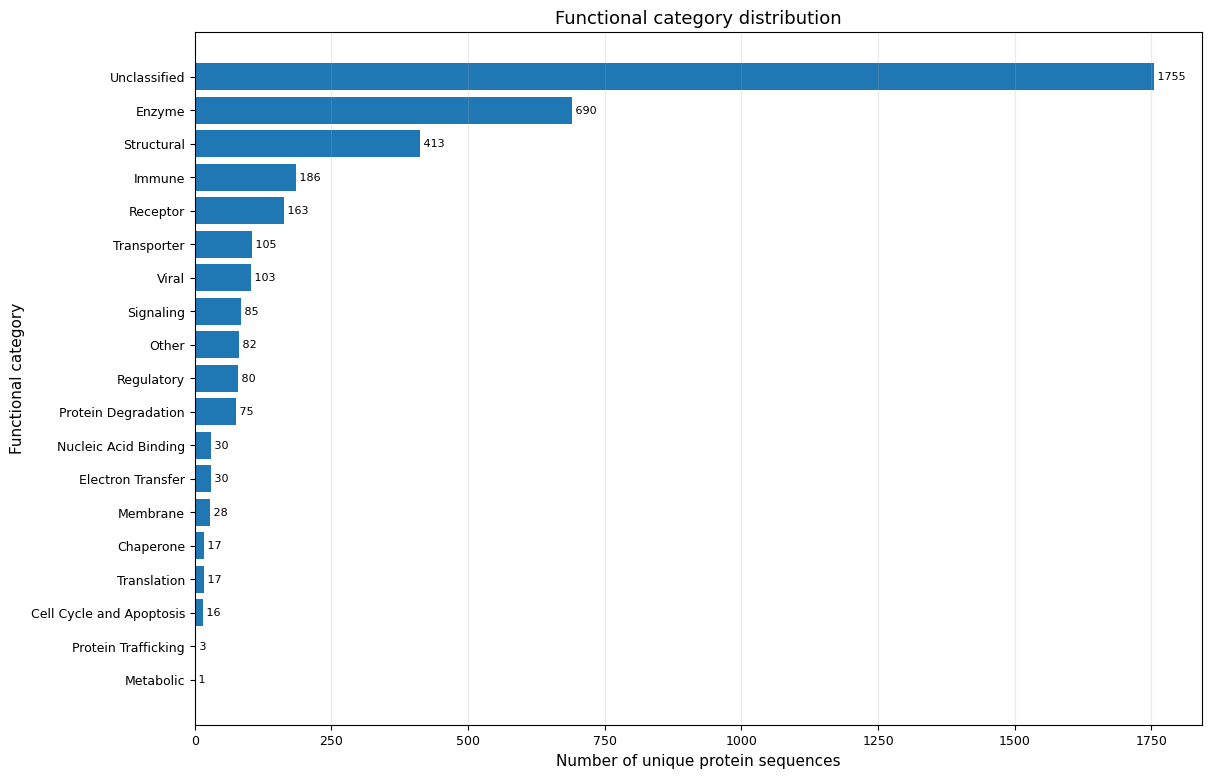


VISUALIZATION 2: CLASSIFICATION STATUS
Saved visualization: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\classification_visualizations\02_classification_status.png


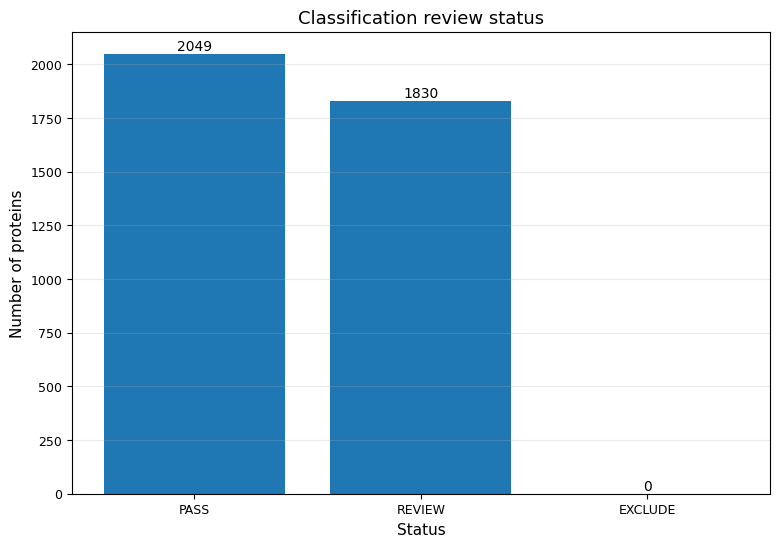


VISUALIZATION 3: SEQUENCE LENGTH GROUPS
Saved visualization: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\classification_visualizations\03_sequence_length_groups.png


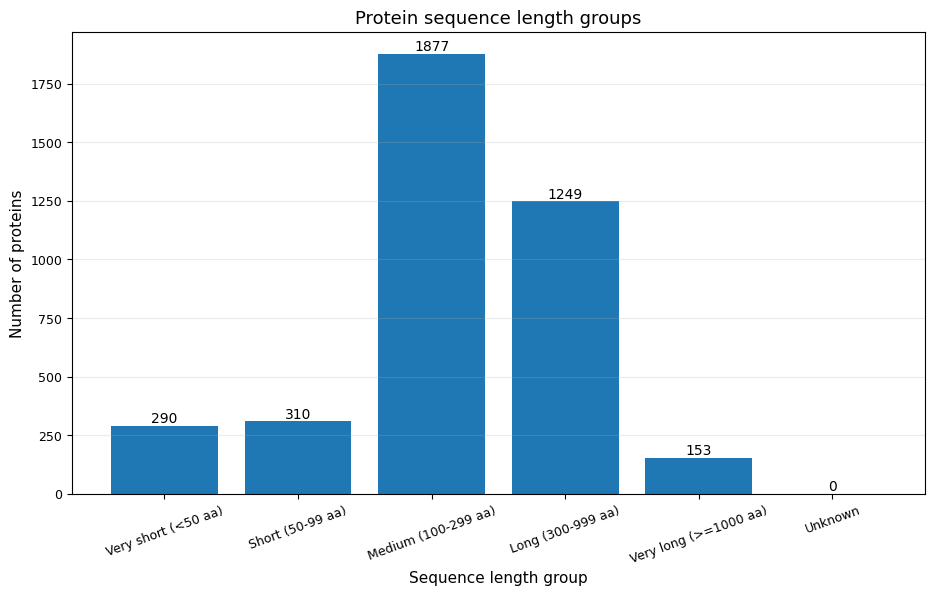


VISUALIZATION 4: BIOLOGICAL FLAGS
Saved visualization: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\classification_visualizations\04_special_biological_flags.png


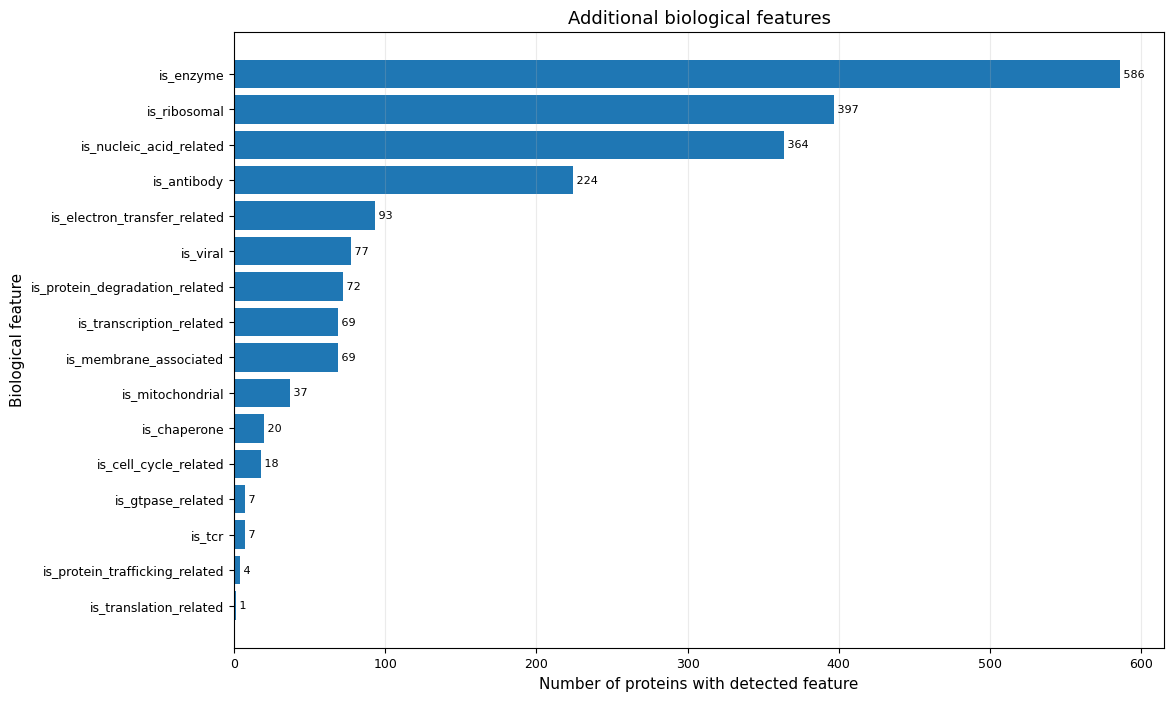


VISUALIZATION 5: CLASSIFICATION CONFIDENCE
Saved visualization: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\classification_visualizations\05_classification_confidence.png


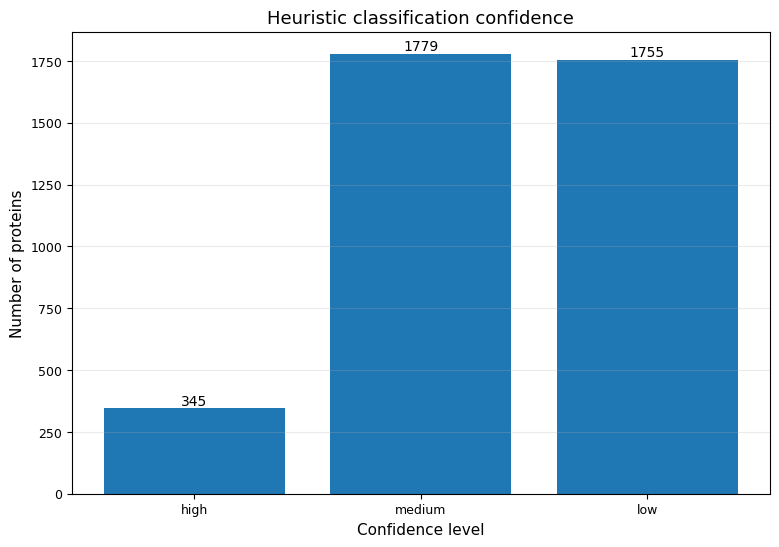


VISUALIZATION 6: CATEGORY / STATUS
Saved visualization: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\classification_visualizations\06_category_by_review_status.png


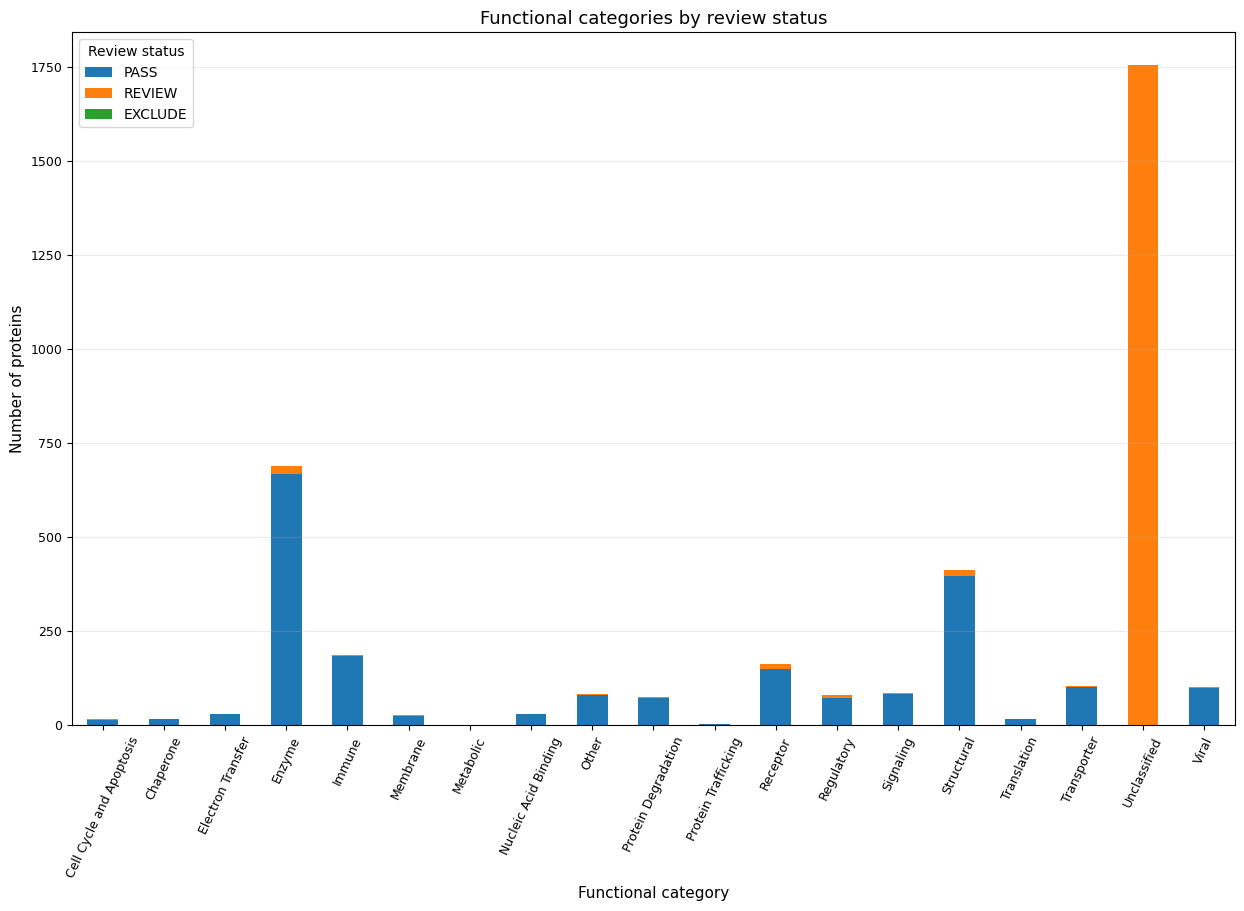


VISUALIZATION 7: MULTI-CATEGORY RECORDS
Saved visualization: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\classification_visualizations\07_single_vs_multiple_categories.png


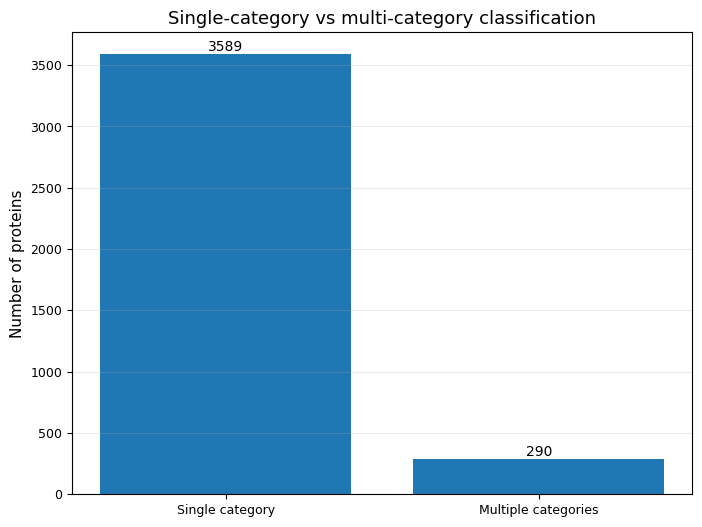


VISUALIZATION 8: CLASSIFICATION OVERVIEW
Saved visualization: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\classification_visualizations\08_classification_overview.png


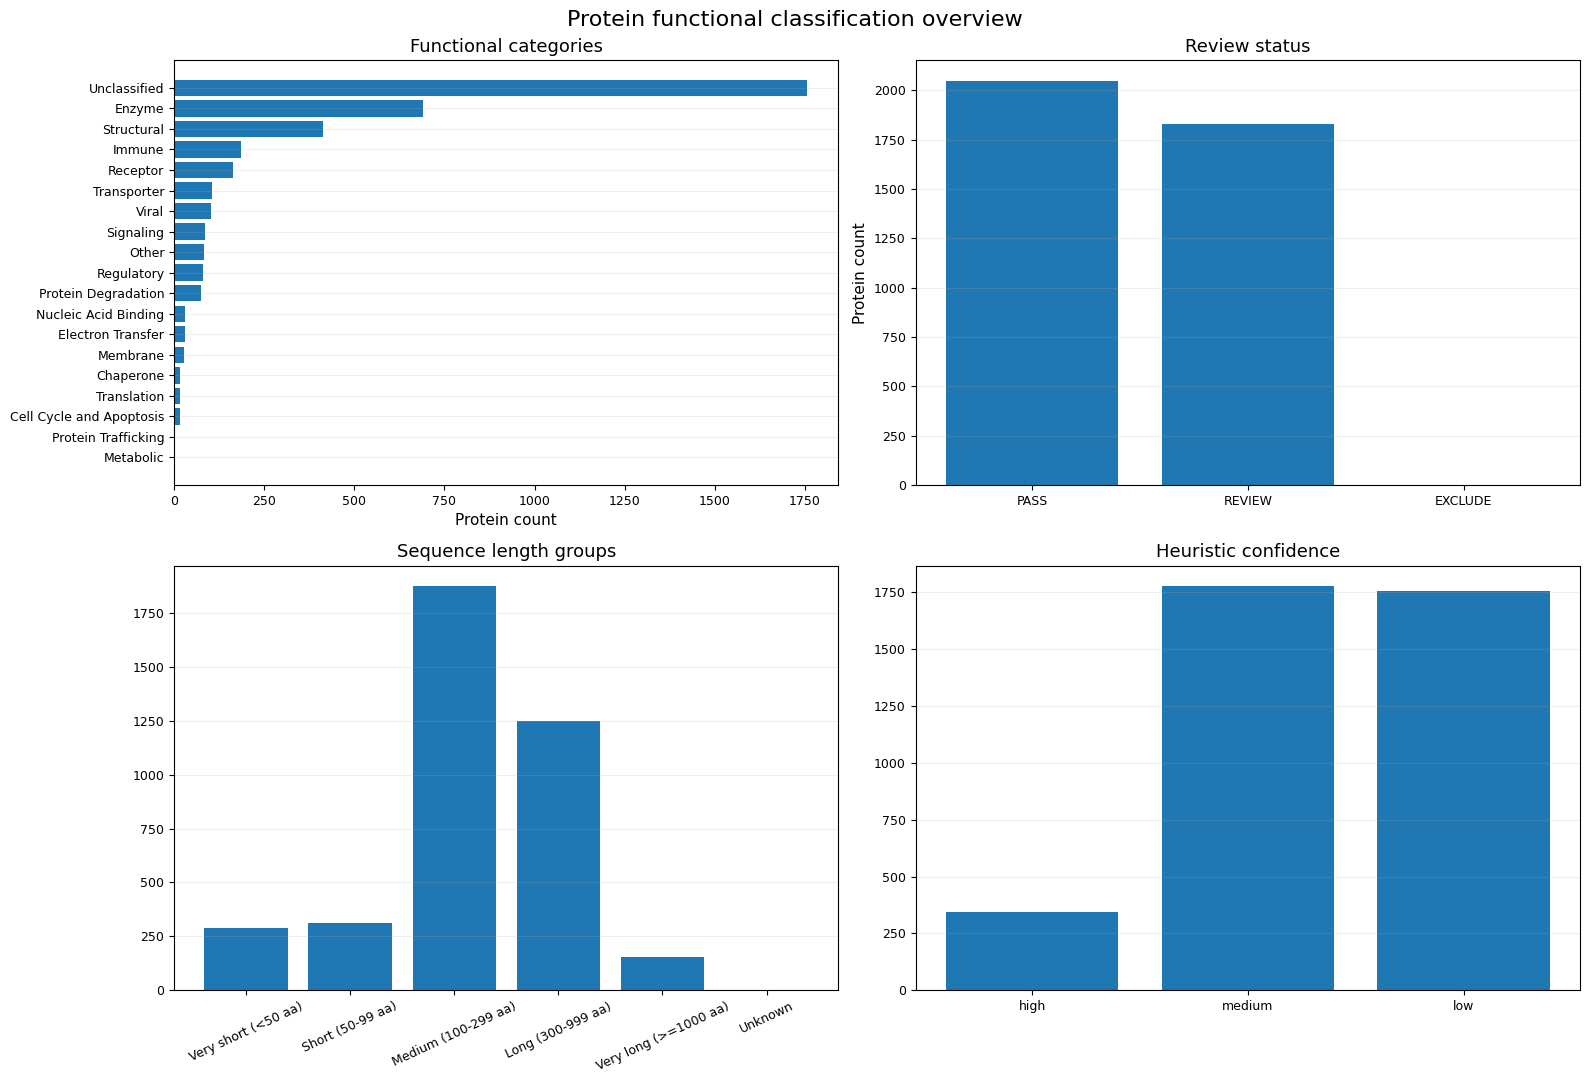


FUNCTIONAL CATEGORY DISTRIBUTION
functional_category
Unclassified                1755
Enzyme                       690
Structural                   413
Immune                       186
Receptor                     163
Transporter                  105
Viral                        103
Signaling                     85
Other                         82
Regulatory                    80
Protein Degradation           75
Nucleic Acid Binding          30
Electron Transfer             30
Membrane                      28
Chaperone                     17
Translation                   17
Cell Cycle and Apoptosis      16
Protein Trafficking            3
Metabolic                      1

CATEGORY OCCURRENCES INCLUDING ADDITIONAL LABELS
Enzyme                        :    756
Structural                    :    420
Other                         :    192
Immune                        :    186
Receptor                      :    185
Transporter                   :    106
Viral                         :    

In [13]:
# ============================================================
# CELL 8. FINAL FUNCTIONAL CLASSIFICATION V3.0.0
# ============================================================
# Назначение:
# Расширенная предварительная классификация уникальных белковых
# последовательностей по описаниям RCSB PDB.
#
# Новые категории:
# - Translation
# - Protein Trafficking
# - Cell Cycle and Apoptosis
# - Electron Transfer
#
# Дополнительно:
# - расширенные правила для известных белковых семейств;
# - многометочная классификация;
# - биологические признаки;
# - статусы PASS / REVIEW / EXCLUDE;
# - эвристический приоритет;
# - визуализация результатов.
#
# ВАЖНО:
# - Структурный анализ не выполняется.
# - Поиск карманов не выполняется.
# - Исходные последовательности не удаляются.
# - Неизвестные белки остаются Unclassified.
# - classification_confidence не является вероятностью.
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter


# ============================================================
# 2. PATHS AND PARAMETERS
# ============================================================

INPUT_FILE = CANDIDATES_DIR / "protein_unique_sequences.csv"

OUTPUT_FILE = (
    CANDIDATES_DIR / "protein_functional_classification.csv"
)

SUMMARY_FILE = (
    CANDIDATES_DIR / "protein_functional_classification_summary.json"
)

REVIEW_FILE = (
    CANDIDATES_DIR / "protein_functional_classification_review.csv"
)

UNCLASSIFIED_FILE = (
    CANDIDATES_DIR / "protein_functional_classification_unclassified.csv"
)

CONFLICTS_FILE = (
    CANDIDATES_DIR / "protein_functional_classification_conflicts.csv"
)

CATEGORY_SUMMARY_FILE = (
    CANDIDATES_DIR / "protein_functional_classification_category_summary.csv"
)

EXCLUDED_FILE = (
    CANDIDATES_DIR / "protein_functional_classification_excluded.csv"
)

# Папка визуализаций.

VISUALIZATION_DIR = (
    CANDIDATES_DIR / "classification_visualizations"
)

VISUALIZATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

MIN_SEQUENCE_LENGTH = 50
MAX_SEQUENCE_LENGTH = 3000

PRINT_EXAMPLES = 30

CLASSIFIER_VERSION = "3.0.0"

# Если в описании обнаружено несколько независимых
# функциональных признаков, уверенность может быть повышена.
#
# Это эвристика, а не статистическая вероятность.

HIGH_CONFIDENCE_MIN_SUBCATEGORIES = 2


print("=" * 80)
print("CELL 8. FINAL FUNCTIONAL CLASSIFICATION V3.0.0")
print("=" * 80)

print("Input:", INPUT_FILE)
print("Output:", OUTPUT_FILE)
print("Visualization directory:", VISUALIZATION_DIR)
print("Classifier version:", CLASSIFIER_VERSION)


if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Input file not found: {INPUT_FILE}"
    )


# ============================================================
# 3. LOAD INPUT DATA
# ============================================================

df = pd.read_csv(INPUT_FILE)

print("\nINPUT DATA")
print("-" * 80)

print("Unique protein records:", len(df))
print("Columns:", len(df.columns))


required_columns = [
    "unique_protein_id",
    "pdb_id",
    "entity_id",
    "description",
    "sequence_length_exact",
    "qc_status",
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise KeyError(
        f"Missing required columns: {missing_columns}"
    )

if df.empty:
    raise ValueError("Input dataset is empty.")

if df["unique_protein_id"].duplicated().any():
    raise ValueError(
        "Duplicate unique_protein_id values detected."
    )

df = df.copy()

df["pdb_id"] = (
    df["pdb_id"]
    .astype("string")
    .str.upper()
)

df["description"] = (
    df["description"]
    .fillna("")
    .astype(str)
)

df["qc_status"] = (
    df["qc_status"]
    .fillna("UNKNOWN")
    .astype(str)
    .str.upper()
    .str.strip()
)


# ============================================================
# 4. TEXT NORMALIZATION
# ============================================================

def normalize_description(value):

    if pd.isna(value):
        return ""

    text = str(value).lower()

    text = text.replace("_", " ")
    text = text.replace("-", " ")

    text = re.sub(
        r"[^a-z0-9\s]",
        " ",
        text
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()


df["description_normalized"] = (
    df["description"].apply(normalize_description)
)


# ============================================================
# 5. FUNCTIONAL CLASSIFICATION RULES
# ============================================================
# Правила намеренно разделены на категории и подкатегории.
#
# Некоторые белки могут относиться сразу к нескольким
# функциональным категориям.
#
# Неоднозначные названия не должны автоматически
# получать конкретную биологическую функцию.
# ============================================================


CLASSIFICATION_RULES = {

    # --------------------------------------------------------
    # 1. VIRAL
    # --------------------------------------------------------

    "Viral": {

        "priority": 1,

        "rules": {

            "Viral protein": [
                r"\bviral protein\b",
                r"\bviral polypeptide\b",
                r"\bvirus protein\b",
                r"\bvirion protein\b",
                r"\bvirus encoded protein\b",
                r"\bviral component\b",
            ],

            "Viral capsid": [
                r"\bcapsid\b",
                r"\bnucleocapsid\b",
                r"\bcoat protein\b",
                r"\bviral shell protein\b",
            ],

            "Viral surface protein": [
                r"\bspike protein\b",
                r"\benvelope protein\b",
                r"\bviral surface protein\b",
                r"\bviral glycoprotein\b",
                r"\bhemagglutinin\b",
                r"\bneuraminidase\b",
                r"\bfusion protein\b",
            ],

            "Viral nonstructural protein": [
                r"\bnon structural protein\b",
                r"\bnonstructural protein\b",
                r"\bviral replicase\b",
                r"\bviral replication protein\b",
                r"\breplication complex\b",
            ],

            "Viral protease": [
                r"\bviral protease\b",
                r"\bvirus encoded protease\b",
                r"\b3c like protease\b",
                r"\bmain protease\b",
                r"\b3cl protease\b",
                r"\bmpro\b",
            ],

            "Viral polymerase": [
                r"\brna dependent rna polymerase\b",
                r"\bviral polymerase\b",
                r"\bviral transcriptase\b",
                r"\breverse transcriptase\b",
            ],

            "Coronavirus": [
                r"\bcoronavirus\b",
                r"\bsars cov\b",
                r"\bsars coronavirus\b",
                r"\bmiddle east respiratory syndrome\b",
                r"\bmers cov\b",
            ],

            "Other viral": [
                r"\bviral\b",
                r"\bvirion\b",
                r"\bvirus encoded\b",
                r"\binfluenza virus\b",
                r"\bhiv\b",
                r"\bherpesvirus\b",
                r"\badenovirus\b",
                r"\bpoxvirus\b",
            ],
        },
    },


    # --------------------------------------------------------
    # 2. IMMUNE
    # --------------------------------------------------------

    "Immune": {

        "priority": 2,

        "rules": {

            "Antibody": [
                r"\bantibody\b",
                r"\bimmunoglobulin\b",
                r"\bfab\b",
                r"\bfab fragment\b",
                r"\bfab light chain\b",
                r"\bfab heavy chain\b",
                r"\bfv fragment\b",
                r"\bfv region\b",
                r"\bscfv\b",
                r"\bnanobody\b",
                r"\bsingle domain antibody\b",
                r"\bimmunoglobulin heavy chain\b",
                r"\bimmunoglobulin light chain\b",
                r"\bantibody light chain\b",
                r"\bantibody heavy chain\b",
            ],

            "T cell receptor": [
                r"\bt cell receptor\b",
                r"\btcr\b",
                r"\bt cell antigen receptor\b",
            ],

            "MHC and HLA": [
                r"\bmajor histocompatibility\b",
                r"\bmhc class\b",
                r"\bhla class\b",
                r"\bhla\b",
                r"\bmhc\b",
                r"\bantigen presentation\b",
            ],

            "Complement system": [
                r"\bcomplement protein\b",
                r"\bcomplement component\b",
                r"\bcomplement factor\b",
            ],

            "Cytokine": [
                r"\binterleukin\b",
                r"\binterferon\b",
                r"\btumor necrosis factor\b",
                r"\bcytokine\b",
                r"\bchemokine\b",
            ],

            "Immune recognition": [
                r"\bimmune recognition\b",
                r"\bimmune response\b",
                r"\bimmune system\b",
                r"\bimmunoregulatory\b",
                r"\bimmunological\b",
            ],
        },
    },


    # --------------------------------------------------------
    # 3. RECEPTOR
    # --------------------------------------------------------

    "Receptor": {

        "priority": 3,

        "rules": {

            "GPCR": [
                r"\bg protein coupled receptor\b",
                r"\bgpcr\b",
                r"\bseven transmembrane receptor\b",
                r"\b7 transmembrane receptor\b",
            ],

            "Receptor tyrosine kinase": [
                r"\breceptor tyrosine kinase\b",
                r"\btyrosine kinase receptor\b",
                r"\btyrosine protein kinase receptor\b",
            ],

            "Nuclear receptor": [
                r"\bnuclear receptor\b",
                r"\bsteroid receptor\b",
                r"\bestrogen receptor\b",
                r"\bandrogen receptor\b",
                r"\bglucocorticoid receptor\b",
                r"\bretinoic acid receptor\b",
            ],

            "Growth factor receptor": [
                r"\bgrowth factor receptor\b",
                r"\bepidermal growth factor receptor\b",
                r"\begfr\b",
                r"\bvascular endothelial growth factor receptor\b",
                r"\bvegfr\b",
                r"\bplatelet derived growth factor receptor\b",
            ],

            "Cell surface receptor": [
                r"\bcell surface receptor\b",
                r"\bcellular receptor\b",
                r"\bmembrane receptor\b",
                r"\breceptor protein\b",
                r"\breceptor subunit\b",
            ],

            "Other receptor": [
                r"\breceptor\b",
            ],
        },
    },


    # --------------------------------------------------------
    # 4. TRANSPORTER
    # --------------------------------------------------------

    "Transporter": {

        "priority": 4,

        "rules": {

            "ABC transporter": [
                r"\babc transporter\b",
                r"\batp binding cassette\b",
                r"\babc family transporter\b",
            ],

            "Ion channel": [
                r"\bion channel\b",
                r"\bpotassium channel\b",
                r"\bsodium channel\b",
                r"\bcalcium channel\b",
                r"\bchloride channel\b",
                r"\bvoltage gated channel\b",
                r"\bligand gated channel\b",
                r"\bmechanosensitive channel\b",
            ],

            "PTS transporter": [
                r"\bpts system\b",
                r"\bphosphotransferase system\b",
                r"\bmannitol specific eiicba\b",
                r"\beiicba\b",
                r"\beiic component\b",
                r"\bmannitol transporter\b",
                r"\bpts permease\b",
            ],

            "Membrane transporter": [
                r"\bmembrane transporter\b",
                r"\bmembrane transport protein\b",
                r"\btransmembrane transporter\b",
                r"\bsolute carrier\b",
                r"\bpermease\b",
                r"\btransporter protein\b",
            ],

            "Porin": [
                r"\bporin\b",
                r"\bouter membrane channel\b",
                r"\bmembrane pore\b",
            ],

            "Protein import and export": [
                r"\bimportin\b",
                r"\bexportin\b",
                r"\bprotein translocation\b",
                r"\btranslocation channel\b",
                r"\btranslocase\b",
                r"\bprotein transporter\b",
            ],

            "Other transporter": [
                r"\btransporter\b",
                r"\btransport protein\b",
                r"\btransport system\b",
                r"\btransport subunit\b",
            ],
        },
    },


    # --------------------------------------------------------
    # 5. PROTEIN DEGRADATION
    # --------------------------------------------------------

    "Protein Degradation": {

        "priority": 5,

        "rules": {

            "Ubiquitin system": [
                r"\bubiquitin\b",
                r"\bubiquitin ligase\b",
                r"\bubiquitin conjugating\b",
                r"\bubiquitin activating\b",
                r"\bdeubiquitinase\b",
                r"\bdeubiquitinating enzyme\b",
                r"\be3 ligase\b",
                r"\be2 enzyme\b",
                r"\be1 enzyme\b",
            ],

            "Proteasome": [
                r"\bproteasome\b",
                r"\bproteasomal\b",
                r"\bproteasome subunit\b",
                r"\b26s proteasome\b",
            ],

            "Protein quality control": [
                r"\bprotein degradation\b",
                r"\bprotein turnover\b",
                r"\bprotein quality control\b",
                r"\bprotein catabolism\b",
                r"\bcdc48\b",
                r"\bvcp\b",
                r"\bvalosin containing protein\b",
                r"\bnpl4\b",
                r"\bnuclear protein localization protein 4\b",
                r"\bubx domain\b",
                r"\bubx domain containing\b",
                r"\bsegregase\b",
                r"\baaa atpase associated with diverse cellular activities\b",
            ],

            "Autophagy": [
                r"\bautophagy\b",
                r"\bautophagy related\b",
                r"\bautophagosome\b",
                r"\bly sosomal degradation\b",
                r"\blysosomal degradation\b",
            ],
        },
    },


    # --------------------------------------------------------
    # 6. CHAPERONE
    # --------------------------------------------------------

    "Chaperone": {

        "priority": 6,

        "rules": {

            "Heat shock protein": [
                r"\bheat shock protein\b",
                r"\bhsp[0-9]+\b",
                r"\bhsp70\b",
                r"\bhsp90\b",
                r"\bhsp60\b",
            ],

            "Molecular chaperone": [
                r"\bchaperone\b",
                r"\bmolecular chaperone\b",
                r"\bprotein folding chaperone\b",
                r"\bfolding catalyst\b",
            ],

            "Chaperonin": [
                r"\bchaperonin\b",
                r"\bcct complex\b",
                r"\btricom chaperonin\b",
            ],

            "Protein folding": [
                r"\bprotein folding\b",
                r"\bfolding protein\b",
                r"\bdisulfide isomerase\b",
                r"\bpeptidyl prolyl isomerase\b",
                r"\bprotein disulfide isomerase\b",
            ],
        },
    },


    # --------------------------------------------------------
    # 7. STRUCTURAL
    # --------------------------------------------------------
    # Структурная категория поставлена выше Nucleic Acid Binding,
    # чтобы рибосомные белки не классифицировались прежде всего
    # как белки связывания нуклеиновых кислот.
    # --------------------------------------------------------

    "Structural": {

        "priority": 7,

        "rules": {

            "Ribosomal structure": [
                r"\bribosomal protein\b",
                r"\bribosome protein\b",
                r"\bribosome\b",
                r"\bribosomal subunit\b",
                r"\bribosome assembly\b",
                r"\bribosome biogenesis\b",
            ],

            "Cytoskeleton": [
                r"\bactin\b",
                r"\btubulin\b",
                r"\bmyosin\b",
                r"\bkinesin\b",
                r"\bdynactin\b",
                r"\bcytoskeletal\b",
                r"\bcytoskeleton\b",
                r"\bintermediate filament\b",
                r"\bprofilin\b",
            ],

            "Extracellular matrix": [
                r"\bcollagen\b",
                r"\belastin\b",
                r"\bfibronectin\b",
                r"\blaminin\b",
                r"\bextracellular matrix\b",
            ],

            "Structural protein": [
                r"\bstructural protein\b",
                r"\bstructural component\b",
                r"\bkeratin\b",
                r"\bscaffold structural protein\b",
            ],
        },
    },


    # --------------------------------------------------------
    # 8. TRANSLATION
    # --------------------------------------------------------

    "Translation": {

        "priority": 8,

        "rules": {

            "Translation initiation": [
                r"\btranslation initiation factor\b",
                r"\binitiation factor\b",
                r"\beif[0-9a-z]*\b",
                r"\bif[0-9]\b",
            ],

            "Translation elongation": [
                r"\btranslation elongation factor\b",
                r"\belongation factor\b",
                r"\bef tu\b",
                r"\bef ts\b",
                r"\bef g\b",
                r"\beef[0-9a-z]*\b",
            ],

            "Translation termination": [
                r"\btranslation termination factor\b",
                r"\btermination factor\b",
                r"\brelease factor\b",
                r"\bpeptide chain release factor\b",
                r"\beukaryotic peptide chain release factor\b",
                r"\berf[0-9]*\b",
            ],

            "Aminoacyl tRNA synthetase": [
                r"\baminoacyl trna synthetase\b",
                r"\btrna synthetase\b",
                r"\baminoacylation\b",
            ],

            "Ribosome-associated translation": [
                r"\bribosome associated factor\b",
                r"\btranslation associated protein\b",
                r"\bprotein synthesis factor\b",
                r"\bprotein biosynthesis factor\b",
            ],
        },
    },


    # --------------------------------------------------------
    # 9. NUCLEIC ACID BINDING
    # --------------------------------------------------------

    "Nucleic Acid Binding": {

        "priority": 9,

        "rules": {

            "DNA binding": [
                r"\bdna binding protein\b",
                r"\bdna binding\b",
                r"\bdna binding domain\b",
                r"\bdna binding factor\b",
            ],

            "RNA binding": [
                r"\brna binding protein\b",
                r"\brna binding\b",
                r"\brna binding domain\b",
                r"\brna recognition motif\b",
                r"\brna processing\b",
            ],

            "Nucleic acid binding": [
                r"\bnucleic acid binding\b",
                r"\bnucleic acid binding protein\b",
                r"\bnucleic acid binding domain\b",
            ],

            "DNA repair": [
                r"\bdna repair\b",
                r"\bdna recombination\b",
                r"\bdna mismatch repair\b",
                r"\bdna damage response\b",
            ],

            "RNA processing": [
                r"\brna processing\b",
                r"\brna splicing\b",
                r"\brna modification\b",
                r"\brna maturation\b",
            ],

            "Nuclease": [
                r"\bnuclease\b",
                r"\bendonuclease\b",
                r"\bexonuclease\b",
                r"\bribonuclease\b",
                r"\bdnase\b",
                r"\brnase\b",
            ],
        },
    },


    # --------------------------------------------------------
    # 10. REGULATORY
    # --------------------------------------------------------

    "Regulatory": {

        "priority": 10,

        "rules": {

            "Transcription factor": [
                r"\btranscription factor\b",
                r"\btranscriptional factor\b",
                r"\btranscription regulator\b",
                r"\btranscriptional regulator\b",
            ],

            "Chromatin regulator": [
                r"\bchromatin\b",
                r"\bhistone\b",
                r"\bchromatin remodeling\b",
                r"\bchromatin remodelling\b",
                r"\bepigenetic regulator\b",
                r"\bepigenetic\b",
                r"\bbromodomain\b",
                r"\bbromodomain containing\b",
            ],

            "Transcription cofactor": [
                r"\bcoactivator\b",
                r"\bcorepressor\b",
                r"\btranscription cofactor\b",
                r"\btranscriptional cofactor\b",
            ],

            "Gene expression regulation": [
                r"\bgene expression regulator\b",
                r"\bgene regulation\b",
                r"\bexpression regulator\b",
                r"\btranscriptional control\b",
            ],

            "Regulatory protein": [
                r"\bregulatory protein\b",
                r"\bregulator protein\b",
                r"\brepressor\b",
                r"\bactivator protein\b",
            ],
        },
    },


    # --------------------------------------------------------
    # 11. SIGNALING
    # --------------------------------------------------------

    "Signaling": {

        "priority": 11,

        "rules": {

            "Small GTPase": [
                r"\bsmall gtpase\b",
                r"\bras protein\b",
                r"\brho protein\b",
                r"\brac protein\b",
                r"\brab protein\b",
                r"\bran protein\b",
                r"\bgtp binding nuclear protein ran\b",
                r"\barf protein\b",
            ],

            "G protein": [
                r"\bg protein\b",
                r"\bguanine nucleotide binding protein\b",
                r"\bheterotrimeric g protein\b",
                r"\bg alpha subunit\b",
                r"\bg beta subunit\b",
                r"\bg gamma subunit\b",
            ],

            "Signal transduction": [
                r"\bsignal transduction\b",
                r"\bsignal transduction protein\b",
                r"\bsignaling protein\b",
                r"\bsignalling protein\b",
                r"\bsignaling pathway\b",
                r"\bsignalling pathway\b",
            ],

            "Adaptor protein": [
                r"\badaptor protein\b",
                r"\badapter protein\b",
                r"\bscaffold protein\b",
                r"\bsignaling adaptor\b",
                r"\bsignalling adaptor\b",
            ],

            "Cell signaling": [
                r"\bcell signaling\b",
                r"\bcell signalling\b",
                r"\bintracellular signaling\b",
                r"\bintracellular signalling\b",
            ],
        },
    },


    # --------------------------------------------------------
    # 12. CELL CYCLE AND APOPTOSIS
    # --------------------------------------------------------

    "Cell Cycle and Apoptosis": {

        "priority": 12,

        "rules": {

            "Cell cycle": [
                r"\bcell cycle\b",
                r"\bcell division cycle\b",
                r"\bcell cycle regulator\b",
                r"\bcell division control protein\b",
                r"\bcdc[0-9]+\b",
                r"\bcyclin\b",
            ],

            "Apoptosis": [
                r"\bapoptosis\b",
                r"\bapoptotic\b",
                r"\bprogrammed cell death\b",
                r"\bcell death regulator\b",
            ],

            "Caspase-related": [
                r"\bcaspase\b",
                r"\bcaspase activator\b",
                r"\bcaspase inhibitor\b",
            ],

            "Cell proliferation": [
                r"\bcell proliferation\b",
                r"\bgrowth regulation\b",
                r"\bproliferation regulator\b",
            ],
        },
    },


    # --------------------------------------------------------
    # 13. PROTEIN TRAFFICKING
    # --------------------------------------------------------

    "Protein Trafficking": {

        "priority": 13,

        "rules": {

            "Nuclear transport": [
                r"\bnuclear transport\b",
                r"\bnuclear export\b",
                r"\bnuclear import\b",
                r"\bnuclear rna export factor\b",
                r"\bntf2\b",
                r"\bntf2 related export protein\b",
                r"\bimportin\b",
                r"\bexportin\b",
            ],

            "Vesicular transport": [
                r"\bvesicular transport\b",
                r"\bvesicle transport\b",
                r"\bvesicle trafficking\b",
                r"\bcoat protein complex\b",
                r"\bclathrin\b",
                r"\bcop[0-9]\b",
            ],

            "Intracellular trafficking": [
                r"\bintracellular trafficking\b",
                r"\bprotein trafficking\b",
                r"\bprotein sorting\b",
                r"\bprotein localization\b",
                r"\bvesicle associated\b",
            ],

            "Membrane trafficking": [
                r"\bmembrane trafficking\b",
                r"\bmembrane targeting\b",
                r"\bmembrane fusion\b",
                r"\bsnare protein\b",
            ],
        },
    },


    # --------------------------------------------------------
    # 14. ENZYME
    # --------------------------------------------------------

    "Enzyme": {

        "priority": 14,

        "rules": {

            "Kinase": [
                r"\bkinase\b",
                r"\bprotein kinase\b",
                r"\bserine threonine kinase\b",
                r"\btyrosine kinase\b",
                r"\bcasein kinase\b",
                r"\bcyclin dependent kinase\b",
                r"\bcdk[0-9]*\b",
            ],

            "Phosphatase": [
                r"\bphosphatase\b",
                r"\bprotein phosphatase\b",
                r"\btyrosine phosphatase\b",
                r"\bserine threonine phosphatase\b",
            ],

            "Protease": [
                r"\bprotease\b",
                r"\bpeptidase\b",
                r"\bproteinase\b",
                r"\bmetalloprotease\b",
                r"\bserine protease\b",
                r"\bcysteine protease\b",
                r"\baspartic protease\b",
                r"\bthreonine protease\b",
                r"\bcathepsin\b",
                r"\bcaspase\b",
                r"\bcalpain\b",
            ],

            "Dehydrogenase": [
                r"\bdehydrogenase\b",
                r"\balcohol dehydrogenase\b",
                r"\blactate dehydrogenase\b",
                r"\bmalate dehydrogenase\b",
                r"\bglyceraldehyde 3 phosphate dehydrogenase\b",
            ],

            "Oxidoreductase": [
                r"\boxidoreductase\b",
                r"\boxidase\b",
                r"\breductase\b",
                r"\bperoxidase\b",
                r"\boxygenase\b",
                r"\bmonooxygenase\b",
                r"\bdioxygenase\b",
            ],

            "Transferase": [
                r"\btransferase\b",
                r"\baminotransferase\b",
                r"\btransaminase\b",
                r"\bmethyltransferase\b",
                r"\bacetyltransferase\b",
                r"\bglycosyltransferase\b",
                r"\btranspeptidase\b",
                r"\bmethylase\b",
            ],

            "Hydrolase": [
                r"\bhydrolase\b",
                r"\besterase\b",
                r"\bphosphodiesterase\b",
                r"\bphospholipase\b",
                r"\bcarbonic anhydrase\b",
            ],

            "Polymerase": [
                r"\bpolymerase\b",
                r"\bdna polymerase\b",
                r"\brna polymerase\b",
                r"\bterminal transferase\b",
            ],

            "Ligase": [
                r"\bligase\b",
                r"\bsynthetase\b",
                r"\baminoacyl trna synthetase\b",
            ],

            "Isomerase": [
                r"\bisomerase\b",
                r"\bmutase\b",
                r"\brace mase\b",
            ],

            "Lyase": [
                r"\blyase\b",
                r"\bdecarboxylase\b",
                r"\baldolase\b",
                r"\bdehydratase\b",
                r"\bcyclase\b",
            ],

            "Other enzyme": [
                r"\benzyme\b",
                r"\bcatalytic subunit\b",
                r"\bcatalytic domain\b",
                r"\bcatalytic protein\b",
            ],
        },
    },


    # --------------------------------------------------------
    # 15. ELECTRON TRANSFER
    # --------------------------------------------------------

    "Electron Transfer": {

        "priority": 15,

        "rules": {

            "Cytochrome": [
                r"\bcytochrome\b",
                r"\bcytochrome b562\b",
                r"\bcytochrome c\b",
                r"\bcytochrome oxidase\b",
            ],

            "Iron sulfur protein": [
                r"\biron sulfur protein\b",
                r"\bferredoxin\b",
                r"\bfe s cluster\b",
                r"\biron sulfur cluster\b",
            ],

            "Electron transfer protein": [
                r"\belectron transfer protein\b",
                r"\belectron transport protein\b",
                r"\belectron carrier protein\b",
                r"\belectron transfer flavoprotein\b",
            ],

            "Respiratory chain": [
                r"\brespiratory chain\b",
                r"\brespiratory complex\b",
                r"\belectron transport chain\b",
                r"\boxidative phosphorylation\b",
            ],
        },
    },


    # --------------------------------------------------------
    # 16. METABOLIC
    # --------------------------------------------------------

    "Metabolic": {

        "priority": 16,

        "rules": {

            "Carbohydrate metabolism": [
                r"\bglycolysis\b",
                r"\bgluconeogenesis\b",
                r"\bcarbohydrate metabolism\b",
                r"\bglucose metabolism\b",
                r"\bglycolytic\b",
            ],

            "Lipid metabolism": [
                r"\blipid metabolism\b",
                r"\bfatty acid metabolism\b",
                r"\bfatty acid synthesis\b",
                r"\bfatty acid oxidation\b",
                r"\bcholesterol metabolism\b",
            ],

            "Amino acid metabolism": [
                r"\bamino acid metabolism\b",
                r"\bamino acid biosynthesis\b",
                r"\bamino acid degradation\b",
            ],

            "Nucleotide metabolism": [
                r"\bnucleotide metabolism\b",
                r"\bpurine metabolism\b",
                r"\bpyrimidine metabolism\b",
                r"\bnucleotide biosynthesis\b",
            ],

            "Energy metabolism": [
                r"\benergy metabolism\b",
                r"\batp synthesis\b",
                r"\boxidative phosphorylation\b",
                r"\brespiratory chain\b",
            ],

            "Metabolic protein": [
                r"\bmetabolic protein\b",
                r"\bmetabolism related protein\b",
                r"\bmetabolic pathway\b",
            ],
        },
    },


    # --------------------------------------------------------
    # 17. MEMBRANE
    # --------------------------------------------------------

    "Membrane": {

        "priority": 17,

        "rules": {

            "Transmembrane protein": [
                r"\btransmembrane protein\b",
                r"\btransmembrane domain\b",
                r"\btransmembrane helix\b",
            ],

            "Membrane protein": [
                r"\bmembrane protein\b",
                r"\bintegral membrane protein\b",
                r"\bperipheral membrane protein\b",
                r"\bmembrane associated protein\b",
                r"\bmembrane associated\b",
            ],

            "Outer membrane protein": [
                r"\bouter membrane protein\b",
                r"\binner membrane protein\b",
                r"\bouter mitochondrial membrane\b",
                r"\binner mitochondrial membrane\b",
            ],
        },
    },


    # --------------------------------------------------------
    # 18. OTHER
    # --------------------------------------------------------

    "Other": {

        "priority": 18,

        "rules": {

            "Carrier protein": [
                r"\bcarrier protein\b",
            ],

            "Storage protein": [
                r"\bstorage protein\b",
                r"\bserum albumin\b",
                r"\balbumin\b",
                r"\bferritin\b",
            ],

            "Fluorescent protein": [
                r"\bfluorescent protein\b",
                r"\bgreen fluorescent protein\b",
                r"\bgfp\b",
                r"\byellow fluorescent protein\b",
                r"\bred fluorescent protein\b",
            ],

            "Binding protein": [
                r"\bbinding protein\b",
                r"\bligand binding protein\b",
                r"\bmetal binding protein\b",
            ],

            "Other identified function": [
                r"\bscavenger\b",
                r"\baccessory protein\b",
                r"\baccessory factor\b",
            ],
        },
    },
}


# ============================================================
# 6. CLASSIFICATION PRIORITY
# ============================================================

CATEGORY_PRIORITY = {
    category: data["priority"]
    for category, data in CLASSIFICATION_RULES.items()
}

ALL_CATEGORIES = list(CLASSIFICATION_RULES.keys())

print("\nCLASSIFICATION DICTIONARY")
print("-" * 80)

for category, data in CLASSIFICATION_RULES.items():

    pattern_count = sum(
        len(patterns)
        for patterns in data["rules"].values()
    )

    print(
        f"{category:30s} "
        f"priority={data['priority']:2d} "
        f"patterns={pattern_count:3d}"
    )


# ============================================================
# 7. COMPILE REGULAR EXPRESSIONS
# ============================================================

COMPILED_RULES = {}

for category, category_data in CLASSIFICATION_RULES.items():

    COMPILED_RULES[category] = {}

    for subcategory, patterns in category_data["rules"].items():

        COMPILED_RULES[category][subcategory] = [
            re.compile(pattern, flags=re.IGNORECASE)
            for pattern in patterns
        ]


# ============================================================
# 8. ADDITIONAL BIOLOGICAL FLAGS
# ============================================================

SPECIAL_FLAGS = {

    "is_antibody": [
        r"\bantibody\b",
        r"\bimmunoglobulin\b",
        r"\bfab\b",
        r"\bfab fragment\b",
        r"\bfv fragment\b",
        r"\bscfv\b",
        r"\bnanobody\b",
        r"\bheavy chain\b",
        r"\blight chain\b",
    ],

    "is_tcr": [
        r"\bt cell receptor\b",
        r"\btcr\b",
    ],

    "is_ribosomal": [
        r"\bribosomal protein\b",
        r"\bribosome\b",
        r"\bribosomal subunit\b",
    ],

    "is_viral": [
        r"\bviral\b",
        r"\bvirus\b",
        r"\bvirion\b",
        r"\bnon structural protein\b",
        r"\bnonstructural protein\b",
        r"\bcapsid\b",
        r"\bspike protein\b",
        r"\bcoronavirus\b",
        r"\bsars cov\b",
        r"\binfluenza\b",
        r"\bhiv\b",
    ],

    "is_membrane_associated": [
        r"\bmembrane protein\b",
        r"\btransmembrane\b",
        r"\bmembrane receptor\b",
        r"\bion channel\b",
        r"\btransporter\b",
        r"\bporin\b",
        r"\bpermease\b",
    ],

    "is_nucleic_acid_related": [
        r"\bdna binding\b",
        r"\brna binding\b",
        r"\bnucleic acid binding\b",
        r"\bpolymerase\b",
        r"\bnuclease\b",
        r"\btranscription factor\b",
        r"\bribosomal protein\b",
        r"\brna processing\b",
    ],

    "is_mitochondrial": [
        r"\bmitochondrial\b",
        r"\bmitochondrion\b",
        r"\bmitochondria\b",
    ],

    "is_gtpase_related": [
        r"\bgtpase\b",
        r"\bgtp binding\b",
        r"\bgtp binding protein\b",
        r"\bran protein\b",
        r"\bras protein\b",
        r"\brho protein\b",
        r"\brab protein\b",
        r"\brac protein\b",
    ],

    "is_enzyme": [
        r"\bkinase\b",
        r"\bphosphatase\b",
        r"\bprotease\b",
        r"\bpeptidase\b",
        r"\bpolymerase\b",
        r"\bdehydrogenase\b",
        r"\btransferase\b",
        r"\boxidase\b",
        r"\breductase\b",
        r"\bsynthase\b",
        r"\bsynthetase\b",
        r"\bligase\b",
        r"\bhydrolase\b",
        r"\besterase\b",
        r"\bnuclease\b",
        r"\bdecarboxylase\b",
        r"\bmethylase\b",
    ],

    "is_chaperone": [
        r"\bchaperone\b",
        r"\bchaperonin\b",
        r"\bheat shock protein\b",
        r"\bhsp[0-9]+\b",
        r"\bprotein folding\b",
    ],

    "is_transcription_related": [
        r"\btranscription factor\b",
        r"\btranscriptional regulator\b",
        r"\btranscription regulator\b",
        r"\bchromatin\b",
        r"\bhistone\b",
        r"\bbromodomain\b",
    ],

    "is_protein_degradation_related": [
        r"\bubiquitin\b",
        r"\bproteasome\b",
        r"\bdeubiquitinase\b",
        r"\bprotein degradation\b",
        r"\bprotein turnover\b",
        r"\bautophagy\b",
        r"\bcdc48\b",
        r"\bvcp\b",
        r"\bnpl4\b",
    ],

    "is_translation_related": [
        r"\btranslation factor\b",
        r"\btranslation initiation\b",
        r"\btranslation elongation\b",
        r"\btranslation termination\b",
        r"\brelease factor\b",
        r"\baminoacyl trna synthetase\b",
    ],

    "is_electron_transfer_related": [
        r"\bcytochrome\b",
        r"\bferredoxin\b",
        r"\biron sulfur\b",
        r"\belectron transfer\b",
        r"\brespiratory chain\b",
    ],

    "is_cell_cycle_related": [
        r"\bcell cycle\b",
        r"\bcell division\b",
        r"\bcyclin\b",
        r"\bcdc[0-9]+\b",
        r"\bapoptosis\b",
        r"\bcaspase\b",
    ],

    "is_protein_trafficking_related": [
        r"\bprotein trafficking\b",
        r"\bnuclear transport\b",
        r"\bnuclear export\b",
        r"\bnuclear import\b",
        r"\bvesicle transport\b",
        r"\bvesicular transport\b",
        r"\bntf2\b",
        r"\bimportin\b",
        r"\bexportin\b",
    ],
}


COMPILED_FLAGS = {
    flag: [
        re.compile(pattern, flags=re.IGNORECASE)
        for pattern in patterns
    ]
    for flag, patterns in SPECIAL_FLAGS.items()
}


# ============================================================
# 9. CLASSIFICATION ENGINE
# ============================================================

def classify_protein(description):

    text = normalize_description(description)

    if not text:

        return {
            "functional_category": "Unclassified",
            "functional_subcategory": "Unknown",
            "functional_labels": "",
            "matched_keywords": "",
            "classification_confidence": "low",
            "classification_match_count": 0,
            "classification_subcategory_count": 0,
            "classification_reason": "Empty protein description",
            "matched_categories": "",
        }

    matched_categories = []
    matched_subcategories = []
    matched_keywords = []

    # Проверяем все категории.

    for category, subcategories in COMPILED_RULES.items():

        category_matched = False

        for subcategory, compiled_patterns in subcategories.items():

            for pattern in compiled_patterns:

                if pattern.search(text):

                    category_matched = True

                    matched_subcategories.append(
                        subcategory
                    )

                    matched_keywords.append(
                        pattern.pattern
                    )

        if category_matched:
            matched_categories.append(category)

    # Если совпадений нет.

    if not matched_categories:

        return {
            "functional_category": "Unclassified",
            "functional_subcategory": "Unknown",
            "functional_labels": "",
            "matched_keywords": "",
            "classification_confidence": "low",
            "classification_match_count": 0,
            "classification_subcategory_count": 0,
            "classification_reason": "No matching functional keywords",
            "matched_categories": "",
        }

    # Удаляем повторы.

    matched_categories = list(
        dict.fromkeys(matched_categories)
    )

    matched_subcategories = list(
        dict.fromkeys(matched_subcategories)
    )

    matched_keywords = list(
        dict.fromkeys(matched_keywords)
    )

    # Основная категория определяется приоритетом.

    primary_category = min(
        matched_categories,
        key=lambda x: CATEGORY_PRIORITY[x]
    )

    additional_categories = [
        category
        for category in matched_categories
        if category != primary_category
    ]

    labels = [
        primary_category
    ] + additional_categories

    # Условная оценка уверенности.
    #
    # Число независимых подкатегорий используется как
    # эвристический признак. Это не вероятность.

    subcategory_count = len(matched_subcategories)

    if subcategory_count >= HIGH_CONFIDENCE_MIN_SUBCATEGORIES:

        confidence = "high"

    elif subcategory_count == 1:

        confidence = "medium"

    else:

        confidence = "low"

    reason = (
        f"Primary category: {primary_category}; "
        f"matched categories: {len(matched_categories)}; "
        f"matched subcategories: {subcategory_count}"
    )

    return {

        "functional_category": primary_category,

        "functional_subcategory": "; ".join(
            matched_subcategories
        ),

        "functional_labels": "; ".join(
            labels
        ),

        "matched_keywords": "; ".join(
            matched_keywords
        ),

        "classification_confidence": confidence,

        "classification_match_count": len(matched_keywords),

        "classification_subcategory_count": subcategory_count,

        "classification_reason": reason,

        "matched_categories": "; ".join(
            matched_categories
        ),
    }


# ============================================================
# 10. APPLY CLASSIFICATION
# ============================================================

print("\nAPPLYING FUNCTIONAL CLASSIFICATION")
print("-" * 80)

classification_results = df[
    "description_normalized"
].apply(classify_protein)

classification_df = pd.DataFrame(
    classification_results.tolist(),
    index=df.index
)

df = pd.concat(
    [df, classification_df],
    axis=1
)

print("Classification completed.")
print("Records:", len(df))


# ============================================================
# 11. APPLY SPECIAL BIOLOGICAL FLAGS
# ============================================================

print("\nDETECTING BIOLOGICAL FLAGS")
print("-" * 80)

for flag_name, compiled_patterns in COMPILED_FLAGS.items():

    df[flag_name] = df[
        "description_normalized"
    ].apply(
        lambda text: any(
            pattern.search(text)
            for pattern in compiled_patterns
        ) if text else False
    )

    print(
        f"{flag_name:40s}: {int(df[flag_name].sum())}"
    )


# ============================================================
# 12. SEQUENCE LENGTH GROUPS
# ============================================================

def assign_length_group(length):

    if pd.isna(length):
        return "Unknown"

    length = int(length)

    if length < 50:
        return "Very short (<50 aa)"

    elif length < 100:
        return "Short (50-99 aa)"

    elif length < 300:
        return "Medium (100-299 aa)"

    elif length < 1000:
        return "Long (300-999 aa)"

    else:
        return "Very long (>=1000 aa)"


df["sequence_length_exact"] = pd.to_numeric(
    df["sequence_length_exact"],
    errors="coerce"
)

df["sequence_length_group"] = (
    df["sequence_length_exact"]
    .apply(assign_length_group)
)


# ============================================================
# 13. QC AND CLASSIFICATION STATUS
# ============================================================

def determine_selection_status(row):

    qc_status = str(
        row["qc_status"]
    ).upper().strip()

    if qc_status in {"FAIL", "EXCLUDE", "INVALID"}:
        return "EXCLUDE"

    if row["functional_category"] == "Unclassified":
        return "REVIEW"

    if qc_status != "PASS":
        return "REVIEW"

    if row["classification_confidence"] == "low":
        return "REVIEW"

    length = row["sequence_length_exact"]

    if pd.isna(length):
        return "REVIEW"

    if length < MIN_SEQUENCE_LENGTH:
        return "REVIEW"

    if length > MAX_SEQUENCE_LENGTH:
        return "REVIEW"

    return "PASS"


df["classification_review_status"] = df.apply(
    determine_selection_status,
    axis=1
)


# ============================================================
# 14. SELECTION PRIORITY
# ============================================================

def determine_selection_priority(row):

    status = row["classification_review_status"]

    category = row["functional_category"]

    if status == "EXCLUDE":
        return "LOW"

    if category == "Unclassified":
        return "LOW"

    if status == "PASS":
        return "HIGH"

    if status == "REVIEW":
        return "MEDIUM"

    return "LOW"


df["selection_priority"] = df.apply(
    determine_selection_priority,
    axis=1
)


# ============================================================
# 15. MULTI-CATEGORY DIAGNOSTICS
# ============================================================

df["functional_category_count"] = (
    df["matched_categories"]
    .fillna("")
    .apply(
        lambda x: len([
            item for item in x.split(";")
            if item.strip()
        ])
    )
)

df["has_multiple_functional_categories"] = (
    df["functional_category_count"] > 1
)


# ============================================================
# 16. SUMMARY STATISTICS
# ============================================================

category_counts = (
    df["functional_category"]
    .value_counts()
    .sort_values(ascending=False)
)

review_counts = (
    df["classification_review_status"]
    .value_counts()
)

priority_counts = (
    df["selection_priority"]
    .value_counts()
)

length_counts = (
    df["sequence_length_group"]
    .value_counts()
)

confidence_counts = (
    df["classification_confidence"]
    .value_counts()
)

special_flag_counts = {
    flag: int(df[flag].sum())
    for flag in SPECIAL_FLAGS
}

additional_category_counts = Counter()

for labels in df["matched_categories"].fillna(""):

    for category in labels.split(";"):

        category = category.strip()

        if category:
            additional_category_counts[category] += 1


category_summary = pd.DataFrame({

    "functional_category": ALL_CATEGORIES,

    "protein_count": [
        int(
            (
                df["functional_category"] == category
            ).sum()
        )
        for category in ALL_CATEGORIES
    ],

    "matched_including_additional_labels": [
        int(
            additional_category_counts.get(category, 0)
        )
        for category in ALL_CATEGORIES
    ],

})


# ============================================================
# 17. REVIEW / UNCLASSIFIED / CONFLICT / EXCLUDE TABLES
# ============================================================

df_review = df[
    df["classification_review_status"] == "REVIEW"
].copy()

df_unclassified = df[
    df["functional_category"] == "Unclassified"
].copy()

df_conflicts = df[
    df["has_multiple_functional_categories"]
].copy()

df_excluded = df[
    df["classification_review_status"] == "EXCLUDE"
].copy()


# ============================================================
# 18. OUTPUT COLUMN ORDER
# ============================================================

preferred_columns = [

    "unique_protein_id",
    "pdb_id",
    "entity_id",

    "description",
    "description_normalized",

    "functional_category",
    "functional_subcategory",
    "functional_labels",
    "matched_categories",
    "matched_keywords",

    "classification_confidence",
    "classification_match_count",
    "classification_subcategory_count",
    "classification_reason",

    "functional_category_count",
    "has_multiple_functional_categories",

    "classification_review_status",
    "selection_priority",

    "sequence_length_exact",
    "sequence_length_group",

    "qc_status",

    "experimental_method",
    "resolution",
    "sequence_group_size",

]

preferred_columns += list(SPECIAL_FLAGS.keys())

output_columns = [
    col for col in preferred_columns
    if col in df.columns
]

output_columns += [
    col for col in df.columns
    if col not in output_columns
]

df = df[output_columns].copy()


# ============================================================
# 19. SAVE TABLES
# ============================================================

df.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)

df_review.to_csv(
    REVIEW_FILE,
    index=False,
    encoding="utf-8-sig"
)

df_unclassified.to_csv(
    UNCLASSIFIED_FILE,
    index=False,
    encoding="utf-8-sig"
)

df_conflicts.to_csv(
    CONFLICTS_FILE,
    index=False,
    encoding="utf-8-sig"
)

df_excluded.to_csv(
    EXCLUDED_FILE,
    index=False,
    encoding="utf-8-sig"
)

category_summary.to_csv(
    CATEGORY_SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("\nTABLES SAVED")
print("-" * 80)

print("Classification:", OUTPUT_FILE)
print("Review:", REVIEW_FILE)
print("Unclassified:", UNCLASSIFIED_FILE)
print("Conflicts:", CONFLICTS_FILE)
print("Excluded:", EXCLUDED_FILE)
print("Category summary:", CATEGORY_SUMMARY_FILE)


# ============================================================
# 20. VISUALIZATION SETTINGS
# ============================================================

plt.rcParams["figure.figsize"] = (12, 7)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 9
plt.rcParams["ytick.labelsize"] = 9


def save_figure(fig, filename):

    output_path = VISUALIZATION_DIR / filename

    fig.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight"
    )

    print("Saved visualization:", output_path)

    plt.show()

    plt.close(fig)


# ============================================================
# 21. VISUALIZATION 1 — FUNCTIONAL CATEGORY DISTRIBUTION
# ============================================================

print("\nVISUALIZATION 1: FUNCTIONAL CATEGORIES")

plot_data = category_counts.sort_values(
    ascending=True
)

fig, ax = plt.subplots(figsize=(13, 9))

ax.barh(
    plot_data.index,
    plot_data.values
)

ax.set_title(
    "Functional category distribution"
)

ax.set_xlabel(
    "Number of unique protein sequences"
)

ax.set_ylabel(
    "Functional category"
)

ax.grid(
    axis="x",
    alpha=0.25
)

for i, value in enumerate(plot_data.values):

    ax.text(
        value,
        i,
        f" {value}",
        va="center",
        fontsize=8
    )

save_figure(
    fig,
    "01_functional_category_distribution.png"
)


# ============================================================
# 22. VISUALIZATION 2 — CLASSIFICATION STATUS
# ============================================================

print("\nVISUALIZATION 2: CLASSIFICATION STATUS")

status_order = [
    "PASS",
    "REVIEW",
    "EXCLUDE",
]

status_data = (
    review_counts
    .reindex(status_order)
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.bar(
    status_data.index,
    status_data.values
)

ax.set_title(
    "Classification review status"
)

ax.set_xlabel(
    "Status"
)

ax.set_ylabel(
    "Number of proteins"
)

ax.grid(
    axis="y",
    alpha=0.25
)

for i, value in enumerate(status_data.values):

    ax.text(
        i,
        value,
        f"{int(value)}",
        ha="center",
        va="bottom"
    )

save_figure(
    fig,
    "02_classification_status.png"
)


# ============================================================
# 23. VISUALIZATION 3 — SEQUENCE LENGTH DISTRIBUTION
# ============================================================

print("\nVISUALIZATION 3: SEQUENCE LENGTH GROUPS")

length_order = [
    "Very short (<50 aa)",
    "Short (50-99 aa)",
    "Medium (100-299 aa)",
    "Long (300-999 aa)",
    "Very long (>=1000 aa)",
    "Unknown",
]

length_data = (
    length_counts
    .reindex(length_order)
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    length_data.index,
    length_data.values
)

ax.set_title(
    "Protein sequence length groups"
)

ax.set_xlabel(
    "Sequence length group"
)

ax.set_ylabel(
    "Number of proteins"
)

ax.tick_params(
    axis="x",
    rotation=20
)

ax.grid(
    axis="y",
    alpha=0.25
)

for i, value in enumerate(length_data.values):

    ax.text(
        i,
        value,
        f"{int(value)}",
        ha="center",
        va="bottom"
    )

save_figure(
    fig,
    "03_sequence_length_groups.png"
)


# ============================================================
# 24. VISUALIZATION 4 — SPECIAL BIOLOGICAL FLAGS
# ============================================================

print("\nVISUALIZATION 4: BIOLOGICAL FLAGS")

flag_data = pd.Series(
    special_flag_counts
).sort_values(
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 8))

ax.barh(
    flag_data.index,
    flag_data.values
)

ax.set_title(
    "Additional biological features"
)

ax.set_xlabel(
    "Number of proteins with detected feature"
)

ax.set_ylabel(
    "Biological feature"
)

ax.grid(
    axis="x",
    alpha=0.25
)

for i, value in enumerate(flag_data.values):

    ax.text(
        value,
        i,
        f" {value}",
        va="center",
        fontsize=8
    )

save_figure(
    fig,
    "04_special_biological_flags.png"
)


# ============================================================
# 25. VISUALIZATION 5 — CLASSIFICATION CONFIDENCE
# ============================================================

print("\nVISUALIZATION 5: CLASSIFICATION CONFIDENCE")

confidence_order = [
    "high",
    "medium",
    "low",
]

confidence_data = (
    confidence_counts
    .reindex(confidence_order)
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.bar(
    confidence_data.index,
    confidence_data.values
)

ax.set_title(
    "Heuristic classification confidence"
)

ax.set_xlabel(
    "Confidence level"
)

ax.set_ylabel(
    "Number of proteins"
)

ax.grid(
    axis="y",
    alpha=0.25
)

for i, value in enumerate(confidence_data.values):

    ax.text(
        i,
        value,
        f"{int(value)}",
        ha="center",
        va="bottom"
    )

save_figure(
    fig,
    "05_classification_confidence.png"
)


# ============================================================
# 26. VISUALIZATION 6 — CATEGORY VS STATUS
# ============================================================

print("\nVISUALIZATION 6: CATEGORY / STATUS")

status_category_table = pd.crosstab(
    df["functional_category"],
    df["classification_review_status"]
)

status_category_table = status_category_table.reindex(
    columns=["PASS", "REVIEW", "EXCLUDE"],
    fill_value=0
)

fig, ax = plt.subplots(figsize=(15, 9))

status_category_table.plot(
    kind="bar",
    stacked=True,
    ax=ax
)

ax.set_title(
    "Functional categories by review status"
)

ax.set_xlabel(
    "Functional category"
)

ax.set_ylabel(
    "Number of proteins"
)

ax.tick_params(
    axis="x",
    rotation=65
)

ax.legend(
    title="Review status"
)

ax.grid(
    axis="y",
    alpha=0.25
)

save_figure(
    fig,
    "06_category_by_review_status.png"
)


# ============================================================
# 27. VISUALIZATION 7 — MULTI-CATEGORY RECORDS
# ============================================================

print("\nVISUALIZATION 7: MULTI-CATEGORY RECORDS")

multi_count = int(
    df["has_multiple_functional_categories"].sum()
)

single_count = int(
    (~df["has_multiple_functional_categories"]).sum()
)

fig, ax = plt.subplots(figsize=(8, 6))

ax.bar(
    ["Single category", "Multiple categories"],
    [single_count, multi_count]
)

ax.set_title(
    "Single-category vs multi-category classification"
)

ax.set_ylabel(
    "Number of proteins"
)

ax.grid(
    axis="y",
    alpha=0.25
)

for i, value in enumerate(
    [single_count, multi_count]
):

    ax.text(
        i,
        value,
        f"{value}",
        ha="center",
        va="bottom"
    )

save_figure(
    fig,
    "07_single_vs_multiple_categories.png"
)


# ============================================================
# 28. VISUALIZATION 8 — CLASSIFICATION OVERVIEW
# ============================================================

print("\nVISUALIZATION 8: CLASSIFICATION OVERVIEW")

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 11)
)

# 1. Category distribution

category_plot = category_counts.sort_values(
    ascending=True
)

axes[0, 0].barh(
    category_plot.index,
    category_plot.values
)

axes[0, 0].set_title(
    "Functional categories"
)

axes[0, 0].set_xlabel(
    "Protein count"
)

# 2. Status

axes[0, 1].bar(
    status_data.index,
    status_data.values
)

axes[0, 1].set_title(
    "Review status"
)

axes[0, 1].set_ylabel(
    "Protein count"
)

# 3. Length groups

axes[1, 0].bar(
    length_data.index,
    length_data.values
)

axes[1, 0].set_title(
    "Sequence length groups"
)

axes[1, 0].tick_params(
    axis="x",
    rotation=25
)

# 4. Confidence

axes[1, 1].bar(
    confidence_data.index,
    confidence_data.values
)

axes[1, 1].set_title(
    "Heuristic confidence"
)

for ax in axes.flat:

    ax.grid(
        axis="y",
        alpha=0.2
    )

fig.suptitle(
    "Protein functional classification overview",
    fontsize=16
)

fig.tight_layout()

save_figure(
    fig,
    "08_classification_overview.png"
)


# ============================================================
# 29. BUILD JSON SUMMARY
# ============================================================

dataset_version = globals().get(
    "DATASET_VERSION",
    "unknown"
)

summary = {

    "dataset_version": dataset_version,

    "classifier_version": CLASSIFIER_VERSION,

    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "input_file": str(INPUT_FILE),

    "output_file": str(OUTPUT_FILE),

    "review_file": str(REVIEW_FILE),

    "unclassified_file": str(UNCLASSIFIED_FILE),

    "conflicts_file": str(CONFLICTS_FILE),

    "excluded_file": str(EXCLUDED_FILE),

    "category_summary_file": str(CATEGORY_SUMMARY_FILE),

    "visualization_directory": str(VISUALIZATION_DIR),

    "visualization_files": [

        "01_functional_category_distribution.png",

        "02_classification_status.png",

        "03_sequence_length_groups.png",

        "04_special_biological_flags.png",

        "05_classification_confidence.png",

        "06_category_by_review_status.png",

        "07_single_vs_multiple_categories.png",

        "08_classification_overview.png",

    ],

    "input_protein_count": int(len(df)),

    "functional_category_counts": {
        str(k): int(v)
        for k, v in category_counts.items()
    },

    "classification_review_counts": {
        str(k): int(v)
        for k, v in review_counts.items()
    },

    "selection_priority_counts": {
        str(k): int(v)
        for k, v in priority_counts.items()
    },

    "sequence_length_group_counts": {
        str(k): int(v)
        for k, v in length_counts.items()
    },

    "classification_confidence_counts": {
        str(k): int(v)
        for k, v in confidence_counts.items()
    },

    "special_flag_counts": special_flag_counts,

    "additional_category_counts": {
        str(k): int(v)
        for k, v in additional_category_counts.items()
    },

    "unclassified_count": int(
        (df["functional_category"] == "Unclassified").sum()
    ),

    "review_records_count": int(len(df_review)),

    "excluded_records_count": int(len(df_excluded)),

    "multiple_category_records_count": int(len(df_conflicts)),

    "high_priority_records_count": int(
        (df["selection_priority"] == "HIGH").sum()
    ),

    "sequence_length_limits": {

        "minimum": MIN_SEQUENCE_LENGTH,

        "maximum": MAX_SEQUENCE_LENGTH,

        "short_sequences_are_removed": False,

        "long_sequences_are_removed": False,
    },

    "classification_categories": ALL_CATEGORIES,

    "classification_priority": CATEGORY_PRIORITY,

    "classification_method": (
        "Multi-label rule-based classification using expanded "
        "regular-expression dictionaries applied to RCSB PDB "
        "protein descriptions."
    ),

    "classification_confidence_note": (
        "Confidence is a heuristic based on the number of distinct "
        "matched subcategories. It is not a calibrated probability "
        "of biological correctness."
    ),

    "scientific_limitation": (
        "Functional categories are inferred from textual protein "
        "descriptions. Keyword matches do not independently confirm "
        "biological function. Important annotations require verification "
        "using authoritative biological databases."
    ),

    "selection_limitation": (
        "This cell classifies unique protein sequences. It does not "
        "select final PDB structures. Structure-level selection must "
        "be performed downstream using PDB identifiers, entity "
        "identifiers, sequence groups, homology clusters, experimental "
        "method and resolution."
    ),
}


with open(
    SUMMARY_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        ensure_ascii=False,
        indent=4
    )


# ============================================================
# 30. PRINT CATEGORY DISTRIBUTION
# ============================================================

print("\n" + "=" * 80)
print("FUNCTIONAL CATEGORY DISTRIBUTION")
print("=" * 80)

print(category_counts.to_string())


print("\n" + "=" * 80)
print("CATEGORY OCCURRENCES INCLUDING ADDITIONAL LABELS")
print("=" * 80)

for category, count in sorted(
    additional_category_counts.items(),
    key=lambda x: x[1],
    reverse=True
):

    print(
        f"{category:30s}: {count:6d}"
    )


# ============================================================
# 31. PRINT STATUS AND PRIORITY
# ============================================================

print("\n" + "=" * 80)
print("CLASSIFICATION REVIEW STATUS")
print("=" * 80)

print(review_counts.to_string())


print("\n" + "=" * 80)
print("SELECTION PRIORITY")
print("=" * 80)

print(priority_counts.to_string())


print("\n" + "=" * 80)
print("CLASSIFICATION CONFIDENCE")
print("=" * 80)

print(confidence_counts.to_string())


# ============================================================
# 32. PRINT UNCLASSIFIED EXAMPLES
# ============================================================

print("\n" + "=" * 80)
print("UNCLASSIFIED PROTEINS")
print("=" * 80)

if len(df_unclassified) > 0:

    display_columns = [
        "unique_protein_id",
        "pdb_id",
        "entity_id",
        "description",
        "sequence_length_exact",
    ]

    print(
        df_unclassified[
            [
                col for col in display_columns
                if col in df_unclassified.columns
            ]
        ]
        .head(PRINT_EXAMPLES)
        .to_string(index=False)
    )

else:

    print("No unclassified proteins.")


# ============================================================
# 33. PRINT MULTI-CATEGORY EXAMPLES
# ============================================================

print("\n" + "=" * 80)
print("MULTI-CATEGORY CLASSIFICATION EXAMPLES")
print("=" * 80)

if len(df_conflicts) > 0:

    display_columns = [

        "unique_protein_id",
        "pdb_id",
        "description",
        "functional_category",
        "matched_categories",
        "functional_subcategory",

    ]

    print(
        df_conflicts[
            [
                col for col in display_columns
                if col in df_conflicts.columns
            ]
        ]
        .head(PRINT_EXAMPLES)
        .to_string(index=False)
    )

else:

    print("No multi-category records.")


# ============================================================
# 34. PRINT EXAMPLE CLASSIFIED PROTEINS
# ============================================================

print("\n" + "=" * 80)
print("EXAMPLE CLASSIFIED PROTEINS")
print("=" * 80)

display_columns = [

    "unique_protein_id",
    "pdb_id",
    "description",
    "functional_category",
    "functional_subcategory",
    "classification_confidence",
    "classification_review_status",
    "selection_priority",

]

print(
    df[
        [
            col for col in display_columns
            if col in df.columns
        ]
    ]
    .head(PRINT_EXAMPLES)
    .to_string(index=False)
)


# ============================================================
# 35. VALIDATION
# ============================================================

print("\n" + "=" * 80)
print("VALIDATION")
print("=" * 80)

original_df = pd.read_csv(INPUT_FILE)


# 1. Record count.

assert len(df) == len(original_df)

print("[PASS] Record count preserved.")


# 2. Unique identifiers.

assert df["unique_protein_id"].is_unique

print("[PASS] unique_protein_id is unique.")


# 3. Every record has a category.

assert df["functional_category"].notna().all()

print("[PASS] No missing functional categories.")


# 4. Category names.

allowed_categories = set(
    ALL_CATEGORIES + ["Unclassified"]
)

assert set(
    df["functional_category"].unique()
).issubset(allowed_categories)

print("[PASS] Functional categories are valid.")


# 5. Statuses.

allowed_statuses = {
    "PASS",
    "REVIEW",
    "EXCLUDE",
}

assert set(
    df["classification_review_status"].unique()
).issubset(allowed_statuses)

print("[PASS] Classification statuses are valid.")


# 6. Priorities.

allowed_priorities = {
    "HIGH",
    "MEDIUM",
    "LOW",
}

assert set(
    df["selection_priority"].unique()
).issubset(allowed_priorities)

print("[PASS] Selection priorities are valid.")


# 7. Unclassified records must be REVIEW.

unclassified_mask = (
    df["functional_category"] == "Unclassified"
)

assert (
    df.loc[
        unclassified_mask,
        "classification_review_status"
    ] == "REVIEW"
).all()

print("[PASS] Unclassified records are marked REVIEW.")


# 8. Original identifiers preserved.

assert set(
    original_df["unique_protein_id"].astype(str)
) == set(
    df["unique_protein_id"].astype(str)
)

print("[PASS] Original protein identifiers preserved.")


# 9. Special flags.

for flag in SPECIAL_FLAGS:

    assert flag in df.columns

    assert df[flag].notna().all()

    assert df[flag].isin([True, False]).all()

print("[PASS] Special biological flags validated.")


# 10. Every category in the summary is represented.

assert set(
    category_summary["functional_category"]
) == set(ALL_CATEGORIES)

print("[PASS] Category summary validated.")


# 11. Output files.

required_output_files = [

    OUTPUT_FILE,
    SUMMARY_FILE,
    REVIEW_FILE,
    UNCLASSIFIED_FILE,
    CONFLICTS_FILE,
    EXCLUDED_FILE,
    CATEGORY_SUMMARY_FILE,

]

for path in required_output_files:

    assert path.exists(), (
        f"Output file was not created: {path}"
    )

    assert path.stat().st_size > 0, (
        f"Output file is empty: {path}"
    )

print("[PASS] All table and summary files exist.")


# 12. Visualization files.

visualization_files = [

    "01_functional_category_distribution.png",

    "02_classification_status.png",

    "03_sequence_length_groups.png",

    "04_special_biological_flags.png",

    "05_classification_confidence.png",

    "06_category_by_review_status.png",

    "07_single_vs_multiple_categories.png",

    "08_classification_overview.png",

]

for filename in visualization_files:

    path = VISUALIZATION_DIR / filename

    assert path.exists(), (
        f"Visualization not found: {path}"
    )

    assert path.stat().st_size > 0, (
        f"Visualization is empty: {path}"
    )

print("[PASS] All visualization files exist.")


# ============================================================
# 36. FINAL REPORT
# ============================================================

print("\n" + "=" * 80)
print("CELL 8 COMPLETED")
print("=" * 80)

print("\nFINAL STATISTICS")
print("-" * 80)

print("Total unique proteins:", len(df))

print(
    "Functional categories:",
    df["functional_category"].nunique()
)

print(
    "PASS:",
    int(
        (df["classification_review_status"] == "PASS").sum()
    )
)

print(
    "REVIEW:",
    int(
        (df["classification_review_status"] == "REVIEW").sum()
    )
)

print(
    "EXCLUDE:",
    int(
        (df["classification_review_status"] == "EXCLUDE").sum()
    )
)

print(
    "HIGH selection priority:",
    int(
        (df["selection_priority"] == "HIGH").sum()
    )
)

print(
    "Unclassified:",
    int(
        (df["functional_category"] == "Unclassified").sum()
    )
)

print(
    "Multiple functional categories:",
    int(
        df["has_multiple_functional_categories"].sum()
    )
)

print(
    "Visualization files:",
    len(visualization_files)
)


print("\nSAVED FILES")
print("-" * 80)

print("Classification:", OUTPUT_FILE)
print("Summary:", SUMMARY_FILE)
print("Review:", REVIEW_FILE)
print("Unclassified:", UNCLASSIFIED_FILE)
print("Conflicts:", CONFLICTS_FILE)
print("Excluded:", EXCLUDED_FILE)
print("Category summary:", CATEGORY_SUMMARY_FILE)
print("Visualizations:", VISUALIZATION_DIR)


print("\n" + "=" * 80)
print("ALL VALIDATION CHECKS PASSED")
print("CELL 8 V3.0.0 COMPLETED")
print("=" * 80)

CELL 9. SEQUENCE SIMILARITY AND HOMOLOGY CLUSTERING
VERSION 3.0.0

INPUT DATA
---------------------------------------------------------------------------
Input file: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_functional_classification.csv
Protein records: 3879
Columns: 44

SEQUENCE COLUMN
---------------------------------------------------------------------------
Selected sequence column: sequence_normalized
Valid sequence records: 3879
Unique sequences: 3879

SEQUENCE STATISTICS
---------------------------------------------------------------------------
count    3879.00
mean      310.94
std       307.80
min         2.00
25%       130.50
50%       233.00
75%       370.00
max      4966.00
Name: _sequence_length, dtype: float64

Eligible sequences: 3589
Short sequences: 290

WSL ENVIRONMENT
---------------------------------------------------------------------------
MMseqs2 version:
15-6f452+ds-2

FASTA EXPORT
-------------------------------------------------

Exception in thread Thread-10 (_readerthread):
Traceback (most recent call last):
  File "C:\Users\apex_\AppData\Local\Programs\Python\Python310\lib\threading.py", line 1016, in _bootstrap_inner
    self.run()
  File "C:\Users\apex_\AppData\Local\Programs\Python\Python310\lib\threading.py", line 953, in run
    self._target(*self._args, **self._kwargs)
  File "C:\Users\apex_\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 1497, in _readerthread
    buffer.append(fh.read())
  File "C:\Users\apex_\AppData\Local\Programs\Python\Python310\lib\encodings\cp1251.py", line 23, in decode
    return codecs.charmap_decode(input,self.errors,decoding_table)[0]
UnicodeDecodeError: 'charmap' codec can't decode byte 0x98 in position 32: character maps to <undefined>


MMseqs2 completed in 0.57 minutes

CANDIDATE PAIRS
---------------------------------------------------------------------------
MMseqs2 candidate pairs: 275835
All possible pairs: 7521381
Candidate fraction: 3.6673%

ALIGNMENT CONFIGURATION
---------------------------------------------------------------------------
Mode: local
Matrix: BLOSUM62
Gap open: -10.0
Gap extension: -0.5

PAIRWISE BLOSUM62 VERIFICATION
---------------------------------------------------------------------------


BLOSUM62 alignment:   0%|          | 0/275835 [00:00<?, ?pair/s]


ALIGNMENT RESULTS
---------------------------------------------------------------------------
Candidate pairs: 275835
Confirmed pairs: 23355
Review pairs: 252202
Failed alignments: 278
Alignment time: 45.68 minutes

SIMILARITY GRAPH
---------------------------------------------------------------------------
Connected components: 1615

REPRESENTATIVE SELECTION
---------------------------------------------------------------------------


Selecting representatives:   0%|          | 0/1615 [00:00<?, ?it/s]


SAVING RESULTS
---------------------------------------------------------------------------
Saved files:
clusters            : C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_homology_clusters.csv
summary             : C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_homology_cluster_summary.csv
hits                : C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_homology_pairwise_hits.csv
review              : C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_homology_review.csv
edges               : C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_homology_edges.csv
representatives     : C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_homology_representatives.csv
report              : C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates\protein_homology_clustering_summary.json


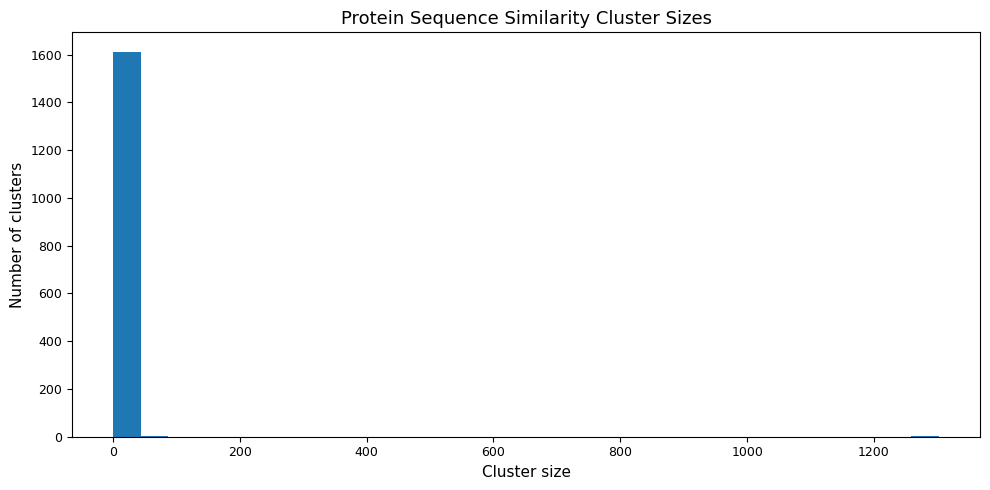

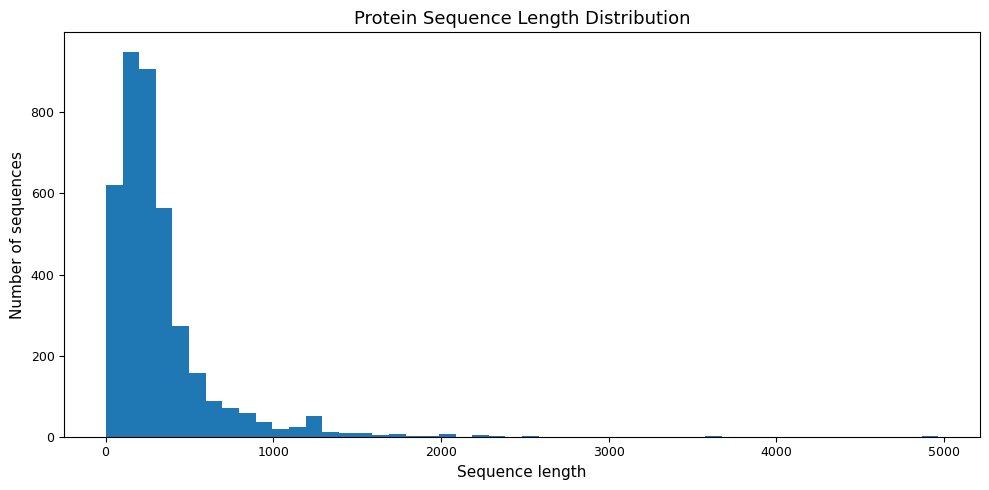

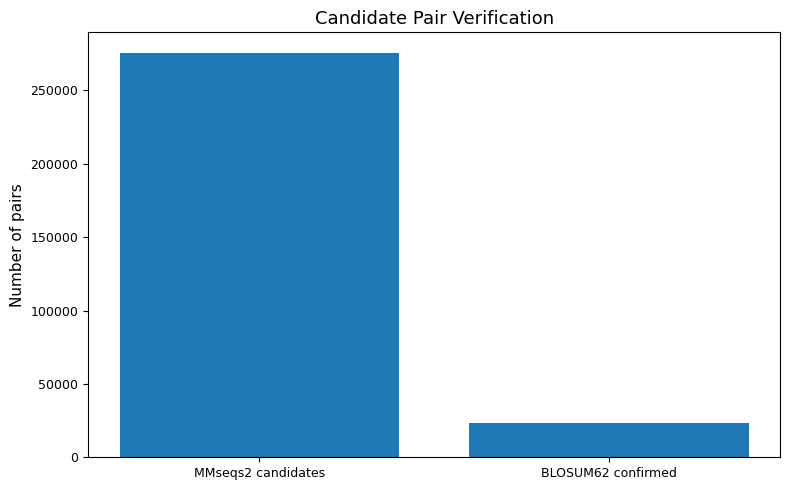


FINAL VALIDATION
PASS: Input records retained
PASS: Every sequence assigned to cluster
PASS: Every cluster has one representative
PASS: Representative count equals cluster count
PASS: No self-edges
PASS: Confirmed pairs satisfy thresholds

FINAL SUMMARY
Unique sequences: 3879
MMseqs2 candidates: 275835
BLOSUM62 confirmed pairs: 23355
Review pairs: 252202
Failed alignments: 278
Total clusters: 1615
Multi-member clusters: 346
Singleton clusters: 1269
Representatives: 1615
MMseqs2 runtime: 0.57 min
BLOSUM62 runtime: 45.68 min

OUTPUT DIRECTORY:
C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates

CELL 9 V3 COMPLETED.


In [17]:
# ============================================================
# CELL 9 V3. MMSEQS2 + BLOSUM62 HOMOLOGY CLUSTERING
# ============================================================
#
# Назначение:
# 1. Загрузка уникальных белковых последовательностей.
# 2. Проверка и нормализация последовательностей.
# 3. Подготовка FASTA.
# 4. Поиск потенциально похожих последовательностей MMseqs2.
# 5. Проверка найденных пар локальным выравниванием BLOSUM62.
# 6. Построение графа подтвержденного сходства.
# 7. Формирование кластеров связных компонент.
# 8. Выбор одного представителя каждого кластера.
# 9. Сохранение результатов и отчета.
#
# ВАЖНО:
# MMseqs2 выполняет предварительный эвристический поиск.
# BLOSUM62 проверяет только найденные MMseqs2 пары.
# Поэтому процедура не является полным перебором всех пар.
#
# ============================================================


# ============================================================
# 9.1. IMPORTS
# ============================================================

import os
import sys
import json
import time
import shutil
import hashlib
import subprocess
import platform

from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import networkx as nx

from tqdm.auto import tqdm

from Bio.Align import PairwiseAligner
from Bio.Align import substitution_matrices


# ============================================================
# 9.2. CONFIGURATION
# ============================================================

PROJECT_ROOT = Path(
    r"C:\apex\APEX\МИФИ\СНО\medic"
)

DATA_DIR = (
    PROJECT_ROOT
    / "Protein_Pocket_Dataset"
    / "01_candidates"
)

INPUT_FILE = (
    DATA_DIR
    / "protein_functional_classification.csv"
)


# ------------------------------------------------------------
# Output files
# ------------------------------------------------------------

OUTPUT_FASTA = (
    DATA_DIR
    / "protein_homology_sequences.fasta"
)

OUTPUT_CLUSTERS = (
    DATA_DIR
    / "protein_homology_clusters.csv"
)

OUTPUT_CLUSTER_SUMMARY = (
    DATA_DIR
    / "protein_homology_cluster_summary.csv"
)

OUTPUT_PAIRWISE_HITS = (
    DATA_DIR
    / "protein_homology_pairwise_hits.csv"
)

OUTPUT_REVIEW = (
    DATA_DIR
    / "protein_homology_review.csv"
)

OUTPUT_EDGES = (
    DATA_DIR
    / "protein_homology_edges.csv"
)

OUTPUT_REPRESENTATIVES = (
    DATA_DIR
    / "protein_homology_representatives.csv"
)

OUTPUT_JSON = (
    DATA_DIR
    / "protein_homology_clustering_summary.json"
)


# ------------------------------------------------------------
# MMseqs2 configuration
# ------------------------------------------------------------

MMSEQS_THREADS = 11

MMSEQS_SENSITIVITY = 7.5

MMSEQS_EVALUE = 1000

MMSEQS_MAX_SEQS = 30000


# ------------------------------------------------------------
# BLOSUM62 configuration
# ------------------------------------------------------------

GAP_OPEN = -10

GAP_EXTENSION = -0.5


# ------------------------------------------------------------
# Homology thresholds
# ------------------------------------------------------------

MIN_IDENTITY = 0.30

MIN_SHORTER_COVERAGE = 0.80

MIN_LONGER_COVERAGE = 0.50

MIN_ALIGNMENT_LENGTH = 50

MIN_SEQUENCE_LENGTH = 50


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)


# ============================================================
# 9.3. INITIALIZATION
# ============================================================

print("=" * 75)
print("CELL 9 V3. MMSEQS2 + BLOSUM62 HOMOLOGY CLUSTERING")
print("=" * 75)

print("\nPROJECT CONFIGURATION")
print("-" * 75)

print("Project root:", PROJECT_ROOT)
print("Input file:", INPUT_FILE)
print("Data directory:", DATA_DIR)

print("MMseqs2 threads:", MMSEQS_THREADS)
print("MMseqs2 sensitivity:", MMSEQS_SENSITIVITY)

print("BLOSUM62 gap open:", GAP_OPEN)
print("BLOSUM62 gap extension:", GAP_EXTENSION)

print("Minimum identity:", MIN_IDENTITY)
print("Minimum shorter coverage:", MIN_SHORTER_COVERAGE)
print("Minimum longer coverage:", MIN_LONGER_COVERAGE)
print("Minimum alignment length:", MIN_ALIGNMENT_LENGTH)

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Data directory does not exist: {DATA_DIR}"
    )

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Input file does not exist: {INPUT_FILE}"
    )


# ============================================================
# 9.4. LOAD INPUT DATA
# ============================================================

print("\n" + "=" * 75)
print("9.4. LOADING INPUT DATA")
print("=" * 75)

df_input = pd.read_csv(INPUT_FILE)

print("Input records:", len(df_input))

print("Input columns:")
print(df_input.columns.tolist())


# ------------------------------------------------------------
# Detect sequence column
# ------------------------------------------------------------

sequence_candidates = [
    "sequence_normalized",
    "sequence",
    "protein_sequence",
    "amino_acid_sequence"
]

sequence_col = next(
    (
        col
        for col in sequence_candidates
        if col in df_input.columns
    ),
    None
)

if sequence_col is None:

    raise KeyError(
        "Sequence column not found. "
        f"Available columns: {df_input.columns.tolist()}"
    )


# ------------------------------------------------------------
# Detect protein ID column
# ------------------------------------------------------------

protein_id_candidates = [
    "unique_protein_id",
    "protein_id",
    "entity_id"
]

protein_id_col = next(
    (
        col
        for col in protein_id_candidates
        if col in df_input.columns
    ),
    None
)

if protein_id_col is None:

    raise KeyError(
        "Protein ID column not found."
    )


print("\nSelected sequence column:", sequence_col)
print("Selected protein ID column:", protein_id_col)


# ============================================================
# 9.5. SEQUENCE NORMALIZATION
# ============================================================

print("\n" + "=" * 75)
print("9.5. SEQUENCE NORMALIZATION")
print("=" * 75)


# Standard amino acids plus ambiguous residues.
VALID_AA = set(
    "ACDEFGHIKLMNPQRSTVWYBXZ"
)


def normalize_protein_sequence(sequence):

    if pd.isna(sequence):
        return None

    sequence = str(sequence)

    sequence = sequence.upper()

    sequence = "".join(
        sequence.split()
    )

    sequence = sequence.replace("*", "")

    if len(sequence) == 0:
        return None

    # Convert uncommon or unsupported symbols to X.
    sequence = "".join(
        aa if aa in VALID_AA else "X"
        for aa in sequence
    )

    return sequence


df_input["_sequence"] = (
    df_input[sequence_col]
    .apply(normalize_protein_sequence)
)

df_input = df_input.loc[
    df_input["_sequence"].notna()
].copy()

df_input["_sequence_length"] = (
    df_input["_sequence"].str.len()
)

print("Valid sequence records:", len(df_input))


# ============================================================
# 9.6. EXACT SEQUENCE DEDUPLICATION
# ============================================================

print("\n" + "=" * 75)
print("9.6. EXACT SEQUENCE DEDUPLICATION")
print("=" * 75)


df_input["_sequence_hash"] = (
    df_input["_sequence"]
    .apply(
        lambda x: hashlib.sha256(
            x.encode("utf-8")
        ).hexdigest()
    )
)


# ------------------------------------------------------------
# Prefer records with better QC and classification metadata
# ------------------------------------------------------------

priority_columns = [
    col
    for col in [
        "selection_priority",
        "classification_confidence"
    ]
    if col in df_input.columns
]


if "qc_status" in df_input.columns:

    df_input["_qc_rank"] = (
        df_input["qc_status"]
        .astype(str)
        .str.upper()
        .map({
            "PASS": 3,
            "WARNING": 2,
            "REVIEW": 1,
            "FAIL": 0
        })
        .fillna(0)
    )

else:

    df_input["_qc_rank"] = 0


if "classification_confidence" in df_input.columns:

    df_input["_classification_rank"] = (
        df_input["classification_confidence"]
        .astype(str)
        .str.upper()
        .map({
            "HIGH": 3,
            "MEDIUM": 2,
            "LOW": 1
        })
        .fillna(0)
    )

else:

    df_input["_classification_rank"] = 0


df_input = df_input.sort_values(
    by=[
        "_qc_rank",
        "_classification_rank",
        "_sequence_length"
    ],
    ascending=[
        False,
        False,
        False
    ]
)


df_sequences = (
    df_input
    .drop_duplicates(
        subset="_sequence_hash",
        keep="first"
    )
    .copy()
    .reset_index(drop=True)
)


df_sequences["_seq_id"] = [
    f"SEQ_{i:06d}"
    for i in range(len(df_sequences))
]


print("Unique sequences:", len(df_sequences))

print("\nSequence length statistics:")

print(
    df_sequences["_sequence_length"]
    .describe()
)


# ============================================================
# 9.7. SEQUENCE ELIGIBILITY
# ============================================================

print("\n" + "=" * 75)
print("9.7. SEQUENCE ELIGIBILITY")
print("=" * 75)


df_sequences["_homology_eligible"] = (
    df_sequences["_sequence_length"]
    >= MIN_SEQUENCE_LENGTH
)


df_eligible = (
    df_sequences.loc[
        df_sequences["_homology_eligible"]
    ]
    .copy()
    .reset_index(drop=True)
)


df_short = (
    df_sequences.loc[
        ~df_sequences["_homology_eligible"]
    ]
    .copy()
    .reset_index(drop=True)
)


print("Total unique sequences:", len(df_sequences))

print("Eligible sequences:", len(df_eligible))

print("Short sequences:", len(df_short))

print(
    "Short sequence threshold:",
    MIN_SEQUENCE_LENGTH
)


# ============================================================
# 9.8. FASTA GENERATION
# ============================================================

print("\n" + "=" * 75)
print("9.8. FASTA GENERATION")
print("=" * 75)


with open(
    OUTPUT_FASTA,
    "w",
    encoding="utf-8"
) as fasta_file:

    for _, row in df_sequences.iterrows():

        fasta_file.write(
            f">{row['_seq_id']}\n"
        )

        fasta_file.write(
            f"{row['_sequence']}\n"
        )


# Validate FASTA

fasta_records = 0

with open(
    OUTPUT_FASTA,
    "r",
    encoding="utf-8"
) as fasta_file:

    for line in fasta_file:

        if line.startswith(">"):

            fasta_records += 1


print("FASTA records:", fasta_records)

if fasta_records != len(df_sequences):

    raise RuntimeError(
        "FASTA validation failed."
    )

print("FASTA validation: PASS")


# ============================================================
# 9.9. MMSEQS2 EXECUTABLE DETECTION
# ============================================================

print("\n" + "=" * 75)
print("9.9. MMSEQS2 EXECUTABLE DETECTION")
print("=" * 75)


MMSEQS_LOCAL = shutil.which("mmseqs")

WSL_EXECUTABLE = shutil.which("wsl.exe")


if MMSEQS_LOCAL:

    MMSEQS_MODE = "local"

    print("MMseqs2 executable:", MMSEQS_LOCAL)

elif WSL_EXECUTABLE:

    MMSEQS_MODE = "wsl"

    print("WSL executable:", WSL_EXECUTABLE)

else:

    raise RuntimeError(
        "MMseqs2 was not found. "
        "Install MMseqs2 locally or in WSL."
    )


# ------------------------------------------------------------
# Convert Windows path to WSL path
# ------------------------------------------------------------

def windows_to_wsl_path(path):

    result = subprocess.run(
        [
            WSL_EXECUTABLE,
            "wslpath",
            "-a",
            str(path)
        ],
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
        check=True
    )

    return result.stdout.strip()


# ============================================================
# 9.10. MMSEQS2 SEARCH
# ============================================================

print("\n" + "=" * 75)
print("9.10. MMSEQS2 CANDIDATE SEARCH")
print("=" * 75)


MMSEQS_OUTPUT = (
    DATA_DIR
    / "protein_homology_mmseqs_candidates.tsv"
)

MMSEQS_TEMP = (
    DATA_DIR
    / "mmseqs_tmp"
)

MMSEQS_TEMP.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Prepare FASTA containing eligible sequences only
# ------------------------------------------------------------

ELIGIBLE_FASTA = (
    DATA_DIR
    / "protein_homology_eligible.fasta"
)


with open(
    ELIGIBLE_FASTA,
    "w",
    encoding="utf-8"
) as fasta_file:

    for _, row in df_eligible.iterrows():

        fasta_file.write(
            f">{row['_seq_id']}\n"
        )

        fasta_file.write(
            f"{row['_sequence']}\n"
        )


print(
    "Eligible FASTA records:",
    len(df_eligible)
)


# ------------------------------------------------------------
# Build MMseqs2 command
# ------------------------------------------------------------

if MMSEQS_MODE == "local":

    mmseqs_command = [
        MMSEQS_LOCAL,
        "easy-search",
        str(ELIGIBLE_FASTA),
        str(ELIGIBLE_FASTA),
        str(MMSEQS_OUTPUT),
        str(MMSEQS_TEMP),
        "--format-output",
        "query,target",
        "-s",
        str(MMSEQS_SENSITIVITY),
        "-e",
        str(MMSEQS_EVALUE),
        "--max-seqs",
        str(MMSEQS_MAX_SEQS),
        "--threads",
        str(MMSEQS_THREADS)
    ]

else:

    fasta_wsl = windows_to_wsl_path(
        ELIGIBLE_FASTA
    )

    output_wsl = windows_to_wsl_path(
        MMSEQS_OUTPUT
    )

    temp_wsl = windows_to_wsl_path(
        MMSEQS_TEMP
    )

    command_text = (
        "mmseqs easy-search "
        f"'{fasta_wsl}' "
        f"'{fasta_wsl}' "
        f"'{output_wsl}' "
        f"'{temp_wsl}' "
        "--format-output query,target "
        f"-s {MMSEQS_SENSITIVITY} "
        f"-e {MMSEQS_EVALUE} "
        f"--max-seqs {MMSEQS_MAX_SEQS} "
        f"--threads {MMSEQS_THREADS}"
    )

    mmseqs_command = [
        WSL_EXECUTABLE,
        "bash",
        "-lc",
        command_text
    ]


print("\nMMseqs2 command prepared.")

print("Mode:", MMSEQS_MODE)

print("Threads:", MMSEQS_THREADS)


# ------------------------------------------------------------
# Execute MMseqs2
# ------------------------------------------------------------

mmseqs_start = time.time()


mmseqs_process = subprocess.run(
    mmseqs_command,
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace",
    timeout=None
)


mmseqs_runtime = (
    time.time() - mmseqs_start
)


print(
    "\nMMseqs2 runtime:",
    round(mmseqs_runtime / 60, 2),
    "minutes"
)


if mmseqs_process.returncode != 0:

    print("\nMMseqs2 STDERR:")

    print(
        mmseqs_process.stderr[-5000:]
    )

    raise RuntimeError(
        "MMseqs2 execution failed."
    )


print("MMseqs2 completed successfully.")


# ============================================================
# 9.11. LOAD MMSEQS2 CANDIDATE PAIRS
# ============================================================

print("\n" + "=" * 75)
print("9.11. LOADING MMSEQS2 CANDIDATES")
print("=" * 75)


if not MMSEQS_OUTPUT.exists():

    raise FileNotFoundError(
        "MMseqs2 output file was not created."
    )


df_candidates = pd.read_csv(
    MMSEQS_OUTPUT,
    sep="\t",
    header=None,
    names=[
        "seq_id_a",
        "seq_id_b"
    ],
    dtype=str
)


print(
    "Raw candidate pairs:",
    len(df_candidates)
)


# Remove self matches

df_candidates = df_candidates.loc[
    df_candidates["seq_id_a"]
    !=
    df_candidates["seq_id_b"]
].copy()


# Canonical undirected pair representation

df_candidates["pair_a"] = df_candidates[
    ["seq_id_a", "seq_id_b"]
].min(axis=1)


df_candidates["pair_b"] = df_candidates[
    ["seq_id_a", "seq_id_b"]
].max(axis=1)


df_candidates = (
    df_candidates
    .drop_duplicates(
        subset=[
            "pair_a",
            "pair_b"
        ]
    )
    .reset_index(drop=True)
)


print(
    "Unique candidate pairs:",
    len(df_candidates)
)


all_possible_pairs = (
    len(df_eligible)
    *
    (len(df_eligible) - 1)
    // 2
)


candidate_fraction = (
    len(df_candidates)
    /
    all_possible_pairs
    if all_possible_pairs > 0
    else 0
)


print(
    "All possible eligible pairs:",
    f"{all_possible_pairs:,}"
)

print(
    "Candidate fraction:",
    f"{candidate_fraction:.4%}"
)


# ============================================================
# 9.12. PREPARE BLOSUM62 ALIGNER
# ============================================================

print("\n" + "=" * 75)
print("9.12. BLOSUM62 ALIGNER INITIALIZATION")
print("=" * 75)


blosum_matrix = (
    substitution_matrices.load("BLOSUM62")
)


aligner = PairwiseAligner()

aligner.mode = "local"

aligner.substitution_matrix = (
    blosum_matrix
)

aligner.open_gap_score = GAP_OPEN

aligner.extend_gap_score = GAP_EXTENSION


print("Alignment mode:", aligner.mode)

print("Substitution matrix: BLOSUM62")

print("Gap open:", GAP_OPEN)

print("Gap extension:", GAP_EXTENSION)


# ------------------------------------------------------------
# Sequence lookup
# ------------------------------------------------------------

sequence_lookup = dict(
    zip(
        df_sequences["_seq_id"],
        df_sequences["_sequence"]
    )
)


# ============================================================
# 9.13. BLOSUM62 ALIGNMENT FUNCTION
# ============================================================

def calculate_alignment_metrics(
    sequence_a,
    sequence_b,
    aligner
):

    alignment = aligner.align(
        sequence_a,
        sequence_b
    )[0]

    coordinates = alignment.coordinates

    identical_positions = 0

    aligned_residues_a = 0

    aligned_residues_b = 0

    alignment_length = 0


    for i in range(len(coordinates[0]) - 1):

        a_start = int(coordinates[0][i])

        a_end = int(coordinates[0][i + 1])

        b_start = int(coordinates[1][i])

        b_end = int(coordinates[1][i + 1])


        delta_a = a_end - a_start

        delta_b = b_end - b_start


        alignment_length += max(
            delta_a,
            delta_b
        )


        if delta_a > 0 and delta_b > 0:

            aligned_residues_a += delta_a

            aligned_residues_b += delta_b


            if delta_a == delta_b:

                fragment_a = sequence_a[
                    a_start:a_end
                ]

                fragment_b = sequence_b[
                    b_start:b_end
                ]

                identical_positions += sum(
                    aa == bb
                    for aa, bb in zip(
                        fragment_a,
                        fragment_b
                    )
                )


    if alignment_length == 0:

        return None


    identity = (
        identical_positions
        /
        alignment_length
    )


    coverage_a = (
        aligned_residues_a
        /
        len(sequence_a)
    )


    coverage_b = (
        aligned_residues_b
        /
        len(sequence_b)
    )


    shorter_coverage = min(
        coverage_a,
        coverage_b
    )


    longer_coverage = max(
        coverage_a,
        coverage_b
    )


    return {
        "identity": identity,
        "alignment_length": alignment_length,
        "coverage_a": coverage_a,
        "coverage_b": coverage_b,
        "shorter_coverage": shorter_coverage,
        "longer_coverage": longer_coverage,
        "score": float(alignment.score)
    }


# ============================================================
# 9.14. BLOSUM62 PAIRWISE VALIDATION
# ============================================================

print("\n" + "=" * 75)
print("9.14. BLOSUM62 PAIRWISE VALIDATION")
print("=" * 75)


print(
    "Candidate pairs:",
    f"{len(df_candidates):,}"
)

print(
    "This step may take considerable time."
)


alignment_start = time.time()


alignment_results = []

failed_alignments = 0


for row in tqdm(
    df_candidates.itertuples(index=False),
    total=len(df_candidates),
    desc="BLOSUM62 alignment"
):

    seq_id_a = row.pair_a

    seq_id_b = row.pair_b


    sequence_a = sequence_lookup.get(
        seq_id_a
    )

    sequence_b = sequence_lookup.get(
        seq_id_b
    )


    if sequence_a is None or sequence_b is None:

        failed_alignments += 1

        continue


    try:

        metrics = calculate_alignment_metrics(
            sequence_a,
            sequence_b,
            aligner
        )

        if metrics is None:

            failed_alignments += 1

            continue


        passes_thresholds = (
            metrics["identity"] >= MIN_IDENTITY
            and
            metrics["shorter_coverage"]
            >= MIN_SHORTER_COVERAGE
            and
            metrics["longer_coverage"]
            >= MIN_LONGER_COVERAGE
            and
            metrics["alignment_length"]
            >= MIN_ALIGNMENT_LENGTH
        )


        alignment_results.append({

            "seq_id_a": seq_id_a,

            "seq_id_b": seq_id_b,

            "identity": metrics["identity"],

            "alignment_length": (
                metrics["alignment_length"]
            ),

            "coverage_a": metrics["coverage_a"],

            "coverage_b": metrics["coverage_b"],

            "shorter_coverage": (
                metrics["shorter_coverage"]
            ),

            "longer_coverage": (
                metrics["longer_coverage"]
            ),

            "score": metrics["score"],

            "passes_thresholds": (
                passes_thresholds
            )

        })


    except Exception:

        failed_alignments += 1

        continue


alignment_runtime = (
    time.time() - alignment_start
)


df_hits = pd.DataFrame(
    alignment_results
)


print("\nBLOSUM62 VALIDATION COMPLETED")
print("-" * 75)

print(
    "Processed pairs:",
    len(df_hits)
)

print(
    "Failed alignments:",
    failed_alignments
)

print(
    "Runtime:",
    round(alignment_runtime / 60, 2),
    "minutes"
)


# ============================================================
# 9.15. SPLIT CONFIRMED AND REVIEW PAIRS
# ============================================================

print("\n" + "=" * 75)
print("9.15. CONFIRMED PAIRS AND REVIEW PAIRS")
print("=" * 75)


if df_hits.empty:

    raise RuntimeError(
        "No successful BLOSUM62 alignments."
    )


df_confirmed = (
    df_hits.loc[
        df_hits["passes_thresholds"]
    ]
    .copy()
    .reset_index(drop=True)
)


df_review = (
    df_hits.loc[
        ~df_hits["passes_thresholds"]
    ]
    .copy()
    .reset_index(drop=True)
)


print(
    "Candidate pairs:",
    len(df_candidates)
)

print(
    "Confirmed pairs:",
    len(df_confirmed)
)

print(
    "Review pairs:",
    len(df_review)
)

print(
    "Failed alignments:",
    failed_alignments
)


# ============================================================
# 9.16. BUILD SIMILARITY GRAPH
# ============================================================

print("\n" + "=" * 75)
print("9.16. BUILDING SIMILARITY GRAPH")
print("=" * 75)


graph = nx.Graph()


# Add every sequence as a node.
# Short sequences will remain isolated nodes.

for seq_id in df_sequences["_seq_id"]:

    graph.add_node(seq_id)


# Add confirmed similarity edges.

for row in df_confirmed.itertuples(index=False):

    graph.add_edge(
        row.seq_id_a,
        row.seq_id_b,
        identity=float(row.identity),
        alignment_length=int(row.alignment_length),
        coverage_a=float(row.coverage_a),
        coverage_b=float(row.coverage_b),
        score=float(row.score)
    )


connected_components = list(
    nx.connected_components(graph)
)


print(
    "Graph nodes:",
    graph.number_of_nodes()
)

print(
    "Graph edges:",
    graph.number_of_edges()
)

print(
    "Connected components:",
    len(connected_components)
)


# ============================================================
# 9.17. SELECT REPRESENTATIVES
# ============================================================

print("\n" + "=" * 75)
print("9.17. REPRESENTATIVE SELECTION")
print("=" * 75)


df_sequences = df_sequences.copy()


df_sequences["_qc_rank"] = (
    df_sequences.get(
        "_qc_rank",
        pd.Series(
            0,
            index=df_sequences.index
        )
    )
)


df_sequences["_classification_rank"] = (
    df_sequences.get(
        "_classification_rank",
        pd.Series(
            0,
            index=df_sequences.index
        )
    )
)


# Preserve previous selection priority if available.

if "selection_priority" in df_sequences.columns:

    priority_map = {
        "HIGH": 3,
        "MEDIUM": 2,
        "LOW": 1
    }

    df_sequences["_selection_rank"] = (
        df_sequences["selection_priority"]
        .astype(str)
        .str.upper()
        .map(priority_map)
        .fillna(0)
    )

else:

    df_sequences["_selection_rank"] = 0


# Existing representatives are not available on first run.
# Therefore representative priority is determined by:
# QC status, classification confidence, selection priority,
# and sequence length.


sequence_priority = {}

for row in df_sequences.itertuples(index=False):

    sequence_priority[row._seq_id] = (
        int(row._qc_rank),
        int(row._classification_rank),
        int(row._selection_rank),
        int(row._sequence_length)
    )


sequence_to_cluster = {}

sequence_to_role = {}

cluster_members = defaultdict(list)


# ------------------------------------------------------------
# Process connected components
# ------------------------------------------------------------

for component in tqdm(
    connected_components,
    desc="Selecting representatives"
):

    component_members = sorted(
        component,
        key=lambda seq_id: (
            sequence_priority[seq_id],
            seq_id
        ),
        reverse=True
    )


    representative_id = (
        component_members[0]
    )


    cluster_number = (
        len(cluster_members) + 1
    )

    cluster_id = (
        f"HOM_{cluster_number:05d}"
    )


    for seq_id in component_members:

        sequence_to_cluster[seq_id] = (
            cluster_id
        )

        if seq_id == representative_id:

            sequence_to_role[seq_id] = (
                "representative"
            )

        else:

            sequence_to_role[seq_id] = (
                "member"
            )

        cluster_members[cluster_id].append(
            seq_id
        )


print(
    "Representatives selected:",
    len(cluster_members)
)


# ============================================================
# 9.18. CREATE HOMOLOGY CLUSTER TABLE
# ============================================================

print("\n" + "=" * 75)
print("9.18. CREATING HOMOLOGY CLUSTER TABLE")
print("=" * 75)


df_result = df_sequences.copy()


df_result["homology_cluster_id"] = (
    df_result["_seq_id"]
    .map(sequence_to_cluster)
)


df_result["homology_cluster_size"] = (
    df_result["homology_cluster_id"]
    .map({
        cluster_id: len(members)
        for cluster_id, members
        in cluster_members.items()
    })
)


df_result["homology_cluster_role"] = (
    df_result["_seq_id"]
    .map(sequence_to_role)
)


df_result["homology_cluster_representative"] = (
    df_result["homology_cluster_id"]
    .map({
        cluster_id: members[0]
        for cluster_id, members
        in cluster_members.items()
    })
)


# ============================================================
# 9.19. CREATE CLUSTER SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("9.19. CLUSTER SUMMARY")
print("=" * 75)


cluster_summary_records = []


for cluster_id, members in cluster_members.items():

    member_lengths = [
        int(
            sequence_lookup[seq_id].__len__()
        )
        for seq_id in members
    ]


    cluster_summary_records.append({

        "homology_cluster_id": cluster_id,

        "sequence_count": len(members),

        "mean_length": float(
            np.mean(member_lengths)
        ),

        "min_length": int(
            np.min(member_lengths)
        ),

        "max_length": int(
            np.max(member_lengths)
        ),

        "representative_count": 1

    })


df_cluster_summary = pd.DataFrame(
    cluster_summary_records
)


print(
    "Clusters:",
    len(df_cluster_summary)
)

print(
    "Multi-member clusters:",
    int(
        (
            df_cluster_summary["sequence_count"]
            > 1
        ).sum()
    )
)

print(
    "Singleton clusters:",
    int(
        (
            df_cluster_summary["sequence_count"]
            == 1
        ).sum()
    )
)


# ============================================================
# 9.20. CREATE REPRESENTATIVE TABLE
# ============================================================

print("\n" + "=" * 75)
print("9.20. REPRESENTATIVE TABLE")
print("=" * 75)


df_representatives = (
    df_result.loc[
        df_result["homology_cluster_role"]
        == "representative"
    ]
    .copy()
    .reset_index(drop=True)
)


print(
    "Representative records:",
    len(df_representatives)
)


# ============================================================
# 9.21. SAVE PAIRWISE RESULTS
# ============================================================

print("\n" + "=" * 75)
print("9.21. SAVING PAIRWISE RESULTS")
print("=" * 75)


# Confirmed pairs

df_confirmed.to_csv(
    OUTPUT_PAIRWISE_HITS,
    index=False
)


# Review pairs

df_review.to_csv(
    OUTPUT_REVIEW,
    index=False
)


# Edges are confirmed pairs only.

df_confirmed.to_csv(
    OUTPUT_EDGES,
    index=False
)


# ============================================================
# 9.22. SAVE CLUSTER RESULTS
# ============================================================

print("\n" + "=" * 75)
print("9.22. SAVING CLUSTER RESULTS")
print("=" * 75)


df_result.to_csv(
    OUTPUT_CLUSTERS,
    index=False
)


df_cluster_summary.to_csv(
    OUTPUT_CLUSTER_SUMMARY,
    index=False
)


df_representatives.to_csv(
    OUTPUT_REPRESENTATIVES,
    index=False
)


print("Saved:")
print(OUTPUT_CLUSTERS)
print(OUTPUT_CLUSTER_SUMMARY)
print(OUTPUT_PAIRWISE_HITS)
print(OUTPUT_REVIEW)
print(OUTPUT_EDGES)
print(OUTPUT_REPRESENTATIVES)


# ============================================================
# 9.23. BUILD SUMMARY STATISTICS
# ============================================================

print("\n" + "=" * 75)
print("9.23. SUMMARY STATISTICS")
print("=" * 75)


multi_member_clusters = int(
    (
        df_cluster_summary["sequence_count"]
        > 1
    ).sum()
)


singleton_clusters = int(
    (
        df_cluster_summary["sequence_count"]
        == 1
    ).sum()
)


sequences_in_multi_member_clusters = int(
    df_cluster_summary.loc[
        df_cluster_summary["sequence_count"] > 1,
        "sequence_count"
    ].sum()
)


summary = {

    "pipeline": (
        "MMseqs2 candidate search + BLOSUM62 "
        "local alignment + connected components"
    ),

    "total_input_records": int(
        len(df_input)
    ),

    "total_unique_sequences": int(
        len(df_sequences)
    ),

    "eligible_sequences": int(
        len(df_eligible)
    ),

    "short_sequences": int(
        len(df_short)
    ),

    "all_possible_pairs": int(
        all_possible_pairs
    ),

    "mmseqs_candidate_pairs": int(
        len(df_candidates)
    ),

    "candidate_fraction": float(
        candidate_fraction
    ),

    "confirmed_pairs": int(
        len(df_confirmed)
    ),

    "review_pairs": int(
        len(df_review)
    ),

    "failed_alignments": int(
        failed_alignments
    ),

    "connected_components": int(
        len(connected_components)
    ),

    "multi_member_clusters": (
        multi_member_clusters
    ),

    "singleton_clusters": (
        singleton_clusters
    ),

    "sequences_in_multi_member_clusters": (
        sequences_in_multi_member_clusters
    ),

    "representatives": int(
        len(df_representatives)
    ),

    "thresholds": {

        "identity": MIN_IDENTITY,

        "shorter_coverage": (
            MIN_SHORTER_COVERAGE
        ),

        "longer_coverage": (
            MIN_LONGER_COVERAGE
        ),

        "alignment_length": (
            MIN_ALIGNMENT_LENGTH
        )

    },

    "mmseqs2": {

        "threads": MMSEQS_THREADS,

        "sensitivity": MMSEQS_SENSITIVITY,

        "evalue": MMSEQS_EVALUE,

        "max_seqs": MMSEQS_MAX_SEQS,

        "runtime_seconds": float(
            mmseqs_runtime
        )

    },

    "blosum62": {

        "matrix": "BLOSUM62",

        "gap_open": GAP_OPEN,

        "gap_extension": GAP_EXTENSION,

        "runtime_seconds": float(
            alignment_runtime
        )

    },

    "limitations": [

        "MMseqs2 candidate search is heuristic.",

        "BLOSUM62 verifies only candidate pairs returned by MMseqs2.",

        "Connected components allow transitive cluster membership.",

        "Similarity does not prove structural or functional equivalence."

    ]

}


with open(
    OUTPUT_JSON,
    "w",
    encoding="utf-8"
) as json_file:

    json.dump(
        summary,
        json_file,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 9.24. FINAL VALIDATION
# ============================================================

print("\n" + "=" * 75)
print("9.24. FINAL VALIDATION")
print("=" * 75)


# ------------------------------------------------------------
# Validation 1: all input sequences retained
# ------------------------------------------------------------

assert (
    len(df_result)
    ==
    len(df_sequences)
), "Input sequence count mismatch."


print("PASS: input sequences retained")


# ------------------------------------------------------------
# Validation 2: every sequence assigned to cluster
# ------------------------------------------------------------

assert (
    df_result["homology_cluster_id"]
    .notna()
    .all()
), "Some sequences have no cluster ID."


print("PASS: every sequence assigned to cluster")


# ------------------------------------------------------------
# Validation 3: one representative per cluster
# ------------------------------------------------------------

representative_counts = (
    df_result.loc[
        df_result["homology_cluster_role"]
        == "representative"
    ]
    .groupby("homology_cluster_id")
    .size()
)


assert (
    representative_counts.eq(1).all()
), "Some clusters do not have exactly one representative."


print("PASS: every cluster has one representative")


# ------------------------------------------------------------
# Validation 4: representative count equals cluster count
# ------------------------------------------------------------

assert (
    len(df_representatives)
    ==
    len(df_cluster_summary)
), "Representative count mismatch."


print("PASS: representative count equals cluster count")


# ------------------------------------------------------------
# Validation 5: no self-edges
# ------------------------------------------------------------

if not df_confirmed.empty:

    assert (
        df_confirmed["seq_id_a"]
        !=
        df_confirmed["seq_id_b"]
    ).all()


print("PASS: no self-edges")


# ------------------------------------------------------------
# Validation 6: confirmed pairs satisfy thresholds
# ------------------------------------------------------------

if not df_confirmed.empty:

    assert (
        df_confirmed["identity"]
        >= MIN_IDENTITY
    ).all()

    assert (
        df_confirmed["shorter_coverage"]
        >= MIN_SHORTER_COVERAGE
    ).all()

    assert (
        df_confirmed["longer_coverage"]
        >= MIN_LONGER_COVERAGE
    ).all()

    assert (
        df_confirmed["alignment_length"]
        >= MIN_ALIGNMENT_LENGTH
    ).all()


print("PASS: confirmed pairs satisfy thresholds")


# ------------------------------------------------------------
# Validation 7: cluster sizes
# ------------------------------------------------------------

cluster_size_check = (
    df_result
    .groupby("homology_cluster_id")
    .size()
    .sort_index()
)


summary_size_check = (
    df_cluster_summary
    .set_index("homology_cluster_id")[
        "sequence_count"
    ]
    .sort_index()
)


assert (
    cluster_size_check.equals(
        summary_size_check
    )
), "Cluster size validation failed."


print("PASS: cluster sizes match summary")


# ------------------------------------------------------------
# Validation 8: representative file
# ------------------------------------------------------------

assert (
    df_representatives["homology_cluster_id"]
    .is_unique
), "Duplicate representative cluster IDs."


print("PASS: representative file is consistent")


# ============================================================
# 9.25. FINAL REPORT
# ============================================================

print("\n" + "=" * 75)
print("CELL 9 V3 COMPLETED")
print("=" * 75)


print("\nFINAL RESULTS")
print("-" * 75)

print(
    "Unique sequences:",
    f"{len(df_sequences):,}"
)

print(
    "Eligible sequences:",
    f"{len(df_eligible):,}"
)

print(
    "Short sequences:",
    f"{len(df_short):,}"
)

print(
    "MMseqs2 candidate pairs:",
    f"{len(df_candidates):,}"
)

print(
    "BLOSUM62 confirmed pairs:",
    f"{len(df_confirmed):,}"
)

print(
    "Review pairs:",
    f"{len(df_review):,}"
)

print(
    "Failed alignments:",
    f"{failed_alignments:,}"
)

print(
    "Total clusters:",
    f"{len(df_cluster_summary):,}"
)

print(
    "Multi-member clusters:",
    f"{multi_member_clusters:,}"
)

print(
    "Singleton clusters:",
    f"{singleton_clusters:,}"
)

print(
    "Representatives:",
    f"{len(df_representatives):,}"
)


print("\nRUNTIME")
print("-" * 75)

print(
    "MMseqs2:",
    round(mmseqs_runtime / 60, 2),
    "minutes"
)

print(
    "BLOSUM62:",
    round(alignment_runtime / 60, 2),
    "minutes"
)


print("\nOUTPUT FILES")
print("-" * 75)

for output_file in [

    OUTPUT_FASTA,

    OUTPUT_CLUSTERS,

    OUTPUT_CLUSTER_SUMMARY,

    OUTPUT_PAIRWISE_HITS,

    OUTPUT_REVIEW,

    OUTPUT_EDGES,

    OUTPUT_REPRESENTATIVES,

    OUTPUT_JSON

]:

    print(
        output_file.name,
        "|",
        output_file.exists()
    )


print("\nALL FINAL VALIDATIONS PASSED.")

print("=" * 75)

In [24]:

# ============================================================
# CELL 9A. CORRECTED HOMOLOGY CLUSTERING AND VALIDATION
# ============================================================
# Назначение:
# Повторная кластеризация белковых последовательностей
# на основании уже рассчитанных BLOSUM62 alignments.
#
# Основные условия:
# 1. Identity >= 30%.
# 2. Coverage обеих последовательностей >= 80%.
# 3. Alignment length >= 50 aa.
# 4. Каждый участник кластера имеет прямое соответствие
#    выбранному представителю.
# 5. Короткие последовательности сохраняются отдельно
#    со статусом NOT_ASSESSED.
# 6. Все 3879 исходных последовательностей сохраняются.
# 7. Результаты CELL 9 V3 сохраняются для аудита.
#
# ВАЖНО:
# - BLOSUM62 alignment повторно не рассчитывается.
# - Используются готовые результаты CELL 9 V3.
# - Исходные V3-файлы не перезаписываются в резервных копиях.
# ============================================================

import json
import shutil
import time

from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd


# ============================================================
# 9A.1. CONFIGURATION
# ============================================================

START_TIME = time.time()

BASE = Path(CANDIDATES_DIR)
BASE.mkdir(parents=True, exist_ok=True)

INPUT_CLUSTERS = BASE / "protein_homology_clusters.csv"
INPUT_HITS = BASE / "protein_homology_pairwise_hits.csv"
INPUT_JSON = BASE / "protein_homology_clustering_summary.json"

# Strict homology thresholds
IDENTITY_THRESHOLD = 0.30
COVERAGE_A_THRESHOLD = 0.80
COVERAGE_B_THRESHOLD = 0.80
MIN_ALIGNMENT_LENGTH = 50

# Minimum sequence length for homology assessment
MIN_SEQUENCE_LENGTH = 50

# Output files
OUTPUT_CLUSTERS = BASE / "protein_homology_clusters.csv"
OUTPUT_REPRESENTATIVES = BASE / "protein_homology_representatives.csv"
OUTPUT_SUMMARY = BASE / "protein_homology_cluster_summary.csv"

OUTPUT_STRICT_HITS = BASE / "protein_homology_pairwise_hits_9A.csv"
OUTPUT_STRICT_EDGES = BASE / "protein_homology_edges_9A.csv"
OUTPUT_REVIEW = BASE / "protein_homology_review_9A.csv"

OUTPUT_JSON = BASE / "protein_homology_clustering_summary_9A.json"

# Original V3 backup files
BACKUP_CLUSTERS = BASE / "protein_homology_clusters_v3_backup.csv"
BACKUP_REPRESENTATIVES = BASE / "protein_homology_representatives_v3_backup.csv"
BACKUP_SUMMARY = BASE / "protein_homology_cluster_summary_v3_backup.csv"


print("=" * 75)
print("CELL 9A. CORRECTED HOMOLOGY CLUSTERING")
print("=" * 75)

print("\nProject directory:")
print(BASE)

print("\nThresholds:")
print(f"Identity:             >= {IDENTITY_THRESHOLD:.0%}")
print(f"Coverage sequence A:  >= {COVERAGE_A_THRESHOLD:.0%}")
print(f"Coverage sequence B:  >= {COVERAGE_B_THRESHOLD:.0%}")
print(f"Alignment length:     >= {MIN_ALIGNMENT_LENGTH} aa")
print(f"Minimum sequence:     >= {MIN_SEQUENCE_LENGTH} aa")


# ============================================================
# 9A.2. INPUT VALIDATION
# ============================================================

required_files = [
    INPUT_CLUSTERS,
    INPUT_HITS,
    INPUT_JSON
]

missing_files = [
    str(path)
    for path in required_files
    if not path.exists()
]

if missing_files:

    raise FileNotFoundError(
        "Required CELL 9 V3 files are missing:\n"
        + "\n".join(missing_files)
    )


# ============================================================
# 9A.3. BACKUP ORIGINAL V3 RESULTS
# ============================================================

print("\n" + "=" * 75)
print("9A.3. BACKUP ORIGINAL V3 RESULTS")
print("=" * 75)

backup_pairs = [
    (OUTPUT_CLUSTERS, BACKUP_CLUSTERS),
    (
        BASE / "protein_homology_representatives.csv",
        BACKUP_REPRESENTATIVES
    ),
    (
        BASE / "protein_homology_cluster_summary.csv",
        BACKUP_SUMMARY
    )
]

for source, backup in backup_pairs:

    if source.exists() and not backup.exists():

        shutil.copy2(source, backup)

        print("Backup created:")
        print(" ", backup.name)

    elif backup.exists():

        print("Existing backup preserved:")
        print(" ", backup.name)

    else:

        print("Source not found, backup skipped:")
        print(" ", source.name)


# ============================================================
# 9A.4. LOAD ORIGINAL DATA
# ============================================================

print("\n" + "=" * 75)
print("9A.4. LOADING INPUT DATA")
print("=" * 75)

df_base = pd.read_csv(INPUT_CLUSTERS)

df_hits_raw = pd.read_csv(INPUT_HITS)

with open(INPUT_JSON, "r", encoding="utf-8") as f:

    v3_report = json.load(f)

print("Protein records:", len(df_base))
print("Pairwise hit records:", len(df_hits_raw))

print("\nCluster columns:", len(df_base.columns))
print("Hit columns:", len(df_hits_raw.columns))


# ============================================================
# 9A.5. REQUIRED COLUMN VALIDATION
# ============================================================

required_cluster_columns = [
    "unique_protein_id",
    "_seq_id",
    "_sequence",
    "_sequence_length",
    "homology_cluster_id",
    "homology_cluster_role"
]

required_hit_columns = [
    "seq_id_a",
    "seq_id_b",
    "identity",
    "alignment_length",
    "coverage_a",
    "coverage_b",
    "score"
]

missing_cluster_columns = [
    col for col in required_cluster_columns
    if col not in df_base.columns
]

missing_hit_columns = [
    col for col in required_hit_columns
    if col not in df_hits_raw.columns
]

if missing_cluster_columns:

    raise KeyError(
        "Missing columns in homology clusters:\n"
        + str(missing_cluster_columns)
    )

if missing_hit_columns:

    raise KeyError(
        "Missing columns in pairwise hits:\n"
        + str(missing_hit_columns)
    )


# ============================================================
# 9A.6. PRESERVE ORIGINAL V3 CLUSTER ASSIGNMENTS
# ============================================================

print("\n" + "=" * 75)
print("9A.6. PRESERVING V3 CLUSTER ASSIGNMENTS")
print("=" * 75)

if "homology_cluster_id_v3" not in df_base.columns:

    df_base["homology_cluster_id_v3"] = (
        df_base["homology_cluster_id"].astype(str)
    )

if "homology_cluster_role_v3" not in df_base.columns:

    df_base["homology_cluster_role_v3"] = (
        df_base["homology_cluster_role"].astype(str)
    )

print("Original V3 assignments preserved.")

print(
    "V3 connected components:",
    df_base["homology_cluster_id_v3"].nunique()
)


# ============================================================
# 9A.7. VALIDATE PROTEIN IDENTIFIERS
# ============================================================

print("\n" + "=" * 75)
print("9A.7. VALIDATING PROTEIN IDENTIFIERS")
print("=" * 75)

df_base["unique_protein_id"] = (
    df_base["unique_protein_id"]
    .astype(str)
    .str.strip()
)

df_base["_seq_id"] = (
    df_base["_seq_id"]
    .astype(str)
    .str.strip()
)

if df_base[
    ["unique_protein_id", "_seq_id"]
].isna().any().any():

    raise ValueError(
        "Missing protein or sequence identifiers detected."
    )

if (
    df_base["unique_protein_id"].eq("").any()
    or df_base["_seq_id"].eq("").any()
):

    raise ValueError(
        "Empty protein or sequence identifiers detected."
    )

if df_base["unique_protein_id"].duplicated().any():

    duplicates = df_base.loc[
        df_base["unique_protein_id"].duplicated(keep=False),
        "unique_protein_id"
    ].tolist()

    raise ValueError(
        "Duplicate unique_protein_id values detected:\n"
        + str(duplicates[:20])
    )

if df_base["_seq_id"].duplicated().any():

    duplicates = df_base.loc[
        df_base["_seq_id"].duplicated(keep=False),
        "_seq_id"
    ].tolist()

    raise ValueError(
        "Duplicate _seq_id values detected:\n"
        + str(duplicates[:20])
    )

print("Unique protein IDs:", df_base["unique_protein_id"].nunique())

print("Unique sequence IDs:", df_base["_seq_id"].nunique())


# ============================================================
# 9A.8. NORMALIZE PAIRWISE ALIGNMENT DATA
# ============================================================

print("\n" + "=" * 75)
print("9A.8. NORMALIZING PAIRWISE ALIGNMENTS")
print("=" * 75)

df_hits = df_hits_raw.copy()

numeric_columns = [
    "identity",
    "alignment_length",
    "coverage_a",
    "coverage_b",
    "score"
]

for col in numeric_columns:

    df_hits[col] = pd.to_numeric(
        df_hits[col],
        errors="coerce"
    )

df_hits["seq_id_a"] = (
    df_hits["seq_id_a"].astype("string").str.strip()
)

df_hits["seq_id_b"] = (
    df_hits["seq_id_b"].astype("string").str.strip()
)

df_hits = df_hits.dropna(
    subset=[
        "seq_id_a",
        "seq_id_b",
        "identity",
        "alignment_length",
        "coverage_a",
        "coverage_b",
        "score"
    ]
).copy()

df_hits = df_hits[
    df_hits["seq_id_a"].ne("")
    &
    df_hits["seq_id_b"].ne("")
].copy()

# ------------------------------------------------------------
# Keep only pairs referring to known sequences.
# ------------------------------------------------------------

known_seq_ids = set(df_base["_seq_id"])

unknown_pair_mask = (
    ~df_hits["seq_id_a"].isin(known_seq_ids)
    |
    ~df_hits["seq_id_b"].isin(known_seq_ids)
)

unknown_pair_count = int(unknown_pair_mask.sum())

if unknown_pair_count:

    print(
        "WARNING: alignment pairs with unknown sequence IDs:",
        unknown_pair_count
    )

    df_hits = df_hits.loc[
        ~unknown_pair_mask
    ].copy()

# ------------------------------------------------------------
# Undirected pair representation.
# IMPORTANT:
# Compare IDs as strings, not as numeric columns.
# ------------------------------------------------------------

swap_mask = (
    df_hits["seq_id_a"].astype(str)
    >
    df_hits["seq_id_b"].astype(str)
)

df_hits["pair_a"] = np.where(
    swap_mask,
    df_hits["seq_id_b"],
    df_hits["seq_id_a"]
)

df_hits["pair_b"] = np.where(
    swap_mask,
    df_hits["seq_id_a"],
    df_hits["seq_id_b"]
)

# Remove self-alignments
df_hits = df_hits[
    df_hits["pair_a"] != df_hits["pair_b"]
].copy()

# ------------------------------------------------------------
# Keep the strongest alignment for each undirected pair.
# ------------------------------------------------------------

df_hits = df_hits.sort_values(
    [
        "identity",
        "coverage_a",
        "coverage_b",
        "alignment_length",
        "score"
    ],
    ascending=False,
    kind="mergesort"
)

df_hits = df_hits.drop_duplicates(
    subset=["pair_a", "pair_b"],
    keep="first"
).reset_index(drop=True)

print("Unknown-ID pairs excluded:", unknown_pair_count)

print("Unique undirected alignment pairs:", len(df_hits))


# ============================================================
# 9A.9. STRICT PAIR FILTERING
# ============================================================

print("\n" + "=" * 75)
print("9A.9. STRICT PAIR FILTERING")
print("=" * 75)

strict_mask = (
    (df_hits["identity"] >= IDENTITY_THRESHOLD)
    &
    (df_hits["coverage_a"] >= COVERAGE_A_THRESHOLD)
    &
    (df_hits["coverage_b"] >= COVERAGE_B_THRESHOLD)
    &
    (df_hits["alignment_length"] >= MIN_ALIGNMENT_LENGTH)
)

df_strict_hits = df_hits.loc[
    strict_mask
].copy()

# ------------------------------------------------------------
# Optional legacy flag validation.
# ------------------------------------------------------------

if "passes_thresholds" in df_hits.columns:

    legacy_flags = (
        df_hits["passes_thresholds"]
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "yes"])
    )

    print(
        "V3 pairs passing original thresholds:",
        int(legacy_flags.sum())
    )

print("Pairs passing strict thresholds:", len(df_strict_hits))

print(
    "Pairs excluded by strict coverage/identity criteria:",
    len(df_hits) - len(df_strict_hits)
)

if len(df_strict_hits):

    print("\nStrict alignment statistics:")

    print(
        df_strict_hits[
            [
                "identity",
                "coverage_a",
                "coverage_b",
                "alignment_length"
            ]
        ].describe().round(3)
    )


# ============================================================
# 9A.10. CREATE UNDIRECTED SIMILARITY GRAPH
# ============================================================

print("\n" + "=" * 75)
print("9A.10. BUILDING STRICT SIMILARITY GRAPH")
print("=" * 75)

# Each edge represents a pair that satisfies all strict thresholds.

adjacency = defaultdict(dict)

for row in df_strict_hits.itertuples(index=False):

    seq_a = row.pair_a
    seq_b = row.pair_b

    edge_info = {

        "identity": float(row.identity),

        "coverage_min": float(
            min(row.coverage_a, row.coverage_b)
        ),

        "coverage_a": float(row.coverage_a),

        "coverage_b": float(row.coverage_b),

        "alignment_length": int(row.alignment_length),

        "score": float(row.score)

    }

    adjacency[seq_a][seq_b] = edge_info

    adjacency[seq_b][seq_a] = edge_info

print(
    "Sequences with at least one strict neighbor:",
    len(adjacency)
)

print("Strict similarity edges:", len(df_strict_hits))


# ============================================================
# 9A.11. DEFINE SEQUENCE ASSESSMENT STATUS
# ============================================================

print("\n" + "=" * 75)
print("9A.11. SEQUENCE ASSESSMENT")
print("=" * 75)

df_base["_sequence_length"] = pd.to_numeric(
    df_base["_sequence_length"],
    errors="coerce"
)

if df_base["_sequence_length"].isna().any():

    raise ValueError(
        "Missing or invalid sequence lengths detected."
    )

df_base["_sequence_length"] = (
    df_base["_sequence_length"].astype(int)
)

df_base["homology_assessment_status"] = np.where(
    df_base["_sequence_length"] >= MIN_SEQUENCE_LENGTH,
    "ASSESSED",
    "NOT_ASSESSED_SHORT_SEQUENCE"
)

assessed_mask = (
    df_base["_sequence_length"] >= MIN_SEQUENCE_LENGTH
)

df_assessed = df_base.loc[
    assessed_mask
].copy()

df_not_assessed = df_base.loc[
    ~assessed_mask
].copy()

print("Total sequences:", len(df_base))

print("Eligible for homology assessment:", len(df_assessed))

print("Short sequences not assessed:", len(df_not_assessed))


# ============================================================
# 9A.12. REPRESENTATIVE PRIORITY
# ============================================================

print("\n" + "=" * 75)
print("9A.12. REPRESENTATIVE PRIORITY")
print("=" * 75)

# Priority order:
# 1. Existing V3 representative.
# 2. QC PASS.
# 3. HIGH selection priority.
# 4. HIGH classification confidence.
# 5. Longer sequence.
#
# This changes representative selection only.
# It does not change similarity thresholds.

df_assessed["_v3_rep_priority"] = (
    df_assessed["homology_cluster_role_v3"]
    .astype(str)
    .str.lower()
    .eq("representative")
    .astype(int)
)

df_assessed["_qc_priority"] = (
    df_assessed.get(
        "qc_status",
        pd.Series("REVIEW", index=df_assessed.index)
    )
    .astype(str)
    .str.upper()
    .eq("PASS")
    .astype(int)
)

df_assessed["_selection_priority"] = (
    df_assessed.get(
        "selection_priority",
        pd.Series("LOW", index=df_assessed.index)
    )
    .astype(str)
    .str.upper()
    .map({
        "HIGH": 3,
        "MEDIUM": 2,
        "LOW": 1
    })
    .fillna(0)
)

df_assessed["_classification_priority"] = (
    df_assessed.get(
        "classification_confidence",
        pd.Series("LOW", index=df_assessed.index)
    )
    .astype(str)
    .str.lower()
    .map({
        "high": 3,
        "medium": 2,
        "low": 1
    })
    .fillna(0)
)

df_assessed = df_assessed.sort_values(
    [
        "_v3_rep_priority",
        "_qc_priority",
        "_selection_priority",
        "_classification_priority",
        "_sequence_length",
        "unique_protein_id"
    ],
    ascending=[
        False,
        False,
        False,
        False,
        False,
        True
    ],
    kind="mergesort"
).reset_index(drop=True)

print("Representative priority order established.")


# ============================================================
# 9A.13. GREEDY REPRESENTATIVE-BASED CLUSTERING
# ============================================================

print("\n" + "=" * 75)
print("9A.13. REPRESENTATIVE-BASED CLUSTERING")
print("=" * 75)

# Algorithm:
#
# 1. Find already selected representatives directly connected
#    to the current sequence.
# 2. If candidates exist, assign the sequence to the best match.
# 3. Otherwise, create a new representative.
#
# Every member therefore has a direct qualifying alignment
# with its assigned representative.
#
# This is not an all-vs-all clique clustering.
# Members of one cluster are not necessarily directly similar
# to each other.

sequence_to_cluster = {}

sequence_to_role = {}

sequence_to_representative = {}

sequence_to_match = {}

representative_seq_ids = []

cluster_members = defaultdict(list)

seq_id_to_protein_id = dict(
    zip(
        df_base["_seq_id"],
        df_base["unique_protein_id"]
    )
)

processed = 0

total_assessed = len(df_assessed)

# FIX:
# Use iterrows() because it preserves column names beginning
# with underscores, unlike itertuples().

for _, row in df_assessed.iterrows():

    seq_id = row["_seq_id"]

    protein_id = row["unique_protein_id"]

    candidate_representatives = []

    # Find already selected representatives directly connected
    # to the current sequence.

    for neighbor_id, edge_info in adjacency.get(
        seq_id,
        {}
    ).items():

        if neighbor_id in representative_seq_ids:

            candidate_representatives.append(
                (neighbor_id, edge_info)
            )

    if candidate_representatives:

        # Select the best direct match.
        # Priority:
        # identity -> minimum coverage -> score.

        candidate_representatives.sort(
            key=lambda item: (
                item[1]["identity"],
                item[1]["coverage_min"],
                item[1]["score"],
                item[0]
            ),
            reverse=True
        )

        representative_id, best_edge = (
            candidate_representatives[0]
        )

        cluster_id = sequence_to_cluster[
            representative_id
        ]

        sequence_to_cluster[seq_id] = cluster_id

        sequence_to_role[seq_id] = "member"

        sequence_to_representative[seq_id] = (
            representative_id
        )

        sequence_to_match[seq_id] = best_edge

        cluster_members[cluster_id].append(
            seq_id
        )

    else:

        # No existing representative has a qualifying direct edge.
        # The sequence becomes a new representative.

        cluster_number = (
            len(representative_seq_ids) + 1
        )

        cluster_id = f"HOMA_{cluster_number:05d}"

        representative_seq_ids.append(seq_id)

        sequence_to_cluster[seq_id] = cluster_id

        sequence_to_role[seq_id] = "representative"

        sequence_to_representative[seq_id] = seq_id

        sequence_to_match[seq_id] = None

        cluster_members[cluster_id].append(
            seq_id
        )

    processed += 1

    if (
        processed % 500 == 0
        or processed == total_assessed
    ):

        print(
            f"Processed: {processed:,}/{total_assessed:,} | "
            f"Representatives: {len(representative_seq_ids):,} | "
            f"Clusters: {len(cluster_members):,}"
        )


# ============================================================
# 9A.14. PRESERVE SHORT SEQUENCES AS SINGLETONS
# ============================================================

print("\n" + "=" * 75)
print("9A.14. SHORT SEQUENCES")
print("=" * 75)

short_cluster_count = 0

# FIX:
# Use iterrows() for _seq_id.

for _, row in df_not_assessed.iterrows():

    seq_id = row["_seq_id"]

    cluster_number = (
        len(representative_seq_ids)
        + short_cluster_count
        + 1
    )

    cluster_id = f"HOMA_{cluster_number:05d}"

    sequence_to_cluster[seq_id] = cluster_id

    sequence_to_role[seq_id] = "not_assessed"

    sequence_to_representative[seq_id] = None

    sequence_to_match[seq_id] = None

    cluster_members[cluster_id].append(seq_id)

    short_cluster_count += 1

print("Short sequences retained:", short_cluster_count)


# ============================================================
# 9A.15. ASSIGN FINAL CLUSTER METADATA
# ============================================================

print("\n" + "=" * 75)
print("9A.15. FINAL CLUSTER ASSIGNMENT")
print("=" * 75)

df_result = df_base.copy()

df_result["homology_cluster_id"] = (
    df_result["_seq_id"].map(sequence_to_cluster)
)

df_result["homology_cluster_role"] = (
    df_result["_seq_id"].map(sequence_to_role)
)

df_result["homology_representative_seq_id"] = (
    df_result["_seq_id"].map(sequence_to_representative)
)

# Direct match information for members.

df_result["homology_identity_to_representative"] = np.nan

df_result["homology_coverage_min_to_representative"] = np.nan

df_result["homology_alignment_length_to_representative"] = np.nan

for seq_id, match_info in sequence_to_match.items():

    if match_info is None:
        continue

    mask = df_result["_seq_id"].eq(seq_id)

    df_result.loc[
        mask,
        "homology_identity_to_representative"
    ] = match_info["identity"]

    df_result.loc[
        mask,
        "homology_coverage_min_to_representative"
    ] = match_info["coverage_min"]

    df_result.loc[
        mask,
        "homology_alignment_length_to_representative"
    ] = match_info["alignment_length"]


cluster_size_map = {
    cluster_id: len(members)
    for cluster_id, members in cluster_members.items()
}

df_result["homology_cluster_size"] = (
    df_result["homology_cluster_id"]
    .map(cluster_size_map)
    .astype(int)
)

print("Final protein records:", len(df_result))

print(
    "Final clusters:",
    df_result["homology_cluster_id"].nunique()
)

print("Representatives:", len(representative_seq_ids))


# ============================================================
# 9A.16. BUILD REPRESENTATIVE TABLE
# ============================================================

print("\n" + "=" * 75)
print("9A.16. REPRESENTATIVE TABLE")
print("=" * 75)

representative_set = set(representative_seq_ids)

df_representatives = df_result.loc[
    df_result["_seq_id"].isin(representative_set)
].copy()

# Include short not-assessed sequences separately.

df_short_representatives = df_result.loc[
    df_result["homology_cluster_role"].eq("not_assessed")
].copy()

df_representatives = pd.concat(
    [
        df_representatives,
        df_short_representatives
    ],
    ignore_index=True
)

print(
    "Assessed representatives:",
    len(representative_seq_ids)
)

print(
    "Not-assessed singleton records:",
    len(df_short_representatives)
)

print(
    "Total representative/standalone records:",
    len(df_representatives)
)


# ============================================================
# 9A.17. BUILD CLUSTER SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("9A.17. CLUSTER SUMMARY")
print("=" * 75)

cluster_summary_records = []

for cluster_id, members in cluster_members.items():

    member_rows = df_result[
        df_result["_seq_id"].isin(members)
    ]

    lengths = member_rows["_sequence_length"]

    roles = member_rows["homology_cluster_role"]

    if roles.eq("not_assessed").any():

        assessment_status = "NOT_ASSESSED"

    else:

        assessment_status = "ASSESSED"

    cluster_summary_records.append({

        "homology_cluster_id": cluster_id,

        "sequence_count": len(members),

        "mean_length": float(lengths.mean()),

        "min_length": int(lengths.min()),

        "max_length": int(lengths.max()),

        "representative_count": int(
            roles.eq("representative").sum()
        ),

        "assessment_status": assessment_status

    })

df_cluster_summary = pd.DataFrame(
    cluster_summary_records
)

print(
    "Cluster summary records:",
    len(df_cluster_summary)
)


# ============================================================
# 9A.18. BUILD STRICT EDGE TABLE
# ============================================================

print("\n" + "=" * 75)
print("9A.18. STRICT EDGE TABLE")
print("=" * 75)

df_strict_edges = df_strict_hits.copy()

df_strict_edges["protein_id_a"] = (
    df_strict_edges["pair_a"]
    .map(seq_id_to_protein_id)
)

df_strict_edges["protein_id_b"] = (
    df_strict_edges["pair_b"]
    .map(seq_id_to_protein_id)
)

df_strict_edges["homology_cluster_id_a"] = (
    df_strict_edges["pair_a"]
    .map(sequence_to_cluster)
)

df_strict_edges["homology_cluster_id_b"] = (
    df_strict_edges["pair_b"]
    .map(sequence_to_cluster)
)

print("Strict edges:", len(df_strict_edges))


# ============================================================
# 9A.19. BUILD REVIEW TABLE
# ============================================================

print("\n" + "=" * 75)
print("9A.19. REVIEW PAIRS")
print("=" * 75)

# Pairs present in V3 confirmed-hit file but excluded
# by the strict 9A criteria.

df_review = df_hits.loc[
    ~strict_mask
].copy()

review_reasons = []

for _, row in df_review.iterrows():

    reasons = []

    if row["identity"] < IDENTITY_THRESHOLD:

        reasons.append("IDENTITY_BELOW_THRESHOLD")

    if row["coverage_a"] < COVERAGE_A_THRESHOLD:

        reasons.append("COVERAGE_A_BELOW_80_PERCENT")

    if row["coverage_b"] < COVERAGE_B_THRESHOLD:

        reasons.append("COVERAGE_B_BELOW_80_PERCENT")

    if row["alignment_length"] < MIN_ALIGNMENT_LENGTH:

        reasons.append("ALIGNMENT_TOO_SHORT")

    review_reasons.append(
        "; ".join(reasons)
    )

df_review["review_reason"] = review_reasons

df_review["protein_id_a"] = (
    df_review["pair_a"]
    .map(seq_id_to_protein_id)
)

df_review["protein_id_b"] = (
    df_review["pair_b"]
    .map(seq_id_to_protein_id)
)

print("Review pairs:", len(df_review))


# ============================================================
# 9A.20. FINAL VALIDATION
# ============================================================

print("\n" + "=" * 75)
print("9A.20. FINAL VALIDATION")
print("=" * 75)

validation_results = {}

# 1. All original records retained.

validation_results["all_input_records_retained"] = (
    len(df_result) == len(df_base)
)

# 2. All unique protein IDs retained.

validation_results["all_protein_ids_retained"] = (
    set(df_result["unique_protein_id"])
    == set(df_base["unique_protein_id"])
)

# 3. Every protein has a cluster.

validation_results["all_proteins_assigned"] = (
    df_result["homology_cluster_id"].notna().all()
)

# 4. Every protein has a role.

validation_results["all_proteins_have_role"] = (
    df_result["homology_cluster_role"].notna().all()
)

# 5. Exactly one assessed representative per assessed cluster.

assessed_cluster_rows = df_result[
    df_result["homology_assessment_status"].eq("ASSESSED")
]

assessed_rep_counts = (
    assessed_cluster_rows
    .groupby("homology_cluster_id")[
        "homology_cluster_role"
    ]
    .apply(
        lambda x: int(
            x.eq("representative").sum()
        )
    )
)

validation_results["one_representative_per_assessed_cluster"] = (
    assessed_rep_counts.eq(1).all()
)

# 6. Short sequences remain not assessed.

short_rows = df_result[
    df_result["_sequence_length"] < MIN_SEQUENCE_LENGTH
]

validation_results["short_sequences_not_assessed"] = (
    short_rows["homology_cluster_role"]
    .eq("not_assessed")
    .all()
    and
    short_rows["homology_assessment_status"]
    .eq("NOT_ASSESSED_SHORT_SEQUENCE")
    .all()
)

# 7. Strict edges satisfy all thresholds.

validation_results["strict_edges_pass_thresholds"] = (
    (
        (df_strict_edges["identity"] >= IDENTITY_THRESHOLD)
        &
        (df_strict_edges["coverage_a"] >= COVERAGE_A_THRESHOLD)
        &
        (df_strict_edges["coverage_b"] >= COVERAGE_B_THRESHOLD)
        &
        (
            df_strict_edges["alignment_length"]
            >= MIN_ALIGNMENT_LENGTH
        )
    ).all()
)

# 8. Every assessed member has a direct representative match.

member_rows = df_result[
    df_result["homology_cluster_role"].eq("member")
]

validation_results["members_have_direct_representative_match"] = (
    member_rows[
        "homology_identity_to_representative"
    ].notna().all()
    and
    member_rows[
        "homology_coverage_min_to_representative"
    ].notna().all()
    and
    member_rows[
        "homology_alignment_length_to_representative"
    ].notna().all()
)

# 9. Direct representative matches meet strict thresholds.

validation_results["member_matches_meet_thresholds"] = (
    (
        (
            member_rows[
                "homology_identity_to_representative"
            ] >= IDENTITY_THRESHOLD
        )
        &
        (
            member_rows[
                "homology_coverage_min_to_representative"
            ] >= COVERAGE_A_THRESHOLD
        )
        &
        (
            member_rows[
                "homology_alignment_length_to_representative"
            ] >= MIN_ALIGNMENT_LENGTH
        )
    ).all()
)

# 10. Each member points to the representative of its cluster.

representative_mapping = (
    df_result.loc[
        df_result["homology_cluster_role"].eq("representative"),
        [
            "homology_cluster_id",
            "_seq_id"
        ]
    ]
    .set_index("homology_cluster_id")["_seq_id"]
    .to_dict()
)

expected_representative_ids = (
    member_rows["homology_cluster_id"]
    .map(representative_mapping)
)

validation_results["members_point_to_cluster_representative"] = (
    expected_representative_ids.notna().all()
    and
    expected_representative_ids.reset_index(drop=True).equals(
        member_rows[
            "homology_representative_seq_id"
        ].reset_index(drop=True)
    )
)

# 11. Cluster sizes are consistent.

validation_results["cluster_sizes_consistent"] = (
    df_result.groupby("homology_cluster_id").size()
    .eq(
        df_result.groupby("homology_cluster_id")[
            "homology_cluster_size"
        ].first()
    ).all()
)

# 12. Cluster IDs are unique in summary.

validation_results["cluster_summary_ids_unique"] = (
    df_cluster_summary["homology_cluster_id"].is_unique
)

# 13. Every input sequence was assigned exactly once.

validation_results["all_sequences_assigned_once"] = (
    len(sequence_to_cluster) == len(df_base)
    and
    set(sequence_to_cluster) == set(df_base["_seq_id"])
)

for name, passed in validation_results.items():

    print(
        f"{'PASS' if passed else 'FAIL'}: {name}"
    )

if not all(validation_results.values()):

    failed = [
        name
        for name, passed in validation_results.items()
        if not passed
    ]

    raise RuntimeError(
        "CELL 9A validation failed:\n"
        + "\n".join(failed)
        + "\nOutput files have not yet been saved."
    )


# ============================================================
# 9A.21. FINAL STATISTICS
# ============================================================

print("\n" + "=" * 75)
print("9A.21. FINAL HOMOLOGY STATISTICS")
print("=" * 75)

total_clusters = len(df_cluster_summary)

assessed_clusters = int(
    df_cluster_summary["assessment_status"]
    .eq("ASSESSED")
    .sum()
)

not_assessed_clusters = int(
    df_cluster_summary["assessment_status"]
    .eq("NOT_ASSESSED")
    .sum()
)

multi_member_clusters = int(
    (df_cluster_summary["sequence_count"] > 1).sum()
)

singleton_clusters = int(
    (df_cluster_summary["sequence_count"] == 1).sum()
)

assessed_representatives = len(representative_seq_ids)

assessed_members = int(
    df_result["homology_cluster_role"]
    .eq("member")
    .sum()
)

print("Input sequences:", len(df_result))

print("Assessed sequences:", len(df_assessed))

print("Not assessed (short):", len(df_not_assessed))

print("\nTotal clusters:", total_clusters)

print("Assessed clusters:", assessed_clusters)

print("Not-assessed clusters:", not_assessed_clusters)

print("\nAssessed representatives:", assessed_representatives)

print("Assessed members:", assessed_members)

print("\nMulti-member clusters:", multi_member_clusters)

print("Singleton clusters:", singleton_clusters)

print("\nStrict confirmed pairs:", len(df_strict_hits))

print("Review pairs:", len(df_review))


# ============================================================
# 9A.22. SAVE OUTPUT FILES
# ============================================================

print("\n" + "=" * 75)
print("9A.22. SAVING OUTPUT FILES")
print("=" * 75)

# Remove temporary sorting columns.

temporary_columns = [
    "_v3_rep_priority",
    "_qc_priority",
    "_selection_priority",
    "_classification_priority"
]

df_result = df_result.drop(
    columns=[
        col for col in temporary_columns
        if col in df_result.columns
    ],
    errors="ignore"
)

df_representatives = df_representatives.drop(
    columns=[
        col for col in temporary_columns
        if col in df_representatives.columns
    ],
    errors="ignore"
)

df_result.to_csv(
    OUTPUT_CLUSTERS,
    index=False,
    encoding="utf-8-sig"
)

df_representatives.to_csv(
    OUTPUT_REPRESENTATIVES,
    index=False,
    encoding="utf-8-sig"
)

df_cluster_summary.to_csv(
    OUTPUT_SUMMARY,
    index=False,
    encoding="utf-8-sig"
)

df_strict_hits.to_csv(
    OUTPUT_STRICT_HITS,
    index=False,
    encoding="utf-8-sig"
)

df_strict_edges.to_csv(
    OUTPUT_STRICT_EDGES,
    index=False,
    encoding="utf-8-sig"
)

df_review.to_csv(
    OUTPUT_REVIEW,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:")

print(" ", OUTPUT_CLUSTERS.name)

print(" ", OUTPUT_REPRESENTATIVES.name)

print(" ", OUTPUT_SUMMARY.name)

print(" ", OUTPUT_STRICT_HITS.name)

print(" ", OUTPUT_STRICT_EDGES.name)

print(" ", OUTPUT_REVIEW.name)


# ============================================================
# 9A.23. JSON REPORT
# ============================================================

elapsed_seconds = time.time() - START_TIME

report = {

    "version": "9A.2.0",

    "input_version": v3_report.get(
        "version",
        "unknown"
    ),

    "total_unique_sequences": int(len(df_result)),

    "assessed_sequences": int(len(df_assessed)),

    "not_assessed_short_sequences": int(len(df_not_assessed)),

    "strict_confirmed_pairs": int(len(df_strict_hits)),

    "review_pairs": int(len(df_review)),

    "unknown_sequence_id_pairs_excluded": int(
        unknown_pair_count
    ),

    "total_clusters": int(total_clusters),

    "assessed_clusters": int(assessed_clusters),

    "not_assessed_clusters": int(not_assessed_clusters),

    "multi_member_clusters": int(multi_member_clusters),

    "singleton_clusters": int(singleton_clusters),

    "representatives": int(assessed_representatives),

    "members": int(assessed_members),

    "thresholds": {

        "identity": IDENTITY_THRESHOLD,

        "coverage_a": COVERAGE_A_THRESHOLD,

        "coverage_b": COVERAGE_B_THRESHOLD,

        "minimum_alignment_length": MIN_ALIGNMENT_LENGTH,

        "minimum_sequence_length": MIN_SEQUENCE_LENGTH

    },

    "clustering_method": (
        "Greedy representative-based clustering. "
        "Every member must have a direct qualifying alignment "
        "with its assigned representative."
    ),

    "representative_priority": [

        "V3 representative",

        "QC PASS",

        "HIGH selection priority",

        "HIGH classification confidence",

        "longer sequence"

    ],

    "limitations": [

        "MMseqs2 candidate search from V3 is heuristic.",

        "BLOSUM62 alignments were reused; no new alignments were calculated.",

        "Pairs absent from the V3 hit table were not reassessed.",

        "Members of the same cluster are not necessarily pairwise similar.",

        "Short sequences were retained as not-assessed singletons.",

        "Sequence similarity does not prove evolutionary homology.",

        "Sequence similarity does not prove structural or functional equivalence."

    ],

    "validation": {

        key: bool(value)

        for key, value in validation_results.items()

    },

    "runtime_seconds": float(elapsed_seconds)

}

with open(
    OUTPUT_JSON,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        report,
        f,
        ensure_ascii=False,
        indent=2
    )

print(" ", OUTPUT_JSON.name)


# ============================================================
# 9A.24. FINAL VALIDATION OF SAVED FILES
# ============================================================

print("\n" + "=" * 75)
print("9A.24. SAVED FILE VALIDATION")
print("=" * 75)

saved_clusters = pd.read_csv(
    OUTPUT_CLUSTERS
)

required_cell10_columns = [
    "unique_protein_id",
    "homology_cluster_id"
]

missing_cell10_columns = [
    col
    for col in required_cell10_columns
    if col not in saved_clusters.columns
]

if missing_cell10_columns:

    raise RuntimeError(
        "CELL 10 compatibility check failed. Missing columns: "
        + str(missing_cell10_columns)
    )

if saved_clusters["unique_protein_id"].duplicated().any():

    raise RuntimeError(
        "Duplicate unique_protein_id values in saved file."
    )

if saved_clusters["homology_cluster_id"].isna().any():

    raise RuntimeError(
        "Some proteins have no homology_cluster_id."
    )

if len(saved_clusters) != len(df_base):

    raise RuntimeError(
        "Saved record count differs from input record count."
    )

if set(saved_clusters["unique_protein_id"]) != set(
    df_base["unique_protein_id"]
):

    raise RuntimeError(
        "Saved protein IDs differ from original input IDs."
    )

print("PASS: all original proteins retained")

print("PASS: unique_protein_id is unique")

print("PASS: homology_cluster_id is populated")

print("PASS: CELL 10 required columns exist")

print("PASS: saved protein IDs match original input")

print("\nCELL 10 compatibility: PASS")


# ============================================================
# 9A.25. COMPLETION
# ============================================================

print("\n" + "=" * 75)
print("CELL 9A COMPLETED SUCCESSFULLY")
print("=" * 75)

print(f"Runtime: {elapsed_seconds / 60:.2f} minutes")

print("\nFinal output:")
print(OUTPUT_CLUSTERS)

print("\nOriginal V3 backup:")
print(BACKUP_CLUSTERS)

print("\nNo BLOSUM62 alignment was recalculated.")


CELL 9A. CORRECTED HOMOLOGY CLUSTERING

Project directory:
C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates

Thresholds:
Identity:             >= 30%
Coverage sequence A:  >= 80%
Coverage sequence B:  >= 80%
Alignment length:     >= 50 aa
Minimum sequence:     >= 50 aa

9A.3. BACKUP ORIGINAL V3 RESULTS
Existing backup preserved:
  protein_homology_clusters_v3_backup.csv
Existing backup preserved:
  protein_homology_representatives_v3_backup.csv
Existing backup preserved:
  protein_homology_cluster_summary_v3_backup.csv

9A.4. LOADING INPUT DATA
Protein records: 3879
Pairwise hit records: 23355

Cluster columns: 50
Hit columns: 10

9A.6. PRESERVING V3 CLUSTER ASSIGNMENTS
Original V3 assignments preserved.
V3 connected components: 1615

9A.7. VALIDATING PROTEIN IDENTIFIERS
Unique protein IDs: 3879
Unique sequence IDs: 3879

9A.8. NORMALIZING PAIRWISE ALIGNMENTS
Unknown-ID pairs excluded: 0
Unique undirected alignment pairs: 23355

9A.9. STRICT PAIR FILTERING
V3 pairs pass

CELL 10 PRECHECK 2

1. CLASSIFICATION CONSISTENCY
functional_category                : 3,879/3,879 equal
functional_subcategory             : 3,879/3,879 equal
classification_review_status       : 3,879/3,879 equal
classification_confidence          : 3,879/3,879 equal

2. HOMOLOGY ROLE DISTRIBUTION

homology_cluster_role
homology_cluster_role
member            1861
representative    1728
not_assessed       290

homology_assessment_status
homology_assessment_status
ASSESSED                       3589
NOT_ASSESSED_SHORT_SEQUENCE     290

3. HOMOLOGY CLUSTER QUALITY
Unique clusters: 2018
Mean cluster size: 1.922
Maximum cluster size: 85
Singleton clusters: 1417
Multi-member clusters: 601

4. QC STATUS CONSISTENCY
PDB/entity keys with conflicting QC statuses: 0
PDB/entity keys with repeated QC records: 0

5. SHORT SEQUENCE HOMOLOGY STATUS
Short sequences: 290
homology_assessment_status
NOT_ASSESSED_SHORT_SEQUENCE    290

PRECHECK 2 COMPLETED


CELL 10. UNIVERSAL PDB SELECTION PIPELINE
Version: 2.1.0
Project root: C:\apex\APEX\МИФИ\СНО\medic
Candidates directory: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\01_candidates
Target PDB count: 100
Random seed: 42

INPUT FILES
metadata          : protein_candidates_metadata.csv
unique            : protein_unique_sequences.csv
alternatives      : protein_alternative_structures.csv
qc                : protein_sequence_qc.csv
classification    : protein_functional_classification.csv
homology          : protein_homology_clusters.csv

10.4. LOADING INPUT DATA
metadata            :      3,500
unique              :      3,879
alternatives        :      5,147
qc                  :      9,026
classification      :      3,879
homology            :      3,879

10.5. METADATA NORMALIZATION
Unique PDB IDs: 3500
Experimental methods: {'X-RAY DIFFRACTION': 2577, 'ELECTRON MICROSCOPY': 922, 'X-RAY DIFFRACTION; NEUTRON DIFFRACTION': 1}
Missing resolution: 0

10.6. ENTITY TABLE NORMALIZATION
U

PDB composition:   0%|          | 0/3500 [00:00<?, ?it/s]

PDB records: 3500
PDB with assessed homology cluster: 3474
PDB without assessed homology cluster: 26

10.14. ELIGIBILITY
Total PDB: 3500
Eligible PDB: 2158
Manual review: 1885

Eligibility status:
eligibility_status
ELIGIBLE                  2158
CLASSIFICATION_REVIEW     1337
SEQUENCE_LENGTH_REVIEW       5
Name: count, dtype: int64

10.15. CANDIDATE SCORING
Mean candidate score: 0.6629
Score range: 0.3637 — 0.8623

10.16. GREEDY DIVERSITY-AWARE SELECTION


Selecting PDBs:   0%|          | 0/100 [00:00<?, ?it/s]


10.17. FINAL SELECTION
Target PDB count: 100
Selected PDB count: 100
Reserve PDB count: 2058
Manual review PDB count: 1885

10.18. SELECTED ENTITY REGISTRY
Selected PDBs: 100
Selected entities: 879
Selected unique proteins: 484
Reserve entities: 6293

10.19. FINAL VALIDATION
PASS: selected_pdb_ids_unique
PASS: selected_count_within_target
PASS: selected_entities_match_pdbs
PASS: selected_pdbs_are_eligible
PASS: ribosome_limit_respected
PASS: dominant_cluster_limit_respected
PASS: all_selected_have_pdb_metadata
PASS: all_selected_have_quality_scores
PASS: short_sequences_not_assigned_as_assessed
PASS: no_duplicate_entity_keys
PASS: homology_ids_complete
PASS: qc_mapping_complete
PASS: classification_mapping_complete
PASS: metadata_mapping_complete_for_selected
PASS: selected_length_eligibility_valid

ALL VALIDATIONS PASSED

10.20. CATEGORY BALANCE
     functional_category  selected_pdb_count  selected_fraction
                  Enzyme                  10               0.10
            

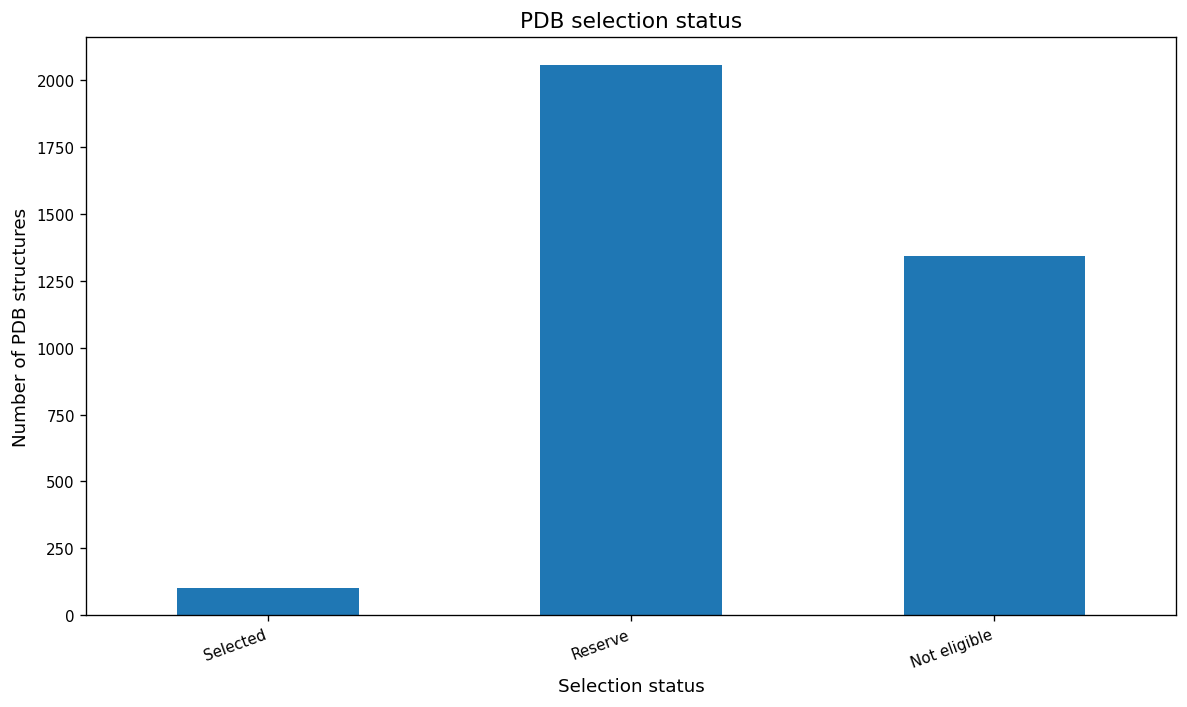

Saved figure: 01_pdb_selection_status.png


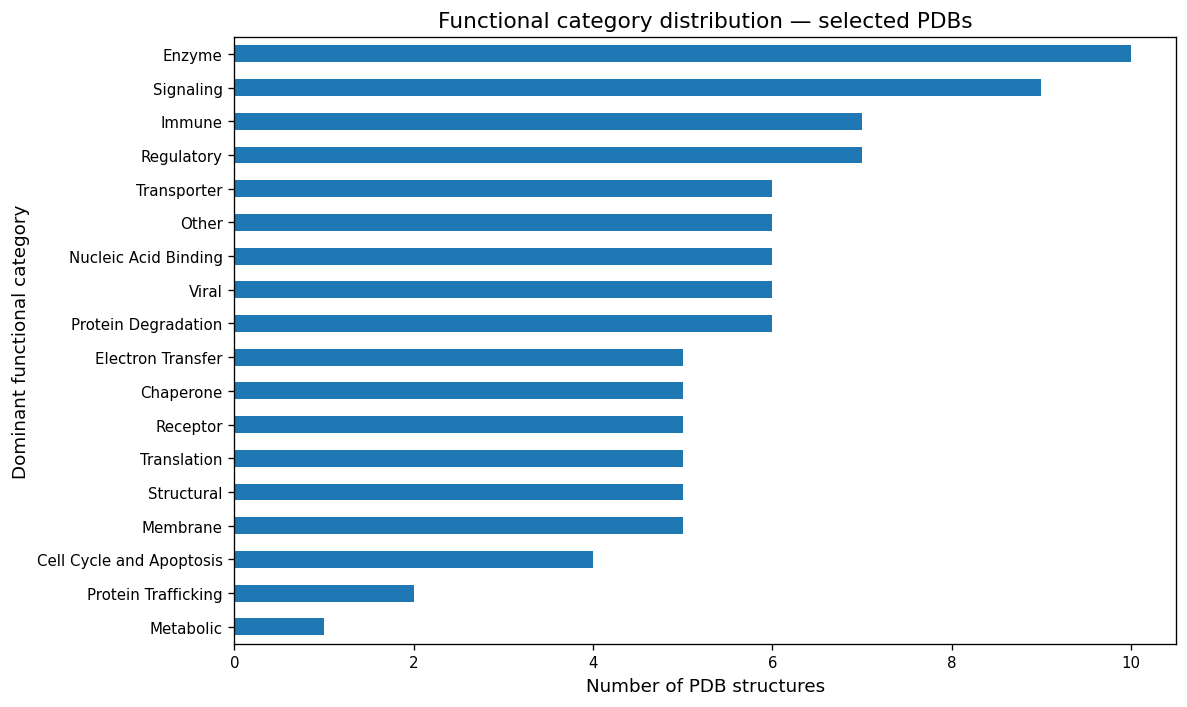

Saved figure: 02_selected_functional_categories.png


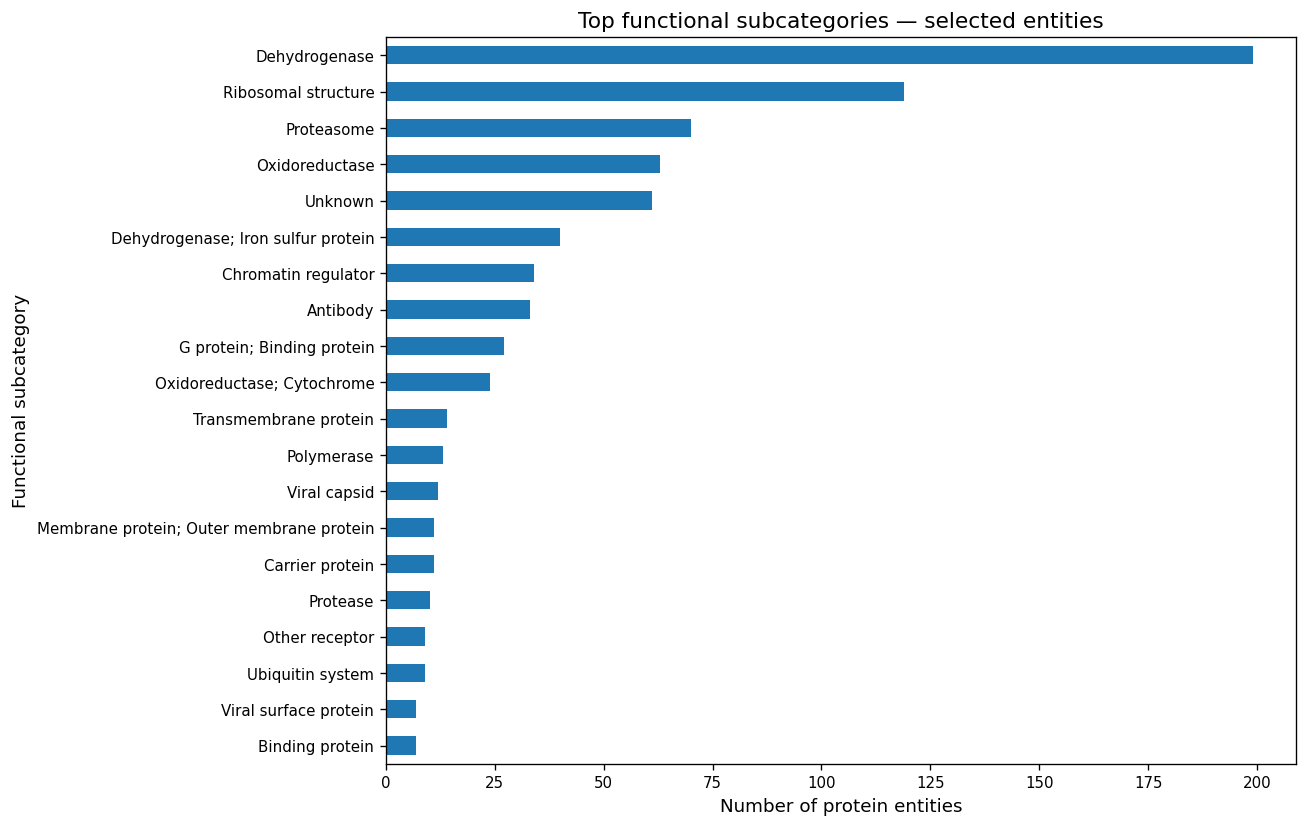

Saved figure: 03_selected_functional_subcategories.png


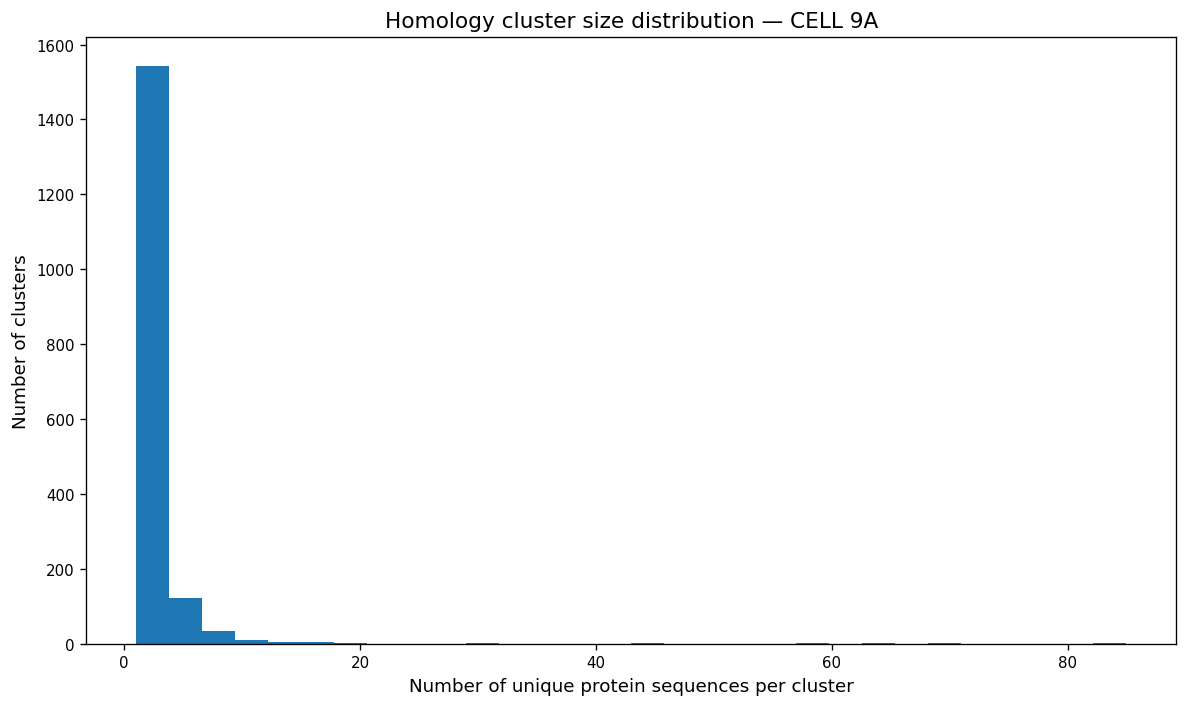

Saved figure: 04_homology_cluster_sizes.png


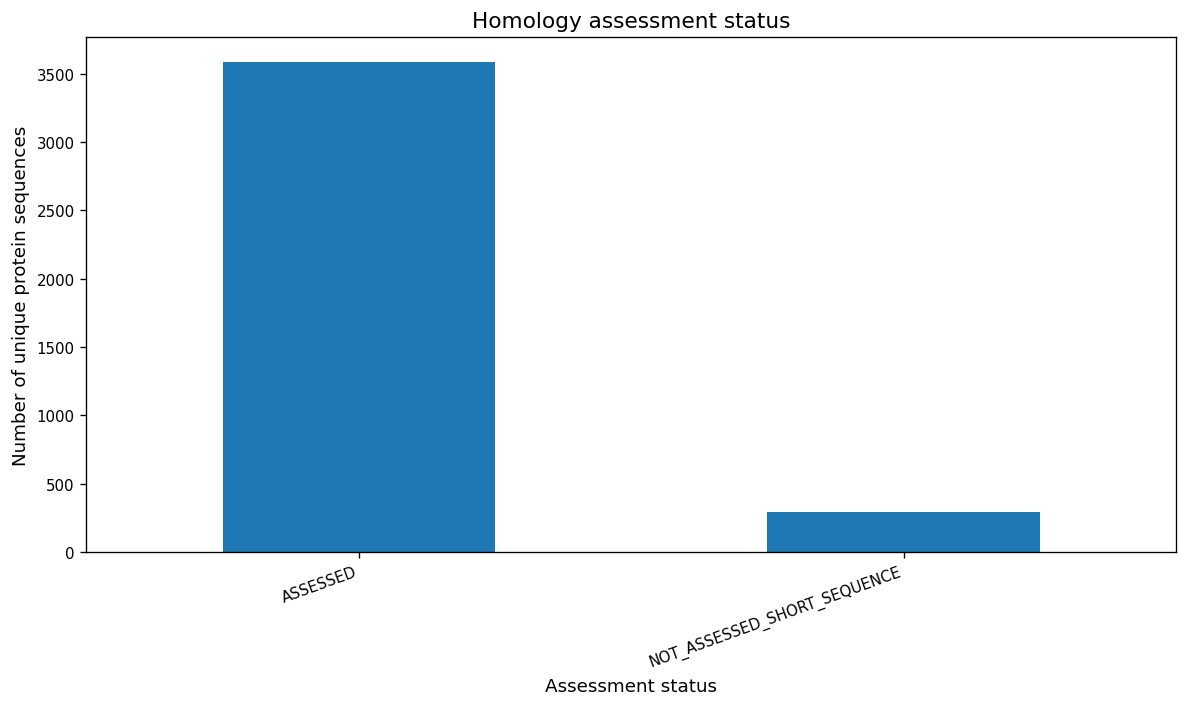

Saved figure: 05_homology_assessment_status.png


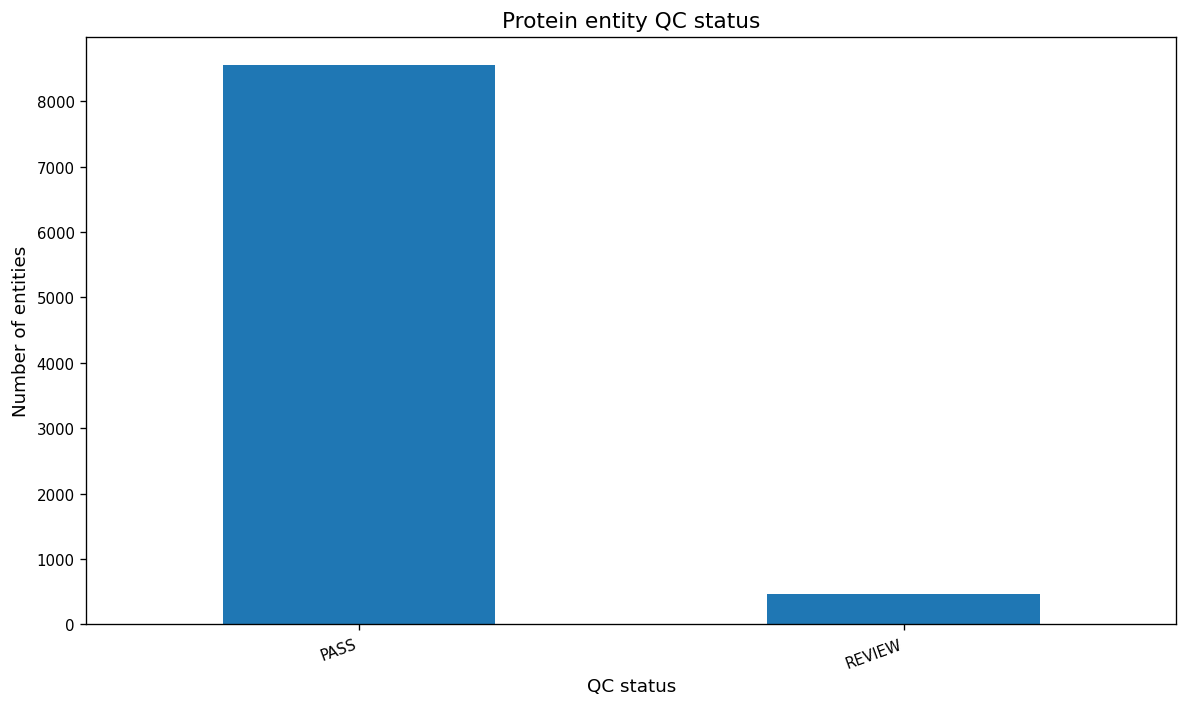

Saved figure: 06_entity_qc_status.png


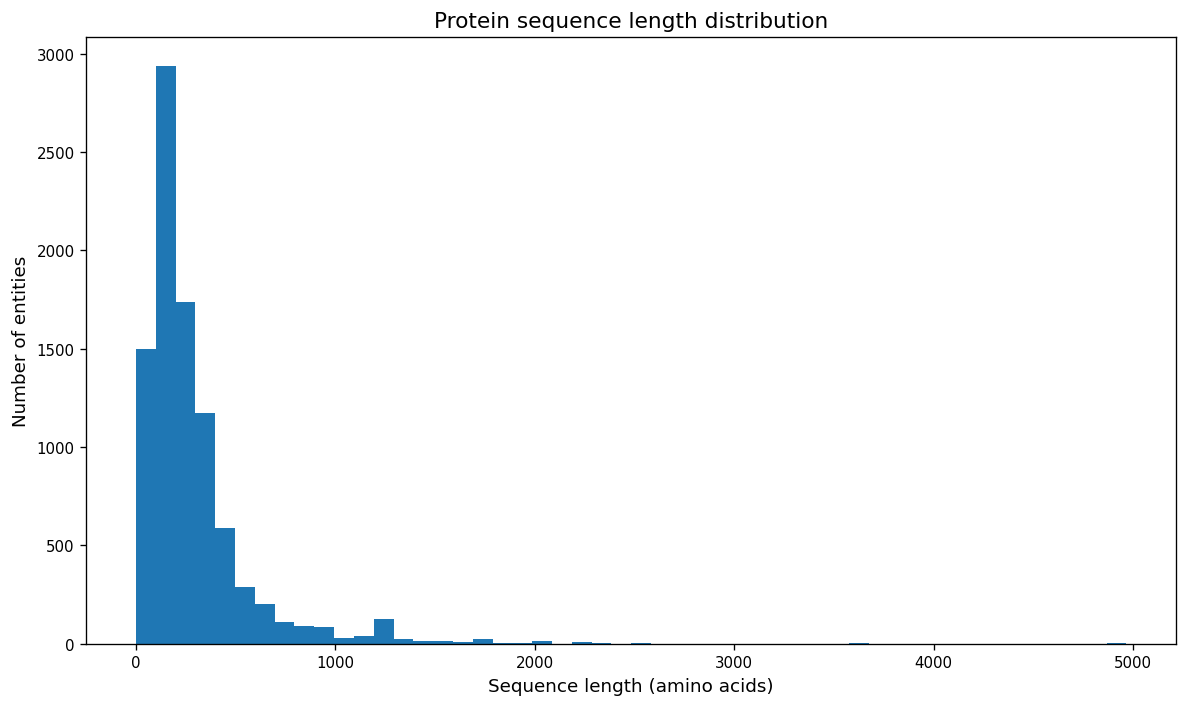

Saved figure: 07_sequence_length_distribution.png


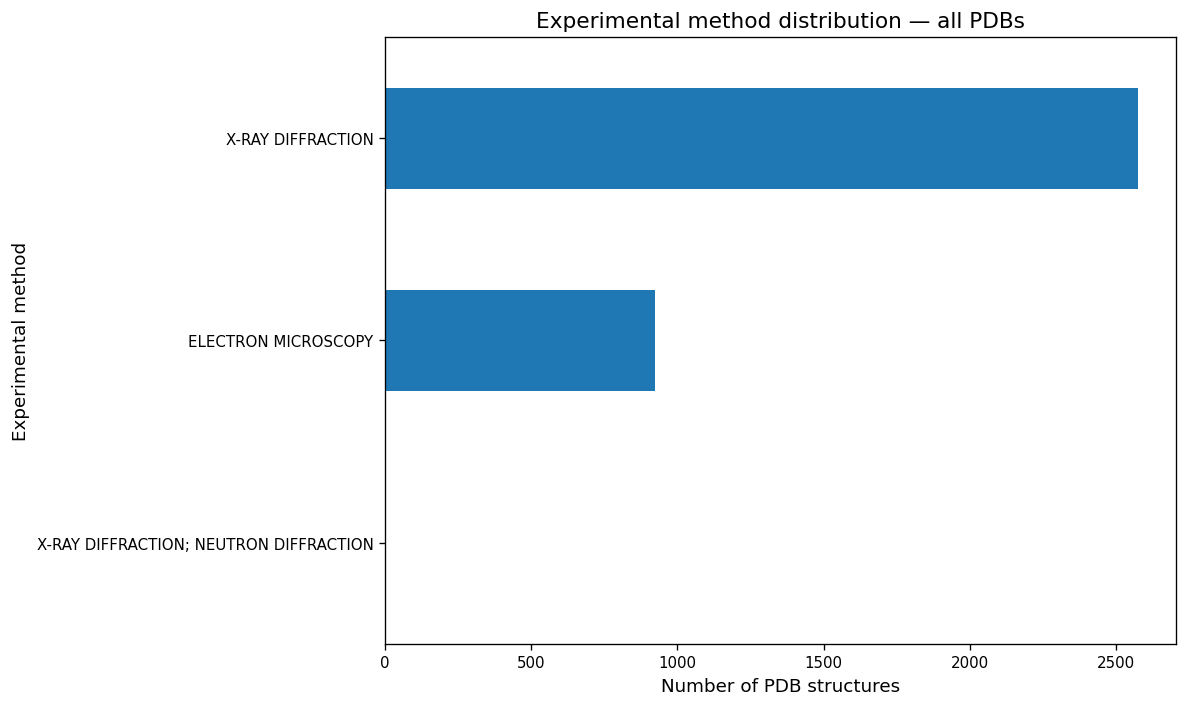

Saved figure: 08_experimental_methods.png


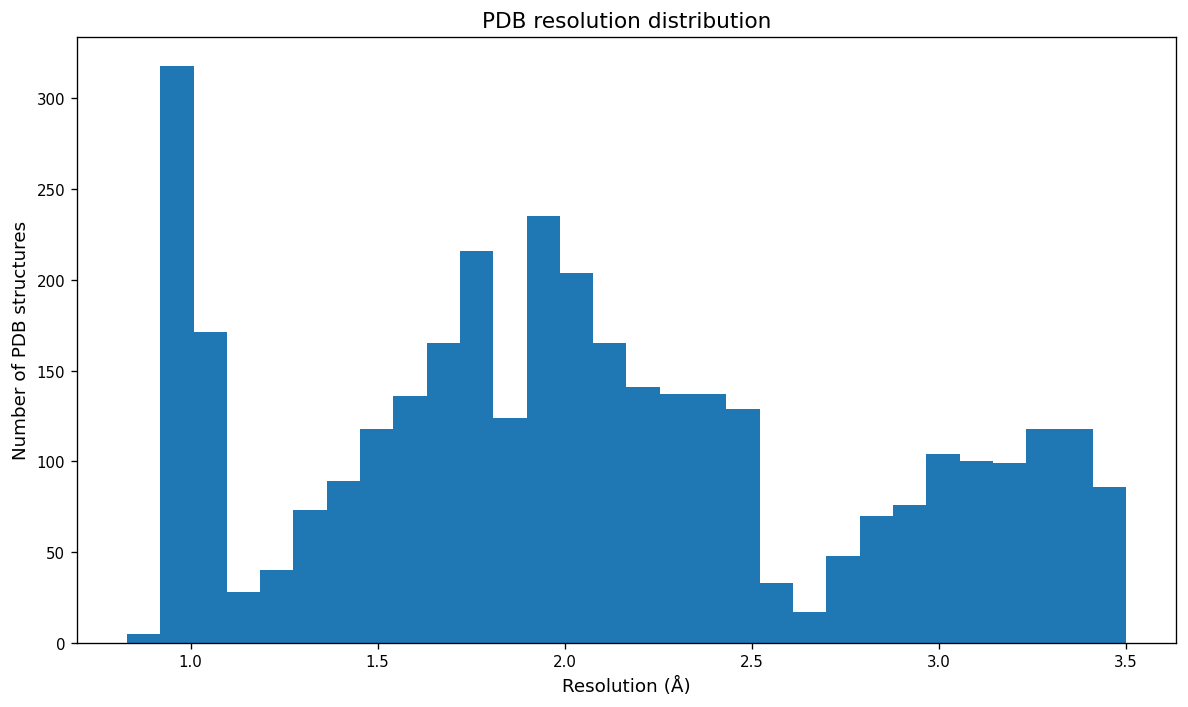

Saved figure: 09_resolution_distribution.png


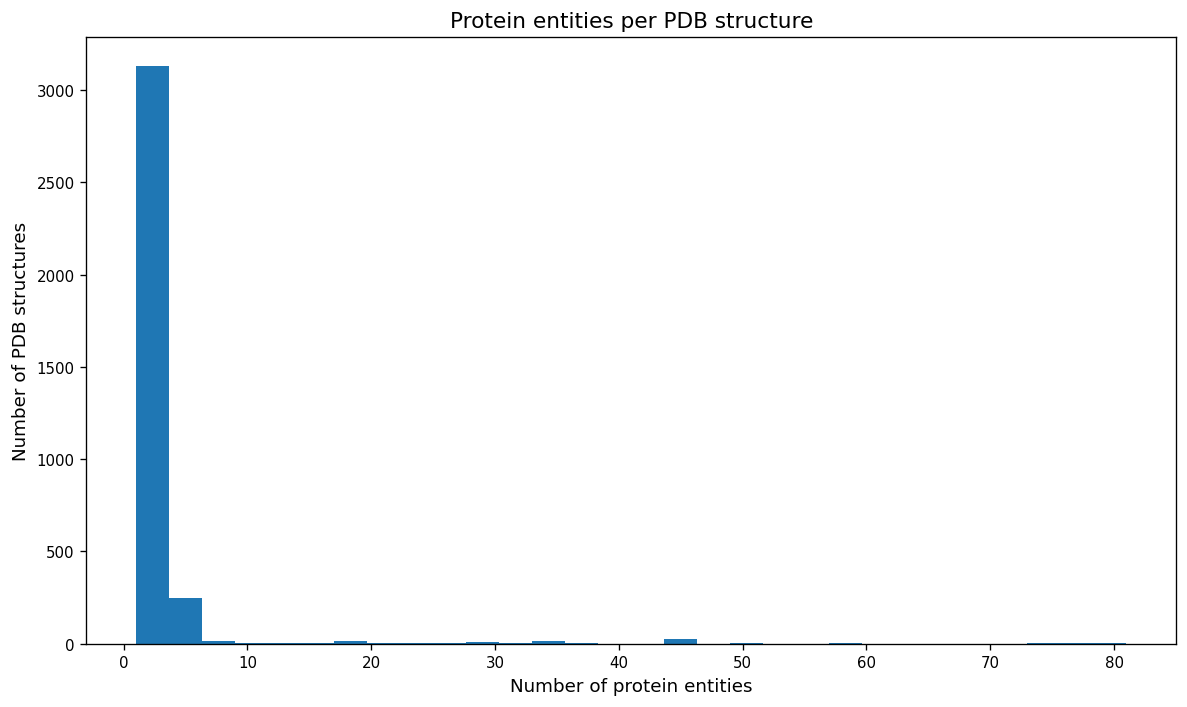

Saved figure: 10_entities_per_pdb.png


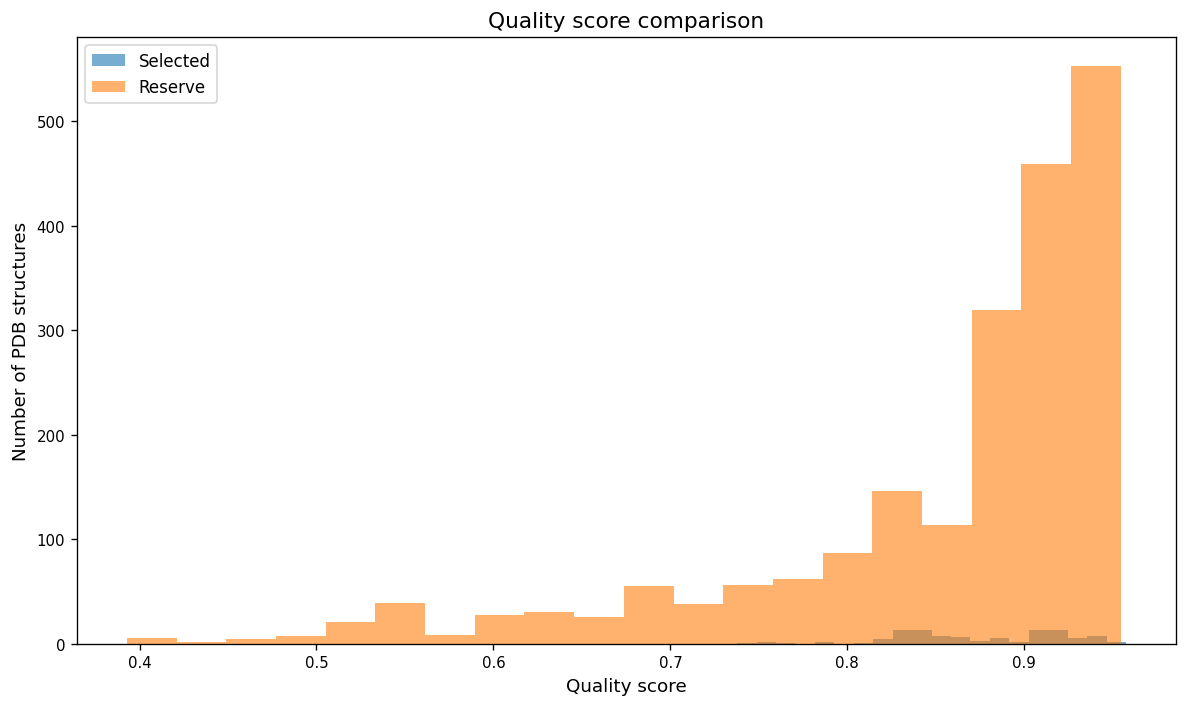

Saved figure: 11_quality_score_selected_vs_reserve.png


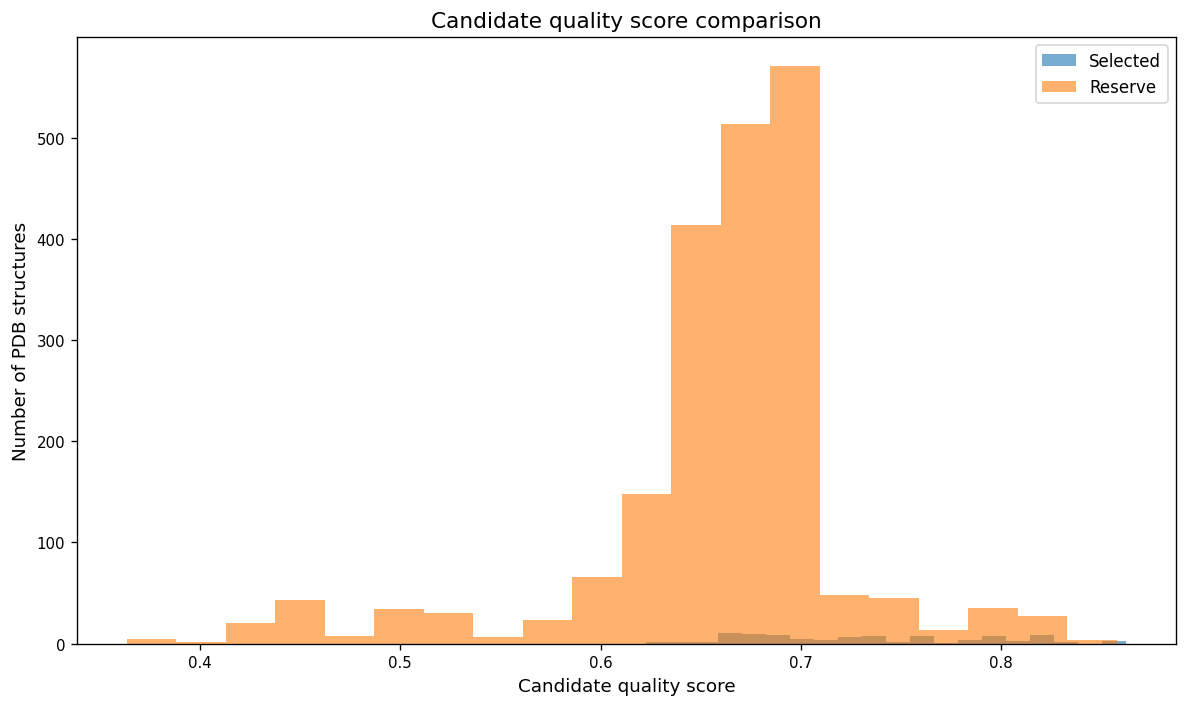

Saved figure: 12_candidate_score_selected_vs_reserve.png


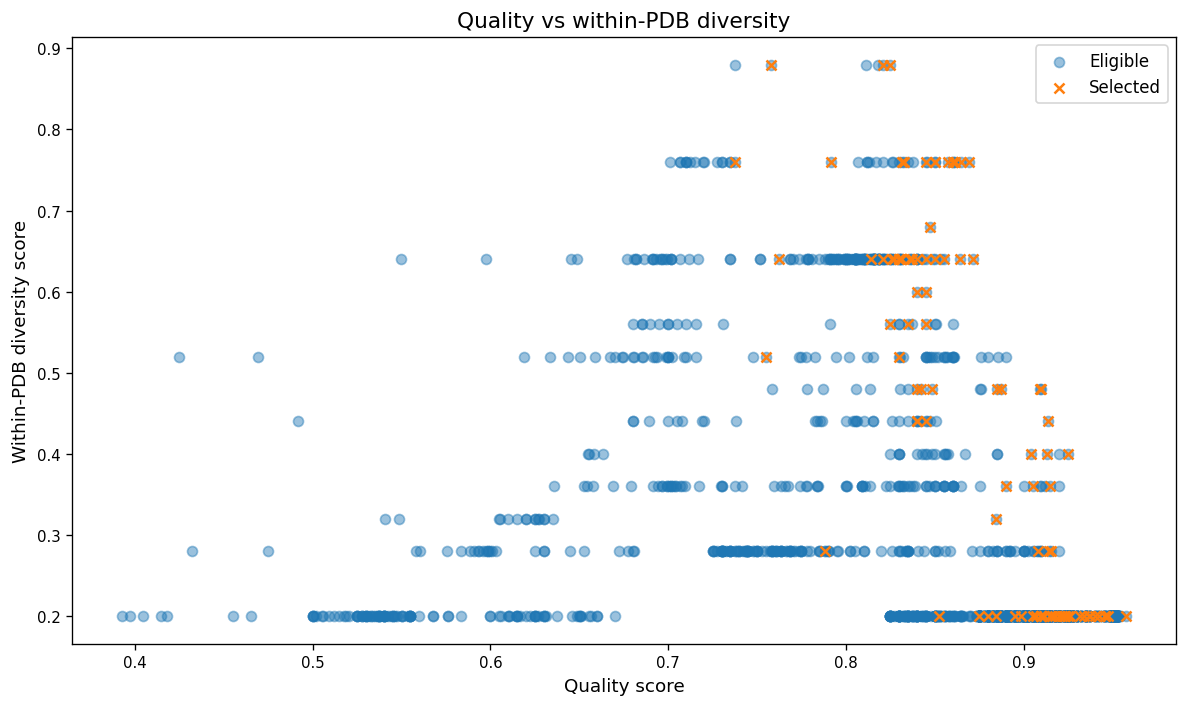

Saved figure: 13_quality_vs_diversity.png


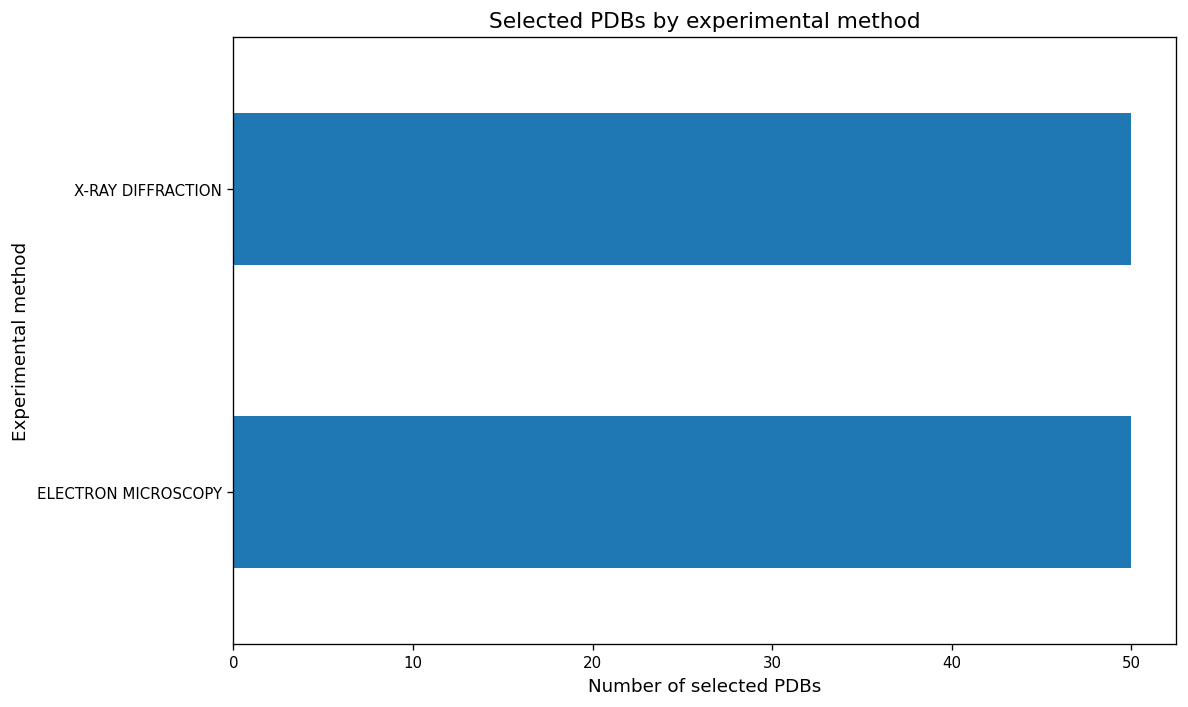

Saved figure: 14_selected_experimental_methods.png


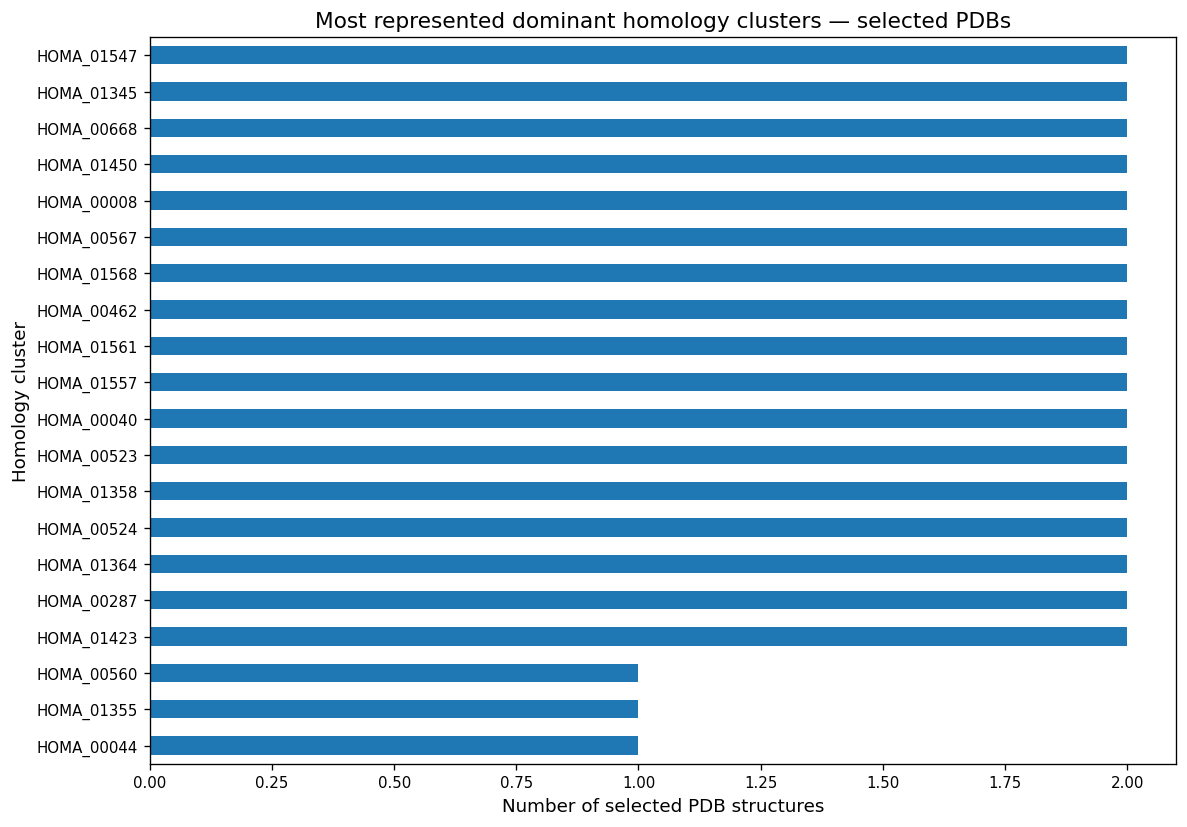

Saved figure: 15_selected_dominant_homology_clusters.png

CELL 10 COMPLETED

FINAL DATASET
------------------------------------------------------------------------------
Selected PDBs: 100
Selected entities: 879
Selected unique protein sequences: 484
Selected functional categories: 18
Selected dominant homology clusters: 83
Selected ribosome complexes: 3
Mean candidate quality score: 0.7335

OUTPUT DIRECTORIES
------------------------------------------------------------------------------
Final dataset: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\05_final_dataset
Quality reports: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\06_quality_reports
Statistical figures: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\03_reports\figures

VALIDATION
------------------------------------------------------------------------------
PASS: selected_pdb_ids_unique
PASS: selected_count_within_target
PASS: selected_entities_match_pdbs
PASS: selected_pdbs_are_eligible
PASS: ribosome_limit_r

In [28]:
# ============================================================
# CELL 10. UNIVERSAL PDB SELECTION PIPELINE
# VERSION 2.1.0
# ============================================================
#
# Назначение:
# 1. Объединение результатов CELL 4–9A.
# 2. Построение единого реестра PDB / protein entities.
# 3. Контроль качества последовательностей.
# 4. Учёт функциональной классификации.
# 5. Учёт результатов гомологической кластеризации CELL 9A.
# 6. Отбор до 100 PDB с учётом качества и разнообразия.
# 7. Формирование резерва и отчётов.
# 8. Построение статистических графиков.
#
# ВАЖНО:
# - CELL 9A повторно не запускается.
# - BLOSUM62 alignment здесь не выполняется.
# - 3D-анализ белков и карманов здесь не выполняется.
# - Ограничение max 2 применяется к доминирующему
#   ОЦЕНЁННОМУ гомологическому кластеру PDB.
# - NOT_ASSESSED_SHORT_SEQUENCE не считается подтверждённой
#   принадлежностью к оценённому кластеру.
#
# ============================================================


# ============================================================
# 10.1. IMPORTS AND CONFIGURATION
# ============================================================

import os
import re
import json
import time
import shutil
import warnings

from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

warnings.filterwarnings(
    "ignore",
    category=FutureWarning
)


VERSION = "2.1.0"

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)


# ------------------------------------------------------------
# PROJECT PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\apex\APEX\МИФИ\СНО\medic"
)

DATASET_ROOT = (
    PROJECT_ROOT / "Protein_Pocket_Dataset"
)

CANDIDATES_DIR = (
    DATASET_ROOT / "01_candidates"
)

FINAL_DIR = (
    DATASET_ROOT / "05_final_dataset"
)

REPORT_DIR = (
    DATASET_ROOT / "06_quality_reports"
)

FIGURES_DIR = (
    DATASET_ROOT / "03_reports" / "figures"
)


for directory in [
    FINAL_DIR,
    REPORT_DIR,
    FIGURES_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ------------------------------------------------------------
# SELECTION PARAMETERS
# ------------------------------------------------------------

TARGET_PDB_COUNT = 100

MIN_SEQUENCE_LENGTH = 50
MAX_SEQUENCE_LENGTH = 3000

MAX_RIBOSOME_PDB = 3

MAX_PDB_PER_DOMINANT_HOMOLOGY_CLUSTER = 2

MAX_RESOLUTION_FOR_SCORING = 5.0

RIBOSOME_ENTITY_THRESHOLD = 3


# ------------------------------------------------------------
# SCORING PARAMETERS
# ------------------------------------------------------------

# Quality score:
# QC                         40%
# Classification             20%
# Homology assessment        15%
# Experimental resolution    25%

QUALITY_WEIGHT_QC = 0.40
QUALITY_WEIGHT_CLASSIFICATION = 0.20
QUALITY_WEIGHT_HOMOLOGY = 0.15
QUALITY_WEIGHT_RESOLUTION = 0.25


# Candidate score:
# Quality score              65%
# Within-PDB diversity       20%
# Composition score          15%

CANDIDATE_WEIGHT_QUALITY = 0.65
CANDIDATE_WEIGHT_DIVERSITY = 0.20
CANDIDATE_WEIGHT_COMPOSITION = 0.15


# Soft diversity preferences

CATEGORY_PENALTY = 0.035
METHOD_PENALTY = 0.015

NEW_CATEGORY_BONUS = 0.08
NEW_METHOD_BONUS = 0.03


print("=" * 78)
print("CELL 10. UNIVERSAL PDB SELECTION PIPELINE")
print("=" * 78)

print("Version:", VERSION)
print("Project root:", PROJECT_ROOT)
print("Candidates directory:", CANDIDATES_DIR)
print("Target PDB count:", TARGET_PDB_COUNT)
print("Random seed:", RANDOM_SEED)


# ============================================================
# 10.2. INPUT FILE RESOLUTION
# ============================================================

def resolve_input_file(
    candidates,
    search_patterns=None
):
    """
    Поиск входного CSV.

    Сначала проверяются точные имена.
    Затем допускается поиск по шаблонам.
    """

    for filename in candidates:

        path = CANDIDATES_DIR / filename

        if path.exists():
            return path

    if search_patterns:

        for pattern in search_patterns:

            matches = sorted(
                CANDIDATES_DIR.glob(pattern)
            )

            if matches:
                return matches[0]

    raise FileNotFoundError(
        "Не найден входной файл.\n"
        f"Допустимые имена: {candidates}\n"
        f"Папка: {CANDIDATES_DIR}"
    )


INPUT_FILES = {

    "metadata": resolve_input_file(
        [
            "protein_candidates_metadata.csv",
            "protein_pdb_metadata.csv",
            "protein_metadata.csv",
        ],
        [
            "*metadata*.csv"
        ]
    ),

    "unique": resolve_input_file(
        [
            "protein_unique_sequences.csv",
        ]
    ),

    "alternatives": resolve_input_file(
        [
            "protein_alternative_structures.csv",
        ]
    ),

    "qc": resolve_input_file(
        [
            "protein_sequence_qc.csv",
            "protein_entity_sequence_qc.csv",
            "protein_qc.csv",
        ],
        [
            "*sequence*qc*.csv"
        ]
    ),

    "classification": resolve_input_file(
        [
            "protein_functional_classification.csv",
        ]
    ),

    "homology": resolve_input_file(
        [
            "protein_homology_clusters.csv",
        ]
    ),
}


print("\nINPUT FILES")

for name, path in INPUT_FILES.items():

    print(
        f"{name:18s}: {path.name}"
    )


# ============================================================
# 10.3. HELPER FUNCTIONS
# ============================================================

def read_csv(path):
    """
    Чтение CSV с автоматическим определением разделителя.
    Поддерживает UTF-8 и файлы с BOM.
    """

    return pd.read_csv(
        path,
        sep=None,
        engine="python",
        encoding="utf-8-sig"
    )

def normalize_id(series):
    """
    Нормализация идентификаторов.
    """

    return (
        series.astype("string")
        .str.strip()
        .replace("", pd.NA)
    )


def normalize_pdb_id(series):
    """
    Нормализация PDB ID.
    """

    return (
        series.astype("string")
        .str.strip()
        .str.upper()
        .replace("", pd.NA)
    )


def normalize_entity_id(series):
    """
    Нормализация entity ID.
    """

    return (
        series.astype("string")
        .str.strip()
        .replace("", pd.NA)
    )


def first_existing_column(
    df,
    candidates
):
    """
    Возвращает первое существующее имя столбца.
    """

    for column in candidates:

        if column in df.columns:
            return column

    return None


def safe_numeric(series):
    """
    Безопасное преобразование в числовой тип.
    """

    return pd.to_numeric(
        series,
        errors="coerce"
    )


def safe_mode(series):
    """
    Возвращает наиболее часто встречающееся значение.
    """

    values = (
        series.dropna()
        .astype(str)
    )

    if len(values) == 0:
        return "Unknown"

    counts = values.value_counts()

    return counts.index[0]


def is_true(value):
    """
    Унифицированное преобразование булевых значений.
    """

    if pd.isna(value):
        return False

    if isinstance(
        value,
        (bool, np.bool_)
    ):
        return bool(value)

    return (
        str(value).strip().lower()
        in {
            "true",
            "1",
            "yes",
            "y",
        }
    )


def normalize_category(value):

    if pd.isna(value):
        return "Unclassified"

    value = str(value).strip()

    if not value:
        return "Unclassified"

    return value


def normalize_method(value):

    if pd.isna(value):
        return "Unknown"

    value = str(value).strip()

    if not value:
        return "Unknown"

    return value


def assert_unique_key(
    df,
    key,
    table_name
):
    """
    Проверяет уникальность одного или нескольких ключей.
    """

    if isinstance(key, str):
        key_columns = [key]
    else:
        key_columns = list(key)

    missing = [
        column
        for column in key_columns
        if column not in df.columns
    ]

    if missing:

        raise KeyError(
            f"{table_name}: отсутствуют ключи {missing}"
        )

    if df[key_columns].isna().any().any():

        raise ValueError(
            f"{table_name}: обнаружены пустые значения "
            f"в ключах {key_columns}"
        )

    duplicates = df[
        df.duplicated(
            key_columns,
            keep=False
        )
    ]

    if len(duplicates):

        raise ValueError(
            f"{table_name}: обнаружены повторяющиеся ключи.\n"
            f"Количество строк: {len(duplicates)}\n"
            f"Примеры:\n"
            f"{duplicates.head(10).to_string(index=False)}"
        )


def validate_consistent_values(
    df,
    key,
    columns,
    table_name
):
    """
    Проверяет отсутствие противоречий между записями
    одного ключа.
    """

    if isinstance(key, str):
        key_columns = [key]
    else:
        key_columns = list(key)

    existing = [
        column
        for column in columns
        if column in df.columns
    ]

    if not existing:
        return

    conflicts = []

    for column in existing:

        counts = (
            df.groupby(
                key_columns,
                dropna=False
            )[column]
            .nunique(dropna=True)
        )

        bad_keys = counts[
            counts > 1
        ]

        if len(bad_keys):

            conflicts.append({
                "column": column,
                "conflicting_keys": int(
                    len(bad_keys)
                )
            })

    if conflicts:

        raise ValueError(
            f"{table_name}: найдены конфликтующие значения.\n"
            f"{conflicts}"
        )


# ============================================================
# 10.4. LOAD INPUT TABLES
# ============================================================

print("\n" + "=" * 78)
print("10.4. LOADING INPUT DATA")
print("=" * 78)

df_metadata = read_csv(
    INPUT_FILES["metadata"]
)

df_unique = read_csv(
    INPUT_FILES["unique"]
)

df_alternatives = read_csv(
    INPUT_FILES["alternatives"]
)

df_qc = read_csv(
    INPUT_FILES["qc"]
)

df_classification = read_csv(
    INPUT_FILES["classification"]
)

df_homology = read_csv(
    INPUT_FILES["homology"]
)


input_counts = {
    "metadata": len(df_metadata),
    "unique": len(df_unique),
    "alternatives": len(df_alternatives),
    "qc": len(df_qc),
    "classification": len(df_classification),
    "homology": len(df_homology),
}

for name, count in input_counts.items():

    print(
        f"{name:20s}: {count:>10,}"
    )


# ============================================================
# 10.5. NORMALIZE METADATA
# ============================================================

print("\n" + "=" * 78)
print("10.5. METADATA NORMALIZATION")
print("=" * 78)


if "pdb_id" not in df_metadata.columns:

    raise KeyError(
        "В metadata отсутствует обязательный столбец pdb_id"
    )


df_metadata = df_metadata.copy()

df_metadata["pdb_id"] = normalize_pdb_id(
    df_metadata["pdb_id"]
)

df_metadata = df_metadata.dropna(
    subset=["pdb_id"]
).copy()


assert_unique_key(
    df_metadata,
    "pdb_id",
    "METADATA"
)


method_column = first_existing_column(
    df_metadata,
    [
        "experimental_method",
        "experimental_methods",
        "method",
    ]
)


resolution_column = first_existing_column(
    df_metadata,
    [
        "resolution",
        "resolution_angstrom",
    ]
)


if method_column is None:

    df_metadata["experimental_method"] = "Unknown"

else:

    df_metadata["experimental_method"] = (
        df_metadata[method_column]
        .apply(normalize_method)
    )


if resolution_column is None:

    df_metadata["resolution"] = np.nan

else:

    df_metadata["resolution"] = safe_numeric(
        df_metadata[resolution_column]
    )


df_metadata["resolution"] = (
    df_metadata["resolution"]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
)


# Признак фактического наличия записи metadata.

df_metadata["_metadata_found"] = True


print(
    "Unique PDB IDs:",
    df_metadata["pdb_id"].nunique()
)

print(
    "Experimental methods:",
    df_metadata["experimental_method"]
    .value_counts()
    .to_dict()
)

print(
    "Missing resolution:",
    int(df_metadata["resolution"].isna().sum())
)


# ============================================================
# 10.6. NORMALIZE ENTITY TABLES
# ============================================================

print("\n" + "=" * 78)
print("10.6. ENTITY TABLE NORMALIZATION")
print("=" * 78)


def normalize_entity_table(
    df,
    table_name
):
    """
    Приведение таблицы сущностей к единой схеме.

    Поддерживаются:
    - sequence_normalized;
    - sequence_hash_exact;
    - unique_protein_id.

    Идентификаторы белков не реконструируются произвольно.
    """

    df = df.copy()

    required = [
        "pdb_id",
        "entity_id",
    ]

    missing = [
        column
        for column in required
        if column not in df.columns
    ]

    if missing:

        raise KeyError(
            f"{table_name}: отсутствуют обязательные поля {missing}"
        )


    df["pdb_id"] = normalize_pdb_id(
        df["pdb_id"]
    )

    df["entity_id"] = normalize_entity_id(
        df["entity_id"]
    )


    df = df.dropna(
        subset=[
            "pdb_id",
            "entity_id",
        ]
    ).copy()


    protein_id_column = first_existing_column(
        df,
        [
            "unique_protein_id",
            "protein_id",
        ]
    )


    sequence_column = first_existing_column(
        df,
        [
            "sequence_normalized",
            "sequence",
            "protein_sequence",
            "canonical_sequence",
        ]
    )


    hash_column = first_existing_column(
        df,
        [
            "sequence_hash_exact",
            "sequence_hash",
            "hash",
        ]
    )


    description_column = first_existing_column(
        df,
        [
            "description",
            "entity_description",
            "protein_description",
        ]
    )


    output = pd.DataFrame(
        index=df.index
    )


    output["pdb_id"] = df["pdb_id"]

    output["entity_id"] = df["entity_id"]


    if protein_id_column:

        output["unique_protein_id"] = normalize_id(
            df[protein_id_column]
        )

    else:

        output["unique_protein_id"] = pd.NA


    if sequence_column:

        output["sequence_normalized"] = (
            df[sequence_column]
            .astype("string")
            .str.strip()
        )

    else:

        output["sequence_normalized"] = pd.NA


    if hash_column:

        output["sequence_hash_exact"] = normalize_id(
            df[hash_column]
        )

    else:

        output["sequence_hash_exact"] = pd.NA


    if description_column:

        output["description"] = df[
            description_column
        ]

    else:

        output["description"] = pd.NA


    # Дополнительные поля, если они существуют.

    for column in [
        "sequence_length_exact",
        "sequence_length",
    ]:

        if column in df.columns:

            output[column] = df[column]


    return output.reset_index(
        drop=True
    )


df_unique_entities = normalize_entity_table(
    df_unique,
    "UNIQUE"
)


df_alternative_entities = normalize_entity_table(
    df_alternatives,
    "ALTERNATIVES"
)


df_entities = pd.concat(
    [
        df_unique_entities,
        df_alternative_entities,
    ],
    ignore_index=True
)


print(
    "Unique sequence table records:",
    len(df_unique_entities)
)

print(
    "Alternative structure records:",
    len(df_alternative_entities)
)

print(
    "Combined entity records:",
    len(df_entities)
)


# ------------------------------------------------------------
# CROSS-TABLE ENTITY VALIDATION
# ------------------------------------------------------------

duplicate_entity_mask = df_entities.duplicated(
    [
        "pdb_id",
        "entity_id",
    ],
    keep=False
)


if duplicate_entity_mask.any():

    duplicate_entities = df_entities.loc[
        duplicate_entity_mask
    ].copy()

    validate_consistent_values(
        duplicate_entities,
        [
            "pdb_id",
            "entity_id",
        ],
        [
            "unique_protein_id",
            "sequence_hash_exact",
            "sequence_normalized",
        ],
        "CROSS-TABLE ENTITY MERGE"
    )

    # Даже при совпадении части полей не удаляем записи
    # автоматически: это может привести к потере данных.

    raise ValueError(
        "Обнаружены повторяющиеся PDB/entity пары "
        "между UNIQUE и ALTERNATIVES.\n"
        "Необходимо проверить пересечение таблиц.\n"
        f"Примеры:\n"
        f"{duplicate_entities.head(10).to_string(index=False)}"
    )


assert_unique_key(
    df_entities,
    [
        "pdb_id",
        "entity_id",
    ],
    "COMBINED ENTITIES"
)


print(
    "Unique PDB/entity pairs:",
    len(df_entities)
)

print(
    "Unique PDB IDs:",
    df_entities["pdb_id"].nunique()
)

print(
    "Entities with protein ID:",
    df_entities["unique_protein_id"].notna().sum()
)

print(
    "Unique protein IDs:",
    df_entities["unique_protein_id"].nunique()
)


# ============================================================
# 10.7. VALIDATE PROTEIN ID COVERAGE
# ============================================================

print("\n" + "=" * 78)
print("10.7. PROTEIN ID COVERAGE")
print("=" * 78)


for table_name, table in [
    ("CLASSIFICATION", df_classification),
    ("HOMOLOGY", df_homology),
]:

    if "unique_protein_id" not in table.columns:

        raise KeyError(
            f"{table_name}: отсутствует unique_protein_id"
        )

    table["unique_protein_id"] = normalize_id(
        table["unique_protein_id"]
    )

    assert_unique_key(
        table,
        "unique_protein_id",
        table_name
    )


entity_protein_ids = set(
    df_entities["unique_protein_id"]
    .dropna()
    .astype(str)
)


classification_ids = set(
    df_classification["unique_protein_id"]
    .dropna()
    .astype(str)
)


homology_ids = set(
    df_homology["unique_protein_id"]
    .dropna()
    .astype(str)
)


missing_classification = (
    entity_protein_ids - classification_ids
)


missing_homology = (
    entity_protein_ids - homology_ids
)


if missing_classification:

    raise ValueError(
        "Некоторые entity отсутствуют в classification.\n"
        f"Количество: {len(missing_classification)}\n"
        f"Примеры: {list(missing_classification)[:10]}"
    )


if missing_homology:

    raise ValueError(
        "Некоторые entity отсутствуют в homology.\n"
        f"Количество: {len(missing_homology)}\n"
        f"Примеры: {list(missing_homology)[:10]}"
    )


print("Classification coverage: PASS")
print("Homology coverage: PASS")


# Проверка отсутствующих ID непосредственно в таблице сущностей.

missing_entity_ids = int(
    df_entities["unique_protein_id"].isna().sum()
)


if missing_entity_ids:

    raise ValueError(
        "В объединённой таблице сущностей отсутствуют "
        "unique_protein_id.\n"
        f"Количество: {missing_entity_ids}"
    )


# ============================================================
# 10.8. QC TABLE VALIDATION AND MERGE
# ============================================================

print("\n" + "=" * 78)
print("10.8. QC MERGE")
print("=" * 78)


qc_key_columns = [
    "pdb_id",
    "entity_id",
]


if not all(
    column in df_qc.columns
    for column in qc_key_columns
):

    raise KeyError(
        "QC table должна содержать pdb_id и entity_id"
    )


df_qc = df_qc.copy()


df_qc["pdb_id"] = normalize_pdb_id(
    df_qc["pdb_id"]
)

df_qc["entity_id"] = normalize_entity_id(
    df_qc["entity_id"]
)


df_qc = df_qc.dropna(
    subset=qc_key_columns
).copy()


assert_unique_key(
    df_qc,
    qc_key_columns,
    "QC"
)


qc_columns_to_use = [
    column
    for column in [
        "pdb_id",
        "entity_id",
        "qc_status",
        "qc_reasons",
        "sequence_length",
        "actual_length",
        "length_status",
        "ambiguity_status",
        "ambiguous_fraction",
        "standard_aa_fraction",
        "valid_symbols",
        "invalid_symbols",
        "contains_stop_symbol",
    ]
    if column in df_qc.columns
]


if "qc_status" not in qc_columns_to_use:

    raise KeyError(
        "В QC отсутствует обязательный столбец qc_status"
    )


# Признак фактического совпадения с QC.

df_qc["_qc_found"] = True

qc_columns_to_use.append(
    "_qc_found"
)


# QC является основным источником QC-полей.

for column in [
    "qc_status",
    "qc_reasons",
    "sequence_length",
    "actual_length",
    "length_status",
    "ambiguity_status",
    "ambiguous_fraction",
    "standard_aa_fraction",
    "valid_symbols",
    "invalid_symbols",
    "contains_stop_symbol",
]:

    if column in df_entities.columns:

        df_entities.drop(
            columns=column,
            inplace=True
        )


df_entities = df_entities.merge(
    df_qc[qc_columns_to_use],
    on=[
        "pdb_id",
        "entity_id",
    ],
    how="left",
    validate="one_to_one"
)


df_entities["qc_found"] = (
    df_entities["_qc_found"]
    .fillna(False)
    .astype(bool)
)


df_entities["qc_status"] = (
    df_entities["qc_status"]
    .astype("string")
    .str.upper()
    .fillna("UNKNOWN")
)


df_entities["qc_pass"] = (
    df_entities["qc_status"].isin(
        [
            "PASS",
            "OK",
            "VALID",
            "ACCEPTED",
        ]
    )
)


# ------------------------------------------------------------
# FINAL SEQUENCE LENGTH
# ------------------------------------------------------------

df_entities["sequence_length_final"] = np.nan


if "sequence_length" in df_entities.columns:

    df_entities["sequence_length_final"] = safe_numeric(
        df_entities["sequence_length"]
    )


if "actual_length" in df_entities.columns:

    df_entities["sequence_length_final"] = (
        df_entities["sequence_length_final"]
        .fillna(
            safe_numeric(
                df_entities["actual_length"]
            )
        )
    )


if "sequence_length_exact" in df_entities.columns:

    df_entities["sequence_length_final"] = (
        df_entities["sequence_length_final"]
        .fillna(
            safe_numeric(
                df_entities["sequence_length_exact"]
            )
        )
    )


if "sequence_normalized" in df_entities.columns:

    missing_length = (
        df_entities["sequence_length_final"].isna()
    )

    df_entities.loc[
        missing_length,
        "sequence_length_final"
    ] = (
        df_entities.loc[
            missing_length,
            "sequence_normalized"
        ]
        .astype("string")
        .str.len()
    )


df_entities["sequence_length_final"] = safe_numeric(
    df_entities["sequence_length_final"]
)


df_entities["sequence_length_pass"] = (
    df_entities["sequence_length_final"].between(
        MIN_SEQUENCE_LENGTH,
        MAX_SEQUENCE_LENGTH,
        inclusive="both"
    )
)


print(
    "QC records matched:",
    int(df_entities["qc_found"].sum())
)

print(
    "QC pass:",
    int(df_entities["qc_pass"].sum())
)

print(
    "QC not pass:",
    int((~df_entities["qc_pass"]).sum())
)

print(
    "QC records missing:",
    int((~df_entities["qc_found"]).sum())
)

print(
    "Valid sequence lengths:",
    int(df_entities["sequence_length_pass"].sum())
)


# ============================================================
# 10.9. CLASSIFICATION MERGE
# ============================================================

print("\n" + "=" * 78)
print("10.9. FUNCTIONAL CLASSIFICATION MERGE")
print("=" * 78)


if "functional_category" not in df_classification.columns:

    raise KeyError(
        "В classification отсутствует functional_category"
    )


classification_fields = [
    "unique_protein_id",
    "functional_category",
    "functional_subcategory",
    "functional_labels",
    "classification_confidence",
    "classification_review_status",
    "selection_priority",
    "is_ribosomal",
    "is_enzyme",
    "is_antibody",
    "is_tcr",
    "is_viral",
    "is_membrane_associated",
    "is_nucleic_acid_related",
    "is_mitochondrial",
    "is_gtpase_related",
    "is_chaperone",
    "is_transcription_related",
    "is_protein_degradation_related",
    "is_translation_related",
    "is_electron_transfer_related",
    "is_cell_cycle_related",
    "is_protein_trafficking_related",
]


classification_columns = [
    column
    for column in classification_fields
    if column in df_classification.columns
]


df_class_merge = df_classification[
    classification_columns
].copy()


validate_consistent_values(
    df_class_merge,
    "unique_protein_id",
    [
        "functional_category",
        "functional_subcategory",
        "classification_review_status",
        "classification_confidence",
    ],
    "CLASSIFICATION"
)


df_entities = df_entities.merge(
    df_class_merge,
    on="unique_protein_id",
    how="left",
    validate="many_to_one"
)


df_entities["functional_category"] = (
    df_entities["functional_category"]
    .apply(normalize_category)
)


if "functional_subcategory" in df_entities.columns:

    df_entities["functional_subcategory"] = (
        df_entities["functional_subcategory"]
        .apply(normalize_category)
    )

else:

    df_entities["functional_subcategory"] = (
        "Unclassified"
    )


if "classification_review_status" in df_entities.columns:

    df_entities["classification_review_status"] = (
        df_entities["classification_review_status"]
        .fillna("UNKNOWN")
        .astype(str)
    )

else:

    df_entities["classification_review_status"] = (
        "UNKNOWN"
    )


if "classification_confidence" in df_entities.columns:

    df_entities["classification_confidence"] = safe_numeric(
        df_entities["classification_confidence"]
    )

else:

    df_entities["classification_confidence"] = np.nan


df_entities["classification_pass"] = (
    df_entities["functional_category"]
    != "Unclassified"
)


print(
    "Functional categories:",
    df_entities["functional_category"].nunique()
)


print(
    "\nFunctional category distribution:"
)

print(
    df_entities["functional_category"]
    .value_counts()
    .head(20)
)


# ============================================================
# 10.10. HOMOLOGY MERGE — CELL 9A
# ============================================================

print("\n" + "=" * 78)
print("10.10. HOMOLOGY MERGE — CELL 9A")
print("=" * 78)


homology_fields = [
    "unique_protein_id",
    "homology_cluster_id",
    "homology_cluster_size",
    "homology_cluster_role",
    "homology_assessment_status",
    "homology_representative_seq_id",
    "homology_identity_to_representative",
    "homology_coverage_min_to_representative",
    "homology_alignment_length_to_representative",
]


required_homology_columns = [
    "unique_protein_id",
    "homology_cluster_id",
    "homology_cluster_role",
    "homology_assessment_status",
]


missing_homology_columns = [
    column
    for column in required_homology_columns
    if column not in df_homology.columns
]


if missing_homology_columns:

    raise KeyError(
        "В CELL 9A отсутствуют обязательные поля:\n"
        f"{missing_homology_columns}"
    )


homology_columns_to_use = [
    column
    for column in homology_fields
    if column in df_homology.columns
]


df_homology_merge = df_homology[
    homology_columns_to_use
].copy()


df_homology_merge["homology_cluster_role"] = (
    df_homology_merge["homology_cluster_role"]
    .astype("string")
    .str.lower()
)


df_homology_merge["homology_assessment_status"] = (
    df_homology_merge["homology_assessment_status"]
    .astype("string")
    .str.upper()
)


df_entities = df_entities.merge(
    df_homology_merge,
    on="unique_protein_id",
    how="left",
    validate="many_to_one"
)


if df_entities["homology_cluster_id"].isna().any():

    missing_count = int(
        df_entities["homology_cluster_id"].isna().sum()
    )

    raise ValueError(
        "После объединения обнаружены entity без homology mapping.\n"
        f"Количество: {missing_count}"
    )


df_entities["homology_assessed"] = (
    df_entities["homology_assessment_status"]
    .eq("ASSESSED")
)


df_entities["homology_not_assessed_short"] = (
    df_entities["homology_assessment_status"]
    .eq("NOT_ASSESSED_SHORT_SEQUENCE")
)


df_entities["assessed_homology_cluster_id"] = (
    df_entities["homology_cluster_id"]
    .where(
        df_entities["homology_assessed"]
    )
)


for column in [
    "homology_cluster_size",
    "homology_identity_to_representative",
    "homology_coverage_min_to_representative",
    "homology_alignment_length_to_representative",
]:

    if column in df_entities.columns:

        df_entities[column] = safe_numeric(
            df_entities[column]
        )


# Проверка статусов.

unexpected_homology_statuses = (
    set(
        df_entities["homology_assessment_status"]
        .dropna()
        .unique()
    )
    -
    {
        "ASSESSED",
        "NOT_ASSESSED_SHORT_SEQUENCE",
    }
)


if unexpected_homology_statuses:

    raise ValueError(
        "Обнаружены неизвестные статусы гомологии:\n"
        f"{unexpected_homology_statuses}"
    )


print(
    "Assessed entity records:",
    int(df_entities["homology_assessed"].sum())
)


print(
    "Not assessed short entity records:",
    int(
        df_entities["homology_not_assessed_short"].sum()
    )
)


print(
    "Assessed homology clusters:",
    df_entities.loc[
        df_entities["homology_assessed"],
        "assessed_homology_cluster_id"
    ].nunique()
)


# ============================================================
# 10.11. METADATA MERGE
# ============================================================

print("\n" + "=" * 78)
print("10.11. METADATA MERGE")
print("=" * 78)


metadata_columns = [
    column
    for column in [
        "pdb_id",
        "experimental_method",
        "resolution",
        "structure_title",
        "title",
        "deposition_date",
        "release_date",
        "_metadata_found",
    ]
    if column in df_metadata.columns
]


# Metadata является основным источником
# метода и разрешения структуры.

for column in [
    "experimental_method",
    "resolution",
    "structure_title",
    "title",
    "deposition_date",
    "release_date",
]:

    if column in df_entities.columns:

        df_entities.drop(
            columns=column,
            inplace=True
        )


df_entities = df_entities.merge(
    df_metadata[metadata_columns],
    on="pdb_id",
    how="left",
    validate="many_to_one"
)


df_entities["metadata_found"] = (
    df_entities["_metadata_found"]
    .fillna(False)
    .astype(bool)
)


df_entities["experimental_method"] = (
    df_entities["experimental_method"]
    .apply(normalize_method)
)


df_entities["resolution"] = safe_numeric(
    df_entities["resolution"]
)


print(
    "Entities after all merges:",
    len(df_entities)
)


print(
    "PDB IDs after all merges:",
    df_entities["pdb_id"].nunique()
)


print(
    "Entities with metadata:",
    int(df_entities["metadata_found"].sum())
)


print(
    "Entities without metadata:",
    int((~df_entities["metadata_found"]).sum())
)


# ============================================================
# 10.12. ENTITY-LEVEL QUALITY AND FLAGS
# ============================================================

print("\n" + "=" * 78)
print("10.12. ENTITY-LEVEL QUALITY")
print("=" * 78)


if "is_ribosomal" in df_entities.columns:

    df_entities["is_ribosomal_flag"] = (
        df_entities["is_ribosomal"]
        .apply(is_true)
        .astype(bool)
    )

else:

    df_entities["is_ribosomal_flag"] = False


df_entities["entity_review_required"] = (
    (~df_entities["qc_pass"])
    | (~df_entities["classification_pass"])
    | (df_entities["homology_not_assessed_short"])
    | (~df_entities["metadata_found"])
)


df_entities["entity_quality_score"] = (
    QUALITY_WEIGHT_QC
    * df_entities["qc_pass"].astype(float)

    + 0.25
    * df_entities["sequence_length_pass"].astype(float)

    + QUALITY_WEIGHT_CLASSIFICATION
    * df_entities["classification_pass"].astype(float)

    + QUALITY_WEIGHT_HOMOLOGY
    * df_entities["homology_assessed"].astype(float)
)


print(
    "Entity quality score mean:",
    round(
        float(
            df_entities["entity_quality_score"].mean()
        ),
        4
    )
)


print(
    "Entities requiring review:",
    int(df_entities["entity_review_required"].sum())
)


# ============================================================
# 10.13. PDB-LEVEL COMPOSITION AUDIT
# ============================================================

print("\n" + "=" * 78)
print("10.13. PDB-LEVEL COMPOSITION AUDIT")
print("=" * 78)


pdb_records = []


for pdb_id, group in tqdm(
    df_entities.groupby("pdb_id"),
    desc="PDB composition",
    total=df_entities["pdb_id"].nunique()
):

    # --------------------------------------------------------
    # FUNCTIONAL CATEGORIES
    # --------------------------------------------------------

    all_categories = Counter(
        group["functional_category"]
        .fillna("Unclassified")
        .astype(str)
    )


    all_subcategories = Counter(
        group["functional_subcategory"]
        .fillna("Unclassified")
        .astype(str)
    )


    # Unclassified не участвует в определении
    # доминирующей биологической категории.

    categories = Counter({
        key: value
        for key, value in all_categories.items()
        if key != "Unclassified"
    })


    subcategories = Counter({
        key: value
        for key, value in all_subcategories.items()
        if key != "Unclassified"
    })


    dominant_category = (
        categories.most_common(1)[0][0]
        if categories
        else "Unclassified"
    )


    dominant_subcategory = (
        subcategories.most_common(1)[0][0]
        if subcategories
        else "Unclassified"
    )


    # --------------------------------------------------------
    # HOMOLOGY
    # --------------------------------------------------------

    assessed = group[
        group["homology_assessed"]
    ]


    cluster_counts = Counter(
        assessed["assessed_homology_cluster_id"]
        .dropna()
        .astype(str)
    )


    if cluster_counts:

        dominant_cluster = (
            cluster_counts.most_common(1)[0][0]
        )

        dominant_cluster_count = (
            cluster_counts.most_common(1)[0][1]
        )

    else:

        dominant_cluster = pd.NA
        dominant_cluster_count = 0


    # --------------------------------------------------------
    # ENTITY COUNTS
    # --------------------------------------------------------

    n_entities = len(group)


    n_ribosomal = int(
        group["is_ribosomal_flag"].sum()
    )


    qc_pass_fraction = float(
        group["qc_pass"].mean()
    )


    classification_pass_fraction = float(
        group["classification_pass"].mean()
    )


    assessed_fraction = float(
        group["homology_assessed"].mean()
    )


    not_assessed_short_count = int(
        group["homology_not_assessed_short"].sum()
    )


    valid_length_count = int(
        group["sequence_length_pass"].sum()
    )


    # --------------------------------------------------------
    # SEQUENCE LENGTH
    # --------------------------------------------------------

    valid_lengths = (
        group["sequence_length_final"]
        .dropna()
    )


    mean_length = (
        float(valid_lengths.mean())
        if len(valid_lengths)
        else np.nan
    )


    min_length = (
        float(valid_lengths.min())
        if len(valid_lengths)
        else np.nan
    )


    max_length = (
        float(valid_lengths.max())
        if len(valid_lengths)
        else np.nan
    )


    # --------------------------------------------------------
    # RESOLUTION
    # --------------------------------------------------------

    resolution_values = (
        safe_numeric(group["resolution"])
        .dropna()
    )


    resolution = (
        float(resolution_values.median())
        if len(resolution_values)
        else np.nan
    )


    # --------------------------------------------------------
    # EXPERIMENTAL METHOD
    # --------------------------------------------------------

    method = safe_mode(
        group["experimental_method"]
    )


    # --------------------------------------------------------
    # METADATA VALIDATION
    # --------------------------------------------------------

    metadata_found = bool(
        group["metadata_found"].all()
    )


    # --------------------------------------------------------
    # RIBOSOME HEURISTIC
    # --------------------------------------------------------

    is_ribosome_complex = (
        n_ribosomal >= RIBOSOME_ENTITY_THRESHOLD
    )


    # --------------------------------------------------------
    # QUALITY SCORE
    # --------------------------------------------------------

    resolution_score = (

        max(
            0.0,
            1.0 - resolution / MAX_RESOLUTION_FOR_SCORING
        )

        if pd.notna(resolution)

        else 0.0
    )


    quality_score = (
        QUALITY_WEIGHT_QC
        * qc_pass_fraction

        + QUALITY_WEIGHT_CLASSIFICATION
        * classification_pass_fraction

        + QUALITY_WEIGHT_HOMOLOGY
        * assessed_fraction

        + QUALITY_WEIGHT_RESOLUTION
        * resolution_score
    )


    # --------------------------------------------------------
    # WITHIN-PDB DIVERSITY
    # --------------------------------------------------------

    diversity_score = (

        min(
            len(categories),
            5
        ) / 5.0 * 0.60

        +

        min(
            len(cluster_counts),
            5
        ) / 5.0 * 0.40
    )


    # --------------------------------------------------------
    # COMPOSITION SCORE
    # --------------------------------------------------------

    composition_score = min(
        np.log1p(n_entities)
        / np.log1p(20),
        1.0
    )


    # --------------------------------------------------------
    # RECORD
    # --------------------------------------------------------

    pdb_records.append({

        "pdb_id": pdb_id,

        "n_entities": n_entities,

        "n_unique_protein_ids": group[
            "unique_protein_id"
        ].nunique(),

        "n_functional_categories": len(categories),

        "functional_category_mentions": sum(
            categories.values()
        ),

        "n_unclassified_entities": int(
            all_categories.get("Unclassified", 0)
        ),

        "n_functional_subcategories": len(subcategories),

        "dominant_category": dominant_category,

        "dominant_subcategory": dominant_subcategory,

        "n_assessed_homology_entities": len(assessed),

        "n_not_assessed_short": not_assessed_short_count,

        "n_assessed_homology_clusters": len(cluster_counts),

        "dominant_homology_cluster_id": dominant_cluster,

        "dominant_homology_cluster_entity_count": (
            dominant_cluster_count
        ),

        "qc_pass_fraction": qc_pass_fraction,

        "classification_pass_fraction": (
            classification_pass_fraction
        ),

        "homology_assessed_fraction": assessed_fraction,

        "n_valid_length_entities": valid_length_count,

        "mean_sequence_length": mean_length,

        "min_sequence_length": min_length,

        "max_sequence_length": max_length,

        "n_ribosomal_entities": n_ribosomal,

        "is_ribosome_complex": is_ribosome_complex,

        "experimental_method": method,

        "resolution": resolution,

        "metadata_found": metadata_found,

        "quality_score": quality_score,

        "diversity_score": diversity_score,

        "composition_score": composition_score,

    })


df_pdb = pd.DataFrame(
    pdb_records
)


if df_pdb.empty:

    raise RuntimeError(
        "PDB-level audit is empty."
    )


assert_unique_key(
    df_pdb,
    "pdb_id",
    "PDB AUDIT"
)


print(
    "PDB records:",
    len(df_pdb)
)


print(
    "PDB with assessed homology cluster:",
    int(
        df_pdb["dominant_homology_cluster_id"]
        .notna()
        .sum()
    )
)


print(
    "PDB without assessed homology cluster:",
    int(
        df_pdb["dominant_homology_cluster_id"]
        .isna()
        .sum()
    )
)


# ============================================================
# 10.14. ELIGIBILITY AND MANUAL REVIEW
# ============================================================

print("\n" + "=" * 78)
print("10.14. ELIGIBILITY")
print("=" * 78)


# PDB проходит проверку длины, если хотя бы одна
# его белковая сущность имеет допустимую длину.

df_pdb["has_valid_sequence_length"] = (
    df_pdb["n_valid_length_entities"] > 0
)


df_pdb["eligibility_status"] = "ELIGIBLE"


df_pdb.loc[
    df_pdb["qc_pass_fraction"] <= 0,
    "eligibility_status"
] = "QC_FAIL"


df_pdb.loc[
    ~df_pdb["has_valid_sequence_length"],
    "eligibility_status"
] = "SEQUENCE_LENGTH_REVIEW"


df_pdb.loc[
    df_pdb["classification_pass_fraction"] <= 0,
    "eligibility_status"
] = "CLASSIFICATION_REVIEW"


df_pdb["manual_review_required"] = (

    (df_pdb["qc_pass_fraction"] < 1.0)

    |

    (df_pdb["classification_pass_fraction"] < 1.0)

    |

    (df_pdb["n_not_assessed_short"] > 0)

    |

    (df_pdb["resolution"].isna())

    |

    (~df_pdb["metadata_found"])
)


df_pdb["is_eligible"] = (
    df_pdb["eligibility_status"] == "ELIGIBLE"
)


df_eligible = df_pdb[
    df_pdb["is_eligible"]
].copy()


df_manual_review = df_pdb[
    df_pdb["manual_review_required"]
].copy()


print(
    "Total PDB:",
    len(df_pdb)
)


print(
    "Eligible PDB:",
    len(df_eligible)
)


print(
    "Manual review:",
    len(df_manual_review)
)


print(
    "\nEligibility status:"
)


print(
    df_pdb["eligibility_status"]
    .value_counts()
)


if len(df_eligible) == 0:

    raise RuntimeError(
        "Нет PDB, прошедших критерии eligibility."
    )


# ============================================================
# 10.15. CANDIDATE SCORING
# ============================================================

print("\n" + "=" * 78)
print("10.15. CANDIDATE SCORING")
print("=" * 78)


# ------------------------------------------------------------
# RESOLUTION SCORE
# ------------------------------------------------------------

df_eligible["resolution_score"] = (

    1.0

    -

    df_eligible["resolution"].clip(
        lower=0,
        upper=MAX_RESOLUTION_FOR_SCORING
    )

    / MAX_RESOLUTION_FOR_SCORING

).clip(
    0,
    1
)


# ------------------------------------------------------------
# CANDIDATE QUALITY SCORE
# ------------------------------------------------------------

# Resolution уже входит в quality_score.
# Поэтому повторно отдельным слагаемым не учитывается.

df_eligible["candidate_quality_score"] = (

    CANDIDATE_WEIGHT_QUALITY
    * df_eligible["quality_score"]

    +

    CANDIDATE_WEIGHT_DIVERSITY
    * df_eligible["diversity_score"]

    +

    CANDIDATE_WEIGHT_COMPOSITION
    * df_eligible["composition_score"]
)


df_eligible["candidate_quality_score"] = (
    df_eligible["candidate_quality_score"]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .fillna(0.0)
)


df_eligible = df_eligible.sort_values(
    [
        "candidate_quality_score",
        "quality_score",
        "resolution",
    ],
    ascending=[
        False,
        False,
        True,
    ],
    na_position="last"
).reset_index(
    drop=True
)


print(
    "Mean candidate score:",
    round(
        float(
            df_eligible["candidate_quality_score"].mean()
        ),
        4
    )
)


print(
    "Score range:",
    round(
        float(
            df_eligible["candidate_quality_score"].min()
        ),
        4
    ),
    "—",
    round(
        float(
            df_eligible["candidate_quality_score"].max()
        ),
        4
    )
)


# ============================================================
# 10.16. GREEDY DIVERSITY-AWARE SELECTION
# ============================================================

print("\n" + "=" * 78)
print("10.16. GREEDY DIVERSITY-AWARE SELECTION")
print("=" * 78)


selected_pdb_ids = set()

dominant_cluster_counts = Counter()

category_counts = Counter()

method_counts = Counter()

ribosome_count = 0

selection_log = []


remaining = df_eligible.copy()


for step in tqdm(
    range(
        min(
            TARGET_PDB_COUNT,
            len(remaining)
        )
    ),
    desc="Selecting PDBs"
):

    best_index = None

    best_dynamic_score = -np.inf


    # --------------------------------------------------------
    # SEARCH BEST AVAILABLE CANDIDATE
    # --------------------------------------------------------

    for index, row in remaining.iterrows():

        pdb_id = row["pdb_id"]


        if pdb_id in selected_pdb_ids:
            continue


        # ----------------------------------------------------
        # HARD CONSTRAINT 1: RIBOSOME COMPLEXES
        # ----------------------------------------------------

        is_ribosome = bool(
            row["is_ribosome_complex"]
        )


        if (
            is_ribosome
            and ribosome_count >= MAX_RIBOSOME_PDB
        ):

            continue


        # ----------------------------------------------------
        # HARD CONSTRAINT 2:
        # DOMINANT ASSESSED HOMOLOGY CLUSTER
        # ----------------------------------------------------

        cluster_id = row[
            "dominant_homology_cluster_id"
        ]


        if pd.notna(cluster_id):

            if (
                dominant_cluster_counts[str(cluster_id)]
                >= MAX_PDB_PER_DOMINANT_HOMOLOGY_CLUSTER
            ):

                continue


        # ----------------------------------------------------
        # SOFT DIVERSITY PREFERENCES
        # ----------------------------------------------------

        category = str(
            row["dominant_category"]
        )


        method = str(
            row["experimental_method"]
        )


        category_penalty = (
            category_counts[category]
            * CATEGORY_PENALTY
        )


        method_penalty = (
            method_counts[method]
            * METHOD_PENALTY
        )


        new_category_bonus = (

            NEW_CATEGORY_BONUS

            if category_counts[category] == 0

            else 0.0
        )


        new_method_bonus = (

            NEW_METHOD_BONUS

            if method_counts[method] == 0

            else 0.0
        )


        dynamic_score = (

            float(
                row["candidate_quality_score"]
            )

            - category_penalty

            - method_penalty

            + new_category_bonus

            + new_method_bonus
        )


        if dynamic_score > best_dynamic_score:

            best_dynamic_score = dynamic_score

            best_index = index


    # --------------------------------------------------------
    # STOP IF NO CANDIDATE PASSES CONSTRAINTS
    # --------------------------------------------------------

    if best_index is None:

        print(
            "\nSelection stopped: "
            "no candidates satisfy hard constraints."
        )

        break


    # --------------------------------------------------------
    # ADD SELECTED PDB
    # --------------------------------------------------------

    selected_row = remaining.loc[
        best_index
    ]


    selected_pdb_id = selected_row[
        "pdb_id"
    ]


    selected_pdb_ids.add(
        selected_pdb_id
    )


    category = str(
        selected_row["dominant_category"]
    )


    method = str(
        selected_row["experimental_method"]
    )


    cluster_id = selected_row[
        "dominant_homology_cluster_id"
    ]


    category_counts[category] += 1

    method_counts[method] += 1


    if pd.notna(cluster_id):

        dominant_cluster_counts[
            str(cluster_id)
        ] += 1


    if bool(
        selected_row["is_ribosome_complex"]
    ):

        ribosome_count += 1


    selection_log.append({

        "selection_order": len(selected_pdb_ids),

        "pdb_id": selected_pdb_id,

        "candidate_quality_score": float(
            selected_row["candidate_quality_score"]
        ),

        "dynamic_selection_score": float(
            best_dynamic_score
        ),

        "dominant_category": category,

        "experimental_method": method,

        "dominant_homology_cluster_id": (
            cluster_id
        ),

        "is_ribosome_complex": bool(
            selected_row["is_ribosome_complex"]
        ),

    })


    remaining = remaining.drop(
        index=best_index
    )


    if len(selected_pdb_ids) >= TARGET_PDB_COUNT:

        break


# ============================================================
# 10.17. FINAL SELECTED / RESERVE TABLES
# ============================================================

print("\n" + "=" * 78)
print("10.17. FINAL SELECTION")
print("=" * 78)


df_selection_log = pd.DataFrame(
    selection_log
)


# ВАЖНО:
# df_selected формируется из df_eligible,
# а не из df_pdb.
#
# Поэтому candidate_quality_score и resolution_score
# сохраняются в итоговой таблице.

df_selected = df_eligible[
    df_eligible["pdb_id"].isin(
        selected_pdb_ids
    )
].copy()


if len(df_selection_log):

    df_selected = df_selected.merge(
        df_selection_log,
        on="pdb_id",
        how="left",
        validate="one_to_one",
        suffixes=(
            "",
            "_selection"
        )
    )


    df_selected = df_selected.sort_values(
        "selection_order"
    )


df_reserve = df_eligible[
    ~df_eligible["pdb_id"].isin(
        selected_pdb_ids
    )
].copy()


df_selected["selection_status"] = "SELECTED"

df_reserve["selection_status"] = "RESERVE"

df_manual_review["selection_status"] = "MANUAL_REVIEW"


print(
    "Target PDB count:",
    TARGET_PDB_COUNT
)


print(
    "Selected PDB count:",
    len(df_selected)
)


print(
    "Reserve PDB count:",
    len(df_reserve)
)


print(
    "Manual review PDB count:",
    len(df_manual_review)
)


if len(df_selected) < TARGET_PDB_COUNT:

    print(
        "WARNING: target count was not reached. "
        "Hard constraints or candidate availability "
        "limited selection."
    )


# ============================================================
# 10.18. SELECTED ENTITY REGISTRY
# ============================================================

print("\n" + "=" * 78)
print("10.18. SELECTED ENTITY REGISTRY")
print("=" * 78)


selected_ids = set(
    df_selected["pdb_id"].astype(str)
)


reserve_ids = set(
    df_reserve["pdb_id"].astype(str)
)


df_selected_entities = df_entities[
    df_entities["pdb_id"]
    .astype(str)
    .isin(selected_ids)
].copy()


df_reserve_entities = df_entities[
    df_entities["pdb_id"]
    .astype(str)
    .isin(reserve_ids)
].copy()


print(
    "Selected PDBs:",
    df_selected["pdb_id"].nunique()
)


print(
    "Selected entities:",
    len(df_selected_entities)
)


print(
    "Selected unique proteins:",
    df_selected_entities["unique_protein_id"].nunique()
)


print(
    "Reserve entities:",
    len(df_reserve_entities)
)


# ============================================================
# 10.19. FINAL VALIDATION
# ============================================================

print("\n" + "=" * 78)
print("10.19. FINAL VALIDATION")
print("=" * 78)


validation_results = {}


validation_results["selected_pdb_ids_unique"] = (
    df_selected["pdb_id"].is_unique
)


validation_results["selected_count_within_target"] = (
    len(df_selected) <= TARGET_PDB_COUNT
)


validation_results["selected_entities_match_pdbs"] = (
    set(
        df_selected_entities["pdb_id"].astype(str)
    )

    ==

    set(
        df_selected["pdb_id"].astype(str)
    )
)


validation_results["selected_pdbs_are_eligible"] = (
    set(
        df_selected["pdb_id"]
    ).issubset(
        set(
            df_eligible["pdb_id"]
        )
    )
)


validation_results["ribosome_limit_respected"] = (
    int(
        df_selected["is_ribosome_complex"].sum()
    )
    <= MAX_RIBOSOME_PDB
)


selected_cluster_counts = (
    df_selected[
        df_selected[
            "dominant_homology_cluster_id"
        ].notna()
    ]["dominant_homology_cluster_id"]
    .astype(str)
    .value_counts()
)


validation_results["dominant_cluster_limit_respected"] = (

    selected_cluster_counts.max()
    <= MAX_PDB_PER_DOMINANT_HOMOLOGY_CLUSTER

    if len(selected_cluster_counts)

    else True
)


validation_results["all_selected_have_pdb_metadata"] = (
    df_selected["metadata_found"].all()
)


validation_results["all_selected_have_quality_scores"] = (
    df_selected["candidate_quality_score"].notna().all()
)


validation_results["short_sequences_not_assigned_as_assessed"] = (
    not (
        df_entities.loc[
            df_entities["homology_not_assessed_short"],
            "homology_assessed"
        ].any()
    )
)


validation_results["no_duplicate_entity_keys"] = (
    not df_entities.duplicated(
        [
            "pdb_id",
            "entity_id",
        ]
    ).any()
)


validation_results["homology_ids_complete"] = (
    df_entities["homology_cluster_id"].notna().all()
)


validation_results["qc_mapping_complete"] = (
    df_entities["qc_found"].all()
)


validation_results["classification_mapping_complete"] = (
    df_entities["functional_category"].notna().all()
)


validation_results["metadata_mapping_complete_for_selected"] = (
    df_selected["metadata_found"].all()
)


validation_results["selected_length_eligibility_valid"] = (
    df_selected["has_valid_sequence_length"].all()
)


for name, passed in validation_results.items():

    print(
        f"{'PASS' if passed else 'FAIL'}: {name}"
    )


if not all(validation_results.values()):

    failed = [
        name
        for name, passed in validation_results.items()
        if not passed
    ]


    raise AssertionError(
        f"Final validation failed: {failed}"
    )


print("\nALL VALIDATIONS PASSED")


# ============================================================
# 10.20. CATEGORY BALANCE REPORT
# ============================================================

print("\n" + "=" * 78)
print("10.20. CATEGORY BALANCE")
print("=" * 78)


category_balance = (
    df_selected["dominant_category"]
    .value_counts()
    .rename_axis("functional_category")
    .reset_index(
        name="selected_pdb_count"
    )
)


category_balance["selected_fraction"] = (
    category_balance["selected_pdb_count"]
    / max(
        len(df_selected),
        1
    )
)


print(
    category_balance.to_string(
        index=False
    )
)


# ============================================================
# 10.21. HOMOLOGY DIVERSITY REPORT
# ============================================================

print("\n" + "=" * 78)
print("10.21. HOMOLOGY DIVERSITY REPORT")
print("=" * 78)


homology_diversity = (
    df_selected[
        df_selected[
            "dominant_homology_cluster_id"
        ].notna()
    ]
    .groupby(
        "dominant_homology_cluster_id"
    )
    .agg(
        selected_pdb_count=(
            "pdb_id",
            "nunique"
        ),

        selected_entity_count=(
            "n_assessed_homology_entities",
            "sum"
        ),
    )
    .reset_index()
    .sort_values(
        "selected_pdb_count",
        ascending=False
    )
)


print(
    "\nSelected dominant homology clusters:"
)


if len(homology_diversity):

    print(
        homology_diversity.head(20)
        .to_string(index=False)
    )

else:

    print(
        "No assessed dominant homology clusters."
    )


# ============================================================
# 10.22. STATISTICAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("10.22. STATISTICAL SUMMARY")
print("=" * 78)


unique_assessed_count = int(
    df_homology[
        df_homology[
            "homology_assessment_status"
        ]
        .astype(str)
        .str.upper()
        .eq("ASSESSED")
    ]["unique_protein_id"]
    .nunique()
)


unique_not_assessed_count = int(
    df_homology[
        df_homology[
            "homology_assessment_status"
        ]
        .astype(str)
        .str.upper()
        .eq("NOT_ASSESSED_SHORT_SEQUENCE")
    ]["unique_protein_id"]
    .nunique()
)


summary = {

    "version": VERSION,

    "random_seed": RANDOM_SEED,


    "input_counts": {

        "metadata_records": int(
            len(df_metadata)
        ),

        "unique_sequence_records": int(
            len(df_unique)
        ),

        "alternative_structure_records": int(
            len(df_alternatives)
        ),

        "qc_records": int(
            len(df_qc)
        ),

        "classification_records": int(
            len(df_classification)
        ),

        "homology_records": int(
            len(df_homology)
        ),

    },


    "entity_counts": {

        "combined_entity_records": int(
            len(df_entities)
        ),

        "unique_pdb_entity_pairs": int(
            df_entities[
                [
                    "pdb_id",
                    "entity_id",
                ]
            ]
            .drop_duplicates()
            .shape[0]
        ),

        "unique_protein_ids": int(
            df_entities[
                "unique_protein_id"
            ].nunique()
        ),

        "qc_pass_entities": int(
            df_entities["qc_pass"].sum()
        ),

        "qc_mapping_found": int(
            df_entities["qc_found"].sum()
        ),

        "homology_assessed_entities": int(
            df_entities["homology_assessed"].sum()
        ),

        "homology_not_assessed_short_entities": int(
            df_entities[
                "homology_not_assessed_short"
            ].sum()
        ),

        "unique_sequences_assessed": (
            unique_assessed_count
        ),

        "unique_sequences_not_assessed": (
            unique_not_assessed_count
        ),

    },


    "pdb_counts": {

        "total": int(
            len(df_pdb)
        ),

        "eligible": int(
            len(df_eligible)
        ),

        "selected": int(
            len(df_selected)
        ),

        "reserve": int(
            len(df_reserve)
        ),

        "manual_review": int(
            len(df_manual_review)
        ),

    },


    "selection_parameters": {

        "target_pdb_count": TARGET_PDB_COUNT,

        "max_ribosome_pdb": MAX_RIBOSOME_PDB,

        "max_pdb_per_dominant_homology_cluster": (
            MAX_PDB_PER_DOMINANT_HOMOLOGY_CLUSTER
        ),

        "min_sequence_length": MIN_SEQUENCE_LENGTH,

        "max_sequence_length": MAX_SEQUENCE_LENGTH,

        "ribosome_entity_threshold": (
            RIBOSOME_ENTITY_THRESHOLD
        ),

    },


    "scoring_weights": {

        "quality_qc": QUALITY_WEIGHT_QC,

        "quality_classification": (
            QUALITY_WEIGHT_CLASSIFICATION
        ),

        "quality_homology": (
            QUALITY_WEIGHT_HOMOLOGY
        ),

        "quality_resolution": (
            QUALITY_WEIGHT_RESOLUTION
        ),

        "candidate_quality": (
            CANDIDATE_WEIGHT_QUALITY
        ),

        "candidate_diversity": (
            CANDIDATE_WEIGHT_DIVERSITY
        ),

        "candidate_composition": (
            CANDIDATE_WEIGHT_COMPOSITION
        ),

    },


    "selected_statistics": {

        "mean_quality_score": (

            float(
                df_selected["quality_score"].mean()
            )

            if len(df_selected)

            else None
        ),


        "mean_diversity_score": (

            float(
                df_selected["diversity_score"].mean()
            )

            if len(df_selected)

            else None
        ),


        "mean_candidate_quality_score": (

            float(
                df_selected[
                    "candidate_quality_score"
                ].mean()
            )

            if len(df_selected)

            else None
        ),


        "ribosome_complex_count": int(
            df_selected[
                "is_ribosome_complex"
            ].sum()
        ),


        "functional_categories": int(
            df_selected[
                "dominant_category"
            ].nunique()
        ),


        "dominant_homology_clusters": int(
            df_selected[
                "dominant_homology_cluster_id"
            ].nunique()
        ),

    },


    "validation": {

        key: bool(value)

        for key, value in validation_results.items()

    },


    "limitations": [

        "Homology information is reused from CELL 9A.",

        "No new all-vs-all sequence alignment is performed.",

        "MMseqs2 candidate generation in CELL 9A was heuristic.",

        "Greedy selection is order-dependent.",

        "The homology cap applies only to the dominant assessed cluster per PDB.",

        "Homology similarity does not prove structural or functional equivalence.",

        "Ribosome complex classification is a project heuristic.",

        "Diversity score describes diversity within an individual PDB.",

        "Category and experimental method preferences are soft constraints.",

        "The selection target is a maximum of 100 PDB structures.",

    ],

}


# ============================================================
# 10.23. SAVE OUTPUT TABLES
# ============================================================

print("\n" + "=" * 78)
print("10.23. SAVING OUTPUT TABLES")
print("=" * 78)


OUTPUTS = {

    "protein_pdb_selection_scores.csv":
        df_pdb,

    "protein_universal_selection_audit.csv":
        df_eligible,

    "protein_universal_diversity_report.csv":
        df_pdb,

    "protein_final_100.csv":
        df_selected,

    "protein_final_100_entities.csv":
        df_selected_entities,

    "protein_selection_reserve.csv":
        df_reserve,

    "protein_selection_reserve_entities.csv":
        df_reserve_entities,

    "protein_selection_manual_review.csv":
        df_manual_review,

    "protein_category_balance.csv":
        category_balance,

    "protein_selected_homology_diversity.csv":
        homology_diversity,

    "protein_selection_log.csv":
        df_selection_log,

    "protein_entity_registry.csv":
        df_entities,

    "protein_pdb_registry.csv":
        df_pdb,

}


FINAL_OUTPUT_NAMES = {

    "protein_final_100.csv",

    "protein_final_100_entities.csv",

    "protein_selection_reserve.csv",

    "protein_selection_reserve_entities.csv",

}


for filename, table in OUTPUTS.items():

    output_directory = (

        FINAL_DIR

        if filename in FINAL_OUTPUT_NAMES

        else REPORT_DIR

    )


    output_path = (
        output_directory / filename
    )


    table.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )


    print(
        f"Saved: {output_path.name:48s} "
        f"{len(table):>8,} rows"
    )


# ------------------------------------------------------------
# SAVE JSON SUMMARY
# ------------------------------------------------------------

summary_path = (
    REPORT_DIR
    / "protein_universal_selection_summary.json"
)


with open(
    summary_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        summary,
        file,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )


print(
    "Saved:",
    summary_path.name
)


# ============================================================
# 10.24. STATISTICAL VISUALIZATION
# ============================================================

print("\n" + "=" * 78)
print("10.24. STATISTICAL VISUALIZATION")
print("=" * 78)


plt.rcParams.update({

    "figure.figsize": (10, 6),

    "axes.titlesize": 13,

    "axes.labelsize": 11,

    "xtick.labelsize": 9,

    "ytick.labelsize": 9,

    "figure.dpi": 120,

})


def save_figure(filename):
    """
    Сохраняет и отображает график.
    """

    path = FIGURES_DIR / filename

    plt.tight_layout()

    plt.savefig(
        path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    print(
        "Saved figure:",
        path.name
    )


# ------------------------------------------------------------
# FIGURE 1. PDB SELECTION STATUS
# ------------------------------------------------------------

# Категории не пересекаются:
# Selected + Reserve + Not eligible = Total PDB.

status_counts = pd.Series({

    "Selected": len(df_selected),

    "Reserve": len(df_reserve),

    "Not eligible": int(
        (~df_pdb["is_eligible"]).sum()
    ),

})


print(
    "PDB requiring manual review:",
    len(df_manual_review)
)


plt.figure()

status_counts.plot(
    kind="bar"
)

plt.title(
    "PDB selection status"
)

plt.xlabel(
    "Selection status"
)

plt.ylabel(
    "Number of PDB structures"
)

plt.xticks(
    rotation=20,
    ha="right"
)

save_figure(
    "01_pdb_selection_status.png"
)


# ------------------------------------------------------------
# FIGURE 2. FUNCTIONAL CATEGORIES
# ------------------------------------------------------------

category_counts_plot = (
    df_selected["dominant_category"]
    .value_counts()
    .sort_values()
)


plt.figure()

category_counts_plot.plot(
    kind="barh"
)

plt.title(
    "Functional category distribution — selected PDBs"
)

plt.xlabel(
    "Number of PDB structures"
)

plt.ylabel(
    "Dominant functional category"
)

save_figure(
    "02_selected_functional_categories.png"
)


# ------------------------------------------------------------
# FIGURE 3. FUNCTIONAL SUBCATEGORIES
# ------------------------------------------------------------

selected_entity_subcategories = (
    df_selected_entities[
        "functional_subcategory"
    ]
    .fillna("Unclassified")
    .value_counts()
    .head(20)
    .sort_values()
)


plt.figure(
    figsize=(11, 7)
)

selected_entity_subcategories.plot(
    kind="barh"
)

plt.title(
    "Top functional subcategories — selected entities"
)

plt.xlabel(
    "Number of protein entities"
)

plt.ylabel(
    "Functional subcategory"
)

save_figure(
    "03_selected_functional_subcategories.png"
)


# ------------------------------------------------------------
# FIGURE 4. HOMOLOGY CLUSTER SIZE DISTRIBUTION
# ------------------------------------------------------------

assessed_homology = df_homology[
    df_homology[
        "homology_assessment_status"
    ]
    .astype(str)
    .str.upper()
    .eq("ASSESSED")
]


cluster_sizes = (
    assessed_homology
    .groupby(
        "homology_cluster_id"
    )["unique_protein_id"]
    .nunique()
)


plt.figure()

plt.hist(
    cluster_sizes,
    bins=30
)

plt.title(
    "Homology cluster size distribution — CELL 9A"
)

plt.xlabel(
    "Number of unique protein sequences per cluster"
)

plt.ylabel(
    "Number of clusters"
)

save_figure(
    "04_homology_cluster_sizes.png"
)


# ------------------------------------------------------------
# FIGURE 5. HOMOLOGY ASSESSMENT STATUS
# ------------------------------------------------------------

homology_status_counts = (
    df_homology[
        "homology_assessment_status"
    ]
    .astype(str)
    .value_counts()
)


plt.figure()

homology_status_counts.plot(
    kind="bar"
)

plt.title(
    "Homology assessment status"
)

plt.xlabel(
    "Assessment status"
)

plt.ylabel(
    "Number of unique protein sequences"
)

plt.xticks(
    rotation=20,
    ha="right"
)

save_figure(
    "05_homology_assessment_status.png"
)


# ------------------------------------------------------------
# FIGURE 6. QC STATUS DISTRIBUTION
# ------------------------------------------------------------

qc_status_counts = (
    df_entities["qc_status"]
    .astype(str)
    .value_counts()
)


plt.figure()

qc_status_counts.plot(
    kind="bar"
)

plt.title(
    "Protein entity QC status"
)

plt.xlabel(
    "QC status"
)

plt.ylabel(
    "Number of entities"
)

plt.xticks(
    rotation=20,
    ha="right"
)

save_figure(
    "06_entity_qc_status.png"
)


# ------------------------------------------------------------
# FIGURE 7. SEQUENCE LENGTH DISTRIBUTION
# ------------------------------------------------------------

sequence_lengths = (
    df_entities["sequence_length_final"]
    .dropna()
)


plt.figure()

plt.hist(
    sequence_lengths,
    bins=50
)

plt.title(
    "Protein sequence length distribution"
)

plt.xlabel(
    "Sequence length (amino acids)"
)

plt.ylabel(
    "Number of entities"
)

save_figure(
    "07_sequence_length_distribution.png"
)


# ------------------------------------------------------------
# FIGURE 8. EXPERIMENTAL METHOD DISTRIBUTION
# ------------------------------------------------------------

method_counts = (
    df_pdb["experimental_method"]
    .fillna("Unknown")
    .value_counts()
    .sort_values()
)


plt.figure()

method_counts.plot(
    kind="barh"
)

plt.title(
    "Experimental method distribution — all PDBs"
)

plt.xlabel(
    "Number of PDB structures"
)

plt.ylabel(
    "Experimental method"
)

save_figure(
    "08_experimental_methods.png"
)


# ------------------------------------------------------------
# FIGURE 9. RESOLUTION DISTRIBUTION
# ------------------------------------------------------------

resolution_values = (
    df_pdb["resolution"]
    .dropna()
)


plt.figure()

plt.hist(
    resolution_values,
    bins=30
)

plt.title(
    "PDB resolution distribution"
)

plt.xlabel(
    "Resolution (Å)"
)

plt.ylabel(
    "Number of PDB structures"
)

save_figure(
    "09_resolution_distribution.png"
)


# ------------------------------------------------------------
# FIGURE 10. ENTITIES PER PDB
# ------------------------------------------------------------

plt.figure()

plt.hist(
    df_pdb["n_entities"],
    bins=30
)

plt.title(
    "Protein entities per PDB structure"
)

plt.xlabel(
    "Number of protein entities"
)

plt.ylabel(
    "Number of PDB structures"
)

save_figure(
    "10_entities_per_pdb.png"
)


# ------------------------------------------------------------
# FIGURE 11. QUALITY SCORE: SELECTED VS RESERVE
# ------------------------------------------------------------

plt.figure()

if len(df_selected):

    plt.hist(
        df_selected["quality_score"],
        bins=20,
        alpha=0.6,
        label="Selected"
    )


if len(df_reserve):

    plt.hist(
        df_reserve["quality_score"],
        bins=20,
        alpha=0.6,
        label="Reserve"
    )


plt.title(
    "Quality score comparison"
)

plt.xlabel(
    "Quality score"
)

plt.ylabel(
    "Number of PDB structures"
)

plt.legend()

save_figure(
    "11_quality_score_selected_vs_reserve.png"
)


# ------------------------------------------------------------
# FIGURE 12. CANDIDATE SCORE: SELECTED VS RESERVE
# ------------------------------------------------------------

plt.figure()

if len(df_selected):

    plt.hist(
        df_selected["candidate_quality_score"],
        bins=20,
        alpha=0.6,
        label="Selected"
    )


if len(df_reserve):

    plt.hist(
        df_reserve["candidate_quality_score"],
        bins=20,
        alpha=0.6,
        label="Reserve"
    )


plt.title(
    "Candidate quality score comparison"
)

plt.xlabel(
    "Candidate quality score"
)

plt.ylabel(
    "Number of PDB structures"
)

plt.legend()

save_figure(
    "12_candidate_score_selected_vs_reserve.png"
)


# ------------------------------------------------------------
# FIGURE 13. DIVERSITY VS QUALITY
# ------------------------------------------------------------

plt.figure()

plt.scatter(
    df_eligible["quality_score"],
    df_eligible["diversity_score"],
    alpha=0.45,
    label="Eligible"
)


if len(df_selected):

    plt.scatter(
        df_selected["quality_score"],
        df_selected["diversity_score"],
        marker="x",
        label="Selected"
    )


plt.title(
    "Quality vs within-PDB diversity"
)

plt.xlabel(
    "Quality score"
)

plt.ylabel(
    "Within-PDB diversity score"
)

plt.legend()

save_figure(
    "13_quality_vs_diversity.png"
)


# ------------------------------------------------------------
# FIGURE 14. SELECTED PDBS BY EXPERIMENTAL METHOD
# ------------------------------------------------------------

selected_method_counts = (
    df_selected["experimental_method"]
    .fillna("Unknown")
    .value_counts()
    .sort_values()
)


plt.figure()

selected_method_counts.plot(
    kind="barh"
)

plt.title(
    "Selected PDBs by experimental method"
)

plt.xlabel(
    "Number of selected PDBs"
)

plt.ylabel(
    "Experimental method"
)

save_figure(
    "14_selected_experimental_methods.png"
)


# ------------------------------------------------------------
# FIGURE 15. SELECTED DOMINANT HOMOLOGY CLUSTERS
# ------------------------------------------------------------

selected_cluster_plot = (
    df_selected[
        df_selected[
            "dominant_homology_cluster_id"
        ].notna()
    ]["dominant_homology_cluster_id"]
    .astype(str)
    .value_counts()
    .head(20)
    .sort_values()
)


plt.figure(
    figsize=(10, 7)
)

selected_cluster_plot.plot(
    kind="barh"
)

plt.title(
    "Most represented dominant homology clusters — selected PDBs"
)

plt.xlabel(
    "Number of selected PDB structures"
)

plt.ylabel(
    "Homology cluster"
)

save_figure(
    "15_selected_dominant_homology_clusters.png"
)


# ============================================================
# 10.25. FINAL REPORT
# ============================================================

print("\n" + "=" * 78)
print("CELL 10 COMPLETED")
print("=" * 78)


print("\nFINAL DATASET")
print("-" * 78)


print(
    "Selected PDBs:",
    len(df_selected)
)


print(
    "Selected entities:",
    len(df_selected_entities)
)


print(
    "Selected unique protein sequences:",
    df_selected_entities[
        "unique_protein_id"
    ].nunique()
)


print(
    "Selected functional categories:",
    df_selected[
        "dominant_category"
    ].nunique()
)


print(
    "Selected dominant homology clusters:",
    df_selected[
        "dominant_homology_cluster_id"
    ].nunique()
)


print(
    "Selected ribosome complexes:",
    int(
        df_selected[
            "is_ribosome_complex"
        ].sum()
    )
)


print(
    "Mean candidate quality score:",
    round(
        float(
            df_selected[
                "candidate_quality_score"
            ].mean()
        ),
        4
    )
    if len(df_selected)
    else None
)


print("\nOUTPUT DIRECTORIES")
print("-" * 78)


print(
    "Final dataset:",
    FINAL_DIR
)


print(
    "Quality reports:",
    REPORT_DIR
)


print(
    "Statistical figures:",
    FIGURES_DIR
)


print("\nVALIDATION")
print("-" * 78)


for name, passed in validation_results.items():

    print(
        f"{'PASS' if passed else 'FAIL'}: {name}"
    )


print("\nCELL 10 v2.1.0 FINISHED")

In [34]:

# ============================================================
# CELL 10J. UNCLASSIFIED PROTEIN AUDIT
# ============================================================
# Назначение:
# Детальный аудит белковых сущностей, не получивших
# функциональную классификацию.
#
# Анализируем:
# 1. Неклассифицированные entity records.
# 2. Уникальные белковые последовательности.
# 3. Распределение неклассифицированных сущностей по PDB.
# 4. Описания структур и возможные функциональные подсказки.
# 5. QC, длину последовательности и статус гомологии.
#
# ВАЖНО:
# - Классификация по ключевым словам является только подсказкой.
# - Автоматическое изменение функциональной категории не выполняется.
# - Исходный entity_registry не изменяется.
# ============================================================

import os
import re
import json
import warnings
import numpy as np
import pandas as pd

from pathlib import Path
from datetime import datetime

warnings.filterwarnings("ignore", category=FutureWarning)

# ------------------------------------------------------------
# 10J.1. CONFIGURATION
# ------------------------------------------------------------

CELL_NAME = "CELL 10J"

OUTPUT_DIR = (
    Path(PROJECT_ROOT)
    / "Protein_Pocket_Dataset"
    / "06_quality_reports"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 78)
print(CELL_NAME)
print("=" * 78)

print("Project root:", PROJECT_ROOT)
print("Output directory:", OUTPUT_DIR)


# ------------------------------------------------------------
# 10J.2. LOAD ENTITY REGISTRY FROM CELL 10H
# ------------------------------------------------------------

if "tables" not in globals():
    raise RuntimeError(
        "Переменная tables отсутствует. "
        "Сначала выполните CELL 10H."
    )

if "entity_registry" not in tables:
    raise KeyError(
        "В tables отсутствует entity_registry. "
        "Проверьте результаты CELL 10H."
    )

df_entity = tables["entity_registry"].copy()

print("\nENTITY REGISTRY")
print("-" * 78)
print("Records:", len(df_entity))
print("Columns:", len(df_entity.columns))

required_columns = [
    "pdb_id",
    "entity_id",
    "unique_protein_id",
    "functional_category",
]

missing_required = [
    col for col in required_columns
    if col not in df_entity.columns
]

if missing_required:
    raise KeyError(
        f"Отсутствуют обязательные столбцы: {missing_required}"
    )


# ------------------------------------------------------------
# 10J.3. NORMALIZE CLASSIFICATION FIELDS
# ------------------------------------------------------------

df_entity["functional_category_norm"] = (
    df_entity["functional_category"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

df_entity["functional_subcategory_norm"] = (
    df_entity["functional_subcategory"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
    if "functional_subcategory" in df_entity.columns
    else ""
)

# Unclassified и отсутствующая категория анализируются отдельно.
df_entity["is_unclassified"] = (
    df_entity["functional_category_norm"].isin(
        ["unclassified", "unknown", "none", "nan", ""]
    )
)

df_unclassified = df_entity[
    df_entity["is_unclassified"]
].copy()

print("\nCLASSIFICATION OVERVIEW")
print("-" * 78)

print("Total entity records:", len(df_entity))
print("Unclassified records:", len(df_unclassified))
print(
    "Unclassified fraction:",
    round(len(df_unclassified) / max(len(df_entity), 1), 4)
)

print("\nFunctional category distribution:")

print(
    df_entity["functional_category"]
    .fillna("<MISSING>")
    .value_counts()
    .head(25)
    .to_string()
)


# ------------------------------------------------------------
# 10J.4. PREPARE TEXT FIELDS
# ------------------------------------------------------------

TEXT_COLUMNS = [
    "description",
    "structure_title",
    "functional_labels",
    "functional_subcategory",
    "matched_keywords",
    "classification_reason",
]

for col in TEXT_COLUMNS:
    if col not in df_unclassified.columns:
        df_unclassified[col] = ""

    df_unclassified[col] = (
        df_unclassified[col]
        .fillna("")
        .astype(str)
    )

df_unclassified["audit_text"] = (
    df_unclassified[TEXT_COLUMNS]
    .agg(" ".join, axis=1)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)


# ------------------------------------------------------------
# 10J.5. KEYWORD-BASED ROLE HINTS
# ------------------------------------------------------------
# Эти признаки НЕ являются функциональной классификацией.
# Они помогают определить, какие записи нужно проверить
# вручную в первую очередь.

ROLE_HINTS = {
    "antibody_related": [
        r"\bantibody\b",
        r"\bimmunoglobulin\b",
        r"\bfab\b",
        r"\bnanobody\b",
        r"\bscfv\b",
    ],

    "viral_related": [
        r"\bviral\b",
        r"\bvirus\b",
        r"\bcapsid\b",
        r"\bviral coat\b",
        r"\bvirus particle\b",
    ],

    "ribosomal_related": [
        r"\bribosom",
        r"\bribosomal\b",
        r"\b40s\b",
        r"\b60s\b",
        r"\b30s\b",
        r"\b50s\b",
    ],

    "nucleic_acid_related": [
        r"\bdna\b",
        r"\brna\b",
        r"\bnucleic acid\b",
        r"\btranscription\b",
        r"\breplication\b",
        r"\bnuclease\b",
    ],

    "enzyme_related": [
        r"\bkinase\b",
        r"\bprotease\b",
        r"\bpolymerase\b",
        r"\btransferase\b",
        r"\boxidase\b",
        r"\bhydrolase\b",
        r"\bdehydrogenase\b",
        r"\bligase\b",
        r"\bphosphatase\b",
    ],

    "receptor_or_signaling": [
        r"\breceptor\b",
        r"\bsignaling\b",
        r"\bsignal transduction\b",
        r"\bcytokine\b",
        r"\bgrowth factor\b",
    ],

    "membrane_related": [
        r"\bmembrane\b",
        r"\btransmembrane\b",
        r"\bion channel\b",
        r"\btransporter\b",
    ],

    "chaperone_related": [
        r"\bchaperone\b",
        r"\bheat shock\b",
        r"\bhsp\d+\b",
    ],

    "structural_related": [
        r"\bstructural protein\b",
        r"\bscaffold\b",
        r"\bcytoskeleton\b",
        r"\btubulin\b",
        r"\bactin\b",
    ],

    "possible_auxiliary_component": [
        r"\baffinity tag\b",
        r"\bhis-tag\b",
        r"\bpolyhistidine\b",
        r"\bexpression tag\b",
        r"\blink(er|ing) peptide\b",
    ],
}

for hint_name, patterns in ROLE_HINTS.items():

    combined_pattern = "|".join(patterns)

    df_unclassified[hint_name] = (
        df_unclassified["audit_text"]
        .str.contains(
            combined_pattern,
            regex=True,
            na=False
        )
    )

hint_columns = list(ROLE_HINTS.keys())

df_unclassified["n_role_hints"] = (
    df_unclassified[hint_columns]
    .sum(axis=1)
)

def collect_role_hints(row):

    return "; ".join(
        col for col in hint_columns
        if bool(row[col])
    )

df_unclassified["role_hints"] = (
    df_unclassified.apply(
        collect_role_hints,
        axis=1
    )
)

# Записи без подсказок требуют отдельного изучения.
df_unclassified["no_keyword_hint"] = (
    df_unclassified["n_role_hints"] == 0
)


# ------------------------------------------------------------
# 10J.6. QC AND HOMOLOGY STATUS
# ------------------------------------------------------------

def add_boolean_diagnostic(df, source_col, target_col):

    if source_col in df.columns:

        df[target_col] = (
            df[source_col]
            .fillna(False)
            .astype(bool)
        )

    else:

        df[target_col] = pd.NA


add_boolean_diagnostic(
    df_unclassified,
    "qc_pass",
    "audit_qc_pass"
)

add_boolean_diagnostic(
    df_unclassified,
    "homology_assessed",
    "audit_homology_assessed"
)

add_boolean_diagnostic(
    df_unclassified,
    "homology_not_assessed_short",
    "audit_short_sequence"
)

# Числовые поля.
for col in [
    "sequence_length",
    "sequence_length_exact",
    "entity_quality_score",
    "classification_confidence",
    "homology_identity_to_representative",
    "homology_coverage_min_to_representative",
]:

    if col in df_unclassified.columns:

        df_unclassified[col] = pd.to_numeric(
            df_unclassified[col],
            errors="coerce"
        )


# ------------------------------------------------------------
# 10J.7. ENTITY-LEVEL AUDIT
# ------------------------------------------------------------

entity_output_columns = [
    "pdb_id",
    "entity_id",
    "unique_protein_id",
    "description",
    "structure_title",
    "functional_category",
    "functional_subcategory",
    "functional_labels",
    "classification_reason",
    "classification_confidence",
    "classification_review_status",
    "sequence_length",
    "sequence_length_exact",
    "sequence_hash_exact",
    "qc_status",
    "qc_pass",
    "qc_reasons",
    "homology_cluster_id",
    "homology_cluster_role",
    "homology_assessment_status",
    "homology_assessed",
    "homology_not_assessed_short",
    "entity_quality_score",
    "role_hints",
    "n_role_hints",
    "no_keyword_hint",
]

entity_output_columns = [
    col for col in entity_output_columns
    if col in df_unclassified.columns
]

df_entity_audit = (
    df_unclassified[entity_output_columns]
    .copy()
    .sort_values(
        ["pdb_id", "entity_id"],
        kind="stable"
    )
)

print("\nENTITY AUDIT")
print("-" * 78)
print("Unclassified entity records:", len(df_entity_audit))

if "unique_protein_id" in df_entity_audit.columns:

    print(
        "Unique protein IDs:",
        df_entity_audit["unique_protein_id"].nunique()
    )

print(
    "Records with keyword hints:",
    int((~df_unclassified["no_keyword_hint"]).sum())
)

print(
    "Records without keyword hints:",
    int(df_unclassified["no_keyword_hint"].sum())
)


# ------------------------------------------------------------
# 10J.8. UNIQUE PROTEIN AUDIT
# ------------------------------------------------------------
# Альтернативные структуры могут повторять одну и ту же
# белковую последовательность. Поэтому отдельно анализируем
# уникальные protein IDs.

if "unique_protein_id" in df_unclassified.columns:

    df_unique_audit = (
        df_unclassified
        .sort_values(
            ["unique_protein_id", "pdb_id", "entity_id"],
            kind="stable"
        )
        .groupby(
            "unique_protein_id",
            dropna=False
        )
        .agg(
            pdb_count=("pdb_id", "nunique"),
            entity_record_count=("entity_id", "count"),

            pdb_ids=(
                "pdb_id",
                lambda x: ";".join(
                    sorted(set(x.dropna().astype(str)))
                )
            ),

            descriptions=(
                "description",
                lambda x: " | ".join(
                    sorted(set(
                        v for v in x.astype(str)
                        if v.strip()
                    ))[:10]
                )
            ),

            structure_titles=(
                "structure_title",
                lambda x: " | ".join(
                    sorted(set(
                        v for v in x.astype(str)
                        if v.strip()
                    ))[:10]
                )
            ),

            role_hints=(
                "role_hints",
                lambda x: "; ".join(
                    sorted(set(
                        hint
                        for value in x.astype(str)
                        for hint in value.split("; ")
                        if hint
                    ))
                )
            ),

            sequence_length=(
                "sequence_length",
                "median"
            ),

            qc_status=(
                "qc_status",
                lambda x: "; ".join(
                    sorted(set(x.dropna().astype(str)))
                )
            ),

            homology_cluster_id=(
                "homology_cluster_id",
                lambda x: "; ".join(
                    sorted(set(x.dropna().astype(str)))
                )
            ),
        )
        .reset_index()
    )

else:

    df_unique_audit = pd.DataFrame()

print("\nUNIQUE PROTEIN AUDIT")
print("-" * 78)

if len(df_unique_audit):

    print(
        "Unique unclassified proteins:",
        len(df_unique_audit)
    )

    print(
        "Proteins found in multiple PDB:",
        int((df_unique_audit["pdb_count"] > 1).sum())
    )


# ------------------------------------------------------------
# 10J.9. PDB-LEVEL AUDIT
# ------------------------------------------------------------

df_pdb_all = (
    df_entity
    .groupby("pdb_id", dropna=False)
    .agg(
        total_entities=("entity_id", "nunique"),

        total_entity_records=("entity_id", "count"),

        unique_proteins=("unique_protein_id", "nunique"),

        unclassified_entities=(
            "is_unclassified",
            "sum"
        ),

        functional_categories=(
            "functional_category",
            lambda x: "; ".join(
                sorted(set(
                    str(v) for v in x.dropna()
                    if str(v).strip()
                ))
            )
        ),
    )
    .reset_index()
)

df_pdb_unclassified = (
    df_unclassified
    .groupby("pdb_id", dropna=False)
    .agg(
        unclassified_entity_count=(
            "entity_id",
            "nunique"
        ),

        unclassified_unique_proteins=(
            "unique_protein_id",
            "nunique"
        ),

        unclassified_descriptions=(
            "description",
            lambda x: " | ".join(
                sorted(set(
                    v for v in x.astype(str)
                    if v.strip()
                ))[:15]
            )
        ),

        keyword_hint_count=(
            "n_role_hints",
            lambda x: int((x > 0).sum())
        ),

        no_keyword_hint_count=(
            "no_keyword_hint",
            "sum"
        ),
    )
    .reset_index()
)

df_pdb_audit = df_pdb_all.merge(
    df_pdb_unclassified,
    on="pdb_id",
    how="left",
    validate="one_to_one"
)

for col in [
    "unclassified_entity_count",
    "unclassified_unique_proteins",
    "keyword_hint_count",
    "no_keyword_hint_count",
]:

    df_pdb_audit[col] = (
        df_pdb_audit[col]
        .fillna(0)
        .astype(int)
    )

df_pdb_audit["unclassified_fraction"] = (
    df_pdb_audit["unclassified_entities"]
    / df_pdb_audit["total_entities"].replace(0, np.nan)
)

df_pdb_audit["all_entities_unclassified"] = (
    df_pdb_audit["unclassified_entities"]
    == df_pdb_audit["total_entities"]
)

df_pdb_audit["has_unclassified_entities"] = (
    df_pdb_audit["unclassified_entities"] > 0
)

df_pdb_audit["classification_audit_priority"] = np.select(
    [
        df_pdb_audit["all_entities_unclassified"],
        df_pdb_audit["unclassified_fraction"] >= 0.5,
        df_pdb_audit["unclassified_entities"] > 0,
    ],
    [
        "HIGH_ALL_UNCLASSIFIED",
        "HIGH_MAJORITY_UNCLASSIFIED",
        "MEDIUM_PARTIAL_UNCLASSIFIED",
    ],
    default="NO_UNCLASSIFIED"
)

df_pdb_audit = df_pdb_audit.sort_values(
    [
        "unclassified_fraction",
        "unclassified_entity_count",
    ],
    ascending=False
).reset_index(drop=True)

print("\nPDB AUDIT")
print("-" * 78)

print("Total PDB:", len(df_pdb_audit))

print(
    "PDB with unclassified entities:",
    int(df_pdb_audit["has_unclassified_entities"].sum())
)

print(
    "PDB with all entities unclassified:",
    int(df_pdb_audit["all_entities_unclassified"].sum())
)


# ------------------------------------------------------------
# 10J.10. KEYWORD HINT DISTRIBUTION
# ------------------------------------------------------------

hint_counts = []

for hint in hint_columns:

    count = int(
        df_unclassified[hint].fillna(False).sum()
    )

    hint_counts.append({
        "role_hint": hint,
        "entity_count": count,
        "fraction": count / max(len(df_unclassified), 1),
    })

df_hint_summary = (
    pd.DataFrame(hint_counts)
    .sort_values(
        "entity_count",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nKEYWORD HINT DISTRIBUTION")
print("-" * 78)

if len(df_hint_summary):

    print(
        df_hint_summary.to_string(
            index=False,
            formatters={
                "fraction": lambda x: f"{x:.2%}"
            }
        )
    )


# ------------------------------------------------------------
# 10J.11. DESCRIPTION FREQUENCY
# ------------------------------------------------------------

description_col = "description"

df_description_summary = (
    df_unclassified
    .assign(
        description_normalized=(
            df_unclassified[description_col]
            .fillna("")
            .astype(str)
            .str.lower()
            .str.replace(r"\s+", " ", regex=True)
            .str.strip()
        )
    )
    .groupby("description_normalized")
    .agg(
        entity_count=("entity_id", "count"),
        pdb_count=("pdb_id", "nunique"),
        unique_protein_count=("unique_protein_id", "nunique"),
    )
    .reset_index()
    .sort_values(
        ["entity_count", "pdb_count"],
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nMOST FREQUENT UNCLASSIFIED DESCRIPTIONS")
print("-" * 78)

print(
    df_description_summary.head(30).to_string(index=False)
)


# ------------------------------------------------------------
# 10J.12. AUDIT SUMMARY
# ------------------------------------------------------------

summary = {
    "cell": CELL_NAME,
    "timestamp": datetime.now().isoformat(),

    "total_entity_records": int(len(df_entity)),

    "unclassified_entity_records": int(
        len(df_unclassified)
    ),

    "unclassified_fraction": float(
        len(df_unclassified) / max(len(df_entity), 1)
    ),

    "unique_unclassified_proteins": int(
        df_unclassified["unique_protein_id"].nunique()
    ),

    "pdb_with_unclassified_entities": int(
        df_pdb_audit["has_unclassified_entities"].sum()
    ),

    "pdb_all_entities_unclassified": int(
        df_pdb_audit["all_entities_unclassified"].sum()
    ),

    "unclassified_records_with_keyword_hints": int(
        (~df_unclassified["no_keyword_hint"]).sum()
    ),

    "unclassified_records_without_keyword_hints": int(
        df_unclassified["no_keyword_hint"].sum()
    ),

    "keyword_hint_distribution": {
        row["role_hint"]: int(row["entity_count"])
        for _, row in df_hint_summary.iterrows()
    },
}


# ------------------------------------------------------------
# 10J.13. VALIDATION
# ------------------------------------------------------------

print("\nVALIDATION")
print("-" * 78)

checks = {}

checks["all_audit_records_unclassified"] = (
    df_entity_audit["functional_category"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["unclassified", "unknown", "none", "nan", ""])
    .all()
)

checks["entity_audit_count_matches"] = (
    len(df_entity_audit) == len(df_unclassified)
)

checks["pdb_audit_ids_unique"] = (
    df_pdb_audit["pdb_id"].is_unique
)

checks["unique_protein_audit_ids_unique"] = (
    df_unique_audit["unique_protein_id"].is_unique
    if len(df_unique_audit)
    else True
)

checks["unclassified_counts_nonnegative"] = (
    (df_pdb_audit["unclassified_entities"] >= 0).all()
)

checks["unclassified_not_above_total"] = (
    (
        df_pdb_audit["unclassified_entities"]
        <= df_pdb_audit["total_entities"]
    ).all()
)

for name, passed in checks.items():

    print(
        f"{'PASS' if passed else 'FAIL'}: {name}"
    )

if not all(checks.values()):

    raise RuntimeError(
        "CELL 10J validation failed. "
        "Проверьте диагностические таблицы."
    )


# ------------------------------------------------------------
# 10J.14. SAVE OUTPUTS
# ------------------------------------------------------------

output_files = {
    "entity_audit":
        "protein_unclassified_entity_audit.csv",

    "unique_audit":
        "protein_unclassified_unique_protein_audit.csv",

    "pdb_audit":
        "protein_unclassified_pdb_audit.csv",

    "hint_summary":
        "protein_unclassified_keyword_hint_summary.csv",

    "description_summary":
        "protein_unclassified_description_summary.csv",

    "summary":
        "protein_unclassified_audit_summary.json",
}

df_entity_audit.to_csv(
    OUTPUT_DIR / output_files["entity_audit"],
    index=False,
    encoding="utf-8-sig"
)

df_unique_audit.to_csv(
    OUTPUT_DIR / output_files["unique_audit"],
    index=False,
    encoding="utf-8-sig"
)

df_pdb_audit.to_csv(
    OUTPUT_DIR / output_files["pdb_audit"],
    index=False,
    encoding="utf-8-sig"
)

df_hint_summary.to_csv(
    OUTPUT_DIR / output_files["hint_summary"],
    index=False,
    encoding="utf-8-sig"
)

df_description_summary.to_csv(
    OUTPUT_DIR / output_files["description_summary"],
    index=False,
    encoding="utf-8-sig"
)

with open(
    OUTPUT_DIR / output_files["summary"],
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        ensure_ascii=False,
        indent=4
    )


# ------------------------------------------------------------
# 10J.15. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("CELL 10J COMPLETED")
print("=" * 78)

print("Unclassified entity records:", len(df_entity_audit))

print(
    "Unique unclassified proteins:",
    len(df_unique_audit)
)

print(
    "PDB with unclassified entities:",
    int(df_pdb_audit["has_unclassified_entities"].sum())
)

print(
    "PDB with all entities unclassified:",
    int(df_pdb_audit["all_entities_unclassified"].sum())
)

print("\nSaved files:")

for name, filename in output_files.items():

    path = OUTPUT_DIR / filename

    print(
        f"{name:22s}: {path} "
        f"({path.stat().st_size / 1024:.2f} KB)"
    )

print("\nNo source tables were modified.")


CELL 10J
Project root: C:\apex\APEX\МИФИ\СНО\medic
Output directory: C:\apex\APEX\МИФИ\СНО\medic\Protein_Pocket_Dataset\06_quality_reports

ENTITY REGISTRY
------------------------------------------------------------------------------
Records: 9026
Columns: 66

CLASSIFICATION OVERVIEW
------------------------------------------------------------------------------
Total entity records: 9026
Unclassified records: 2798
Unclassified fraction: 0.31

Functional category distribution:
functional_category
Unclassified                2798
Enzyme                      2425
Structural                  1240
Viral                        623
Protein Degradation          397
Signaling                    351
Immune                       281
Receptor                     254
Transporter                  169
Regulatory                   153
Other                        143
Nucleic Acid Binding          54
Membrane                      34
Electron Transfer             33
Chaperone                     28
Cel

C:\Users\apex_\AppData\Local\Temp\ipykernel_23992\3239866460.py:279: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_unclassified["audit_text"]



UNIQUE PROTEIN AUDIT
------------------------------------------------------------------------------
Unique unclassified proteins: 1755
Proteins found in multiple PDB: 479

PDB AUDIT
------------------------------------------------------------------------------
Total PDB: 3500
PDB with unclassified entities: 1809
PDB with all entities unclassified: 1337

KEYWORD HINT DISTRIBUTION
------------------------------------------------------------------------------
                   role_hint  entity_count fraction
        nucleic_acid_related            92    3.29%
            antibody_related            14    0.50%
            membrane_related             7    0.25%
       receptor_or_signaling             6    0.21%
               viral_related             0    0.00%
           ribosomal_related             0    0.00%
              enzyme_related             0    0.00%
           chaperone_related             0    0.00%
          structural_related             0    0.00%
possible_auxiliary

In [ ]:

# ============================================================
# CELL 10F. SELECTION BOTTLENECK DIAGNOSTIC
# ============================================================
# Назначение:
# Выяснить, почему из 493 подходящих PDB отобрано только 26.
#
# Проверяем:
# 1. Распределение PDB по доминирующим кластерам.
# 2. Размеры крупнейших кластеров.
# 3. Повторяемость функциональных категорий.
# 4. Распределение методов по кластерам.
# 5. Теоретическую вместимость отбора при разных
#    ограничениях числа PDB на кластер.
# ============================================================

print("=" * 78)
print("CELL 10F. SELECTION BOTTLENECK DIAGNOSTIC")
print("=" * 78)

# Используем результаты CELL10 из памяти ноутбука.

assert "df_pdb" in globals()
assert "df_selected" in globals()

eligible = df_pdb[df_pdb["eligible"]].copy()

# ------------------------------------------------------------
# 1. ЧИСЛО PDB ПО ДОМИНИРУЮЩИМ КЛАСТЕРАМ
# ------------------------------------------------------------

cluster_stats = (
    eligible.groupby("dominant_homology_cluster")
    .agg(
        pdb_count=("pdb_id", "nunique"),
        mean_entities=("protein_entity_count", "mean"),
        max_entities=("protein_entity_count", "max"),
        ribosome_count=("is_ribosome_complex", "sum"),
        xray_count=(
            "experimental_method",
            lambda x: (x == "X-RAY DIFFRACTION").sum()
        ),
        em_count=(
            "experimental_method",
            lambda x: (x == "ELECTRON MICROSCOPY").sum()
        )
    )
    .reset_index()
    .sort_values("pdb_count", ascending=False)
)

print("\n1. PDB DISTRIBUTION BY DOMINANT CLUSTER")
print("-" * 78)

print("Unique dominant clusters:", len(cluster_stats))

print(cluster_stats.head(30).to_string(index=False))

# ------------------------------------------------------------
# 2. ТЕОРЕТИЧЕСКАЯ ВМЕСТИМОСТЬ
# ------------------------------------------------------------

print("\n2. THEORETICAL SELECTION CAPACITY")
print("-" * 78)

for limit in [1, 2, 3, 5, 10, 15, 20]:

    capacity = int(
        np.minimum(
            cluster_stats["pdb_count"],
            limit
        ).sum()
    )

    print(
        f"Maximum {limit:2d} PDB per cluster: "
        f"{capacity:4d}"
    )

# ------------------------------------------------------------
# 3. СРАВНЕНИЕ ОТОБРАННЫХ И РЕЗЕРВНЫХ КЛАСТЕРОВ
# ------------------------------------------------------------

selected_clusters = (
    df_selected["dominant_homology_cluster"]
    .value_counts()
)

reserve = eligible[
    ~eligible["pdb_id"].isin(
        df_selected["pdb_id"]
    )
]

reserve_clusters = (
    reserve["dominant_homology_cluster"]
    .value_counts()
)

comparison = pd.DataFrame({
    "eligible": (
        eligible["dominant_homology_cluster"]
        .value_counts()
    ),
    "selected": selected_clusters,
    "reserve": reserve_clusters
}).fillna(0).astype(int)

comparison = comparison.sort_values(
    "eligible",
    ascending=False
)

print("\n3. CLUSTER SELECTION COMPARISON")
print("-" * 78)

print(comparison.head(30).to_string())

# ------------------------------------------------------------
# 4. ПРОВЕРКА ФУНКЦИОНАЛЬНЫХ КАТЕГОРИЙ
# ------------------------------------------------------------

category_records = []

for _, row in eligible.iterrows():

    categories = [
        x.strip()
        for x in str(row["functional_categories"]).split(";")
        if x.strip()
    ]

    for category in categories:

        category_records.append({
            "pdb_id": row["pdb_id"],
            "category": category,
            "method": row["experimental_method"]
        })

df_category_distribution = pd.DataFrame(
    category_records
)

print("\n4. FUNCTIONAL CATEGORY DISTRIBUTION")
print("-" * 78)

if not df_category_distribution.empty:

    print(
        df_category_distribution
        .groupby("category")
        .agg(
            pdb_count=("pdb_id", "nunique"),
            entity_mentions=("pdb_id", "count")
        )
        .sort_values("pdb_count", ascending=False)
        .to_string()
    )

# ------------------------------------------------------------
# 5. КОНЦЕНТРАЦИЯ SARS-CoV-2 NSP3
# ------------------------------------------------------------

viral_candidates = eligible[
    eligible["functional_categories"]
    .str.contains("Viral", case=False, na=False)
]

print("\n5. VIRAL CANDIDATES")
print("-" * 78)

print("Viral PDB candidates:", len(viral_candidates))

print(
    viral_candidates[
        [
            "pdb_id",
            "structure_title",
            "experimental_method",
            "resolution",
            "dominant_homology_cluster"
        ]
    ].head(20).to_string(index=False)
)

# ------------------------------------------------------------
# 6. METHOD DISTRIBUTION
# ------------------------------------------------------------

print("\n6. EXPERIMENTAL METHOD DISTRIBUTION")
print("-" * 78)

print(
    eligible["experimental_method"]
    .value_counts()
    .to_string()
)

print("\nSelected method distribution:")

print(
    df_selected["experimental_method"]
    .value_counts()
    .to_string()
)

# ------------------------------------------------------------
# 7. SUMMARY
# ------------------------------------------------------------

print("\n7. DIAGNOSTIC SUMMARY")
print("-" * 78)

print("Eligible PDB:", len(eligible))

print(
    "Unique dominant clusters:",
    eligible["dominant_homology_cluster"].nunique()
)

print("Selected PDB:", len(df_selected))

print(
    "Selected dominant clusters:",
    df_selected["dominant_homology_cluster"].nunique()
)

print(
    "Largest dominant cluster:",
    int(cluster_stats["pdb_count"].max())
)

print("\nCELL 10F COMPLETED")


Вывод по ноутбуку 00_Protein_Selection_and_Registry.ipynb
Задача работы — подготовить набор белковых структур PDB для последующего трёхмерного анализа и поиска потенциальных связывающих карманов, исключив некачественные и избыточно похожие структуры.

Для этого были обработаны 3500 структур PDB и проверены:
- качество, полнота и длина белковых последовательностей;
- функциональная принадлежность белков и возможность их классификации;
- сходство последовательностей с помощью MMseqs2 и выравнивания BLOSUM62;
- наличие дублирующих и альтернативных структур;
- разнообразие белков по функциональным категориям и кластерам сходства.
Кластер — это группа белковых последовательностей, которые достаточно похожи между собой.
В нашем проекте сходство определялось по следующим критериям:
- идентичность последовательностей не менее 30%;
- покрытие каждой из двух последовательностей не менее 80%;
- длина выравнивания не менее 50 аминокислот.
Для каждого кластера выбирался представитель, с которым сравнивались остальные участники.
Зачем это нужно? Чтобы не включать в итоговую выборку слишком много практически похожих белков и обеспечить разнообразие структур.

Результат отбора:
- 100 структур PDB вошли в финальный набор;
- представлены 18 функциональных категорий;
использовались следующие 18 функциональных групп белков:
№	Группа	Количество в финальной выборке
1	Enzyme — ферменты	10
2	Signaling — сигнальные белки	9
3	Immune — иммунные белки	7
4	Regulatory — регуляторные белки	7
5	Viral — вирусные белки	6
6	Protein Degradation — белки деградации	6
7	Other — прочие	6
8	Transporter — транспортные белки	6
9	Nucleic Acid Binding — белки, связывающие нуклеиновые кислоты	6
10	Structural — структурные белки	5
11	Membrane — мембранные белки	5
12	Translation — белки трансляции	5
13	Receptor — рецепторы	5
14	Electron Transfer — белки переноса электронов	5
15	Chaperone — шапероны	5
16	Cell Cycle and Apoptosis — белки клеточного цикла и апоптоза	4
17	Protein Trafficking — белки транспорта внутри клетки	2
18	Metabolic — метаболические белки	1
	Итого	100
- отобранные структуры относятся к 83 кластерам сходства;
- из одного кластера включено не более двух структур;
Таким образом, сформирован разнообразный и прошедший автоматизированный контроль набор из 100 белковых структур. Он станет основой следующего этапа исследования — анализа трёхмерной структуры белков и выявления потенциальных связывающих карманов.